# Blocco 1 della presentazione — Confronto task-level dei modelli

Questo notebook costruisce esclusivamente le tabelle, le visualizzazioni e le note
interpretative necessarie per il primo blocco della presentazione del progetto
SOA SEC – Legend Challenge.

La struttura narrativa è:

1. panoramica complessiva tramite metriche rappresentative;
2. ranking complessivo dei modelli;
3. approfondimento di ciascun task GLUE-style;
4. matrice dettagliata delle metriche per task;
5. visualizzazione comparativa dei cinque modelli;
6. generazione di due frasi sintetiche da utilizzare durante l'esposizione.

Il notebook non ricalcola le metriche e non esegue nuovamente l'inferenza.
Utilizza esclusivamente gli output prodotti dai notebook precedenti.

## Scelta relativa al task generativo

Il task `grounded_answer_generation` può essere incluso:

- nella matrice complessiva;
- nel ranking complessivo;

utilizzando come metrica rappresentativa il BERTScore F1 medio.

Il task generativo non viene invece approfondito in questo notebook, perché sarà
analizzato in un blocco dedicato mantenendo separati BLEU, ROUGE, BERTScore e
valutazione soggettiva.

In [522]:
# CELLA 2 — Installa esclusivamente le librerie necessarie
# per costruire tabelle e visualizzazioni del Blocco 1.

%pip install -q pandas numpy matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [523]:
# CELLA 3 — Importa le librerie e individua automaticamente
# la cartella principale del progetto verificando la presenza
# degli output realmente necessari al notebook.

from pathlib import Path
import json
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display, Markdown


# ---------------------------------------------------------------------
# CONFIGURAZIONE DEL PERCORSO
# ---------------------------------------------------------------------

# Normalmente lasciare None.
#
# Compilare manualmente soltanto se il rilevamento automatico
# non riesce a trovare la cartella del progetto.
#
# Esempio:
# PROJECT_ROOT_OVERRIDE = Path(
#     r"C:\Users\ab161\OneDrive\Desktop\Visualizzazioni Progetto SOA"
# )
PROJECT_ROOT_OVERRIDE = None


# File utilizzati per riconoscere con certezza
# la cartella principale del progetto.
PROJECT_MARKER_PATHS = [
    Path(
        "data"
    )
    / "metrics"
    / "primary_task_scores.csv",

    Path(
        "data"
    )
    / "metrics"
    / "generation_metrics_by_model.csv",

    Path(
        "data"
    )
    / "analysis"
    / "fine_grained_metrics_all_tasks.csv",
]


def is_valid_project_root(
    candidate_root: Path,
) -> bool:
    """
    Verifica se una cartella contiene tutti i file
    necessari per essere considerata la radice del progetto.
    """

    return all(
        (
            candidate_root
            / relative_path
        ).exists()
        for relative_path in PROJECT_MARKER_PATHS
    )


def build_project_root_candidates() -> list[Path]:
    """
    Costruisce l'elenco delle possibili cartelle del progetto.

    Vengono controllati:
    - working directory corrente;
    - cartelle superiori;
    - Desktop standard;
    - possibili Desktop sotto cartelle OneDrive.
    """

    current_directory = Path.cwd().resolve()

    candidates = [
        current_directory,
        *list(
            current_directory.parents
        ),
    ]


    home_directory = Path.home().resolve()

    desktop_candidates = [
        home_directory
        / "Desktop"
        / "Visualizzazioni Progetto SOA",
    ]


    # Cerca eventuali Desktop sincronizzati tramite OneDrive.
    for one_drive_directory in home_directory.glob(
        "OneDrive*"
    ):
        desktop_candidates.append(
            one_drive_directory
            / "Desktop"
            / "Visualizzazioni Progetto SOA"
        )


    candidates.extend(
        desktop_candidates
    )


    # Rimuove eventuali duplicati mantenendo l'ordine.
    unique_candidates = []

    seen_candidates = set()


    for candidate in candidates:
        resolved_candidate = candidate.resolve()

        candidate_key = str(
            resolved_candidate
        ).lower()

        if candidate_key not in seen_candidates:
            seen_candidates.add(
                candidate_key
            )

            unique_candidates.append(
                resolved_candidate
            )


    return unique_candidates


def detect_project_root() -> Path:
    """
    Individua automaticamente la radice del progetto.

    Se PROJECT_ROOT_OVERRIDE è valorizzato,
    viene controllato prima di ogni altra possibilità.
    """

    if PROJECT_ROOT_OVERRIDE is not None:
        overridden_root = Path(
            PROJECT_ROOT_OVERRIDE
        ).expanduser().resolve()

        if not is_valid_project_root(
            overridden_root
        ):
            missing_override_paths = [
                str(
                    overridden_root
                    / relative_path
                )
                for relative_path in PROJECT_MARKER_PATHS
                if not (
                    overridden_root
                    / relative_path
                ).exists()
            ]

            raise FileNotFoundError(
                "PROJECT_ROOT_OVERRIDE non identifica "
                "una cartella di progetto valida.\n"
                "File mancanti:\n- "
                + "\n- ".join(
                    missing_override_paths
                )
            )

        return overridden_root


    candidate_roots = (
        build_project_root_candidates()
    )


    for candidate_root in candidate_roots:
        if is_valid_project_root(
            candidate_root
        ):
            return candidate_root


    checked_roots_text = "\n- ".join(
        str(candidate_root)
        for candidate_root in candidate_roots
    )


    raise FileNotFoundError(
        "Non è stato possibile individuare automaticamente "
        "la cartella principale del progetto.\n\n"
        f"Working directory corrente:\n{Path.cwd()}\n\n"
        "Cartelle controllate:\n- "
        + checked_roots_text
        + "\n\n"
        "Impostare manualmente PROJECT_ROOT_OVERRIDE "
        "all'inizio della cella."
    )


PROJECT_ROOT = detect_project_root()


# ---------------------------------------------------------------------
# CONFIGURAZIONE DEL BLOCCO 1
# ---------------------------------------------------------------------

# True:
# la matrice iniziale contiene 7 task GLUE-style + Generation.
#
# False:
# la matrice iniziale contiene soltanto i 7 task GLUE-style.
INCLUDE_GENERATION_IN_OVERVIEW = True


# True:
# il ranking complessivo considera anche Generation tramite BERTScore F1.
#
# False:
# il ranking considera soltanto i 7 task GLUE-style.
INCLUDE_GENERATION_IN_RANKING = True


# Gli approfondimenti task-level riguardano i sette task GLUE-style.
# La generazione sarà trattata in un blocco dedicato.
ZOOM_TASKS = [
    "sst2_style",
    "paraphrase_style",
    "qqp_style",
    "mnli_style",
    "rte_style",
    "bias_detection",
    "stsb_style",
]


# Numero massimo di metriche diagnostiche mostrate
# contemporaneamente nel grafico comparativo.
MAX_HIGHER_IS_BETTER_METRICS_IN_PLOT = 4
MAX_LOWER_IS_BETTER_METRICS_IN_PLOT = 3


# Tolleranza utilizzata per riconoscere le parità.
RANKING_TOLERANCE = 1e-12


# ---------------------------------------------------------------------
# CARTELLE DEL PROGETTO
# ---------------------------------------------------------------------

METRICS_DIR = (
    PROJECT_ROOT
    / "data"
    / "metrics"
)

ANALYSIS_DIR = (
    PROJECT_ROOT
    / "data"
    / "analysis"
)

BLOCK_1_DIR = (
    PROJECT_ROOT
    / "data"
    / "presentation_block_1"
)

BLOCK_1_TABLES_DIR = (
    BLOCK_1_DIR
    / "tables"
)

BLOCK_1_PLOTS_DIR = (
    BLOCK_1_DIR
    / "plots"
)

OVERVIEW_PLOTS_DIR = (
    BLOCK_1_PLOTS_DIR
    / "overview"
)

RANKING_PLOTS_DIR = (
    BLOCK_1_PLOTS_DIR
    / "ranking"
)

TASK_PLOTS_DIR = (
    BLOCK_1_PLOTS_DIR
    / "task_zooms"
)


for directory in [
    BLOCK_1_DIR,
    BLOCK_1_TABLES_DIR,
    BLOCK_1_PLOTS_DIR,
    OVERVIEW_PLOTS_DIR,
    RANKING_PLOTS_DIR,
    TASK_PLOTS_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


print("=" * 100)
print("CONFIGURAZIONE DEL PROGETTO")
print("=" * 100)

print(
    "Working directory:",
    Path.cwd().resolve(),
)

print(
    "Project root rilevata:",
    PROJECT_ROOT,
)

print(
    "Cartella metriche:",
    METRICS_DIR,
)

print(
    "Cartella analisi:",
    ANALYSIS_DIR,
)

print(
    "Cartella output Blocco 1:",
    BLOCK_1_DIR,
)

CONFIGURAZIONE DEL PROGETTO
Working directory: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project
Project root rilevata: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project
Cartella metriche: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\metrics
Cartella analisi: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\analysis
Cartella output Blocco 1: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1


# 1. Caricamento degli output precedenti

Il notebook utilizza tre file principali:

- `primary_task_scores.csv`, contenente le metriche rappresentative dei sette task
  GLUE-style;
- `generation_metrics_by_model.csv`, contenente le metriche aggregate del task
  generativo;
- `fine_grained_metrics_all_tasks.csv`, contenente tutte le metriche diagnostiche
  calcolate per ciascun modello e task.

Le metriche non vengono ricalcolate. Il notebook verifica soltanto la presenza e
la coerenza degli output già prodotti.

In [524]:
# CELLA 5 — Definisce i percorsi dei tre file necessari
# e verifica che siano presenti prima di proseguire.

INPUT_PATHS = {
    "primary_task_scores": (
        METRICS_DIR
        / "primary_task_scores.csv"
    ),

    "generation_by_model": (
        METRICS_DIR
        / "generation_metrics_by_model.csv"
    ),

    "fine_grained_metrics": (
        ANALYSIS_DIR
        / "fine_grained_metrics_all_tasks.csv"
    ),
}


missing_input_files = [
    str(path)
    for path in INPUT_PATHS.values()
    if not path.exists()
]


if missing_input_files:
    raise FileNotFoundError(
        "Mancano alcuni file necessari:\n- "
        + "\n- ".join(
            missing_input_files
        )
    )


print("File disponibili:")

for input_name, input_path in INPUT_PATHS.items():
    print(
        f"- {input_name}: {input_path}"
    )

File disponibili:
- primary_task_scores: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\metrics\primary_task_scores.csv
- generation_by_model: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\metrics\generation_metrics_by_model.csv
- fine_grained_metrics: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\analysis\fine_grained_metrics_all_tasks.csv


In [525]:
# CELLA 6 — Carica i dataframe e normalizza le colonne testuali
# utilizzate per identificare modelli e task.

primary_task_scores_df = pd.read_csv(
    INPUT_PATHS[
        "primary_task_scores"
    ]
)

generation_by_model_df = pd.read_csv(
    INPUT_PATHS[
        "generation_by_model"
    ]
)

fine_grained_metrics_df = pd.read_csv(
    INPUT_PATHS[
        "fine_grained_metrics"
    ]
)


for dataframe in [
    primary_task_scores_df,
    generation_by_model_df,
    fine_grained_metrics_df,
]:
    if "model_name" in dataframe.columns:
        dataframe[
            "model_name"
        ] = (
            dataframe[
                "model_name"
            ]
            .astype(str)
            .str.strip()
        )

    if "task_name" in dataframe.columns:
        dataframe[
            "task_name"
        ] = (
            dataframe[
                "task_name"
            ]
            .astype(str)
            .str.strip()
        )


print(
    "Primary score GLUE-style:",
    len(primary_task_scores_df),
)

print(
    "Metriche generative aggregate:",
    len(generation_by_model_df),
)

print(
    "Righe metriche dettagliate:",
    len(fine_grained_metrics_df),
)


print("\nColonne fine_grained_metrics:")

for column_name in fine_grained_metrics_df.columns:
    print(
        f"- {column_name}"
    )

Primary score GLUE-style: 35
Metriche generative aggregate: 5
Righe metriche dettagliate: 35

Colonne fine_grained_metrics:
- model_name
- task_name
- n_examples
- n_correct
- n_errors
- accuracy
- macro_precision
- macro_recall
- macro_f1
- secondary_metric_name
- secondary_metric_value
- primary_metric_name
- primary_score
- primary_score_formula
- pearson
- spearman
- mae
- rmse
- exact_accuracy
- accuracy_within_1
- accuracy_within_2
- mean_signed_error
- constant_prediction_flag
- f1_biased
- f1_compliant
- f1_contradiction
- f1_duplicate
- f1_entailment
- f1_equivalent
- f1_neutral
- f1_non_compliant
- f1_not_duplicate
- f1_not_entailment
- f1_not_equivalent
- f1_unbiased
- precision_biased
- precision_compliant
- precision_contradiction
- precision_duplicate
- precision_entailment
- precision_equivalent
- precision_neutral
- precision_non_compliant
- precision_not_duplicate
- precision_not_entailment
- precision_not_equivalent
- precision_unbiased
- recall_biased
- recall_compli

# 2. Modelli, task e nomi utilizzati nella presentazione

I nomi tecnici restano invariati nei dataframe e nei file CSV.

Nelle tabelle e nei grafici vengono invece utilizzate etichette più leggibili,
mantenute coerenti per tutta la presentazione.

In [526]:
# CELLA 8 — Definisce l'ordine fisso dei modelli, i task,
# i nomi leggibili e i colori utilizzati in tutti i grafici.

MODEL_ORDER = [
    "base",
    "regulation",
    "positive_legends",
    "negative_legends",
    "negative_to_correction",
]


MODEL_DISPLAY_NAMES = {
    "base": "Base",
    "regulation": "Regulation",
    "positive_legends": "Positive Legends",
    "negative_legends": "Negative Legends",
    "negative_to_correction": "Negative → Correction",
}


MODEL_COLORS = {
    "base": "#7F8C8D",
    "regulation": "#2471A3",
    "positive_legends": "#239B56",
    "negative_legends": "#C0392B",
    "negative_to_correction": "#7D3C98",
}


MODEL_ORDER_MAP = {
    model_name: model_index
    for model_index, model_name in enumerate(
        MODEL_ORDER
    )
}


CLASSIFICATION_TASKS = [
    "sst2_style",
    "paraphrase_style",
    "qqp_style",
    "mnli_style",
    "rte_style",
    "bias_detection",
]

STSB_TASK = "stsb_style"

GENERATION_TASK = (
    "grounded_answer_generation"
)

GLUE_TASKS = (
    CLASSIFICATION_TASKS
    + [STSB_TASK]
)


TASK_DISPLAY_NAMES = {
    "sst2_style": "SST-2",
    "paraphrase_style": "Paraphrase",
    "qqp_style": "QQP",
    "mnli_style": "MNLI",
    "rte_style": "RTE",
    "bias_detection": "Bias Detection",
    "stsb_style": "STS-B",
    "grounded_answer_generation": "Generation",
}


if INCLUDE_GENERATION_IN_OVERVIEW:
    OVERVIEW_TASKS = (
        GLUE_TASKS
        + [GENERATION_TASK]
    )

else:
    OVERVIEW_TASKS = (
        GLUE_TASKS.copy()
    )


if INCLUDE_GENERATION_IN_RANKING:
    RANKING_TASKS = (
        GLUE_TASKS
        + [GENERATION_TASK]
    )

else:
    RANKING_TASKS = (
        GLUE_TASKS.copy()
    )


TASK_ORDER_MAP = {
    task_name: task_index
    for task_index, task_name in enumerate(
        GLUE_TASKS
        + [GENERATION_TASK]
    )
}


print("Task nella panoramica:", OVERVIEW_TASKS)
print("Task nel ranking:", RANKING_TASKS)
print("Task approfonditi:", ZOOM_TASKS)

Task nella panoramica: ['sst2_style', 'paraphrase_style', 'qqp_style', 'mnli_style', 'rte_style', 'bias_detection', 'stsb_style', 'grounded_answer_generation']
Task nel ranking: ['sst2_style', 'paraphrase_style', 'qqp_style', 'mnli_style', 'rte_style', 'bias_detection', 'stsb_style', 'grounded_answer_generation']
Task approfonditi: ['sst2_style', 'paraphrase_style', 'qqp_style', 'mnli_style', 'rte_style', 'bias_detection', 'stsb_style']


In [527]:
# CELLA 8-BIS — Definisce una palette stabile per i task.
# Questi colori verranno riutilizzati nelle matrici e nei grafici successivi,
# mantenendo coerenza visiva per tutta la presentazione.

TASK_COLORS = {
    "sst2_style": "#4E79A7",
    "paraphrase_style": "#F28E2B",
    "qqp_style": "#E15759",
    "mnli_style": "#76B7B2",
    "rte_style": "#59A14F",
    "bias_detection": "#D4A72C",
    "stsb_style": "#B07AA1",
    "grounded_answer_generation": "#9C755F",
}


missing_task_colors = [
    task_name
    for task_name in (
        GLUE_TASKS
        + [GENERATION_TASK]
    )
    if task_name not in TASK_COLORS
]


if missing_task_colors:
    raise RuntimeError(
        "Colori mancanti per i task: "
        f"{missing_task_colors}"
    )


print("Palette dei task configurata:")

for task_name, task_color in TASK_COLORS.items():
    print(
        f"- {TASK_DISPLAY_NAMES[task_name]}: "
        f"{task_color}"
    )

Palette dei task configurata:
- SST-2: #4E79A7
- Paraphrase: #F28E2B
- QQP: #E15759
- MNLI: #76B7B2
- RTE: #59A14F
- Bias Detection: #D4A72C
- STS-B: #B07AA1
- Generation: #9C755F


In [528]:
# CELLA 9 — Verifica che i dataframe contengano esattamente
# i cinque modelli attesi e le colonne indispensabili.

def validate_required_columns(
    dataframe: pd.DataFrame,
    required_columns: list[str],
    dataframe_name: str,
):
    """Verifica la presenza delle colonne obbligatorie."""

    missing_columns = [
        column_name
        for column_name in required_columns
        if column_name not in dataframe.columns
    ]

    if missing_columns:
        raise RuntimeError(
            f"{dataframe_name}: colonne mancanti: "
            f"{missing_columns}"
        )


def validate_models(
    dataframe: pd.DataFrame,
    dataframe_name: str,
):
    """Verifica la presenza dei cinque modelli attesi."""

    validate_required_columns(
        dataframe=dataframe,
        required_columns=[
            "model_name",
        ],
        dataframe_name=dataframe_name,
    )

    actual_models = set(
        dataframe[
            "model_name"
        ]
        .dropna()
        .astype(str)
        .str.strip()
    )

    missing_models = (
        set(MODEL_ORDER)
        - actual_models
    )

    unexpected_models = (
        actual_models
        - set(MODEL_ORDER)
    )

    if missing_models:
        raise RuntimeError(
            f"{dataframe_name}: modelli mancanti: "
            f"{sorted(missing_models)}"
        )

    if unexpected_models:
        raise RuntimeError(
            f"{dataframe_name}: modelli inattesi: "
            f"{sorted(unexpected_models)}"
        )


validate_required_columns(
    dataframe=primary_task_scores_df,
    required_columns=[
        "model_name",
        "task_name",
        "primary_metric_name",
        "primary_score",
    ],
    dataframe_name="primary_task_scores",
)


validate_required_columns(
    dataframe=generation_by_model_df,
    required_columns=[
        "model_name",
        "mean_bertscore_f1",
    ],
    dataframe_name="generation_by_model",
)


validate_required_columns(
    dataframe=fine_grained_metrics_df,
    required_columns=[
        "model_name",
        "task_name",
    ],
    dataframe_name="fine_grained_metrics",
)


for dataframe, dataframe_name in [
    (
        primary_task_scores_df,
        "primary_task_scores",
    ),
    (
        generation_by_model_df,
        "generation_by_model",
    ),
    (
        fine_grained_metrics_df,
        "fine_grained_metrics",
    ),
]:
    validate_models(
        dataframe=dataframe,
        dataframe_name=dataframe_name,
    )


print("Validazione dei dataframe completata.")

Validazione dei dataframe completata.


# 3. Funzioni comuni

Le funzioni seguenti gestiscono:

- ordinamento coerente dei modelli;
- salvataggio delle figure;
- formattazione dei nomi delle metriche;
- riconoscimento della direzione delle metriche;
- normalizzazione grafica separata per colonna;
- identificazione dei migliori modelli;
- raccolta delle note per l'esposizione.

La normalizzazione viene utilizzata esclusivamente per il colore delle celle.

I numeri mostrati nella matrice restano i valori originali delle metriche.

In [529]:
# CELLA 11 — Definisce funzioni generali per ordinamento,
# formattazione, direzione delle metriche e salvataggio.

PRESENTATION_NOTES = []


METRIC_LABEL_OVERRIDES = {
    "primaryscore": "Primary score",
    "accuracy": "Accuracy",
    "macrof1": "Macro-F1",
    "macroprecision": "Macro Precision",
    "macrorecall": "Macro Recall",
    "pearson": "Pearson",
    "spearman": "Spearman",
    "meanpearsonspearman": "Media Pearson/Spearman",
    "mae": "MAE",
    "rmse": "RMSE",
    "exactmatch": "Exact Match",
    "within1": "Entro ±1",
    "within2": "Entro ±2",
    "accuracywithin1": "Entro ±1",
    "accuracywithin2": "Entro ±2",
    "meansignederror": "Errore medio firmato",
}


def normalize_name(
    value: str,
) -> str:
    """Normalizza un nome rimuovendo spazi e caratteri speciali."""

    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(value).lower(),
    )


def sort_models(
    dataframe: pd.DataFrame,
) -> pd.DataFrame:
    """Ordina un dataframe secondo MODEL_ORDER."""

    sorted_dataframe = dataframe.copy()

    sorted_dataframe[
        "_model_order"
    ] = (
        sorted_dataframe[
            "model_name"
        ]
        .map(MODEL_ORDER_MAP)
    )

    sorted_dataframe = (
        sorted_dataframe
        .sort_values(
            "_model_order"
        )
        .drop(
            columns="_model_order"
        )
        .reset_index(
            drop=True
        )
    )

    return sorted_dataframe


def save_figure(
    figure: plt.Figure,
    output_path: Path,
):
    """Salva, mostra e chiude una figura."""

    figure.tight_layout()

    figure.savefig(
        output_path,
        dpi=220,
        bbox_inches="tight",
        facecolor="white",
    )

    plt.show()

    plt.close(
        figure
    )


def humanize_metric_name(
    metric_name: str,
) -> str:
    """Converte il nome tecnico di una metrica in un'etichetta leggibile."""

    normalized_name = normalize_name(
        metric_name
    )

    if normalized_name in METRIC_LABEL_OVERRIDES:
        return METRIC_LABEL_OVERRIDES[
            normalized_name
        ]

    readable_name = (
        str(metric_name)
        .replace("__", "_")
        .replace("_", " ")
        .strip()
    )

    words = readable_name.split()

    formatted_words = []

    for word in words:
        normalized_word = normalize_name(
            word
        )

        if normalized_word == "f1":
            formatted_words.append(
                "F1"
            )

        elif normalized_word == "stsb":
            formatted_words.append(
                "STS-B"
            )

        elif normalized_word == "rouge":
            formatted_words.append(
                "ROUGE"
            )

        else:
            formatted_words.append(
                word.capitalize()
            )

    return " ".join(
        formatted_words
    )


def infer_metric_direction(
    metric_name: str,
) -> str:
    """
    Restituisce:
    - higher: valori maggiori sono migliori;
    - lower: valori minori sono migliori;
    - zero: valori più vicini a zero sono migliori.
    """

    normalized_name = normalize_name(
        metric_name
    )

    zero_is_better_patterns = [
        "signederror",
        "meansignederror",
        "averagebias",
    ]

    lower_is_better_patterns = [
        "mae",
        "rmse",
        "meanabsoluteerror",
        "rootmeansquarederror",
        "errorrate",
        "absolutedifference",
        "meanabsolutedifference",
    ]

    if any(
        pattern in normalized_name
        for pattern in zero_is_better_patterns
    ):
        return "zero"

    if any(
        pattern in normalized_name
        for pattern in lower_is_better_patterns
    ):
        return "lower"

    return "higher"


def metric_arrow(
    direction: str,
) -> str:
    """Restituisce il simbolo associato alla direzione della metrica."""

    if direction == "higher":
        return "↑"

    if direction == "lower":
        return "↓"

    return "↔ 0"


def format_metric_value(
    value: float,
) -> str:
    """Formatta dinamicamente un valore numerico."""

    if pd.isna(value):
        return ""

    numeric_value = float(
        value
    )

    if np.isclose(
        numeric_value,
        round(numeric_value),
        atol=1e-12,
    ) and abs(numeric_value) > 1:
        return f"{numeric_value:.0f}"

    if abs(numeric_value) <= 1.00001:
        return f"{numeric_value:.3f}"

    return f"{numeric_value:.2f}"


def get_best_models(
    metric_series: pd.Series,
    direction: str,
    tolerance: float = RANKING_TOLERANCE,
) -> list[str]:
    """Restituisce tutti i modelli migliori, preservando le parità."""

    numeric_series = (
        metric_series
        .astype(float)
    )

    if direction == "higher":
        target_value = (
            numeric_series.max()
        )

        best_mask = np.isclose(
            numeric_series,
            target_value,
            atol=tolerance,
            rtol=0.0,
        )

    elif direction == "lower":
        target_value = (
            numeric_series.min()
        )

        best_mask = np.isclose(
            numeric_series,
            target_value,
            atol=tolerance,
            rtol=0.0,
        )

    else:
        absolute_values = (
            numeric_series.abs()
        )

        target_value = (
            absolute_values.min()
        )

        best_mask = np.isclose(
            absolute_values,
            target_value,
            atol=tolerance,
            rtol=0.0,
        )

    return list(
        metric_series.index[
            best_mask
        ]
    )


def add_presentation_note(
    section_name: str,
    line_1: str,
    line_2: str,
):
    """Memorizza e mostra le due righe da utilizzare nell'esposizione."""

    PRESENTATION_NOTES.append({
        "section": section_name,
        "line_1": line_1,
        "line_2": line_2,
    })

    display(
        Markdown(
            "### Interpretazione per l'esposizione\n\n"
            f"1. {line_1}\n\n"
            f"2. {line_2}"
        )
    )

In [530]:
# CELLA 11-BIS — Salva ogni visualizzazione come PNG ad alta qualità
# e mostra sotto la cella esattamente il file PNG appena generato.

from IPython.display import Image, FileLink
from matplotlib import colors as mcolors
from matplotlib.patches import Rectangle


def display_exported_png(
    output_path: Path,
):
    """
    Mostra nel notebook il PNG realmente salvato
    e aggiunge sotto l'immagine un collegamento diretto al file.
    """

    output_path = Path(
        output_path
    ).resolve()

    display(
        Image(
            filename=str(
                output_path
            )
        )
    )

    display(
        FileLink(
            str(
                output_path
            ),
            result_html_prefix=(
                "<strong>PNG pronto per la slide:</strong> "
            ),
        )
    )


def save_figure(
    figure: plt.Figure,
    output_path: Path,
):
    """
    Salva la figura e mostra nel notebook
    esattamente il PNG prodotto.

    Non utilizza plt.show(), evitando differenze
    tra output visualizzato e file esportato.
    """

    output_path = Path(
        output_path
    )

    output_path.parent.mkdir(
        parents=True,
        exist_ok=True,
    )

    figure.savefig(
        output_path,
        dpi=320,
        bbox_inches="tight",
        facecolor="white",
        edgecolor="none",
        pad_inches=0.10,
    )

    plt.close(
        figure
    )

    display_exported_png(
        output_path
    )

In [531]:
# CELLA 12 — Crea matrici grafiche direttamente utilizzabili nelle slide.
# Supporta un'intestazione su due livelli:
# nome del task nella riga superiore e nome della metrica nella riga inferiore.

from textwrap import wrap

from matplotlib import colors as mcolors
from matplotlib.patches import Rectangle


def normalize_column_for_color(
    values: np.ndarray,
    direction: str,
) -> np.ndarray:
    """
    Normalizza una colonna tra 0 e 1.

    Il valore 1 identifica la prestazione migliore
    esclusivamente all'interno della singola metrica.
    """

    values = np.asarray(
        values,
        dtype=float,
    )

    valid_mask = ~np.isnan(
        values
    )

    normalized_values = np.full(
        values.shape,
        np.nan,
        dtype=float,
    )

    if not valid_mask.any():
        return normalized_values

    valid_values = values[
        valid_mask
    ]

    if direction == "lower":
        performance_values = -valid_values

    elif direction == "zero":
        performance_values = -np.abs(
            valid_values
        )

    else:
        performance_values = valid_values

    minimum_value = float(
        np.min(
            performance_values
        )
    )

    maximum_value = float(
        np.max(
            performance_values
        )
    )

    if np.isclose(
        minimum_value,
        maximum_value,
        atol=1e-12,
    ):
        normalized_values[
            valid_mask
        ] = 0.50

    else:
        normalized_values[
            valid_mask
        ] = (
            performance_values
            - minimum_value
        ) / (
            maximum_value
            - minimum_value
        )

    return normalized_values


def blend_colors(
    background_color: str,
    foreground_color: str,
    amount: float,
) -> tuple[float, float, float]:
    """Miscela un colore chiaro con il colore principale."""

    amount = float(
        np.clip(
            amount,
            0.0,
            1.0,
        )
    )

    background_rgb = np.asarray(
        mcolors.to_rgb(
            background_color
        )
    )

    foreground_rgb = np.asarray(
        mcolors.to_rgb(
            foreground_color
        )
    )

    blended_rgb = (
        background_rgb
        * (
            1.0
            - amount
        )
        + foreground_rgb
        * amount
    )

    return tuple(
        blended_rgb
    )


def fit_header_text(
    header_text: str,
    maximum_characters_per_line: int = 18,
    maximum_lines: int = 2,
) -> str:
    """
    Adatta il testo dell'intestazione alle dimensioni della cella.
    """

    original_lines = str(
        header_text
    ).splitlines()

    wrapped_lines = []

    for original_line in original_lines:
        current_lines = wrap(
            original_line.strip(),
            width=maximum_characters_per_line,
            break_long_words=False,
            break_on_hyphens=False,
        )

        if current_lines:
            wrapped_lines.extend(
                current_lines
            )

    if not wrapped_lines:
        return ""

    if len(wrapped_lines) > maximum_lines:
        wrapped_lines = wrapped_lines[
            :maximum_lines
        ]

        wrapped_lines[-1] = (
            wrapped_lines[-1].rstrip(".")
            + "…"
        )

    return "\n".join(
        wrapped_lines
    )


def plot_column_normalized_matrix(
    raw_dataframe: pd.DataFrame,
    display_column_names: dict[str, str],
    metric_directions: dict[str, str],
    output_path: Path,
    primary_column: str | None = None,
    title: str | None = None,
    column_top_names: dict[str, str] | None = None,
    column_bottom_names: dict[str, str] | None = None,
):
    """
    Crea una matrice pronta per la presentazione.

    Se column_top_names e column_bottom_names sono forniti:
    - la prima riga contiene il nome del task;
    - la seconda riga contiene il nome della metrica.

    Altrimenti viene utilizzata un'intestazione singola,
    utile per le matrici dettagliate dei singoli task.
    """

    matrix_dataframe = (
        raw_dataframe
        .reindex(
            MODEL_ORDER
        )
        .copy()
    )

    raw_values = matrix_dataframe.to_numpy(
        dtype=float
    )

    number_of_models = len(
        matrix_dataframe.index
    )

    number_of_metrics = len(
        matrix_dataframe.columns
    )

    normalized_values = np.full_like(
        raw_values,
        np.nan,
        dtype=float,
    )

    for column_index, column_name in enumerate(
        matrix_dataframe.columns
    ):
        normalized_values[
            :,
            column_index,
        ] = normalize_column_for_color(
            values=raw_values[
                :,
                column_index,
            ],
            direction=metric_directions.get(
                column_name,
                "higher",
            ),
        )

    use_split_header = (
        column_top_names is not None
        and column_bottom_names is not None
    )

    # -----------------------------------------------------------------
    # DIMENSIONI
    # -----------------------------------------------------------------

    model_column_width = 3.45

    metric_column_width = (
        1.86
        if number_of_metrics <= 8
        else 1.68
    )

    horizontal_gap = 0.08
    vertical_gap = 0.07

    row_height = 0.88

    if use_split_header:
        task_header_height = 0.68
        metric_header_height = 0.76

        complete_header_height = (
            task_header_height
            + metric_header_height
        )

    else:
        task_header_height = 0.0
        metric_header_height = 1.18
        complete_header_height = metric_header_height

    title_height = (
        0.75
        if title
        else 0.10
    )

    bottom_margin = 0.20
    top_margin = 0.12

    total_width = (
        model_column_width
        + number_of_metrics
        * metric_column_width
    )

    total_height = (
        bottom_margin
        + number_of_models
        * row_height
        + complete_header_height
        + title_height
        + top_margin
    )

    figure_width = max(
        13.8,
        total_width,
    )

    figure_height = max(
        6.0,
        total_height,
    )

    figure, axis = plt.subplots(
        figsize=(
            figure_width,
            figure_height,
        )
    )

    figure.patch.set_facecolor(
        "white"
    )

    axis.set_facecolor(
        "white"
    )

    axis.set_xlim(
        0,
        total_width,
    )

    axis.set_ylim(
        0,
        total_height,
    )

    axis.axis(
        "off"
    )

    # -----------------------------------------------------------------
    # POSIZIONI VERTICALI
    # -----------------------------------------------------------------

    rows_bottom = bottom_margin

    header_bottom = (
        rows_bottom
        + number_of_models
        * row_height
    )

    metric_header_bottom = header_bottom

    task_header_bottom = (
        metric_header_bottom
        + metric_header_height
    )

    # -----------------------------------------------------------------
    # TITOLO OPZIONALE
    # -----------------------------------------------------------------

    if title:
        axis.text(
            0,
            total_height
            - top_margin,
            title,
            ha="left",
            va="top",
            fontsize=18,
            fontweight="bold",
            color="#172033",
        )

    # -----------------------------------------------------------------
    # CELLA MODELLO, ESTESA SU TUTTA L'INTESTAZIONE
    # -----------------------------------------------------------------

    axis.add_patch(
        Rectangle(
            xy=(
                0,
                header_bottom,
            ),
            width=(
                model_column_width
                - horizontal_gap
            ),
            height=(
                complete_header_height
                - vertical_gap
            ),
            facecolor="#172033",
            edgecolor="white",
            linewidth=1.4,
        )
    )

    axis.text(
        0.28,
        header_bottom
        + (
            complete_header_height
            - vertical_gap
        )
        / 2,
        "MODELLO",
        ha="left",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="white",
    )

    # -----------------------------------------------------------------
    # INTESTAZIONI DELLE COLONNE
    # -----------------------------------------------------------------

    for column_index, column_name in enumerate(
        matrix_dataframe.columns
    ):
        cell_x = (
            model_column_width
            + column_index
            * metric_column_width
        )

        cell_width = (
            metric_column_width
            - horizontal_gap
        )

        is_primary_metric = (
            primary_column is not None
            and column_name == primary_column
        )

        if use_split_header:
            # ---------------------------------------------------------
            # RIGA SUPERIORE: NOME DEL TASK
            # ---------------------------------------------------------

            axis.add_patch(
                Rectangle(
                    xy=(
                        cell_x,
                        task_header_bottom,
                    ),
                    width=cell_width,
                    height=(
                        task_header_height
                        - vertical_gap
                    ),
                    facecolor="#172033",
                    edgecolor="white",
                    linewidth=1.4,
                )
            )

            task_header_text = fit_header_text(
                header_text=column_top_names[
                    column_name
                ],
                maximum_characters_per_line=18,
                maximum_lines=2,
            )

            axis.text(
                cell_x
                + cell_width
                / 2,
                task_header_bottom
                + (
                    task_header_height
                    - vertical_gap
                )
                / 2,
                task_header_text,
                ha="center",
                va="center",
                fontsize=10.2,
                fontweight="bold",
                color="white",
                linespacing=1.08,
            )

            # ---------------------------------------------------------
            # RIGA INFERIORE: NOME DELLA METRICA
            # ---------------------------------------------------------

            axis.add_patch(
                Rectangle(
                    xy=(
                        cell_x,
                        metric_header_bottom,
                    ),
                    width=cell_width,
                    height=(
                        metric_header_height
                        - vertical_gap
                    ),
                    facecolor="#294F78",
                    edgecolor=(
                        "#D69E2E"
                        if is_primary_metric
                        else "white"
                    ),
                    linewidth=(
                        2.4
                        if is_primary_metric
                        else 1.4
                    ),
                )
            )

            metric_header_text = fit_header_text(
                header_text=column_bottom_names[
                    column_name
                ],
                maximum_characters_per_line=18,
                maximum_lines=2,
            )

            axis.text(
                cell_x
                + cell_width
                / 2,
                metric_header_bottom
                + (
                    metric_header_height
                    - vertical_gap
                )
                / 2,
                metric_header_text,
                ha="center",
                va="center",
                fontsize=8.9,
                fontweight="medium",
                color="white",
                linespacing=1.10,
            )

        else:
            # ---------------------------------------------------------
            # INTESTAZIONE SINGOLA PER LE MATRICI DETTAGLIATE
            # ---------------------------------------------------------

            header_facecolor = (
                "#294F78"
                if is_primary_metric
                else "#172033"
            )

            axis.add_patch(
                Rectangle(
                    xy=(
                        cell_x,
                        metric_header_bottom,
                    ),
                    width=cell_width,
                    height=(
                        metric_header_height
                        - vertical_gap
                    ),
                    facecolor=header_facecolor,
                    edgecolor=(
                        "#D69E2E"
                        if is_primary_metric
                        else "white"
                    ),
                    linewidth=(
                        2.4
                        if is_primary_metric
                        else 1.4
                    ),
                )
            )

            header_text = fit_header_text(
                header_text=display_column_names[
                    column_name
                ],
                maximum_characters_per_line=17,
                maximum_lines=3,
            )

            axis.text(
                cell_x
                + cell_width
                / 2,
                metric_header_bottom
                + (
                    metric_header_height
                    - vertical_gap
                )
                / 2,
                header_text,
                ha="center",
                va="center",
                fontsize=8.8,
                fontweight=(
                    "bold"
                    if is_primary_metric
                    else "medium"
                ),
                color="white",
                linespacing=1.10,
            )

    # -----------------------------------------------------------------
    # RIGHE DEI MODELLI E VALORI
    # -----------------------------------------------------------------

    light_cell_color = "#F3F7FC"
    strong_cell_color = "#2A6FBB"
    model_cell_color = "#F5F7FA"
    best_border_color = "#173F6B"

    for row_index, model_name in enumerate(
        matrix_dataframe.index
    ):
        row_bottom = (
            rows_bottom
            + (
                number_of_models
                - 1
                - row_index
            )
            * row_height
        )

        # Cella contenente il nome del modello.
        axis.add_patch(
            Rectangle(
                xy=(
                    0,
                    row_bottom,
                ),
                width=(
                    model_column_width
                    - horizontal_gap
                ),
                height=(
                    row_height
                    - vertical_gap
                ),
                facecolor=model_cell_color,
                edgecolor="white",
                linewidth=1.4,
            )
        )

        # Indicatore cromatico del modello.
        axis.add_patch(
            Rectangle(
                xy=(
                    0,
                    row_bottom,
                ),
                width=0.11,
                height=(
                    row_height
                    - vertical_gap
                ),
                facecolor=MODEL_COLORS[
                    model_name
                ],
                edgecolor="none",
            )
        )

        axis.text(
            0.30,
            row_bottom
            + (
                row_height
                - vertical_gap
            )
            / 2,
            MODEL_DISPLAY_NAMES[
                model_name
            ],
            ha="left",
            va="center",
            fontsize=11,
            fontweight="medium",
            color="#172033",
        )

        for column_index, column_name in enumerate(
            matrix_dataframe.columns
        ):
            cell_x = (
                model_column_width
                + column_index
                * metric_column_width
            )

            cell_width = (
                metric_column_width
                - horizontal_gap
            )

            raw_value = raw_values[
                row_index,
                column_index,
            ]

            normalized_value = normalized_values[
                row_index,
                column_index,
            ]

            metric_direction = (
                metric_directions.get(
                    column_name,
                    "higher",
                )
            )

            best_models = get_best_models(
                metric_series=matrix_dataframe[
                    column_name
                ],
                direction=metric_direction,
            )

            is_best_model = (
                model_name in best_models
            )

            if np.isnan(
                normalized_value
            ):
                cell_facecolor = "#EAECEF"

            else:
                color_strength = (
                    0.10
                    + 0.82
                    * normalized_value
                )

                cell_facecolor = blend_colors(
                    background_color=light_cell_color,
                    foreground_color=strong_cell_color,
                    amount=color_strength,
                )

            axis.add_patch(
                Rectangle(
                    xy=(
                        cell_x,
                        row_bottom,
                    ),
                    width=cell_width,
                    height=(
                        row_height
                        - vertical_gap
                    ),
                    facecolor=cell_facecolor,
                    edgecolor=(
                        best_border_color
                        if is_best_model
                        else "white"
                    ),
                    linewidth=(
                        2.6
                        if is_best_model
                        else 1.4
                    ),
                )
            )

            if pd.isna(
                raw_value
            ):
                value_text = "—"

            else:
                value_text = format_metric_value(
                    raw_value
                )

            use_white_text = (
                not np.isnan(
                    normalized_value
                )
                and normalized_value >= 0.62
            )

            axis.text(
                cell_x
                + cell_width
                / 2,
                row_bottom
                + (
                    row_height
                    - vertical_gap
                )
                / 2,
                value_text,
                ha="center",
                va="center",
                fontsize=11,
                fontweight=(
                    "bold"
                    if is_best_model
                    else "normal"
                ),
                color=(
                    "white"
                    if use_white_text
                    else "#172033"
                ),
            )

    save_figure(
        figure=figure,
        output_path=output_path,
    )

In [532]:
# CELLA 12-BIS — Crea una variante della matrice complessiva
# in cui ogni riga utilizza il colore assegnato al modello.
#
# L'intensità cromatica dipende dal valore assoluto della metrica
# sulla scala 0–1, non dalla distanza relativa tra i cinque modelli.
#
# Le due righe di intestazione mantengono i colori della baseline:
# - task: blu scuro;
# - metrica rappresentativa: blu intermedio.

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib import colors as mcolors
from matplotlib.patches import Rectangle


def darken_color(
    color: str,
    amount: float = 0.30,
) -> tuple[float, float, float]:
    """
    Restituisce una versione più scura del colore fornito.

    amount:
    - 0 mantiene il colore originale;
    - 1 produce il nero.
    """

    amount = float(
        np.clip(
            amount,
            0.0,
            1.0,
        )
    )

    rgb_color = np.asarray(
        mcolors.to_rgb(
            color
        )
    )

    return tuple(
        rgb_color
        * (
            1.0
            - amount
        )
    )


def get_contrast_text_color(
    background_color,
) -> str:
    """
    Restituisce bianco o blu scuro in base
    alla luminosità dello sfondo.
    """

    red, green, blue = mcolors.to_rgb(
        background_color
    )

    relative_luminance = (
        0.2126 * red
        + 0.7152 * green
        + 0.0722 * blue
    )

    if relative_luminance >= 0.58:
        return "#172033"

    return "white"


def normalize_overview_value_for_color(
    value: float,
    direction: str = "higher",
    lower_limit: float = 0.0,
    upper_limit: float = 1.0,
) -> float:
    """
    Converte un valore nell'intensità cromatica 0–1
    utilizzando limiti assoluti.

    Per le metriche higher-is-better:
        0 -> colore quasi bianco
        1 -> colore pieno

    Per le metriche lower-is-better:
        0 -> colore pieno
        1 -> colore quasi bianco

    Per le metriche zero-is-better:
        0 -> colore pieno
        valori lontani da 0 -> colore più chiaro
    """

    if pd.isna(
        value
    ):
        return np.nan

    numeric_value = float(
        value
    )

    if upper_limit <= lower_limit:
        raise ValueError(
            "upper_limit deve essere maggiore di lower_limit."
        )

    normalized_value = (
        numeric_value
        - lower_limit
    ) / (
        upper_limit
        - lower_limit
    )

    normalized_value = float(
        np.clip(
            normalized_value,
            0.0,
            1.0,
        )
    )

    if direction == "lower":
        normalized_value = (
            1.0
            - normalized_value
        )

    elif direction == "zero":
        maximum_absolute_value = max(
            abs(
                lower_limit
            ),
            abs(
                upper_limit
            ),
        )

        if np.isclose(
            maximum_absolute_value,
            0.0,
        ):
            normalized_value = 1.0

        else:
            normalized_value = (
                1.0
                - min(
                    abs(
                        numeric_value
                    )
                    / maximum_absolute_value,
                    1.0,
                )
            )

    return normalized_value


def plot_model_colored_overview_matrix(
    raw_dataframe: pd.DataFrame,
    column_task_names: dict[str, str],
    column_metric_names: dict[str, str],
    metric_directions: dict[str, str],
    output_path: Path,
    color_limits: dict[str, tuple[float, float]] | None = None,
):
    """
    Crea la matrice complessiva colorata per modello.

    Celle:
    - ciascuna riga utilizza il colore del modello;
    - l'intensità dipende dal valore assoluto 0–1;
    - il risultato migliore mantiene il bordo evidenziato.

    Intestazioni:
    - riga task: blu scuro;
    - riga metrica: blu intermedio;
    - nessun colore specifico per task.
    """

    matrix_dataframe = (
        raw_dataframe
        .reindex(
            index=MODEL_ORDER
        )
        .copy()
    )

    raw_values = matrix_dataframe.to_numpy(
        dtype=float
    )

    number_of_models = len(
        matrix_dataframe.index
    )

    number_of_metrics = len(
        matrix_dataframe.columns
    )

    if color_limits is None:
        color_limits = {
            column_name: (
                0.0,
                1.0,
            )
            for column_name in matrix_dataframe.columns
        }

    # -----------------------------------------------------------------
    # INTENSITÀ ASSOLUTA DELLE CELLE
    # -----------------------------------------------------------------

    normalized_values = np.full_like(
        raw_values,
        np.nan,
        dtype=float,
    )

    for column_index, column_name in enumerate(
        matrix_dataframe.columns
    ):
        lower_limit, upper_limit = color_limits.get(
            column_name,
            (
                0.0,
                1.0,
            ),
        )

        direction = metric_directions.get(
            column_name,
            "higher",
        )

        for row_index in range(
            number_of_models
        ):
            normalized_values[
                row_index,
                column_index,
            ] = normalize_overview_value_for_color(
                value=raw_values[
                    row_index,
                    column_index,
                ],
                direction=direction,
                lower_limit=lower_limit,
                upper_limit=upper_limit,
            )

    # -----------------------------------------------------------------
    # DIMENSIONI
    # -----------------------------------------------------------------

    model_column_width = 3.60
    metric_column_width = 1.95

    horizontal_gap = 0.08
    vertical_gap = 0.07

    row_height = 0.88

    task_header_height = 0.68
    metric_header_height = 0.76

    complete_header_height = (
        task_header_height
        + metric_header_height
    )

    bottom_margin = 0.20
    top_margin = 0.10

    total_width = (
        model_column_width
        + number_of_metrics
        * metric_column_width
    )

    total_height = (
        bottom_margin
        + number_of_models
        * row_height
        + complete_header_height
        + top_margin
    )

    figure_width = max(
        14.5,
        total_width,
    )

    figure_height = max(
        6.0,
        total_height,
    )

    figure, axis = plt.subplots(
        figsize=(
            figure_width,
            figure_height,
        )
    )

    figure.patch.set_facecolor(
        "white"
    )

    axis.set_facecolor(
        "white"
    )

    axis.set_xlim(
        0,
        total_width,
    )

    axis.set_ylim(
        0,
        total_height,
    )

    axis.axis(
        "off"
    )

    # -----------------------------------------------------------------
    # POSIZIONI
    # -----------------------------------------------------------------

    rows_bottom = bottom_margin

    header_bottom = (
        rows_bottom
        + number_of_models
        * row_height
    )

    metric_header_bottom = (
        header_bottom
    )

    task_header_bottom = (
        metric_header_bottom
        + metric_header_height
    )

    # -----------------------------------------------------------------
    # COLORI DELLE INTESTAZIONI, IDENTICI ALLA BASELINE
    # -----------------------------------------------------------------

    task_header_color = "#172033"
    metric_header_color = "#315B86"
    metric_header_border = "#173F6B"

    # -----------------------------------------------------------------
    # CELLA MODELLO
    # -----------------------------------------------------------------

    axis.add_patch(
        Rectangle(
            xy=(
                0,
                header_bottom,
            ),
            width=(
                model_column_width
                - horizontal_gap
            ),
            height=(
                complete_header_height
                - vertical_gap
            ),
            facecolor=task_header_color,
            edgecolor="white",
            linewidth=1.4,
        )
    )

    axis.text(
        0.30,
        header_bottom
        + (
            complete_header_height
            - vertical_gap
        )
        / 2,
        "MODELLO",
        ha="left",
        va="center",
        fontsize=11,
        fontweight="bold",
        color="white",
    )

    # -----------------------------------------------------------------
    # INTESTAZIONI TASK E METRICHE
    # -----------------------------------------------------------------

    for column_index, column_name in enumerate(
        matrix_dataframe.columns
    ):
        cell_x = (
            model_column_width
            + column_index
            * metric_column_width
        )

        cell_width = (
            metric_column_width
            - horizontal_gap
        )

        # Riga superiore: nome del task.
        axis.add_patch(
            Rectangle(
                xy=(
                    cell_x,
                    task_header_bottom,
                ),
                width=cell_width,
                height=(
                    task_header_height
                    - vertical_gap
                ),
                facecolor=task_header_color,
                edgecolor="white",
                linewidth=1.4,
            )
        )

        axis.text(
            cell_x
            + cell_width
            / 2,
            task_header_bottom
            + (
                task_header_height
                - vertical_gap
            )
            / 2,
            column_task_names[
                column_name
            ],
            ha="center",
            va="center",
            fontsize=10.2,
            fontweight="bold",
            color="white",
        )

        # Riga inferiore: metrica rappresentativa.
        axis.add_patch(
            Rectangle(
                xy=(
                    cell_x,
                    metric_header_bottom,
                ),
                width=cell_width,
                height=(
                    metric_header_height
                    - vertical_gap
                ),
                facecolor=task_header_color,
                edgecolor="white",
                linewidth=1.4,
            )
        )

        axis.text(
            cell_x
            + cell_width
            / 2,
            metric_header_bottom
            + (
                metric_header_height
                - vertical_gap
            )
            / 2,
            column_metric_names[
                column_name
            ],
            ha="center",
            va="center",
            fontsize=8.9,
            fontweight="bold",
            color="white",
            linespacing=1.08,
        )

    # -----------------------------------------------------------------
    # RIGHE DEI MODELLI
    # -----------------------------------------------------------------

    for row_index, model_name in enumerate(
        matrix_dataframe.index
    ):
        row_bottom = (
            rows_bottom
            + (
                number_of_models
                - 1
                - row_index
            )
            * row_height
        )

        model_color = MODEL_COLORS[
            model_name
        ]

        model_name_background = blend_colors(
            background_color="#FFFFFF",
            foreground_color=model_color,
            amount=0.10,
        )

        axis.add_patch(
            Rectangle(
                xy=(
                    0,
                    row_bottom,
                ),
                width=(
                    model_column_width
                    - horizontal_gap
                ),
                height=(
                    row_height
                    - vertical_gap
                ),
                facecolor=model_name_background,
                edgecolor="white",
                linewidth=1.4,
            )
        )

        axis.add_patch(
            Rectangle(
                xy=(
                    0,
                    row_bottom,
                ),
                width=0.12,
                height=(
                    row_height
                    - vertical_gap
                ),
                facecolor=model_color,
                edgecolor="none",
            )
        )

        axis.text(
            0.32,
            row_bottom
            + (
                row_height
                - vertical_gap
            )
            / 2,
            MODEL_DISPLAY_NAMES[
                model_name
            ],
            ha="left",
            va="center",
            fontsize=11,
            fontweight="medium",
            color="#172033",
        )

        # -------------------------------------------------------------
        # CELLE NUMERICHE
        # -------------------------------------------------------------

        for column_index, column_name in enumerate(
            matrix_dataframe.columns
        ):
            cell_x = (
                model_column_width
                + column_index
                * metric_column_width
            )

            cell_width = (
                metric_column_width
                - horizontal_gap
            )

            raw_value = raw_values[
                row_index,
                column_index,
            ]

            normalized_value = normalized_values[
                row_index,
                column_index,
            ]

            metric_direction = (
                metric_directions.get(
                    column_name,
                    "higher",
                )
            )

            best_models = get_best_models(
                metric_series=matrix_dataframe[
                    column_name
                ],
                direction=metric_direction,
            )

            is_best_model = (
                model_name in best_models
            )

            if np.isnan(
                normalized_value
            ):
                cell_facecolor = "#EAECEF"

            else:
                # Scala assoluta:
                # 0.00 -> quasi bianco
                # 0.50 -> colore intermedio
                # 0.95 -> colore molto intenso
                # 1.00 -> colore quasi pieno
                color_strength = (
                    0.05
                    + 0.90
                    * normalized_value
                )

                cell_facecolor = blend_colors(
                    background_color="#FFFFFF",
                    foreground_color=model_color,
                    amount=color_strength,
                )

            if is_best_model:
                cell_edgecolor = darken_color(
                    color=model_color,
                    amount=0.42,
                )

                cell_linewidth = 2.7

            else:
                cell_edgecolor = "white"
                cell_linewidth = 1.4

            axis.add_patch(
                Rectangle(
                    xy=(
                        cell_x,
                        row_bottom,
                    ),
                    width=cell_width,
                    height=(
                        row_height
                        - vertical_gap
                    ),
                    facecolor=cell_facecolor,
                    edgecolor=cell_edgecolor,
                    linewidth=cell_linewidth,
                )
            )

            if pd.isna(
                raw_value
            ):
                value_text = "—"

            else:
                value_text = format_metric_value(
                    raw_value
                )

            axis.text(
                cell_x
                + cell_width
                / 2,
                row_bottom
                + (
                    row_height
                    - vertical_gap
                )
                / 2,
                value_text,
                ha="center",
                va="center",
                fontsize=11,
                fontweight=(
                    "bold"
                    if is_best_model
                    else "normal"
                ),
                color=get_contrast_text_color(
                    cell_facecolor
                ),
            )

    save_figure(
        figure=figure,
        output_path=output_path,
    )

# 4. Slide 1 — Panoramica complessiva dei primary score

La matrice presenta:

- cinque modelli sulle righe;
- task sulle colonne;
- metrica rappresentativa di ciascun task nelle celle.

La generazione, quando abilitata, viene rappresentata dal BERTScore F1 medio.

I valori delle diverse colonne non vengono mediati direttamente, perché
rappresentano metriche differenti.

La colorazione è calcolata separatamente per ciascun task e indica soltanto
la posizione relativa dei cinque modelli all'interno di quella colonna.

In [533]:
# CELLA 14 — Unisce i primary score GLUE-style
# con il BERTScore F1 medio del task generativo.

automatic_primary_scores_df = (
    primary_task_scores_df[
        [
            "model_name",
            "task_name",
            "primary_metric_name",
            "primary_score",
        ]
    ]
    .copy()
)


generation_primary_scores_df = (
    generation_by_model_df[
        [
            "model_name",
            "mean_bertscore_f1",
        ]
    ]
    .rename(
        columns={
            "mean_bertscore_f1": (
                "primary_score"
            )
        }
    )
)


generation_primary_scores_df[
    "task_name"
] = GENERATION_TASK

generation_primary_scores_df[
    "primary_metric_name"
] = "mean_bertscore_f1"


automatic_primary_scores_df = pd.concat(
    [
        automatic_primary_scores_df,

        generation_primary_scores_df[
            [
                "model_name",
                "task_name",
                "primary_metric_name",
                "primary_score",
            ]
        ],
    ],
    ignore_index=True,
)


automatic_primary_scores_df[
    "_task_order"
] = (
    automatic_primary_scores_df[
        "task_name"
    ]
    .map(TASK_ORDER_MAP)
)

automatic_primary_scores_df[
    "_model_order"
] = (
    automatic_primary_scores_df[
        "model_name"
    ]
    .map(MODEL_ORDER_MAP)
)


automatic_primary_scores_df = (
    automatic_primary_scores_df
    .sort_values(
        [
            "_task_order",
            "_model_order",
        ]
    )
    .drop(
        columns=[
            "_task_order",
            "_model_order",
        ]
    )
    .reset_index(
        drop=True
    )
)


expected_primary_rows = (
    len(MODEL_ORDER)
    * (
        len(GLUE_TASKS)
        + 1
    )
)


if (
    len(automatic_primary_scores_df)
    != expected_primary_rows
):
    raise RuntimeError(
        "Numero inatteso di primary score: "
        f"{len(automatic_primary_scores_df)} invece di "
        f"{expected_primary_rows}."
    )


display(
    automatic_primary_scores_df
    .round(4)
)

,model_name,task_name,primary_metric_name,primary_score
0,base,sst2_style,accuracy,0.6500
1,regulation,sst2_style,accuracy,0.6000
2,positive_legends,sst2_style,accuracy,0.8000
3,negative_legends,sst2_style,accuracy,0.6000
4,negative_to_correction,sst2_style,accuracy,0.8500
5,base,paraphrase_style,mean_accuracy_f1_equivalent,0.9512
6,regulation,paraphrase_style,mean_accuracy_f1_equivalent,0.9512
7,positive_legends,paraphrase_style,mean_accuracy_f1_equivalent,1.0000
8,negative_legends,paraphrase_style,mean_accuracy_f1_equivalent,1.0000
9,negative_to_correction,paraphrase_style,mean_accuracy_f1_equivalent,0.9512


In [534]:
# CELLA 15 — Costruisce la matrice complessiva dei primary score
# e definisce separatamente il nome del task e la metrica rappresentativa.

overview_primary_matrix_df = (
    automatic_primary_scores_df[
        automatic_primary_scores_df[
            "task_name"
        ]
        .isin(
            OVERVIEW_TASKS
        )
    ]
    .pivot(
        index="model_name",
        columns="task_name",
        values="primary_score",
    )
    .reindex(
        index=MODEL_ORDER,
        columns=OVERVIEW_TASKS,
    )
)


overview_primary_metric_names = (
    automatic_primary_scores_df[
        automatic_primary_scores_df[
            "task_name"
        ]
        .isin(
            OVERVIEW_TASKS
        )
    ]
    .drop_duplicates(
        subset=[
            "task_name",
        ]
    )
    .set_index(
        "task_name"
    )[
        "primary_metric_name"
    ]
    .to_dict()
)


# Riga superiore dell'intestazione.
OVERVIEW_TASK_LABELS = {
    "sst2_style": "SST-2",
    "paraphrase_style": "Paraphrase",
    "qqp_style": "QQP",
    "mnli_style": "MNLI",
    "rte_style": "RTE",
    "bias_detection": "Bias Detection",
    "stsb_style": "STS-B",
    "grounded_answer_generation": "Generation",
}


# Riga inferiore dell'intestazione.
OVERVIEW_METRIC_LABELS = {
    "sst2_style": "Accuracy",
    "paraphrase_style": "Acc. / F1 equivalent",
    "qqp_style": "Acc. / F1 duplicate",
    "mnli_style": "Accuracy",
    "rte_style": "Accuracy",
    "bias_detection": "Macro-F1",
    "stsb_style": "Pearson / Spearman",
    "grounded_answer_generation": "BERTScore F1",
}


overview_column_task_names = {
    task_name: OVERVIEW_TASK_LABELS[
        task_name
    ]
    for task_name in OVERVIEW_TASKS
}


overview_column_metric_names = {
    task_name: OVERVIEW_METRIC_LABELS[
        task_name
    ]
    for task_name in OVERVIEW_TASKS
}


# Rimane definito per compatibilità con le altre funzioni,
# anche se nella matrice iniziale verranno usate le due righe separate.
overview_column_display_names = {
    task_name: (
        f"{OVERVIEW_TASK_LABELS[task_name]}\n"
        f"{OVERVIEW_METRIC_LABELS[task_name]}"
    )
    for task_name in OVERVIEW_TASKS
}


overview_metric_directions = {
    task_name: "higher"
    for task_name in OVERVIEW_TASKS
}


overview_table_path = (
    BLOCK_1_TABLES_DIR
    / "slide_01_overview_primary_scores.csv"
)


overview_primary_matrix_df.to_csv(
    overview_table_path,
    encoding="utf-8-sig",
)


print(
    "Matrice numerica preparata:",
    overview_primary_matrix_df.shape,
)

print(
    "CSV salvato in:",
    overview_table_path,
)

print(
    "La matrice grafica viene prodotta dalla cella successiva."
)

Matrice numerica preparata: (5, 8)
CSV salvato in: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\tables\slide_01_overview_primary_scores.csv
La matrice grafica viene prodotta dalla cella successiva.


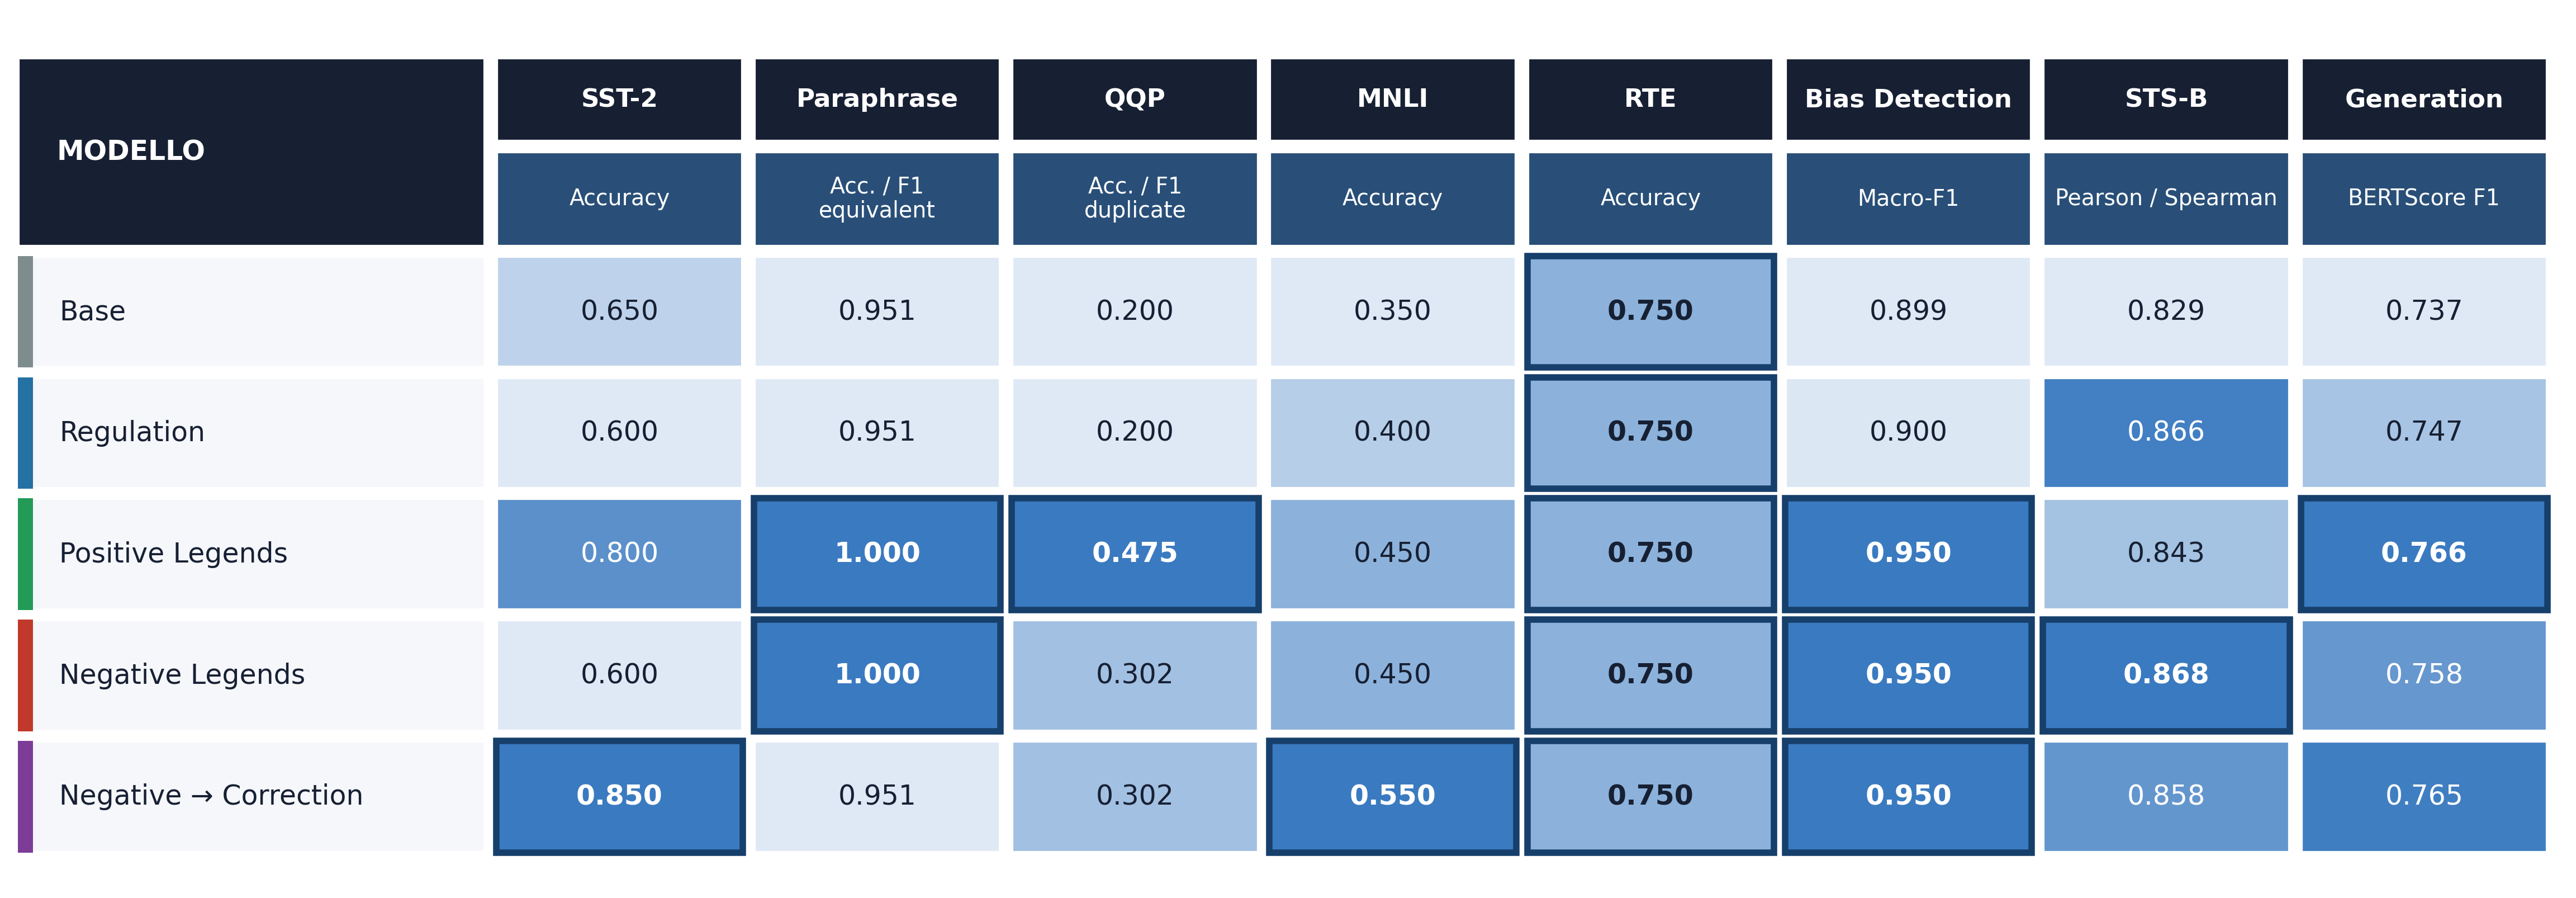

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\overview\slide_01_overview_primary_scores.png

In [535]:
# CELLA 16 — Genera la matrice complessiva con intestazione
# su due livelli e senza titolo interno al PNG.

plot_column_normalized_matrix(
    raw_dataframe=(
        overview_primary_matrix_df
    ),

    display_column_names=(
        overview_column_display_names
    ),

    metric_directions=(
        overview_metric_directions
    ),

    output_path=(
        OVERVIEW_PLOTS_DIR
        / "slide_01_overview_primary_scores.png"
    ),

    title=None,

    column_top_names=(
        overview_column_task_names
    ),

    column_bottom_names=(
        overview_column_metric_names
    ),
)

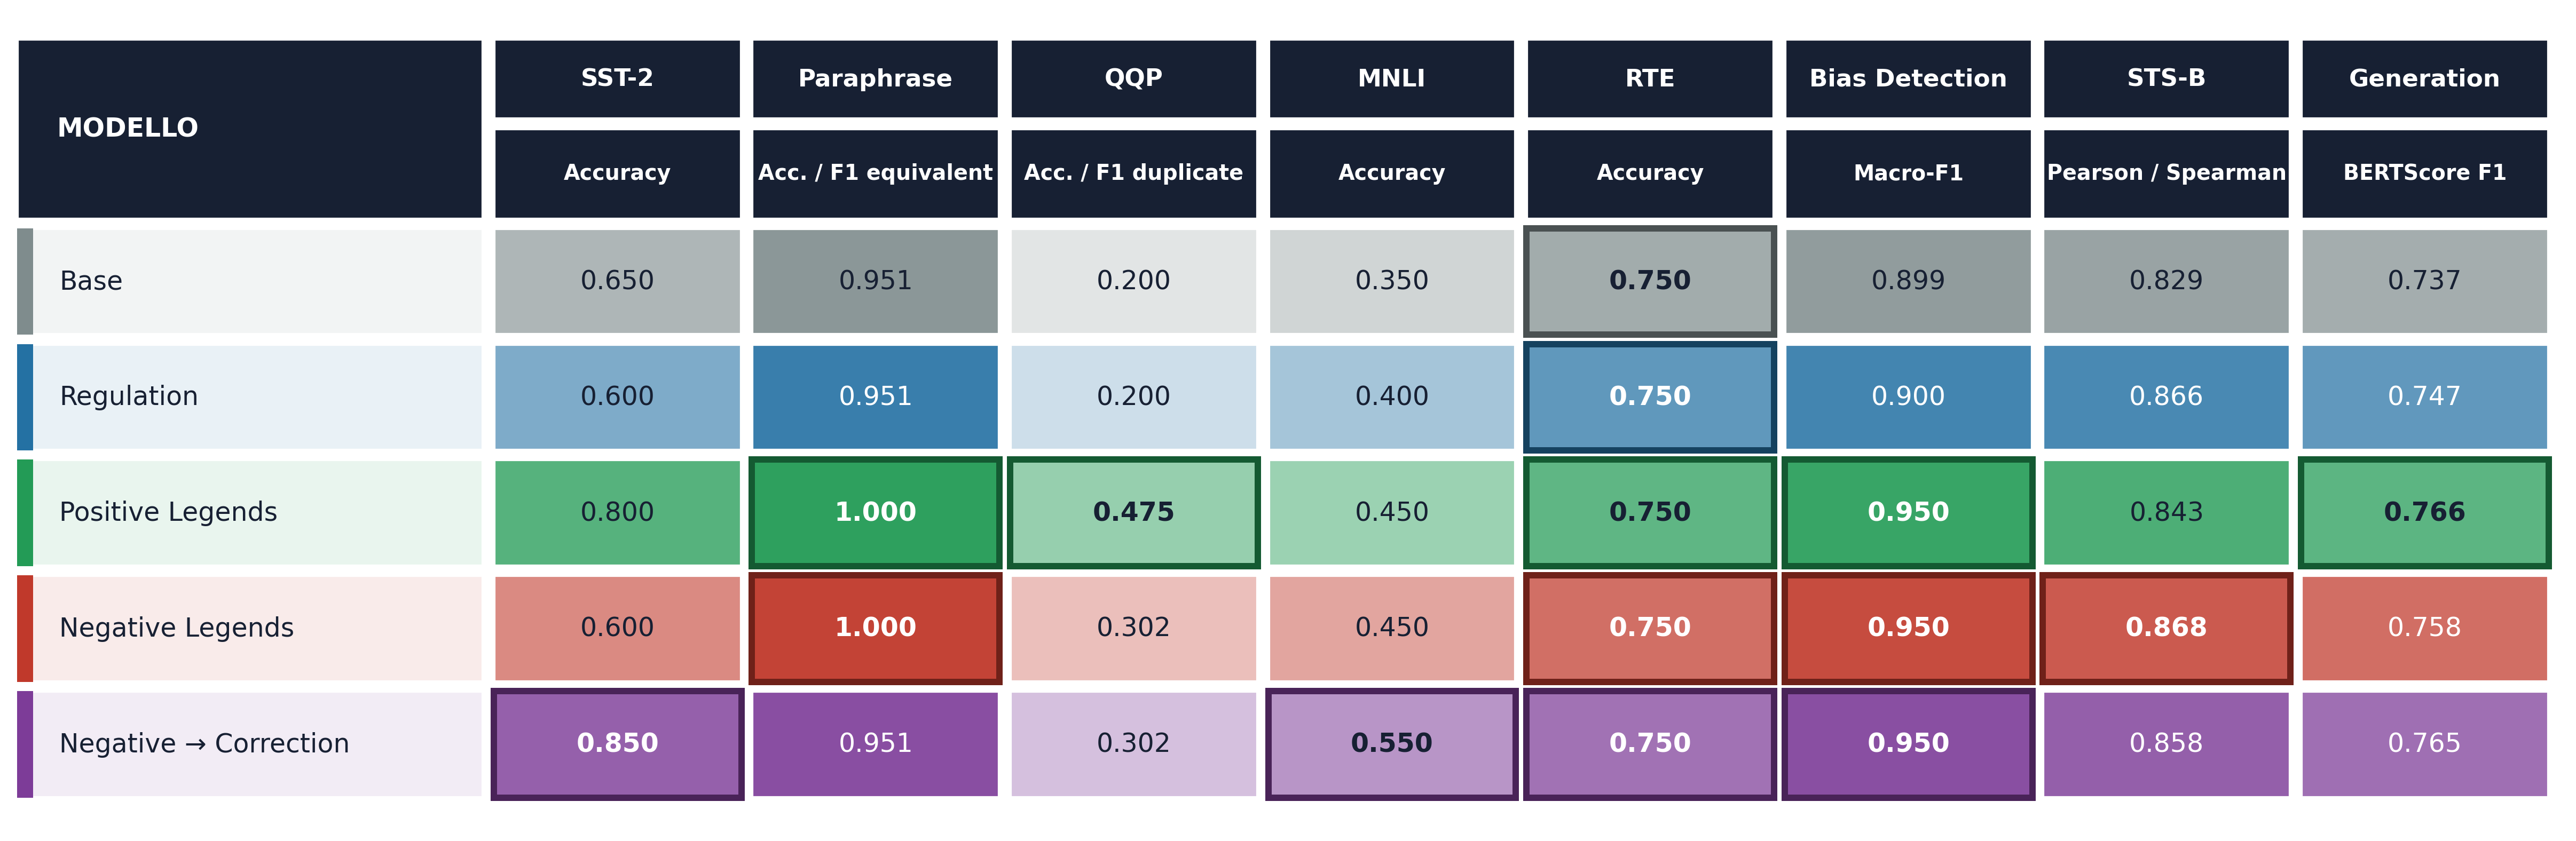

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\overview\slide_01_overview_primary_scores_model_colors.png

In [536]:
# CELLA 16-BIS — Genera la variante della matrice
# con colori per modello e intensità assoluta 0–1.

overview_model_colored_output_path = (
    OVERVIEW_PLOTS_DIR
    / "slide_01_overview_primary_scores_model_colors.png"
)


# Tutte le metriche rappresentative mostrate nella panoramica
# hanno come scala interpretativa utile l'intervallo 0–1.
overview_absolute_color_limits = {
    task_name: (
        0.0,
        1.0,
    )
    for task_name in OVERVIEW_TASKS
}


plot_model_colored_overview_matrix(
    raw_dataframe=(
        overview_primary_matrix_df
    ),

    column_task_names=(
        overview_column_task_names
    ),

    column_metric_names=(
        overview_column_metric_names
    ),

    metric_directions=(
        overview_metric_directions
    ),

    output_path=(
        overview_model_colored_output_path
    ),

    color_limits=(
        overview_absolute_color_limits
    ),
)

In [537]:
# CELLA 17 — Analizza i primi posti nella matrice iniziale
# e genera due frasi sintetiche per l'esposizione.

overview_win_counts = {
    model_name: 0
    for model_name in MODEL_ORDER
}

overview_won_tasks = {
    model_name: []
    for model_name in MODEL_ORDER
}


for task_name in OVERVIEW_TASKS:
    task_series = (
        overview_primary_matrix_df[
            task_name
        ]
    )

    task_winners = get_best_models(
        metric_series=task_series,
        direction="higher",
    )

    for model_name in task_winners:
        overview_win_counts[
            model_name
        ] += 1

        overview_won_tasks[
            model_name
        ].append(
            TASK_DISPLAY_NAMES[
                task_name
            ]
        )


maximum_wins = max(
    overview_win_counts.values()
)

overview_leaders = [
    model_name
    for model_name, number_of_wins
    in overview_win_counts.items()
    if number_of_wins == maximum_wins
]


sorted_win_counts = sorted(
    overview_win_counts.items(),
    key=lambda item: (
        -item[1],
        MODEL_ORDER_MAP[
            item[0]
        ],
    ),
)


leader_names = ", ".join(
    MODEL_DISPLAY_NAMES[
        model_name
    ]
    for model_name in overview_leaders
)


leader_task_names = sorted({
    task_name
    for model_name in overview_leaders
    for task_name in overview_won_tasks[
        model_name
    ]
})


line_1 = (
    f"{leader_names} registra il maggior numero di primary score "
    f"al vertice: {maximum_wins} task su {len(OVERVIEW_TASKS)}, "
    "considerando anche gli eventuali primi posti condivisi."
)


if len(sorted_win_counts) > 1:
    second_model_name, second_model_wins = (
        sorted_win_counts[1]
    )

    line_2 = (
        f"I risultati migliori si concentrano soprattutto su "
        f"{', '.join(leader_task_names)}; "
        f"{MODEL_DISPLAY_NAMES[second_model_name]} segue con "
        f"{second_model_wins} task al vertice."
    )

else:
    line_2 = (
        "La matrice deve essere letta per colonna: "
        "metriche appartenenti a task differenti non vengono "
        "mediate direttamente."
    )


add_presentation_note(
    section_name="Slide 1 — Panoramica complessiva",
    line_1=line_1,
    line_2=line_2,
)

### Interpretazione per l'esposizione

1. Positive Legends registra il maggior numero di primary score al vertice: 5 task su 8, considerando anche gli eventuali primi posti condivisi.

2. I risultati migliori si concentrano soprattutto su Bias Detection, Generation, Paraphrase, QQP, RTE; Negative Legends segue con 4 task al vertice.

# 5. Slide 2 — Ranking complessivo

Il ranking trasforma la posizione ottenuta da ciascun modello nei singoli task
in punti:

- primo posto: 5 punti;
- secondo posto: 4 punti;
- terzo posto: 3 punti;
- quarto posto: 2 punti;
- quinto posto: 1 punto.

In presenza di una parità, ciascun modello riceve la media dei punti delle
posizioni occupate.

La slide combina:

- il totale complessivo dei punti;
- la distribuzione dei punti nei singoli task.

In questo modo è possibile vedere sia il risultato finale, sia il percorso con
cui ciascun modello raggiunge quella posizione.

In [538]:
# CELLA 19 — Definisce il ranking task-level
# con gestione esplicita delle parità.

def rank_models_for_task(
    task_dataframe: pd.DataFrame,
    score_column: str = "primary_score",
    tolerance: float = RANKING_TOLERANCE,
) -> pd.DataFrame:
    """Ordina i modelli e assegna punti preservando le parità."""

    ranked_dataframe = (
        task_dataframe
        .sort_values(
            score_column,
            ascending=False,
        )
        .reset_index(
            drop=True
        )
    )


    result_rows = []

    current_index = 0
    current_position = 1

    number_of_models = len(
        ranked_dataframe
    )


    while current_index < number_of_models:
        reference_score = float(
            ranked_dataframe.loc[
                current_index,
                score_column,
            ]
        )

        tie_indices = [
            current_index
        ]

        next_index = (
            current_index
            + 1
        )


        while next_index < number_of_models:
            next_score = float(
                ranked_dataframe.loc[
                    next_index,
                    score_column,
                ]
            )

            if np.isclose(
                reference_score,
                next_score,
                atol=tolerance,
                rtol=0.0,
            ):
                tie_indices.append(
                    next_index
                )

                next_index += 1

            else:
                break


        tie_size = len(
            tie_indices
        )

        occupied_positions = list(
            range(
                current_position,
                current_position
                + tie_size,
            )
        )

        occupied_points = [
            number_of_models
            + 1
            - position
            for position in occupied_positions
        ]

        average_points = float(
            np.mean(
                occupied_points
            )
        )

        average_rank = float(
            np.mean(
                occupied_positions
            )
        )

        rank_end = int(
            occupied_positions[-1]
        )


        for row_index in tie_indices:
            row_data = (
                ranked_dataframe.loc[
                    row_index
                ]
                .to_dict()
            )

            row_data.update({
                "rank": int(
                    current_position
                ),

                "rank_end": (
                    rank_end
                ),

                "average_rank": (
                    average_rank
                ),

                "points": (
                    average_points
                ),

                "tie_size": (
                    tie_size
                ),

                "ranking_status": (
                    "tie"
                    if tie_size > 1
                    else "unique_position"
                ),
            })

            result_rows.append(
                row_data
            )


        current_index = next_index
        current_position += tie_size


    return pd.DataFrame(
        result_rows
    )

In [539]:
# CELLA 20 — Applica il ranking ai task selezionati
# e verifica che ogni task distribuisca complessivamente 15 punti.

ranking_parts = []


for task_name in RANKING_TASKS:
    task_scores_df = (
        automatic_primary_scores_df[
            automatic_primary_scores_df[
                "task_name"
            ]
            == task_name
        ]
        .copy()
    )

    ranking_parts.append(
        rank_models_for_task(
            task_dataframe=task_scores_df,
        )
    )


task_rankings_df = pd.concat(
    ranking_parts,
    ignore_index=True,
)


task_rankings_df[
    "_task_order"
] = (
    task_rankings_df[
        "task_name"
    ]
    .map(TASK_ORDER_MAP)
)


task_rankings_df = (
    task_rankings_df
    .sort_values(
        [
            "_task_order",
            "rank",
            "model_name",
        ]
    )
    .drop(
        columns="_task_order"
    )
    .reset_index(
        drop=True
    )
)


points_by_task = (
    task_rankings_df
    .groupby(
        "task_name"
    )[
        "points"
    ]
    .sum()
)


invalid_point_totals = (
    points_by_task[
        ~np.isclose(
            points_by_task.to_numpy(
                dtype=float
            ),
            15.0,
            atol=RANKING_TOLERANCE,
            rtol=0.0,
        )
    ]
)


if not invalid_point_totals.empty:
    raise RuntimeError(
        "La gestione delle parità non conserva "
        "15 punti complessivi per task:\n"
        + invalid_point_totals.to_string()
    )


display(
    task_rankings_df[
        [
            "task_name",
            "model_name",
            "primary_score",
            "rank",
            "average_rank",
            "points",
            "ranking_status",
        ]
    ]
    .round(4)
)

,task_name,model_name,primary_score,rank,average_rank,points,ranking_status
0,sst2_style,negative_to_correction,0.8500,1,1.0,5.0,unique_position
1,sst2_style,positive_legends,0.8000,2,2.0,4.0,unique_position
2,sst2_style,base,0.6500,3,3.0,3.0,unique_position
3,sst2_style,negative_legends,0.6000,4,4.5,1.5,tie
4,sst2_style,regulation,0.6000,4,4.5,1.5,tie
5,paraphrase_style,negative_legends,1.0000,1,1.5,4.5,tie
6,paraphrase_style,positive_legends,1.0000,1,1.5,4.5,tie
7,paraphrase_style,base,0.9512,3,4.0,2.0,tie
8,paraphrase_style,negative_to_correction,0.9512,3,4.0,2.0,tie
9,paraphrase_style,regulation,0.9512,3,4.0,2.0,tie


In [540]:
# CELLA 21 — Aggrega i punti, costruisce il ranking complessivo
# e calcola le principali statistiche di piazzamento.

overall_ranking_df = (
    task_rankings_df
    .groupby(
        "model_name",
        as_index=False,
    )
    .agg(
        total_points=(
            "points",
            "sum",
        ),

        average_points=(
            "points",
            "mean",
        ),

        average_rank=(
            "average_rank",
            "mean",
        ),

        first_places=(
            "rank",
            lambda values: int(
                (
                    values == 1
                )
                .sum()
            ),
        ),

        top_2_finishes=(
            "rank",
            lambda values: int(
                (
                    values <= 2
                )
                .sum()
            ),
        ),

        last_places=(
            "rank_end",
            lambda values: int(
                (
                    values
                    == len(MODEL_ORDER)
                )
                .sum()
            ),
        ),

        n_tasks=(
            "task_name",
            "nunique",
        ),
    )
)


# A parità di punti, il rank medio viene utilizzato
# come criterio secondario di ordinamento.
overall_ranking_df = (
    overall_ranking_df
    .sort_values(
        [
            "total_points",
            "average_rank",
            "model_name",
        ],
        ascending=[
            False,
            True,
            True,
        ],
    )
    .reset_index(
        drop=True
    )
)


overall_ranking_df[
    "overall_position"
] = np.arange(
    1,
    len(
        overall_ranking_df
    )
    + 1,
)


task_points_matrix_df = (
    task_rankings_df
    .pivot(
        index="model_name",
        columns="task_name",
        values="points",
    )
    .reindex(
        index=MODEL_ORDER,
        columns=RANKING_TASKS,
    )
)


task_points_matrix_with_total_df = (
    task_points_matrix_df
    .copy()
)


task_points_matrix_with_total_df[
    "total_points"
] = (
    task_points_matrix_with_total_df
    .sum(
        axis=1
    )
)


display(
    overall_ranking_df
    .round(4)
)


display(
    task_points_matrix_with_total_df
    .round(2)
)

,model_name,total_points,average_points,average_rank,first_places,top_2_finishes,last_places,n_tasks,overall_position
0,positive_legends,31.0,3.8750,2.1250,5,7,1,8,1
1,negative_to_correction,29.5,3.6875,2.3125,4,6,2,8,2
2,negative_legends,28.0,3.5000,2.5000,4,6,2,8,3
3,regulation,18.0,2.2500,3.7500,1,2,4,8,4
4,base,13.5,1.6875,4.3125,1,1,7,8,5


task_name,sst2_style,paraphrase_style,qqp_style,mnli_style,rte_style,bias_detection,stsb_style,grounded_answer_generation,total_points
model_name,,,,,,,,,
base,3.0,2.0,1.5,1.0,3.0,1.0,1.0,1.0,13.5
regulation,1.5,2.0,1.5,2.0,3.0,2.0,4.0,2.0,18.0
positive_legends,4.0,4.5,5.0,3.5,3.0,4.0,2.0,5.0,31.0
negative_legends,1.5,4.5,3.5,3.5,3.0,4.0,5.0,3.0,28.0
negative_to_correction,5.0,2.0,3.5,5.0,3.0,4.0,3.0,4.0,29.5


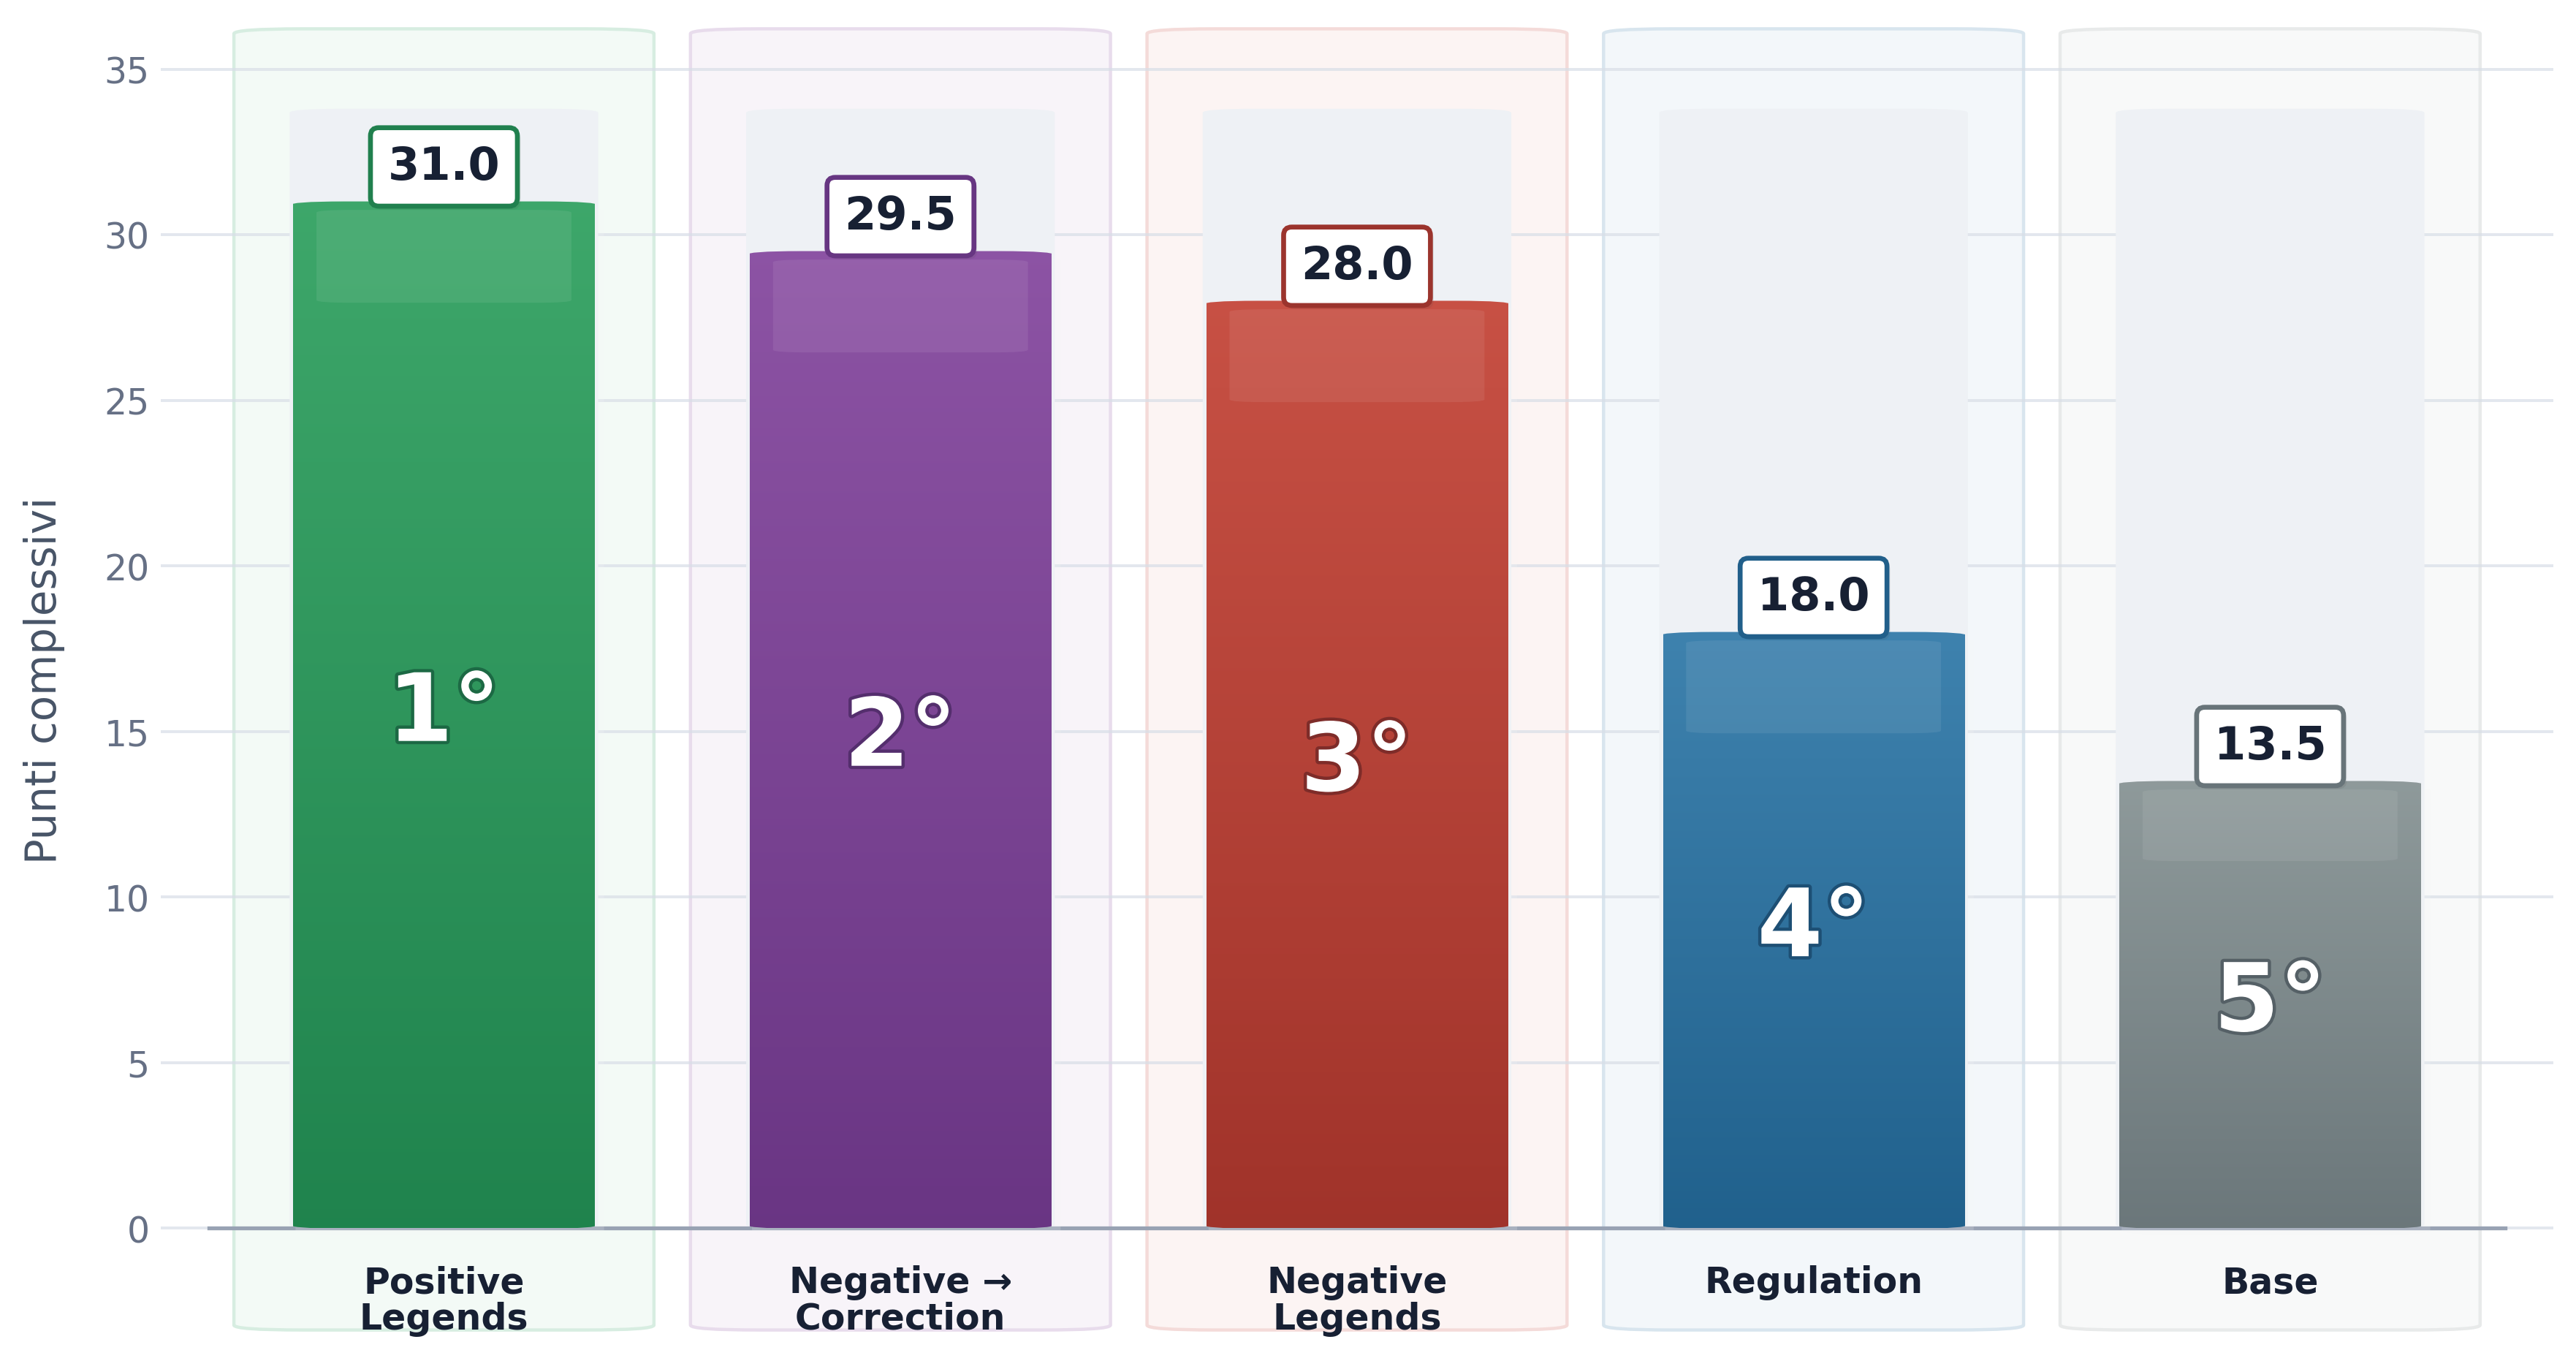

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\ranking\slide_02_overall_ranking_vertical_elaborate.png

In [541]:
# CELLA 22A — Ranking complessivo in stile presentation-grade.
#
# Aggiornamento:
# - allunga i riquadri leggeri di sfondo fino a contenere bene
#   anche i nomi dei modelli su due righe;
# - mantiene barre arrotondate, punteggio sopra e posizione dentro la barra.

from matplotlib import colors as mcolors
from matplotlib.patches import FancyBboxPatch
import matplotlib.patheffects as pe


# ---------------------------------------------------------------------
# PREPARAZIONE DEI DATI
# ---------------------------------------------------------------------

ranking_plot_df = (
    overall_ranking_df
    .sort_values(
        "total_points",
        ascending=False,
    )
    .reset_index(
        drop=True
    )
)


model_names = (
    ranking_plot_df[
        "model_name"
    ]
    .tolist()
)


total_points = (
    ranking_plot_df[
        "total_points"
    ]
    .to_numpy(
        dtype=float
    )
)


bar_colors = [
    MODEL_COLORS[
        model_name
    ]
    for model_name in model_names
]


MODEL_MULTILINE_LABELS = {
    "base": "Base",
    "regulation": "Regulation",
    "positive_legends": "Positive\nLegends",
    "negative_legends": "Negative\nLegends",
    "negative_to_correction": "Negative →\nCorrection",
}


display_labels = [
    MODEL_MULTILINE_LABELS[
        model_name
    ]
    for model_name in model_names
]


# ---------------------------------------------------------------------
# FUNZIONI CROMATICHE
# ---------------------------------------------------------------------

def mix_chart_color(
    first_color: str,
    second_color: str,
    amount: float,
) -> tuple[float, float, float]:
    """
    Miscela due colori.

    amount=0 restituisce first_color.
    amount=1 restituisce second_color.
    """

    amount = float(
        np.clip(
            amount,
            0.0,
            1.0,
        )
    )

    first_rgb = np.asarray(
        mcolors.to_rgb(
            first_color
        )
    )

    second_rgb = np.asarray(
        mcolors.to_rgb(
            second_color
        )
    )

    mixed_rgb = (
        first_rgb
        * (
            1.0
            - amount
        )
        + second_rgb
        * amount
    )

    return tuple(
        mixed_rgb
    )


def draw_gradient_rounded_bar(
    axis: plt.Axes,
    center_x: float,
    height: float,
    width: float,
    base_color: str,
    zorder: int = 4,
):
    """
    Disegna una barra arrotondata con gradiente verticale,
    ombra leggera e riflesso nella zona superiore.
    """

    left_x = (
        center_x
        - width
        / 2
    )

    rounded_bar = FancyBboxPatch(
        (
            left_x,
            0,
        ),
        width,
        height,
        boxstyle=(
            "round,pad=0.008,"
            "rounding_size=0.12"
        ),
        facecolor="none",
        edgecolor="none",
        zorder=zorder,
    )

    rounded_bar.set_path_effects([
        pe.SimplePatchShadow(
            offset=(
                1.8,
                -1.8,
            ),
            alpha=0.18,
            rho=0.97,
        ),
        pe.Normal(),
    ])

    axis.add_patch(
        rounded_bar
    )

    darker_color = mix_chart_color(
        first_color=base_color,
        second_color="#111827",
        amount=0.18,
    )

    lighter_color = mix_chart_color(
        first_color=base_color,
        second_color="#FFFFFF",
        amount=0.12,
    )

    gradient_resolution = 256

    bottom_rgb = np.asarray(
        mcolors.to_rgb(
            darker_color
        )
    )

    top_rgb = np.asarray(
        mcolors.to_rgb(
            lighter_color
        )
    )

    gradient_values = np.linspace(
        0.0,
        1.0,
        gradient_resolution,
    )[
        :,
        None,
    ]

    gradient_rgb = (
        bottom_rgb[
            None,
            :
        ]
        * (
            1.0
            - gradient_values
        )
        + top_rgb[
            None,
            :
        ]
        * gradient_values
    )

    gradient_image = np.zeros(
        (
            gradient_resolution,
            1,
            4,
        ),
        dtype=float,
    )

    gradient_image[
        :,
        0,
        :3,
    ] = gradient_rgb

    gradient_image[
        :,
        0,
        3,
    ] = 1.0

    image = axis.imshow(
        gradient_image,
        extent=(
            left_x,
            left_x + width,
            0,
            height,
        ),
        origin="lower",
        aspect="auto",
        interpolation="bicubic",
        zorder=zorder,
    )

    image.set_clip_path(
        rounded_bar
    )

    # Riflesso leggero nella parte superiore.
    reflection_height = min(
        height * 0.16,
        2.8,
    )

    reflection = FancyBboxPatch(
        (
            left_x
            + width * 0.08,
            height
            - reflection_height
            - 0.25,
        ),
        width * 0.84,
        reflection_height,
        boxstyle=(
            "round,pad=0.002,"
            "rounding_size=0.08"
        ),
        facecolor="white",
        edgecolor="none",
        alpha=0.08,
        zorder=zorder + 1,
    )

    reflection.set_clip_path(
        rounded_bar
    )

    axis.add_patch(
        reflection
    )


# ---------------------------------------------------------------------
# FIGURA
# ---------------------------------------------------------------------

figure, axis = plt.subplots(
    figsize=(
        13.2,
        7.3,
    )
)

figure.patch.set_facecolor(
    "white"
)

axis.set_facecolor(
    "white"
)

x_positions = np.arange(
    len(
        model_names
    )
)

bar_width = 0.66

maximum_points = float(
    total_points.max()
)

visual_ceiling = max(
    35.0,
    maximum_points
    + 3.0,
)


# ---------------------------------------------------------------------
# PANNELLI VERTICALI LEGGERI
# ---------------------------------------------------------------------
# QUI È LA MODIFICA PRINCIPALE:
# il pannello parte più in basso e ha più altezza,
# così contiene comodamente anche le etichette su due righe.

panel_width = 0.88
panel_bottom = -3.05
panel_height = visual_ceiling + 4.25

for (
    x_position,
    model_color,
) in zip(
    x_positions,
    bar_colors,
):
    panel_background = mix_chart_color(
        first_color="#FFFFFF",
        second_color=model_color,
        amount=0.055,
    )

    panel_border = mix_chart_color(
        first_color="#FFFFFF",
        second_color=model_color,
        amount=0.18,
    )

    model_panel = FancyBboxPatch(
        (
            x_position
            - panel_width / 2,
            panel_bottom,
        ),
        panel_width,
        panel_height,
        boxstyle=(
            "round,pad=0.02,"
            "rounding_size=0.15"
        ),
        facecolor=panel_background,
        edgecolor=panel_border,
        linewidth=1.0,
        zorder=0,
    )

    axis.add_patch(
        model_panel
    )


# ---------------------------------------------------------------------
# SFONDO GUIDA DELLE BARRE
# ---------------------------------------------------------------------

for x_position in x_positions:
    guide_bar = FancyBboxPatch(
        (
            x_position
            - bar_width
            / 2,
            0,
        ),
        bar_width,
        visual_ceiling
        - 1.2,
        boxstyle=(
            "round,pad=0.008,"
            "rounding_size=0.12"
        ),
        facecolor="#EEF1F5",
        edgecolor="none",
        zorder=1,
    )

    axis.add_patch(
        guide_bar
    )


# ---------------------------------------------------------------------
# BARRE PRINCIPALI
# ---------------------------------------------------------------------

for (
    x_position,
    point_value,
    model_color,
) in zip(
    x_positions,
    total_points,
    bar_colors,
):
    draw_gradient_rounded_bar(
        axis=axis,
        center_x=x_position,
        height=point_value,
        width=bar_width,
        base_color=model_color,
        zorder=4,
    )


# ---------------------------------------------------------------------
# POSIZIONE DENTRO LA BARRA
# ---------------------------------------------------------------------

for ranking_position, (
    x_position,
    point_value,
    model_color,
) in enumerate(
    zip(
        x_positions,
        total_points,
        bar_colors,
    ),
    start=1,
):
    rank_outline_color = mix_chart_color(
        first_color=model_color,
        second_color="#111827",
        amount=0.38,
    )

    rank_text = axis.text(
        x_position,
        max(
            point_value * 0.50,
            4.5,
        ),
        f"{ranking_position}°",
        ha="center",
        va="center",
        fontsize=29,
        fontweight="bold",
        color="white",
        zorder=8,
    )

    rank_text.set_path_effects([
        pe.withStroke(
            linewidth=2.0,
            foreground=rank_outline_color,
        )
    ])


# ---------------------------------------------------------------------
# CARTELLINO DEL PUNTEGGIO SOPRA LA BARRA
# ---------------------------------------------------------------------

for (
    x_position,
    point_value,
    model_color,
) in zip(
    x_positions,
    total_points,
    bar_colors,
):
    score_border_color = mix_chart_color(
        first_color=model_color,
        second_color="#172033",
        amount=0.22,
    )

    score_text = axis.text(
        x_position,
        point_value
        + 1.05,
        f"{point_value:.1f}",
        ha="center",
        va="center",
        fontsize=14,
        fontweight="bold",
        color="#172033",
        zorder=9,
        bbox={
            "boxstyle": (
                "round,pad=0.38,"
                "rounding_size=0.18"
            ),
            "facecolor": "white",
            "edgecolor": score_border_color,
            "linewidth": 1.5,
        },
    )

    score_text.get_bbox_patch().set_path_effects([
        pe.SimplePatchShadow(
            offset=(
                1.0,
                -1.0,
            ),
            alpha=0.12,
        ),
        pe.Normal(),
    ])


# ---------------------------------------------------------------------
# NOMI DEI MODELLI
# ---------------------------------------------------------------------

for (
    x_position,
    display_label,
) in zip(
    x_positions,
    display_labels,
):
    axis.text(
        x_position,
        -1.10,
        display_label,
        ha="center",
        va="top",
        fontsize=11,
        fontweight="bold",
        color="#172033",
        linespacing=1.04,
        zorder=6,
    )


# ---------------------------------------------------------------------
# LINEA DI BASE
# ---------------------------------------------------------------------

axis.axhline(
    y=0,
    xmin=0.02,
    xmax=0.98,
    color="#98A2B3",
    linewidth=1.2,
    zorder=2,
)


# ---------------------------------------------------------------------
# ASSI E GRIGLIA
# ---------------------------------------------------------------------

axis.set_xlim(
    -0.62,
    len(
        x_positions
    )
    - 0.38,
)

# Anche il limite inferiore è stato abbassato
# per mostrare interamente i pannelli più lunghi.
axis.set_ylim(
    -3.30,
    visual_ceiling
    + 1.40,
)

axis.set_xticks([])

axis.set_ylabel(
    "Punti complessivi",
    fontsize=13,
    color="#475467",
    labelpad=12,
)

axis.set_yticks(
    np.arange(
        0,
        visual_ceiling
        + 1,
        5,
    )
)

axis.tick_params(
    axis="y",
    labelsize=11,
    colors="#667085",
    length=0,
)

axis.grid(
    axis="y",
    color="#D8DEE7",
    linewidth=0.9,
    alpha=0.70,
)

axis.set_axisbelow(
    True
)

for spine_name in [
    "top",
    "right",
    "left",
    "bottom",
]:
    axis.spines[
        spine_name
    ].set_visible(
        False
    )


# ---------------------------------------------------------------------
# ESPORTAZIONE
# ---------------------------------------------------------------------

ranking_bar_output_path = (
    RANKING_PLOTS_DIR
    / "slide_02_overall_ranking_vertical_elaborate.png"
)

save_figure(
    figure=figure,
    output_path=ranking_bar_output_path,
)

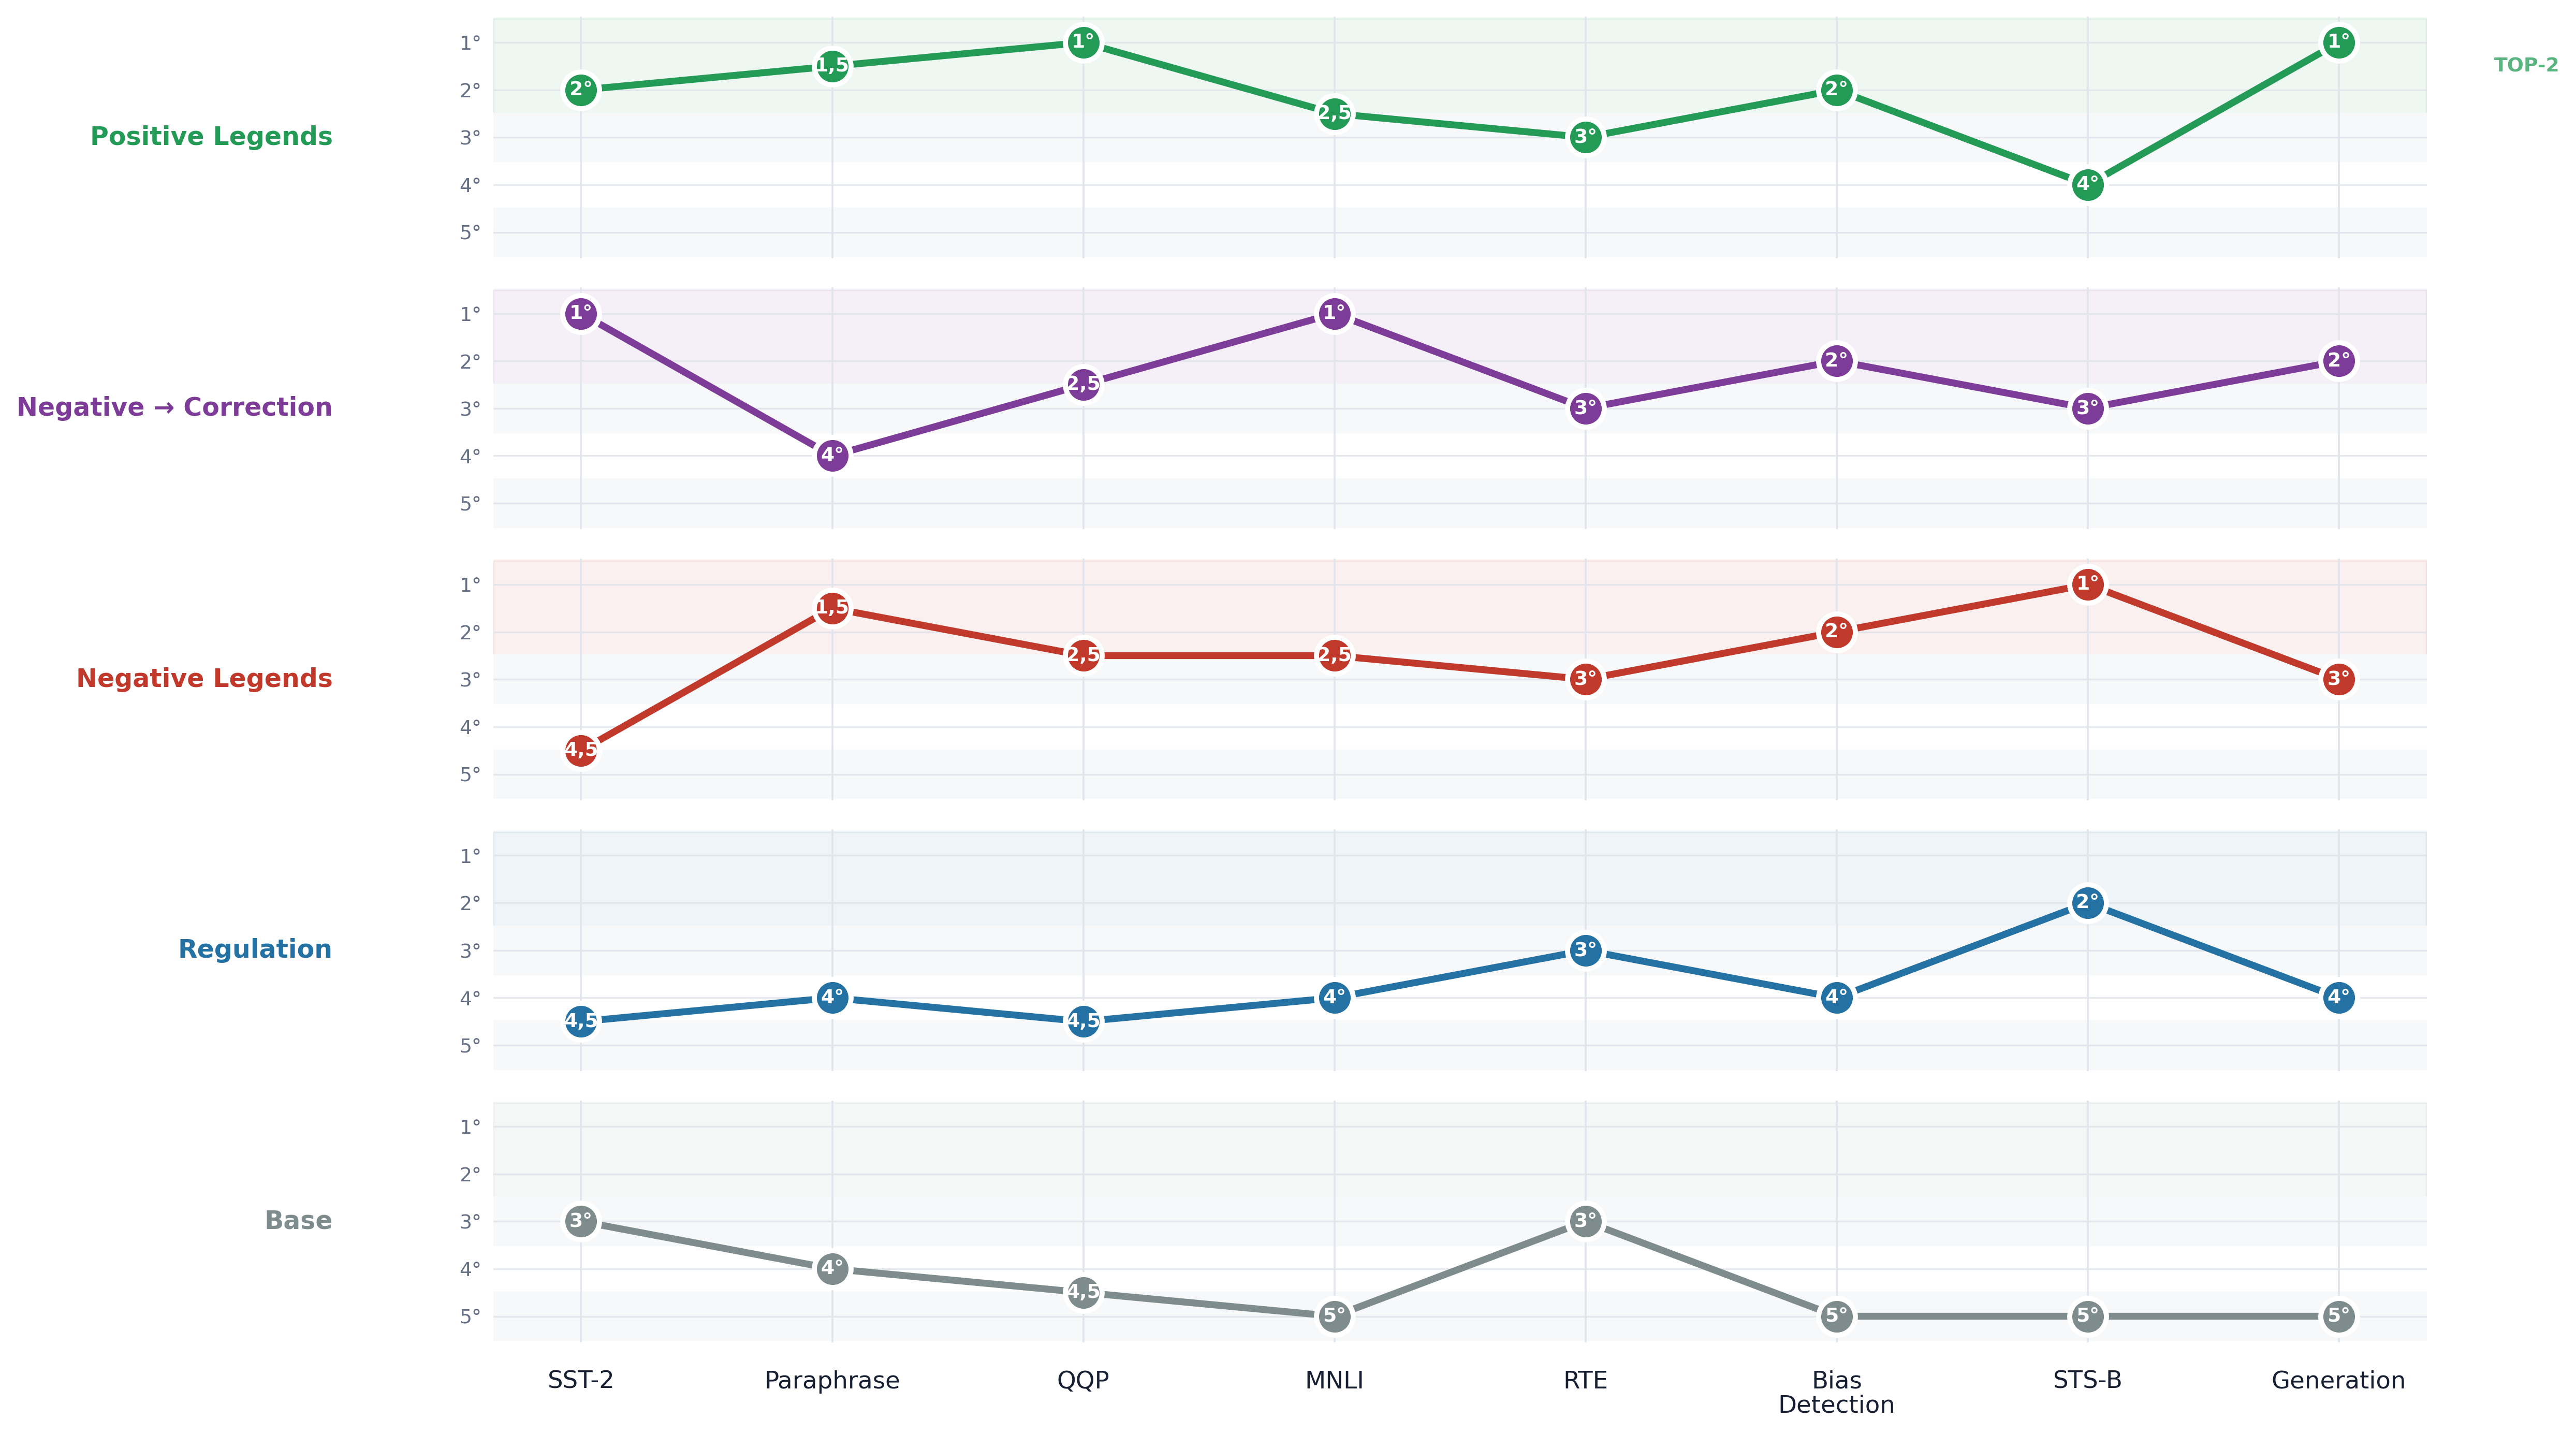

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\ranking\slide_02_rank_profile_small_multiples.png

In [542]:
# CELLA 22B — Profilo delle posizioni per task in small multiples.
#
# Ogni modello dispone di una striscia separata:
# - nessuna sovrapposizione o incrocio tra modelli;
# - posizione mostrata direttamente dentro ogni punto;
# - task allineati verticalmente;
# - fascia superiore dedicata ai piazzamenti top-2;
# - nomi dei modelli e dei task sempre dritti;
# - nessun titolo interno al PNG.

from matplotlib import colors as mcolors


# ---------------------------------------------------------------------
# PREPARAZIONE DEI DATI
# ---------------------------------------------------------------------

rank_profile_df = (
    task_rankings_df[
        task_rankings_df[
            "task_name"
        ]
        .isin(
            RANKING_TASKS
        )
    ]
    .pivot(
        index="model_name",
        columns="task_name",
        values="average_rank",
    )
    .reindex(
        columns=RANKING_TASKS
    )
)


# I modelli vengono mostrati secondo il ranking complessivo,
# dal migliore al peggiore.
profile_model_order = (
    overall_ranking_df
    .sort_values(
        [
            "total_points",
            "average_rank",
        ],
        ascending=[
            False,
            True,
        ],
    )[
        "model_name"
    ]
    .tolist()
)


rank_profile_df = (
    rank_profile_df
    .reindex(
        profile_model_order
    )
)


TASK_MULTILINE_LABELS = {
    "sst2_style": "SST-2",
    "paraphrase_style": "Paraphrase",
    "qqp_style": "QQP",
    "mnli_style": "MNLI",
    "rte_style": "RTE",
    "bias_detection": "Bias\nDetection",
    "stsb_style": "STS-B",
    "grounded_answer_generation": "Generation",
}


x_positions = np.arange(
    len(
        RANKING_TASKS
    )
)


number_of_models = len(
    profile_model_order
)


# ---------------------------------------------------------------------
# FIGURA
# ---------------------------------------------------------------------

figure, axes = plt.subplots(
    nrows=number_of_models,
    ncols=1,
    figsize=(
        14.5,
        9.2,
    ),
    sharex=True,
)


figure.patch.set_facecolor(
    "white"
)


if number_of_models == 1:
    axes = [
        axes
    ]


# ---------------------------------------------------------------------
# FUNZIONE DI SUPPORTO PER IL TESTO DEL RANK
# ---------------------------------------------------------------------

def format_rank_value(
    rank_value: float,
) -> str:
    """
    Formatta il rank preservando le parità.

    Esempi:
    1.0 -> 1°
    2.5 -> 2,5
    """

    if np.isclose(
        rank_value,
        round(
            rank_value
        ),
        atol=1e-12,
    ):
        return (
            f"{int(round(rank_value))}°"
        )

    return (
        f"{rank_value:.1f}"
        .replace(
            ".",
            ",",
        )
    )


# ---------------------------------------------------------------------
# DISEGNO DEI CINQUE PROFILI
# ---------------------------------------------------------------------

for axis_index, (
    axis,
    model_name,
) in enumerate(
    zip(
        axes,
        profile_model_order,
    )
):
    model_color = MODEL_COLORS[
        model_name
    ]

    model_rank_values = (
        rank_profile_df
        .loc[
            model_name,
            RANKING_TASKS,
        ]
        .to_numpy(
            dtype=float
        )
    )


    axis.set_facecolor(
        "white"
    )


    # -------------------------------------------------------------
    # FASCIA TOP-2
    # -------------------------------------------------------------

    top_2_background = mcolors.to_rgba(
        model_color,
        alpha=0.075,
    )

    axis.axhspan(
        0.50,
        2.50,
        color=top_2_background,
        zorder=0,
    )


    # -------------------------------------------------------------
    # FASCE ALTERNATE PER LE ALTRE POSIZIONI
    # -------------------------------------------------------------

    axis.axhspan(
        2.50,
        3.50,
        color="#F7F8FA",
        zorder=0,
    )

    axis.axhspan(
        4.50,
        5.50,
        color="#F7F8FA",
        zorder=0,
    )


    # -------------------------------------------------------------
    # SEPARATORI VERTICALI DEI TASK
    # -------------------------------------------------------------

    for x_position in x_positions:
        axis.axvline(
            x=x_position,
            color="#E2E6EC",
            linewidth=0.85,
            zorder=1,
        )


    # -------------------------------------------------------------
    # LINEA DEL PROFILO
    # -------------------------------------------------------------

    axis.plot(
        x_positions,
        model_rank_values,
        color=model_color,
        linewidth=3.0,
        solid_capstyle="round",
        solid_joinstyle="round",
        zorder=3,
    )


    # -------------------------------------------------------------
    # PUNTI DEL PROFILO
    # -------------------------------------------------------------

    axis.scatter(
        x_positions,
        model_rank_values,
        s=255,
        color=model_color,
        edgecolor="white",
        linewidth=2.2,
        zorder=4,
    )


    # -------------------------------------------------------------
    # POSIZIONI SCRITTE DENTRO I PUNTI
    # -------------------------------------------------------------

    for (
        x_position,
        rank_value,
    ) in zip(
        x_positions,
        model_rank_values,
    ):
        axis.text(
            x_position,
            rank_value,
            format_rank_value(
                rank_value
            ),
            ha="center",
            va="center",
            fontsize=8.5,
            fontweight="bold",
            color="white",
            zorder=5,
        )


    # -------------------------------------------------------------
    # NOME DEL MODELLO
    # -------------------------------------------------------------

    axis.set_ylabel(
        MODEL_DISPLAY_NAMES[
            model_name
        ],
        rotation=0,
        ha="right",
        va="center",
        fontsize=11,
        fontweight="bold",
        color=model_color,
        labelpad=55,
    )


    # -------------------------------------------------------------
    # ASSE DELLE POSIZIONI
    # -------------------------------------------------------------

    axis.set_ylim(
        5.55,
        0.45,
    )

    axis.set_yticks(
        [
            1,
            2,
            3,
            4,
            5,
        ]
    )

    axis.set_yticklabels(
        [
            "1°",
            "2°",
            "3°",
            "4°",
            "5°",
        ],
        fontsize=8.5,
        color="#667085",
    )

    axis.tick_params(
        axis="y",
        length=0,
        pad=5,
    )


    # -------------------------------------------------------------
    # LINEE ORIZZONTALI
    # -------------------------------------------------------------

    axis.grid(
        axis="y",
        color="#DDE2E9",
        linewidth=0.75,
        alpha=0.75,
    )

    axis.set_axisbelow(
        True
    )


    # -------------------------------------------------------------
    # PULIZIA DEL PANNELLO
    # -------------------------------------------------------------

    for spine_name in [
        "top",
        "right",
        "left",
        "bottom",
    ]:
        axis.spines[
            spine_name
        ].set_visible(
            False
        )


    axis.tick_params(
        axis="x",
        length=0,
    )


# ---------------------------------------------------------------------
# ETICHETTE DEI TASK, SOLO NELL'ULTIMO PANNELLO
# ---------------------------------------------------------------------

axes[-1].set_xticks(
    x_positions
)


axes[-1].set_xticklabels(
    [
        TASK_MULTILINE_LABELS[
            task_name
        ]
        for task_name in RANKING_TASKS
    ],
    fontsize=10.5,
    fontweight="medium",
    color="#172033",
    linespacing=1.05,
)


axes[-1].tick_params(
    axis="x",
    pad=12,
)


# ---------------------------------------------------------------------
# PICCOLA INDICAZIONE DELLA ZONA TOP-2
# ---------------------------------------------------------------------

axes[0].text(
    len(
        RANKING_TASKS
    )
    - 0.12,
    1.50,
    "TOP-2",
    ha="right",
    va="center",
    fontsize=8.5,
    fontweight="bold",
    color=mcolors.to_rgba(
        MODEL_COLORS[
            profile_model_order[0]
        ],
        alpha=0.75,
    ),
    zorder=6,
)


# ---------------------------------------------------------------------
# SPAZIATURA
# ---------------------------------------------------------------------

figure.subplots_adjust(
    left=0.18,
    right=0.985,
    top=0.985,
    bottom=0.115,
    hspace=0.12,
)


# ---------------------------------------------------------------------
# ESPORTAZIONE
# ---------------------------------------------------------------------

rank_profile_output_path = (
    RANKING_PLOTS_DIR
    / "slide_02_rank_profile_small_multiples.png"
)


save_figure(
    figure=figure,
    output_path=rank_profile_output_path,
)

In [543]:
# CELLA 23 — Genera due frasi sintetiche
# per commentare il ranking complessivo.

ranking_winner = (
    overall_ranking_df
    .iloc[0]
)

ranking_runner_up = (
    overall_ranking_df
    .iloc[1]
)


ranking_margin = float(
    ranking_winner[
        "total_points"
    ]
    - ranking_runner_up[
        "total_points"
    ]
)


line_1 = (
    f"{MODEL_DISPLAY_NAMES[ranking_winner['model_name']]} "
    f"occupa il primo posto con "
    f"{ranking_winner['total_points']:.1f} punti, "
    f"con un vantaggio di {ranking_margin:.1f} punti su "
    f"{MODEL_DISPLAY_NAMES[ranking_runner_up['model_name']]}."
)


line_2 = (
    f"Il modello vincitore ottiene "
    f"{int(ranking_winner['first_places'])} primi posti e "
    f"{int(ranking_winner['top_2_finishes'])} piazzamenti nei primi due "
    f"su {len(RANKING_TASKS)} task, mostrando "
    f"{'una prestazione distribuita' if ranking_winner['top_2_finishes'] >= len(RANKING_TASKS) / 2 else 'una prestazione più concentrata su alcuni task'}."
)


add_presentation_note(
    section_name="Slide 2 — Ranking complessivo",
    line_1=line_1,
    line_2=line_2,
)

### Interpretazione per l'esposizione

1. Positive Legends occupa il primo posto con 31.0 punti, con un vantaggio di 1.5 punti su Negative → Correction.

2. Il modello vincitore ottiene 5 primi posti e 7 piazzamenti nei primi due su 8 task, mostrando una prestazione distribuita.

# 6. Zoom sui singoli task

Per ciascun task vengono prodotti:

1. una tabella numerica;
2. una matrice grafica con tutte le metriche disponibili;
3. un grafico comparativo;
4. due frasi sintetiche per l'esposizione.

La metrica rappresentativa viene mostrata per prima e indicata con una stella.

Le metriche con freccia verso l'alto sono migliori quando aumentano.

Le metriche con freccia verso il basso sono migliori quando diminuiscono.

Le metriche indicate con `↔ 0` sono migliori quando si avvicinano allo zero.

In [544]:
# CELLA 25 — Configura in modo esplicito le metriche da mostrare
# nelle matrici di zoom dei singoli task.
#
# La configurazione è una allowlist rigida:
# vengono mostrate soltanto metriche metodologicamente utili.
# Non vengono aggiunte automaticamente tutte le colonne numeriche residue.

TASK_MATRIX_CONFIG = {
    # -----------------------------------------------------------------
    # SST-2 STYLE
    # -----------------------------------------------------------------

    "sst2_style": {
        "task_label": "SST-2",

        "metrics": [
            {
                "key": "primary_score",
                "label": "Accuracy ★",
                "source": "__primary_score__",
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "macro_f1",
                "label": "Macro-F1",
                "candidates": [
                    "macro_f1",
                    "f1_macro",
                    "macro_f1_score",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "precision_compliant",
                "label": "Precision\ncompliant",
                "candidates": [
                    "precision_compliant",
                    "compliant_precision",
                    "precision_class_compliant",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "recall_compliant",
                "label": "Recall\ncompliant",
                "candidates": [
                    "recall_compliant",
                    "compliant_recall",
                    "recall_class_compliant",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "f1_compliant",
                "label": "F1\ncompliant",
                "candidates": [
                    "f1_compliant",
                    "compliant_f1",
                    "f1_class_compliant",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "precision_non_compliant",
                "label": "Precision\nnon-compliant",
                "candidates": [
                    "precision_non_compliant",
                    "non_compliant_precision",
                    "precision_class_non_compliant",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "recall_non_compliant",
                "label": "Recall\nnon-compliant",
                "candidates": [
                    "recall_non_compliant",
                    "non_compliant_recall",
                    "recall_class_non_compliant",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "f1_non_compliant",
                "label": "F1\nnon-compliant",
                "candidates": [
                    "f1_non_compliant",
                    "non_compliant_f1",
                    "f1_class_non_compliant",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
        ],
    },

    # -----------------------------------------------------------------
    # PARAPHRASE STYLE
    # -----------------------------------------------------------------

    "paraphrase_style": {
        "task_label": "Paraphrase",

        "metrics": [
            {
                "key": "primary_score",
                "label": "Acc. / F1\nequivalent ★",
                "source": "__primary_score__",
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "accuracy",
                "label": "Accuracy",
                "candidates": [
                    "accuracy",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "precision_equivalent",
                "label": "Precision\nequivalent",
                "candidates": [
                    "precision_equivalent",
                    "equivalent_precision",
                    "precision_class_equivalent",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "recall_equivalent",
                "label": "Recall\nequivalent",
                "candidates": [
                    "recall_equivalent",
                    "equivalent_recall",
                    "recall_class_equivalent",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "f1_equivalent",
                "label": "F1\nequivalent",
                "candidates": [
                    "f1_equivalent",
                    "equivalent_f1",
                    "f1_class_equivalent",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "precision_not_equivalent",
                "label": "Precision\nnot-equivalent",
                "candidates": [
                    "precision_not_equivalent",
                    "not_equivalent_precision",
                    "precision_class_not_equivalent",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "recall_not_equivalent",
                "label": "Recall\nnot-equivalent",
                "candidates": [
                    "recall_not_equivalent",
                    "not_equivalent_recall",
                    "recall_class_not_equivalent",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "f1_not_equivalent",
                "label": "F1\nnot-equivalent",
                "candidates": [
                    "f1_not_equivalent",
                    "not_equivalent_f1",
                    "f1_class_not_equivalent",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
        ],
    },

    # -----------------------------------------------------------------
    # QQP STYLE
    # -----------------------------------------------------------------

    "qqp_style": {
        "task_label": "QQP",

        "metrics": [
            {
                "key": "primary_score",
                "label": "Acc. / F1\nduplicate ★",
                "source": "__primary_score__",
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "accuracy",
                "label": "Accuracy",
                "candidates": [
                    "accuracy",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "precision_duplicate",
                "label": "Precision\nduplicate",
                "candidates": [
                    "precision_duplicate",
                    "duplicate_precision",
                    "precision_class_duplicate",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "recall_duplicate",
                "label": "Recall\nduplicate",
                "candidates": [
                    "recall_duplicate",
                    "duplicate_recall",
                    "recall_class_duplicate",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "f1_duplicate",
                "label": "F1\nduplicate",
                "candidates": [
                    "f1_duplicate",
                    "duplicate_f1",
                    "f1_class_duplicate",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "precision_not_duplicate",
                "label": "Precision\nnot-duplicate",
                "candidates": [
                    "precision_not_duplicate",
                    "not_duplicate_precision",
                    "precision_class_not_duplicate",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "recall_not_duplicate",
                "label": "Recall\nnot-duplicate",
                "candidates": [
                    "recall_not_duplicate",
                    "not_duplicate_recall",
                    "recall_class_not_duplicate",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "f1_not_duplicate",
                "label": "F1\nnot-duplicate",
                "candidates": [
                    "f1_not_duplicate",
                    "not_duplicate_f1",
                    "f1_class_not_duplicate",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
        ],
    },

    # -----------------------------------------------------------------
    # MNLI STYLE
    # -----------------------------------------------------------------

    "mnli_style": {
        "task_label": "MNLI",

        "metrics": [
            {
                "key": "primary_score",
                "label": "Accuracy ★",
                "source": "__primary_score__",
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "macro_f1",
                "label": "Macro-F1",
                "candidates": [
                    "macro_f1",
                    "f1_macro",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "f1_entailment",
                "label": "F1\nentailment",
                "candidates": [
                    "f1_entailment",
                    "entailment_f1",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "f1_neutral",
                "label": "F1\nneutral",
                "candidates": [
                    "f1_neutral",
                    "neutral_f1",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "f1_contradiction",
                "label": "F1\ncontradiction",
                "candidates": [
                    "f1_contradiction",
                    "contradiction_f1",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "recall_entailment",
                "label": "Recall\nentailment",
                "candidates": [
                    "recall_entailment",
                    "entailment_recall",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "recall_neutral",
                "label": "Recall\nneutral",
                "candidates": [
                    "recall_neutral",
                    "neutral_recall",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "recall_contradiction",
                "label": "Recall\ncontradiction",
                "candidates": [
                    "recall_contradiction",
                    "contradiction_recall",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
        ],
    },

    # -----------------------------------------------------------------
    # RTE STYLE
    # -----------------------------------------------------------------

    "rte_style": {
        "task_label": "RTE",

        "metrics": [
            {
                "key": "primary_score",
                "label": "Accuracy ★",
                "source": "__primary_score__",
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "macro_f1",
                "label": "Macro-F1",
                "candidates": [
                    "macro_f1",
                    "f1_macro",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "precision_entailment",
                "label": "Precision\nentailment",
                "candidates": [
                    "precision_entailment",
                    "entailment_precision",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "recall_entailment",
                "label": "Recall\nentailment",
                "candidates": [
                    "recall_entailment",
                    "entailment_recall",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "f1_entailment",
                "label": "F1\nentailment",
                "candidates": [
                    "f1_entailment",
                    "entailment_f1",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "precision_not_entailment",
                "label": "Precision\nnot-entailment",
                "candidates": [
                    "precision_not_entailment",
                    "not_entailment_precision",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "recall_not_entailment",
                "label": "Recall\nnot-entailment",
                "candidates": [
                    "recall_not_entailment",
                    "not_entailment_recall",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "f1_not_entailment",
                "label": "F1\nnot-entailment",
                "candidates": [
                    "f1_not_entailment",
                    "not_entailment_f1",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
        ],
    },

    # -----------------------------------------------------------------
    # BIAS DETECTION
    # -----------------------------------------------------------------

    "bias_detection": {
        "task_label": "Bias Detection",

        "metrics": [
            {
                "key": "primary_score",
                "label": "Macro-F1 ★",
                "source": "__primary_score__",
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "accuracy",
                "label": "Accuracy",
                "candidates": [
                    "accuracy",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "precision_biased",
                "label": "Precision\nbiased",
                "candidates": [
                    "precision_biased",
                    "biased_precision",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "recall_biased",
                "label": "Recall\nbiased",
                "candidates": [
                    "recall_biased",
                    "biased_recall",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "f1_biased",
                "label": "F1\nbiased",
                "candidates": [
                    "f1_biased",
                    "biased_f1",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "precision_unbiased",
                "label": "Precision\nunbiased",
                "candidates": [
                    "precision_unbiased",
                    "unbiased_precision",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "recall_unbiased",
                "label": "Recall\nunbiased",
                "candidates": [
                    "recall_unbiased",
                    "unbiased_recall",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "f1_unbiased",
                "label": "F1\nunbiased",
                "candidates": [
                    "f1_unbiased",
                    "unbiased_f1",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
        ],
    },

    # -----------------------------------------------------------------
    # STS-B STYLE
    # -----------------------------------------------------------------

    "stsb_style": {
        "task_label": "STS-B",

        "metrics": [
            {
                "key": "primary_score",
                "label": "Pearson /\nSpearman ★",
                "source": "__primary_score__",
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "pearson",
                "label": "Pearson",
                "candidates": [
                    "pearson",
                    "pearson_correlation",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "spearman",
                "label": "Spearman",
                "candidates": [
                    "spearman",
                    "spearman_correlation",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "mae",
                "label": "MAE ↓",
                "candidates": [
                    "mae",
                    "mean_absolute_error",
                ],
                "direction": "lower",
                "color_limits": (0.0, 5.0),
            },
            {
                "key": "rmse",
                "label": "RMSE ↓",
                "candidates": [
                    "rmse",
                    "root_mean_squared_error",
                ],
                "direction": "lower",
                "color_limits": (0.0, 5.0),
            },
            {
                "key": "within_1",
                "label": "Entro ±1",
                "candidates": [
                    "accuracy_within_1",
                    "within_1",
                    "within_1_rate",
                    "pct_within_1",
                ],
                "direction": "higher",
                "color_limits": (0.0, 1.0),
            },
            {
                "key": "mean_signed_error",
                "label": "Errore medio\nfirmato ↔ 0",
                "candidates": [
                    "mean_signed_error",
                    "signed_error_mean",
                    "average_signed_error",
                ],
                "direction": "zero",
                "color_limits": (-5.0, 5.0),
            },
        ],
    },
}


print(
    "Configurazione matrici task caricata:",
    len(TASK_MATRIX_CONFIG),
    "task."
)

Configurazione matrici task caricata: 7 task.


In [545]:
# CELLA 26 — Individua le colonne reali del CSV e costruisce
# la matrice selezionata per ciascun task.
#
# Non aggiunge metriche non presenti nella configurazione.
# Se una metrica attesa non viene trovata, mostra le colonne disponibili.

def normalize_metric_token(
    value: str,
) -> str:
    """Normalizza un nome di colonna per confronti robusti."""

    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(value).lower(),
    )


def resolve_configured_metric_column(
    available_columns: list[str],
    candidates: list[str],
) -> str | None:
    """
    Cerca la colonna reale corrispondente a una lista di alias.

    Ordine:
    1. corrispondenza normalizzata esatta;
    2. corrispondenza parziale univoca;
    3. colonna più corta tra le corrispondenze compatibili.
    """

    normalized_columns = {
        column_name: normalize_metric_token(
            column_name
        )
        for column_name in available_columns
    }


    # Match esatto.
    for candidate in candidates:
        normalized_candidate = normalize_metric_token(
            candidate
        )

        exact_matches = [
            column_name
            for column_name, normalized_column
            in normalized_columns.items()
            if normalized_column
            == normalized_candidate
        ]

        if exact_matches:
            return exact_matches[0]


    # Match parziale.
    partial_matches = []

    for candidate in candidates:
        normalized_candidate = normalize_metric_token(
            candidate
        )

        for column_name, normalized_column in normalized_columns.items():
            if (
                normalized_candidate
                in normalized_column
                or normalized_column
                in normalized_candidate
            ):
                partial_matches.append(
                    column_name
                )


    partial_matches = list(
        dict.fromkeys(
            partial_matches
        )
    )


    if not partial_matches:
        return None


    return min(
        partial_matches,
        key=lambda column_name: len(
            normalize_metric_token(
                column_name
            )
        ),
    )


def build_task_matrix_bundle(
    task_name: str,
) -> dict:
    """
    Costruisce dataframe e metadati della matrice di un task.
    """

    if task_name not in TASK_MATRIX_CONFIG:
        raise KeyError(
            f"Configurazione assente per il task: {task_name}"
        )


    task_config = TASK_MATRIX_CONFIG[
        task_name
    ]


    task_detail_df = (
        fine_grained_metrics_df[
            fine_grained_metrics_df[
                "task_name"
            ]
            == task_name
        ]
        .copy()
    )


    if task_detail_df.empty:
        raise RuntimeError(
            f"Nessuna riga trovata per il task {task_name}."
        )


    duplicated_models = (
        task_detail_df[
            "model_name"
        ]
        .duplicated(
            keep=False
        )
    )


    if duplicated_models.any():
        duplicate_names = sorted(
            task_detail_df.loc[
                duplicated_models,
                "model_name",
            ]
            .unique()
        )

        raise RuntimeError(
            f"{task_name}: trovate più righe per i modelli "
            f"{duplicate_names}."
        )


    task_detail_df = (
        task_detail_df
        .set_index(
            "model_name"
        )
        .reindex(
            MODEL_ORDER
        )
    )


    task_primary_df = (
        automatic_primary_scores_df[
            automatic_primary_scores_df[
                "task_name"
            ]
            == task_name
        ]
        [
            [
                "model_name",
                "primary_metric_name",
                "primary_score",
            ]
        ]
        .copy()
        .set_index(
            "model_name"
        )
        .reindex(
            MODEL_ORDER
        )
    )


    if task_primary_df[
        "primary_score"
    ].isna().any():
        raise RuntimeError(
            f"{task_name}: primary score mancanti."
        )


    available_numeric_columns = [
        column_name
        for column_name in task_detail_df.columns
        if pd.api.types.is_numeric_dtype(
            task_detail_df[
                column_name
            ]
        )
    ]


    matrix_columns = {}
    metric_metadata = {}


    for metric_spec in task_config[
        "metrics"
    ]:
        metric_key = metric_spec[
            "key"
        ]


        if (
            metric_spec.get(
                "source"
            )
            == "__primary_score__"
        ):
            metric_values = (
                task_primary_df[
                    "primary_score"
                ]
                .astype(float)
            )

            source_column = (
                "__primary_score__"
            )

        else:
            source_column = (
                resolve_configured_metric_column(
                    available_columns=(
                        available_numeric_columns
                    ),

                    candidates=metric_spec[
                        "candidates"
                    ],
                )
            )


            if source_column is None:
                raise RuntimeError(
                    f"\n{task_name}: impossibile trovare la metrica "
                    f"'{metric_spec['label']}'.\n\n"
                    f"Alias cercati:\n"
                    f"{metric_spec['candidates']}\n\n"
                    "Colonne numeriche disponibili:\n- "
                    + "\n- ".join(
                        available_numeric_columns
                    )
                )


            metric_values = pd.to_numeric(
                task_detail_df[
                    source_column
                ],
                errors="coerce",
            )


        if metric_values.isna().any():
            missing_models = list(
                metric_values.index[
                    metric_values.isna()
                ]
            )

            raise RuntimeError(
                f"{task_name} / {metric_spec['label']}: "
                f"valori mancanti per {missing_models}."
            )


        matrix_columns[
            metric_key
        ] = metric_values


        metric_metadata[
            metric_key
        ] = {
            **metric_spec,
            "source_column": source_column,
        }


    matrix_df = pd.DataFrame(
        matrix_columns,
        index=MODEL_ORDER,
    )


    return {
        "task_name": task_name,

        "task_label": task_config[
            "task_label"
        ],

        "matrix_df": matrix_df,

        "metric_metadata": (
            metric_metadata
        ),

        "primary_metric_name": (
            str(
                task_primary_df[
                    "primary_metric_name"
                ]
                .dropna()
                .iloc[0]
            )
        ),
    }

In [546]:
# CELLA 27 — Definisce la funzione che crea il grafico comparativo
# di un singolo task, separando metriche higher-is-better e metriche di errore.

def annotate_bar_values(
    axis: plt.Axes,
    bars,
):
    """Scrive il valore sopra ciascuna barra."""

    for bar in bars:
        bar_height = (
            bar.get_height()
        )

        if np.isnan(
            bar_height
        ):
            continue

        axis.annotate(
            format_metric_value(
                bar_height
            ),

            xy=(
                bar.get_x()
                + bar.get_width()
                / 2,
                bar_height,
            ),

            xytext=(
                0,
                3,
            ),

            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=7,
            rotation=90,
        )


def plot_grouped_metrics(
    axis: plt.Axes,
    raw_metric_df: pd.DataFrame,
    metric_columns: list[str],
    display_column_names: dict[str, str],
    title: str,
):
    """Crea barre raggruppate per un insieme di metriche."""

    x_positions = np.arange(
        len(
            metric_columns
        )
    )

    number_of_models = len(
        MODEL_ORDER
    )

    total_group_width = 0.82

    bar_width = (
        total_group_width
        / number_of_models
    )


    for model_index, model_name in enumerate(
        MODEL_ORDER
    ):
        horizontal_offset = (
            model_index
            - (
                number_of_models
                - 1
            )
            / 2
        ) * bar_width


        bars = axis.bar(
            x_positions
            + horizontal_offset,

            raw_metric_df.loc[
                model_name,
                metric_columns,
            ]
            .to_numpy(
                dtype=float
            ),

            width=bar_width,

            label=MODEL_DISPLAY_NAMES[
                model_name
            ],

            color=MODEL_COLORS[
                model_name
            ],
        )


        annotate_bar_values(
            axis=axis,
            bars=bars,
        )


    axis.set_title(
        title
    )

    axis.set_xticks(
        x_positions
    )

    axis.set_xticklabels(
        [
            display_column_names[
                column_name
            ]
            .replace(
                "\n",
                " "
            )
            for column_name in metric_columns
        ],
        rotation=25,
        ha="right",
    )

    axis.grid(
        axis="y",
        alpha=0.25,
    )

    axis.set_axisbelow(
        True
    )


def plot_task_comparison(
    task_bundle: dict,
    output_path: Path,
):
    """Genera il grafico comparativo principale del task."""

    task_name = (
        task_bundle[
            "task_name"
        ]
    )

    raw_metric_df = (
        task_bundle[
            "raw_metric_df"
        ]
    )

    primary_column = (
        task_bundle[
            "primary_column"
        ]
    )

    metric_directions = (
        task_bundle[
            "metric_directions"
        ]
    )

    display_column_names = (
        task_bundle[
            "display_column_names"
        ]
    )


    higher_metric_columns = [
        column_name
        for column_name in raw_metric_df.columns
        if (
            column_name != primary_column
            and metric_directions[
                column_name
            ]
            == "higher"
        )
    ][
        :MAX_HIGHER_IS_BETTER_METRICS_IN_PLOT
    ]


    error_metric_columns = [
        column_name
        for column_name in raw_metric_df.columns
        if (
            column_name != primary_column
            and metric_directions[
                column_name
            ]
            in [
                "lower",
                "zero",
            ]
        )
    ][
        :MAX_LOWER_IS_BETTER_METRICS_IN_PLOT
    ]


    number_of_panels = (
        1
        + int(
            bool(
                higher_metric_columns
            )
        )
        + int(
            bool(
                error_metric_columns
            )
        )
    )


    figure, axes = plt.subplots(
        nrows=1,
        ncols=number_of_panels,
        figsize=(
            6.2
            * number_of_panels,
            5.8,
        ),
        squeeze=False,
    )


    axes = axes[0]


    # -----------------------------------------------------------------
    # PRIMARY SCORE
    # -----------------------------------------------------------------

    primary_axis = axes[0]


    primary_values = (
        raw_metric_df[
            primary_column
        ]
    )


    primary_bars = primary_axis.bar(
        [
            MODEL_DISPLAY_NAMES[
                model_name
            ]
            for model_name in MODEL_ORDER
        ],

        primary_values.loc[
            MODEL_ORDER
        ],

        color=[
            MODEL_COLORS[
                model_name
            ]
            for model_name in MODEL_ORDER
        ],
    )


    annotate_bar_values(
        axis=primary_axis,
        bars=primary_bars,
    )


    primary_axis.set_title(
        (
            f"Primary score\n"
            f"{humanize_metric_name(task_bundle['primary_metric_name'])}"
        )
    )

    primary_axis.set_ylabel(
        "Valore"
    )

    primary_axis.tick_params(
        axis="x",
        rotation=28,
    )

    primary_axis.grid(
        axis="y",
        alpha=0.25,
    )

    primary_axis.set_axisbelow(
        True
    )


    minimum_primary_value = float(
        np.nanmin(
            primary_values
        )
    )


    primary_axis.set_ylim(
        bottom=min(
            0.0,
            minimum_primary_value
            * 1.10,
        )
    )


    current_axis_index = 1


    # -----------------------------------------------------------------
    # METRICHE HIGHER-IS-BETTER
    # -----------------------------------------------------------------

    if higher_metric_columns:
        higher_axis = axes[
            current_axis_index
        ]

        plot_grouped_metrics(
            axis=higher_axis,
            raw_metric_df=raw_metric_df,
            metric_columns=higher_metric_columns,
            display_column_names=display_column_names,
            title="Metriche diagnostiche ↑",
        )

        higher_axis.set_ylabel(
            "Valore"
        )

        current_axis_index += 1


    # -----------------------------------------------------------------
    # METRICHE DI ERRORE
    # -----------------------------------------------------------------

    if error_metric_columns:
        error_axis = axes[
            current_axis_index
        ]

        plot_grouped_metrics(
            axis=error_axis,
            raw_metric_df=raw_metric_df,
            metric_columns=error_metric_columns,
            display_column_names=display_column_names,
            title="Metriche di errore ↓ / ↔ 0",
        )

        error_axis.set_ylabel(
            "Errore"
        )


    handles, labels = (
        primary_axis.get_legend_handles_labels()
    )


    if higher_metric_columns:
        handles, labels = (
            axes[1]
            .get_legend_handles_labels()
        )


    if handles:
        figure.legend(
            handles,
            labels,
            loc="lower center",
            ncol=len(MODEL_ORDER),
            bbox_to_anchor=(
                0.5,
                -0.03,
            ),
        )


    figure.suptitle(
        (
            f"{TASK_DISPLAY_NAMES[task_name]} — "
            "confronto tra i cinque modelli"
        ),
        fontsize=15,
        y=1.02,
    )


    save_figure(
        figure=figure,
        output_path=output_path,
    )

In [547]:
# CELLA 27A — Disegna le matrici dei singoli task
# usando lo stesso linguaggio visivo della baseline approvata.
#
# Struttura:
# - nome del task nella fascia superiore;
# - nomi delle metriche nella seconda fascia;
# - righe colorate secondo il modello;
# - intensità assoluta basata sui limiti della metrica;
# - risultato migliore evidenziato con bordo;
# - nessun titolo interno al PNG.

from textwrap import wrap

from matplotlib import colors as mcolors
from matplotlib.patches import Rectangle


def blend_task_matrix_color(
    background_color: str,
    foreground_color: str,
    amount: float,
) -> tuple[float, float, float]:
    """Miscela due colori."""

    amount = float(
        np.clip(
            amount,
            0.0,
            1.0,
        )
    )

    background_rgb = np.asarray(
        mcolors.to_rgb(
            background_color
        )
    )

    foreground_rgb = np.asarray(
        mcolors.to_rgb(
            foreground_color
        )
    )

    return tuple(
        background_rgb
        * (
            1.0
            - amount
        )
        + foreground_rgb
        * amount
    )


def darken_task_matrix_color(
    color: str,
    amount: float = 0.35,
) -> tuple[float, float, float]:
    """Scurisce un colore."""

    rgb_color = np.asarray(
        mcolors.to_rgb(
            color
        )
    )

    return tuple(
        rgb_color
        * (
            1.0
            - amount
        )
    )


def get_task_matrix_text_color(
    background_color,
) -> str:
    """Sceglie automaticamente testo bianco o blu scuro."""

    red, green, blue = mcolors.to_rgb(
        background_color
    )

    luminance = (
        0.2126 * red
        + 0.7152 * green
        + 0.0722 * blue
    )

    return (
        "#172033"
        if luminance >= 0.58
        else "white"
    )


def wrap_task_metric_label(
    metric_label: str,
    width: int = 16,
    max_lines: int = 3,
) -> str:
    """Adatta il nome della metrica alla cella di intestazione."""

    wrapped_lines = []

    for original_line in str(
        metric_label
    ).splitlines():
        current_lines = wrap(
            original_line,
            width=width,
            break_long_words=False,
            break_on_hyphens=False,
        )

        wrapped_lines.extend(
            current_lines
            if current_lines
            else [""]
        )


    if len(wrapped_lines) > max_lines:
        wrapped_lines = wrapped_lines[
            :max_lines
        ]

        wrapped_lines[-1] = (
            wrapped_lines[-1].rstrip(
                "."
            )
            + "…"
        )


    return "\n".join(
        wrapped_lines
    )


def task_metric_color_score(
    value: float,
    direction: str,
    color_limits: tuple[float, float],
) -> float:
    """
    Converte una metrica in un'intensità cromatica tra 0 e 1.
    """

    if pd.isna(
        value
    ):
        return np.nan


    lower_limit, upper_limit = (
        color_limits
    )


    if upper_limit <= lower_limit:
        raise ValueError(
            "Limiti cromatici non validi."
        )


    numeric_value = float(
        value
    )


    if direction == "zero":
        maximum_absolute_limit = max(
            abs(
                lower_limit
            ),
            abs(
                upper_limit
            ),
        )

        if np.isclose(
            maximum_absolute_limit,
            0.0,
        ):
            return 1.0

        return float(
            np.clip(
                1.0
                - abs(
                    numeric_value
                )
                / maximum_absolute_limit,
                0.0,
                1.0,
            )
        )


    normalized_value = (
        numeric_value
        - lower_limit
    ) / (
        upper_limit
        - lower_limit
    )


    normalized_value = float(
        np.clip(
            normalized_value,
            0.0,
            1.0,
        )
    )


    if direction == "lower":
        return (
            1.0
            - normalized_value
        )


    return normalized_value


def plot_task_metric_matrix_baseline(
    task_bundle: dict,
    output_path: Path,
):
    """
    Genera la matrice task-level con il template visivo approvato.
    """

    matrix_df = (
        task_bundle[
            "matrix_df"
        ]
        .reindex(
            MODEL_ORDER
        )
    )


    metric_metadata = (
        task_bundle[
            "metric_metadata"
        ]
    )


    task_label = (
        task_bundle[
            "task_label"
        ]
    )


    metric_keys = list(
        matrix_df.columns
    )


    number_of_models = len(
        matrix_df.index
    )


    number_of_metrics = len(
        metric_keys
    )


    raw_values = matrix_df.to_numpy(
        dtype=float
    )


    normalized_values = np.full_like(
        raw_values,
        np.nan,
        dtype=float,
    )


    for column_index, metric_key in enumerate(
        metric_keys
    ):
        metric_spec = metric_metadata[
            metric_key
        ]

        for row_index in range(
            number_of_models
        ):
            normalized_values[
                row_index,
                column_index,
            ] = task_metric_color_score(
                value=raw_values[
                    row_index,
                    column_index,
                ],

                direction=metric_spec[
                    "direction"
                ],

                color_limits=metric_spec[
                    "color_limits"
                ],
            )


    # -----------------------------------------------------------------
    # DIMENSIONI
    # -----------------------------------------------------------------

    model_column_width = 3.65

    metric_column_width = (
        1.85
        if number_of_metrics <= 6
        else 1.68
    )

    horizontal_gap = 0.08
    vertical_gap = 0.07

    row_height = 0.88

    task_header_height = 0.66
    metric_header_height = 1.02

    complete_header_height = (
        task_header_height
        + metric_header_height
    )

    bottom_margin = 0.20
    top_margin = 0.10


    total_width = (
        model_column_width
        + number_of_metrics
        * metric_column_width
    )


    total_height = (
        bottom_margin
        + number_of_models
        * row_height
        + complete_header_height
        + top_margin
    )


    figure_width = max(
        13.5,
        total_width,
    )


    figure_height = max(
        6.1,
        total_height,
    )


    figure, axis = plt.subplots(
        figsize=(
            figure_width,
            figure_height,
        )
    )


    figure.patch.set_facecolor(
        "white"
    )


    axis.set_facecolor(
        "white"
    )


    axis.set_xlim(
        0,
        total_width,
    )


    axis.set_ylim(
        0,
        total_height,
    )


    axis.axis(
        "off"
    )


    # -----------------------------------------------------------------
    # POSIZIONI
    # -----------------------------------------------------------------

    rows_bottom = bottom_margin


    header_bottom = (
        rows_bottom
        + number_of_models
        * row_height
    )


    metric_header_bottom = (
        header_bottom
    )


    task_header_bottom = (
        metric_header_bottom
        + metric_header_height
    )


    header_color = "#172033"


    # -----------------------------------------------------------------
    # CELLA MODELLO
    # -----------------------------------------------------------------

    axis.add_patch(
        Rectangle(
            xy=(
                0,
                header_bottom,
            ),

            width=(
                model_column_width
                - horizontal_gap
            ),

            height=(
                complete_header_height
                - vertical_gap
            ),

            facecolor=header_color,
            edgecolor="white",
            linewidth=1.4,
        )
    )


    axis.text(
        0.30,

        header_bottom
        + (
            complete_header_height
            - vertical_gap
        )
        / 2,

        "MODELLO",

        ha="left",
        va="center",

        fontsize=11,
        fontweight="bold",

        color="white",
    )


    # -----------------------------------------------------------------
    # FASCIA SUPERIORE CON IL NOME DEL TASK
    # -----------------------------------------------------------------

    task_band_x = model_column_width


    task_band_width = (
        number_of_metrics
        * metric_column_width
        - horizontal_gap
    )


    axis.add_patch(
        Rectangle(
            xy=(
                task_band_x,
                task_header_bottom,
            ),

            width=task_band_width,

            height=(
                task_header_height
                - vertical_gap
            ),

            facecolor=header_color,
            edgecolor="white",
            linewidth=1.4,
        )
    )


    axis.text(
        task_band_x
        + task_band_width
        / 2,

        task_header_bottom
        + (
            task_header_height
            - vertical_gap
        )
        / 2,

        task_label,

        ha="center",
        va="center",

        fontsize=11.5,
        fontweight="bold",

        color="white",
    )


    # -----------------------------------------------------------------
    # INTESTAZIONI DELLE METRICHE
    # -----------------------------------------------------------------

    for column_index, metric_key in enumerate(
        metric_keys
    ):
        metric_spec = metric_metadata[
            metric_key
        ]


        cell_x = (
            model_column_width
            + column_index
            * metric_column_width
        )


        cell_width = (
            metric_column_width
            - horizontal_gap
        )


        axis.add_patch(
            Rectangle(
                xy=(
                    cell_x,
                    metric_header_bottom,
                ),

                width=cell_width,

                height=(
                    metric_header_height
                    - vertical_gap
                ),

                facecolor=header_color,
                edgecolor="white",
                linewidth=1.4,
            )
        )


        fitted_label = (
            wrap_task_metric_label(
                metric_label=metric_spec[
                    "label"
                ],

                width=15,

                max_lines=3,
            )
        )


        axis.text(
            cell_x
            + cell_width
            / 2,

            metric_header_bottom
            + (
                metric_header_height
                - vertical_gap
            )
            / 2,

            fitted_label,

            ha="center",
            va="center",

            fontsize=8.7,
            fontweight=(
                "bold"
                if metric_key
                == "primary_score"
                else "medium"
            ),

            color="white",

            linespacing=1.08,
        )


    # -----------------------------------------------------------------
    # RIGHE E CELLE
    # -----------------------------------------------------------------

    for row_index, model_name in enumerate(
        matrix_df.index
    ):
        row_bottom = (
            rows_bottom
            + (
                number_of_models
                - 1
                - row_index
            )
            * row_height
        )


        model_color = MODEL_COLORS[
            model_name
        ]


        model_name_background = (
            blend_task_matrix_color(
                background_color="#FFFFFF",
                foreground_color=model_color,
                amount=0.10,
            )
        )


        # Cella del nome del modello.
        axis.add_patch(
            Rectangle(
                xy=(
                    0,
                    row_bottom,
                ),

                width=(
                    model_column_width
                    - horizontal_gap
                ),

                height=(
                    row_height
                    - vertical_gap
                ),

                facecolor=model_name_background,
                edgecolor="white",
                linewidth=1.4,
            )
        )


        # Indicatore cromatico laterale.
        axis.add_patch(
            Rectangle(
                xy=(
                    0,
                    row_bottom,
                ),

                width=0.12,

                height=(
                    row_height
                    - vertical_gap
                ),

                facecolor=model_color,
                edgecolor="none",
            )
        )


        axis.text(
            0.32,

            row_bottom
            + (
                row_height
                - vertical_gap
            )
            / 2,

            MODEL_DISPLAY_NAMES[
                model_name
            ],

            ha="left",
            va="center",

            fontsize=11,
            fontweight="medium",

            color="#172033",
        )


        # Celle delle metriche.
        for column_index, metric_key in enumerate(
            metric_keys
        ):
            metric_spec = metric_metadata[
                metric_key
            ]


            cell_x = (
                model_column_width
                + column_index
                * metric_column_width
            )


            cell_width = (
                metric_column_width
                - horizontal_gap
            )


            raw_value = raw_values[
                row_index,
                column_index,
            ]


            normalized_value = normalized_values[
                row_index,
                column_index,
            ]


            metric_series = matrix_df[
                metric_key
            ]


            best_models = get_best_models(
                metric_series=metric_series,

                direction=metric_spec[
                    "direction"
                ],
            )


            is_best_model = (
                model_name
                in best_models
            )


            if np.isnan(
                normalized_value
            ):
                cell_facecolor = "#EAECEF"

            else:
                color_strength = (
                    0.05
                    + 0.90
                    * normalized_value
                )

                cell_facecolor = (
                    blend_task_matrix_color(
                        background_color="#FFFFFF",
                        foreground_color=model_color,
                        amount=color_strength,
                    )
                )


            axis.add_patch(
                Rectangle(
                    xy=(
                        cell_x,
                        row_bottom,
                    ),

                    width=cell_width,

                    height=(
                        row_height
                        - vertical_gap
                    ),

                    facecolor=cell_facecolor,

                    edgecolor=(
                        darken_task_matrix_color(
                            model_color,
                            amount=0.42,
                        )
                        if is_best_model
                        else "white"
                    ),

                    linewidth=(
                        2.7
                        if is_best_model
                        else 1.4
                    ),
                )
            )


            axis.text(
                cell_x
                + cell_width
                / 2,

                row_bottom
                + (
                    row_height
                    - vertical_gap
                )
                / 2,

                format_metric_value(
                    raw_value
                ),

                ha="center",
                va="center",

                fontsize=11,

                fontweight=(
                    "bold"
                    if is_best_model
                    else "normal"
                ),

                color=get_task_matrix_text_color(
                    cell_facecolor
                ),
            )


    save_figure(
        figure=figure,
        output_path=output_path,
    )

In [548]:
# CELLA 27C — Carica e normalizza le predizioni dei task classificatori.
#
# Questo dataframe viene utilizzato per calcolare:
# - confusion matrix grezze;
# - confusion matrix normalizzate per classe reale;
# - conteggi e percentuali per ciascun modello e task.
#
# Sono supportati alcuni alias nei nomi dei modelli, dei task
# e delle colonne, così il codice non esplode per una differenza
# cosmetica nel CSV. Una rarità sorprendentemente utile.

from pathlib import Path
import re


# =====================================================================
# TASK E LABEL
# =====================================================================

CONFUSION_CLASSIFICATION_TASKS = [
    "sst2_style",
    "paraphrase_style",
    "qqp_style",
    "mnli_style",
    "rte_style",
    "bias_detection",
]


CONFUSION_TASK_CONFIG = {
    "sst2_style": {
        "task_label": "SST-2",
        "labels": [
            "compliant",
            "non_compliant",
        ],
        "display_labels": {
            "compliant": "Compliant",
            "non_compliant": "Non-\ncompliant",
        },
    },

    "paraphrase_style": {
        "task_label": "Paraphrase",
        "labels": [
            "equivalent",
            "not_equivalent",
        ],
        "display_labels": {
            "equivalent": "Equivalent",
            "not_equivalent": "Not-\nequivalent",
        },
    },

    "qqp_style": {
        "task_label": "QQP",
        "labels": [
            "duplicate",
            "not_duplicate",
        ],
        "display_labels": {
            "duplicate": "Duplicate",
            "not_duplicate": "Not-\nduplicate",
        },
    },

    "mnli_style": {
        "task_label": "MNLI",
        "labels": [
            "entailment",
            "neutral",
            "contradiction",
        ],
        "display_labels": {
            "entailment": "Entailment",
            "neutral": "Neutral",
            "contradiction": "Contradiction",
        },
    },

    "rte_style": {
        "task_label": "RTE",
        "labels": [
            "entailment",
            "not_entailment",
        ],
        "display_labels": {
            "entailment": "Entailment",
            "not_entailment": "Not-\nentailment",
        },
    },

    "bias_detection": {
        "task_label": "Bias Detection",
        "labels": [
            "biased",
            "unbiased",
        ],
        "display_labels": {
            "biased": "Biased",
            "unbiased": "Unbiased",
        },
    },
}


# =====================================================================
# NORMALIZZAZIONE DEI NOMI
# =====================================================================

def normalize_confusion_token(
    value,
) -> str:
    """
    Normalizza nomi di colonne, task, modelli e label.
    """

    if pd.isna(
        value
    ):
        return ""

    normalized_value = re.sub(
        r"[^a-z0-9]+",
        "_",
        str(
            value
        )
        .strip()
        .lower(),
    )

    return normalized_value.strip(
        "_"
    )


MODEL_CONFUSION_ALIASES = {
    "base": "base",
    "baseline": "base",

    "regulation": "regulation",

    "positive": "positive_legends",
    "positive_legend": "positive_legends",
    "positive_legends": "positive_legends",

    "negative": "negative_legends",
    "negative_legend": "negative_legends",
    "negative_legends": "negative_legends",

    "negative_to_correction": "negative_to_correction",
    "negative_correction": "negative_to_correction",
    "negative_to_correct": "negative_to_correction",
    "neg_to_correction": "negative_to_correction",
}


TASK_CONFUSION_ALIASES = {
    "sst2": "sst2_style",
    "sst_2": "sst2_style",
    "sst2_style": "sst2_style",
    "compliance_classification": "sst2_style",

    "paraphrase": "paraphrase_style",
    "paraphrase_style": "paraphrase_style",

    "qqp": "qqp_style",
    "qqp_style": "qqp_style",

    "mnli": "mnli_style",
    "mnli_style": "mnli_style",

    "rte": "rte_style",
    "rte_style": "rte_style",

    "bias": "bias_detection",
    "bias_detection": "bias_detection",
    "bias_classification": "bias_detection",
}


def canonicalize_confusion_model(
    value,
) -> str:
    """
    Converte il nome del modello nel formato usato dal notebook.
    """

    normalized_value = normalize_confusion_token(
        value
    )

    return MODEL_CONFUSION_ALIASES.get(
        normalized_value,
        normalized_value,
    )


def canonicalize_confusion_task(
    value,
) -> str:
    """
    Converte il nome del task nel formato usato dal notebook.
    """

    normalized_value = normalize_confusion_token(
        value
    )

    return TASK_CONFUSION_ALIASES.get(
        normalized_value,
        normalized_value,
    )


def canonicalize_confusion_label(
    task_name: str,
    value,
) -> str:
    """
    Converte una label nella forma canonica prevista dal task.
    """

    normalized_value = normalize_confusion_token(
        value
    )

    valid_labels = CONFUSION_TASK_CONFIG[
        task_name
    ][
        "labels"
    ]

    label_lookup = {}

    for valid_label in valid_labels:
        normalized_label = normalize_confusion_token(
            valid_label
        )

        label_lookup[
            normalized_label
        ] = valid_label

        label_lookup[
            normalized_label.replace(
                "_",
                "",
            )
        ] = valid_label

    return label_lookup.get(
        normalized_value,
        label_lookup.get(
            normalized_value.replace(
                "_",
                "",
            ),
            normalized_value,
        ),
    )


# =====================================================================
# RISOLUZIONE DELLE COLONNE
# =====================================================================

def resolve_confusion_column(
    dataframe: pd.DataFrame,
    candidates: list[str],
) -> str | None:
    """
    Trova una colonna usando una lista di possibili nomi.
    """

    normalized_columns = {
        column_name: normalize_confusion_token(
            column_name
        )
        for column_name in dataframe.columns
    }

    normalized_candidates = [
        normalize_confusion_token(
            candidate
        )
        for candidate in candidates
    ]

    for candidate in normalized_candidates:
        exact_matches = [
            column_name
            for column_name, normalized_column
            in normalized_columns.items()
            if normalized_column
            == candidate
        ]

        if exact_matches:
            return exact_matches[0]

    return None


# =====================================================================
# CARICAMENTO DEL DATAFRAME
# =====================================================================

existing_classification_dataframe = None
existing_classification_dataframe_name = None


for dataframe_name in [
    "classification_results_by_example_df",
    "classification_results_df",
    "classification_predictions_df",
]:
    candidate_dataframe = globals().get(
        dataframe_name
    )

    if isinstance(
        candidate_dataframe,
        pd.DataFrame,
    ):
        existing_classification_dataframe = (
            candidate_dataframe.copy()
        )

        existing_classification_dataframe_name = (
            dataframe_name
        )

        break


if existing_classification_dataframe is None:
    classification_path_candidates = []

    if "INPUT_PATHS" in globals():
        for input_path in INPUT_PATHS.values():
            candidate_path = Path(
                input_path
            )

            if (
                candidate_path.name
                == "classification_results_by_example.csv"
            ):
                classification_path_candidates.append(
                    candidate_path
                )

    if "METRICS_DIR" in globals():
        classification_path_candidates.append(
            Path(
                METRICS_DIR
            )
            / "classification_results_by_example.csv"
        )

    if "DATA_DIR" in globals():
        classification_path_candidates.append(
            Path(
                DATA_DIR
            )
            / "metrics"
            / "classification_results_by_example.csv"
        )

    classification_path_candidates.extend([
        Path(
            "data/metrics/classification_results_by_example.csv"
        ),

        Path(
            "../data/metrics/classification_results_by_example.csv"
        ),
    ])

    unique_classification_paths = []

    for candidate_path in classification_path_candidates:
        resolved_candidate_path = (
            candidate_path.expanduser()
        )

        if (
            resolved_candidate_path
            not in unique_classification_paths
        ):
            unique_classification_paths.append(
                resolved_candidate_path
            )

    classification_results_path = next(
        (
            candidate_path
            for candidate_path
            in unique_classification_paths
            if candidate_path.exists()
        ),
        None,
    )

    if classification_results_path is None:
        raise FileNotFoundError(
            "File classification_results_by_example.csv "
            "non trovato.\n\nPercorsi controllati:\n- "
            + "\n- ".join(
                str(
                    candidate_path
                )
                for candidate_path
                in unique_classification_paths
            )
        )

    raw_classification_results_df = pd.read_csv(
        classification_results_path
    )

    classification_source_description = str(
        classification_results_path
    )

else:
    raw_classification_results_df = (
        existing_classification_dataframe
    )

    classification_source_description = (
        f"dataframe esistente: "
        f"{existing_classification_dataframe_name}"
    )


# =====================================================================
# STANDARDIZZAZIONE DELLE COLONNE
# =====================================================================

classification_column_candidates = {
    "model_name": [
        "model_name",
        "model",
        "model_id",
    ],

    "task_name": [
        "task_name",
        "task",
        "task_id",
    ],

    "example_id": [
        "example_id",
        "id",
        "sample_id",
    ],

    "y_true": [
        "y_true",
        "true_label",
        "gold_label",
        "reference_label",
        "target_label",
    ],

    "y_pred": [
        "y_pred",
        "predicted_label",
        "prediction",
        "parsed_prediction",
        "pred_label",
    ],
}


resolved_classification_columns = {}


for standard_column, column_candidates in (
    classification_column_candidates.items()
):
    resolved_column = resolve_confusion_column(
        dataframe=raw_classification_results_df,
        candidates=column_candidates,
    )

    if resolved_column is None:
        raise RuntimeError(
            f"Colonna necessaria non trovata: "
            f"{standard_column}.\n"
            f"Alias cercati: {column_candidates}\n"
            f"Colonne disponibili:\n- "
            + "\n- ".join(
                raw_classification_results_df.columns
            )
        )

    resolved_classification_columns[
        standard_column
    ] = resolved_column


classification_results_for_confusion_df = (
    raw_classification_results_df[
        list(
            resolved_classification_columns.values()
        )
    ]
    .rename(
        columns={
            source_column: standard_column
            for standard_column, source_column
            in resolved_classification_columns.items()
        }
    )
    .copy()
)


# =====================================================================
# NORMALIZZAZIONE DEI VALORI
# =====================================================================

classification_results_for_confusion_df[
    "model_name"
] = (
    classification_results_for_confusion_df[
        "model_name"
    ]
    .map(
        canonicalize_confusion_model
    )
)


classification_results_for_confusion_df[
    "task_name"
] = (
    classification_results_for_confusion_df[
        "task_name"
    ]
    .map(
        canonicalize_confusion_task
    )
)


classification_results_for_confusion_df = (
    classification_results_for_confusion_df[
        classification_results_for_confusion_df[
            "task_name"
        ]
        .isin(
            CONFUSION_CLASSIFICATION_TASKS
        )
        & classification_results_for_confusion_df[
            "model_name"
        ]
        .isin(
            MODEL_ORDER
        )
    ]
    .copy()
)


classification_results_for_confusion_df[
    "y_true"
] = classification_results_for_confusion_df.apply(
    lambda row: canonicalize_confusion_label(
        task_name=row[
            "task_name"
        ],
        value=row[
            "y_true"
        ],
    ),
    axis=1,
)


classification_results_for_confusion_df[
    "y_pred"
] = classification_results_for_confusion_df.apply(
    lambda row: canonicalize_confusion_label(
        task_name=row[
            "task_name"
        ],
        value=row[
            "y_pred"
        ],
    ),
    axis=1,
)


# =====================================================================
# VALIDAZIONE
# =====================================================================

if classification_results_for_confusion_df.empty:
    raise RuntimeError(
        "Nessuna predizione classificatoria disponibile "
        "dopo la normalizzazione."
    )


missing_required_values = (
    classification_results_for_confusion_df[
        [
            "model_name",
            "task_name",
            "example_id",
            "y_true",
            "y_pred",
        ]
    ]
    .isna()
    .any(
        axis=1
    )
)


if missing_required_values.any():
    raise RuntimeError(
        "Sono presenti righe con valori mancanti nelle "
        "predizioni classificatorie:\n"
        + classification_results_for_confusion_df.loc[
            missing_required_values
        ]
        .head(
            20
        )
        .to_string(
            index=False
        )
    )


invalid_label_messages = []


for task_name in CONFUSION_CLASSIFICATION_TASKS:
    task_dataframe = (
        classification_results_for_confusion_df[
            classification_results_for_confusion_df[
                "task_name"
            ]
            == task_name
        ]
    )

    expected_labels = set(
        CONFUSION_TASK_CONFIG[
            task_name
        ][
            "labels"
        ]
    )

    observed_true_labels = set(
        task_dataframe[
            "y_true"
        ]
        .unique()
    )

    observed_predicted_labels = set(
        task_dataframe[
            "y_pred"
        ]
        .unique()
    )

    invalid_true_labels = (
        observed_true_labels
        - expected_labels
    )

    invalid_predicted_labels = (
        observed_predicted_labels
        - expected_labels
    )

    if invalid_true_labels:
        invalid_label_messages.append(
            f"{task_name} / y_true: "
            f"{sorted(invalid_true_labels)}"
        )

    if invalid_predicted_labels:
        invalid_label_messages.append(
            f"{task_name} / y_pred: "
            f"{sorted(invalid_predicted_labels)}"
        )


if invalid_label_messages:
    raise RuntimeError(
        "Sono state trovate label non previste:\n- "
        + "\n- ".join(
            invalid_label_messages
        )
    )


prediction_counts_by_task_model = (
    classification_results_for_confusion_df
    .groupby(
        [
            "task_name",
            "model_name",
        ]
    )
    .size()
    .unstack(
        fill_value=0
    )
    .reindex(
        index=CONFUSION_CLASSIFICATION_TASKS,
        columns=MODEL_ORDER,
        fill_value=0,
    )
)


missing_task_model_pairs = (
    prediction_counts_by_task_model
    .eq(
        0
    )
)


if missing_task_model_pairs.any().any():
    missing_pairs = []

    for task_name in missing_task_model_pairs.index:
        for model_name in missing_task_model_pairs.columns:
            if missing_task_model_pairs.loc[
                task_name,
                model_name,
            ]:
                missing_pairs.append(
                    f"{task_name} / {model_name}"
                )

    raise RuntimeError(
        "Predizioni mancanti per alcune combinazioni "
        "task/modello:\n- "
        + "\n- ".join(
            missing_pairs
        )
    )


print(
    "Predizioni classificatorie caricate da:",
    classification_source_description,
)

print(
    "Righe disponibili:",
    len(
        classification_results_for_confusion_df
    ),
)

print(
    "\nNumero di predizioni per task e modello:"
)

display(
    prediction_counts_by_task_model
)

Predizioni classificatorie caricate da: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\metrics\classification_results_by_example.csv
Righe disponibili: 600

Numero di predizioni per task e modello:


model_name,base,regulation,positive_legends,negative_legends,negative_to_correction
task_name,,,,,
sst2_style,20,20,20,20,20
paraphrase_style,20,20,20,20,20
qqp_style,20,20,20,20,20
mnli_style,20,20,20,20,20
rte_style,20,20,20,20,20
bias_detection,20,20,20,20,20


In [549]:
# CELLA 27D — Confusion matrix compatte e ottimizzate per le slide.
#
# Modifiche:
# - C1, C2, C3 sugli assi;
# - legenda verticale alla sinistra di Base;
# - card allargata verso sinistra per includere:
#       Classe reale
#       C1, C2, C3
# - matrici avvicinate orizzontalmente e verticalmente;
# - dimensione interna delle matrici invariata;
# - supporto automatico per task binari e MNLI 3×3.

from pathlib import Path

from matplotlib import colors as mcolors
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import FancyBboxPatch, Rectangle


TASK_CONFUSION_OUTPUTS = globals().get(
    "TASK_CONFUSION_OUTPUTS",
    {},
)


# =====================================================================
# FUNZIONI CROMATICHE
# =====================================================================

def blend_confusion_color(
    background_color: str,
    foreground_color: str,
    amount: float,
) -> tuple[float, float, float]:
    """
    Miscela due colori.

    amount=0 restituisce background_color.
    amount=1 restituisce foreground_color.
    """

    amount = float(
        np.clip(
            amount,
            0.0,
            1.0,
        )
    )

    background_rgb = np.asarray(
        mcolors.to_rgb(
            background_color
        )
    )

    foreground_rgb = np.asarray(
        mcolors.to_rgb(
            foreground_color
        )
    )

    mixed_rgb = (
        background_rgb
        * (
            1.0
            - amount
        )
        + foreground_rgb
        * amount
    )

    return tuple(
        mixed_rgb
    )


def darken_confusion_color(
    color: str,
    amount: float = 0.40,
) -> tuple[float, float, float]:
    """
    Restituisce una versione più scura del colore.
    """

    amount = float(
        np.clip(
            amount,
            0.0,
            1.0,
        )
    )

    color_rgb = np.asarray(
        mcolors.to_rgb(
            color
        )
    )

    return tuple(
        color_rgb
        * (
            1.0
            - amount
        )
    )


# =====================================================================
# COSTRUZIONE DELLE CONFUSION MATRIX
# =====================================================================

def build_task_confusion_tables(
    task_name: str,
) -> dict:
    """
    Costruisce confusion matrix grezze e normalizzate
    per tutti i modelli di un task classificatorio.
    """

    if task_name not in CONFUSION_CLASSIFICATION_TASKS:
        raise ValueError(
            f"{task_name} non è un task classificatorio."
        )


    task_config = CONFUSION_TASK_CONFIG[
        task_name
    ]


    labels = task_config[
        "labels"
    ]


    task_dataframe = (
        classification_results_for_confusion_df[
            classification_results_for_confusion_df[
                "task_name"
            ]
            == task_name
        ]
        .copy()
    )


    if task_dataframe.empty:
        raise RuntimeError(
            f"Nessuna predizione disponibile per {task_name}."
        )


    raw_matrices = {}
    normalized_matrices = {}
    long_rows = []


    for model_name in MODEL_ORDER:
        model_dataframe = (
            task_dataframe[
                task_dataframe[
                    "model_name"
                ]
                == model_name
            ]
            .copy()
        )


        if model_dataframe.empty:
            raise RuntimeError(
                f"{task_name}: nessuna predizione disponibile "
                f"per {model_name}."
            )


        raw_confusion_matrix = (
            pd.crosstab(
                model_dataframe[
                    "y_true"
                ],
                model_dataframe[
                    "y_pred"
                ],
            )
            .reindex(
                index=labels,
                columns=labels,
                fill_value=0,
            )
            .astype(
                int
            )
        )


        row_totals = (
            raw_confusion_matrix
            .sum(
                axis=1
            )
            .replace(
                0,
                np.nan,
            )
        )


        normalized_confusion_matrix = (
            raw_confusion_matrix
            .div(
                row_totals,
                axis=0,
            )
            .fillna(
                0.0
            )
        )


        raw_matrices[
            model_name
        ] = raw_confusion_matrix


        normalized_matrices[
            model_name
        ] = normalized_confusion_matrix


        for true_label in labels:
            for predicted_label in labels:
                long_rows.append({
                    "task_name": (
                        task_name
                    ),

                    "model_name": (
                        model_name
                    ),

                    "true_label": (
                        true_label
                    ),

                    "predicted_label": (
                        predicted_label
                    ),

                    "count": int(
                        raw_confusion_matrix.loc[
                            true_label,
                            predicted_label,
                        ]
                    ),

                    "row_percentage": float(
                        normalized_confusion_matrix.loc[
                            true_label,
                            predicted_label,
                        ]
                    ),

                    "is_correct_cell": (
                        true_label
                        == predicted_label
                    ),
                })


    return {
        "task_name": (
            task_name
        ),

        "task_label": (
            task_config[
                "task_label"
            ]
        ),

        "labels": (
            labels
        ),

        "display_labels": (
            task_config[
                "display_labels"
            ]
        ),

        "raw_matrices": (
            raw_matrices
        ),

        "normalized_matrices": (
            normalized_matrices
        ),

        "long_df": pd.DataFrame(
            long_rows
        ),
    }


# =====================================================================
# CODICI E LABEL DELLE CLASSI
# =====================================================================

def clean_confusion_class_label(
    value: str,
) -> str:
    """
    Converte eventuali label multilinea
    in una singola riga.
    """

    return (
        str(
            value
        )
        .replace(
            "\n",
            "",
        )
        .replace(
            "  ",
            " ",
        )
        .strip()
    )


def build_confusion_class_codes(
    labels: list[str],
) -> dict[str, str]:
    """
    Associa C1, C2, C3, ... alle classi del task.
    """

    return {
        label: f"C{class_index}"
        for class_index, label in enumerate(
            labels,
            start=1,
        )
    }


def calculate_confusion_font_sizes(
    number_of_classes: int,
) -> dict:
    """
    Font distinti per matrici 2×2 e 3×3.
    """

    if number_of_classes == 2:
        return {
            "tick": 12.0,
            "axis": 11.0,
            "annotation": 15.0,
            "header": 13.0,
        }

    return {
        "tick": 9.5,
        "axis": 9.8,
        "annotation": 10.2,
        "header": 12.2,
    }


# =====================================================================
# DISEGNO DEL SINGOLO PANNELLO
# =====================================================================

def draw_single_confusion_matrix(
    axis: plt.Axes,
    confusion_bundle: dict,
    model_name: str,
):
    """
    Disegna una confusion matrix con:
    - card estesa verso sinistra;
    - C1/C2/C3 sugli assi;
    - nome del modello;
    - conteggi e percentuali;
    - diagonale evidenziata.
    """

    labels = confusion_bundle[
        "labels"
    ]


    number_of_classes = len(
        labels
    )


    class_codes = (
        build_confusion_class_codes(
            labels=labels
        )
    )


    coded_labels = [
        class_codes[
            label
        ]
        for label in labels
    ]


    font_sizes = (
        calculate_confusion_font_sizes(
            number_of_classes=number_of_classes
        )
    )


    model_color = MODEL_COLORS[
        model_name
    ]


    light_model_color = (
        blend_confusion_color(
            background_color="#FFFFFF",
            foreground_color=model_color,
            amount=0.065,
        )
    )


    panel_border_color = (
        blend_confusion_color(
            background_color="#FFFFFF",
            foreground_color=model_color,
            amount=0.25,
        )
    )


    dark_model_color = (
        darken_confusion_color(
            color=model_color,
            amount=0.40,
        )
    )


    intermediate_model_color = (
        blend_confusion_color(
            background_color="#FFFFFF",
            foreground_color=model_color,
            amount=0.38,
        )
    )


    model_colormap = (
        LinearSegmentedColormap.from_list(
            name=(
                f"confusion_{model_name}"
            ),
            colors=[
                "#FFFFFF",
                intermediate_model_color,
                model_color,
                dark_model_color,
            ],
        )
    )


    raw_confusion_matrix = (
        confusion_bundle[
            "raw_matrices"
        ][
            model_name
        ]
    )


    normalized_confusion_matrix = (
        confusion_bundle[
            "normalized_matrices"
        ][
            model_name
        ]
    )


    axis.set_facecolor(
        "none"
    )


    axis.imshow(
        normalized_confusion_matrix.to_numpy(
            dtype=float
        ),
        cmap=model_colormap,
        vmin=0.0,
        vmax=1.0,
        interpolation="nearest",
        aspect="equal",
        zorder=1,
    )


    # -----------------------------------------------------------------
    # CARD ESTERNA
    #
    # Si estende maggiormente verso sinistra per includere:
    # - Classe reale
    # - C1 / C2 / C3
    #
    # L'asse della matrice rimane nella stessa posizione.
    # -----------------------------------------------------------------

    card_patch = FancyBboxPatch(
        (
            -0.48,
            -0.29,
        ),

        1.68,
        1.53,

        transform=axis.transAxes,

        boxstyle=(
            "round,pad=0.020,"
            "rounding_size=0.042"
        ),

        facecolor=light_model_color,
        edgecolor=panel_border_color,
        linewidth=1.35,

        zorder=-5,
        clip_on=False,
    )


    axis.add_patch(
        card_patch
    )


    # -----------------------------------------------------------------
    # HEADER DEL MODELLO
    # -----------------------------------------------------------------

    header_patch = FancyBboxPatch(
        (
            -0.08,
            1.035,
        ),

        1.16,
        0.15,

        transform=axis.transAxes,

        boxstyle=(
            "round,pad=0.010,"
            "rounding_size=0.035"
        ),

        facecolor=model_color,
        edgecolor=dark_model_color,
        linewidth=1.45,

        zorder=10,
        clip_on=False,
    )


    axis.add_patch(
        header_patch
    )


    axis.text(
        0.50,
        1.11,

        MODEL_DISPLAY_NAMES[
            model_name
        ],

        transform=axis.transAxes,

        ha="center",
        va="center",

        fontsize=font_sizes[
            "header"
        ],

        fontweight="bold",
        color="white",

        zorder=11,
        clip_on=False,
    )


    # -----------------------------------------------------------------
    # ASSI C1 / C2 / C3
    # -----------------------------------------------------------------

    axis.set_xticks(
        np.arange(
            number_of_classes
        )
    )


    axis.set_yticks(
        np.arange(
            number_of_classes
        )
    )


    axis.set_xticklabels(
        coded_labels,

        fontsize=font_sizes[
            "tick"
        ],

        fontweight="bold",
        color="#172033",

        rotation=0,
        ha="center",
    )


    axis.set_yticklabels(
        coded_labels,

        fontsize=font_sizes[
            "tick"
        ],

        fontweight="bold",
        color="#172033",

        rotation=0,
        va="center",
    )


    axis.tick_params(
        axis="x",
        length=0,
        pad=7,
    )


    axis.tick_params(
        axis="y",
        length=0,
        pad=7,
    )


    axis.set_xlabel(
        "Classe predetta",

        fontsize=font_sizes[
            "axis"
        ],

        fontweight="bold",
        color="#475467",
        labelpad=10,
    )


    axis.set_ylabel(
        "Classe reale",

        fontsize=font_sizes[
            "axis"
        ],

        fontweight="bold",
        color="#475467",
        labelpad=9,
    )


    # -----------------------------------------------------------------
    # GRIGLIA INTERNA
    # -----------------------------------------------------------------

    axis.set_xticks(
        np.arange(
            -0.5,
            number_of_classes,
            1.0,
        ),
        minor=True,
    )


    axis.set_yticks(
        np.arange(
            -0.5,
            number_of_classes,
            1.0,
        ),
        minor=True,
    )


    axis.grid(
        which="minor",
        color="white",
        linewidth=3.0,
    )


    axis.tick_params(
        which="minor",
        bottom=False,
        left=False,
    )


    # -----------------------------------------------------------------
    # VALORI NELLE CELLE
    # -----------------------------------------------------------------

    for row_index in range(
        number_of_classes
    ):
        for column_index in range(
            number_of_classes
        ):
            cell_count = int(
                raw_confusion_matrix.iloc[
                    row_index,
                    column_index,
                ]
            )


            cell_percentage = float(
                normalized_confusion_matrix.iloc[
                    row_index,
                    column_index,
                ]
            )


            use_white_text = (
                cell_percentage
                >= 0.52
            )


            axis.text(
                column_index,
                row_index,

                (
                    f"{cell_count}\n"
                    f"{cell_percentage * 100:.0f}%"
                ),

                ha="center",
                va="center",

                fontsize=font_sizes[
                    "annotation"
                ],

                fontweight="bold",

                color=(
                    "white"
                    if use_white_text
                    else "#172033"
                ),

                linespacing=1.01,
                zorder=5,
            )


            if row_index == column_index:
                axis.add_patch(
                    Rectangle(
                        (
                            column_index
                            - 0.5,

                            row_index
                            - 0.5,
                        ),

                        1.0,
                        1.0,

                        fill=False,

                        edgecolor=dark_model_color,
                        linewidth=2.8,

                        zorder=6,
                    )
                )


    axis.set_xlim(
        -0.5,
        number_of_classes
        - 0.5,
    )


    axis.set_ylim(
        number_of_classes
        - 0.5,
        -0.5,
    )


    for spine_name in [
        "top",
        "right",
        "left",
        "bottom",
    ]:
        axis.spines[
            spine_name
        ].set_visible(
            False
        )


# =====================================================================
# LEGENDA VERTICALE DELLE CLASSI
# =====================================================================

def draw_vertical_confusion_legend(
    figure: plt.Figure,
    confusion_bundle: dict,
):
    """
    Disegna una legenda verticale compatta e allineata
    alla riga superiore delle confusion matrix.

    Struttura:
        CLASSI
        [C1] Compliant
        [C2] Non-compliant

    Supporta automaticamente anche task con tre classi.
    """

    labels = confusion_bundle[
        "labels"
    ]

    display_labels = confusion_bundle[
        "display_labels"
    ]

    class_codes = (
        build_confusion_class_codes(
            labels=labels
        )
    )

    number_of_classes = len(
        labels
    )


    # -------------------------------------------------------------
    # DIMENSIONI E POSIZIONE
    #
    # La legenda viene centrata verticalmente rispetto
    # alla riga contenente Base e Regulation.
    # -------------------------------------------------------------

    if number_of_classes == 2:
        legend_x = 0.048
        legend_y = 0.592

        legend_width = 0.130
        legend_height = 0.145

        title_font_size = 9.2
        class_font_size = 8.8

    else:
        legend_x = 0.033
        legend_y = 0.568

        legend_width = 0.145
        legend_height = 0.190

        title_font_size = 8.9
        class_font_size = 8.2


    # -------------------------------------------------------------
    # CARD ESTERNA
    # -------------------------------------------------------------

    legend_patch = FancyBboxPatch(
        (
            legend_x,
            legend_y,
        ),

        legend_width,
        legend_height,

        transform=figure.transFigure,

        boxstyle=(
            "round,pad=0.006,"
            "rounding_size=0.012"
        ),

        facecolor="#F8FAFC",
        edgecolor="#D0D5DD",
        linewidth=1.0,

        zorder=20,
        clip_on=False,
    )

    figure.add_artist(
        legend_patch
    )


    # -------------------------------------------------------------
    # TITOLO
    # -------------------------------------------------------------

    figure.text(
        legend_x
        + 0.012,

        legend_y
        + legend_height
        - 0.022,

        "CLASSI",

        ha="left",
        va="center",

        fontsize=title_font_size,
        fontweight="bold",

        color="#172033",
        zorder=22,
    )


    # Linea sottile sotto il titolo.
    title_separator = Rectangle(
        (
            legend_x
            + 0.010,

            legend_y
            + legend_height
            - 0.040,
        ),

        legend_width
        - 0.020,

        0.0015,

        transform=figure.transFigure,

        facecolor="#D9DEE5",
        edgecolor="none",

        zorder=21,
        clip_on=False,
    )

    figure.add_artist(
        title_separator
    )


    # -------------------------------------------------------------
    # RIGHE DELLE CLASSI
    # -------------------------------------------------------------

    content_top = (
        legend_y
        + legend_height
        - 0.050
    )

    content_bottom = (
        legend_y
        + 0.010
    )

    available_height = (
        content_top
        - content_bottom
    )

    row_height = (
        available_height
        / number_of_classes
    )


    for class_index, label in enumerate(
        labels
    ):
        row_center_y = (
            content_top
            - row_height
            * (
                class_index
                + 0.5
            )
        )

        code = class_codes[
            label
        ]

        class_name = (
            clean_confusion_class_label(
                display_labels[
                    label
                ]
            )
        )


        # ---------------------------------------------------------
        # BADGE C1 / C2 / C3
        # ---------------------------------------------------------

        badge_width = 0.027

        badge_height = min(
            0.032,
            row_height
            * 0.62,
        )

        badge_x = (
            legend_x
            + 0.012
        )

        badge_y = (
            row_center_y
            - badge_height
            / 2
        )


        badge_patch = FancyBboxPatch(
            (
                badge_x,
                badge_y,
            ),

            badge_width,
            badge_height,

            transform=figure.transFigure,

            boxstyle=(
                "round,pad=0.002,"
                "rounding_size=0.005"
            ),

            facecolor="#172033",
            edgecolor="#172033",
            linewidth=0.8,

            zorder=22,
            clip_on=False,
        )

        figure.add_artist(
            badge_patch
        )


        figure.text(
            badge_x
            + badge_width
            / 2,

            row_center_y,

            code,

            ha="center",
            va="center",

            fontsize=class_font_size,
            fontweight="bold",

            color="white",
            zorder=23,
        )


        # ---------------------------------------------------------
        # NOME DELLA CLASSE
        # ---------------------------------------------------------

        figure.text(
            legend_x
            + 0.048,

            row_center_y,

            class_name,

            ha="left",
            va="center",

            fontsize=class_font_size,
            fontweight="medium",

            color="#344054",
            zorder=22,
        )

# =====================================================================
# FIGURA COMPLETA
# =====================================================================

def plot_task_confusion_matrices(
    confusion_bundle: dict,
    output_path: Path,
):
    """
    Genera le cinque confusion matrix in formato compatto.

    Disposizione:
    - legenda verticale a sinistra;
    - Base e Regulation sopra;
    - gli altri tre modelli sotto;
    - distanza verticale ridotta;
    - card sufficientemente larghe per tutti gli assi.
    """

    number_of_classes = len(
        confusion_bundle[
            "labels"
        ]
    )


    if number_of_classes == 2:
        figure_size = (
            16.0,
            7.35,
        )

        panel_width = 0.180
        panel_height = 0.260

        top_y = 0.535
        bottom_y = 0.105

    else:
        figure_size = (
            16.0,
            7.65,
        )

        panel_width = 0.190
        panel_height = 0.265

        top_y = 0.525
        bottom_y = 0.095


    figure = plt.figure(
        figsize=figure_size,
        facecolor="white",
    )


    # -----------------------------------------------------------------
    # LEGENDA VERTICALE
    # -----------------------------------------------------------------

    draw_vertical_confusion_legend(
        figure=figure,
        confusion_bundle=confusion_bundle,
    )


    # -----------------------------------------------------------------
    # POSIZIONI DEI PANNELLI
    #
    # Le matrici sono volutamente più vicine.
    # Le coordinate tengono conto dell'estensione a sinistra
    # delle card, evitando comunque sovrapposizioni.
    # -----------------------------------------------------------------

    axis_positions = {
        # Riga superiore.
        "base": [
            0.270,
            top_y,
            panel_width,
            panel_height,
        ],

        "regulation": [
            0.570,
            top_y,
            panel_width,
            panel_height,
        ],

        # Riga inferiore.
        "positive_legends": [
            0.150,
            bottom_y,
            panel_width,
            panel_height,
        ],

        "negative_legends": [
            0.435,
            bottom_y,
            panel_width,
            panel_height,
        ],

        "negative_to_correction": [
            0.720,
            bottom_y,
            panel_width,
            panel_height,
        ],
    }


    for model_name in MODEL_ORDER:
        current_axis = figure.add_axes(
            axis_positions[
                model_name
            ]
        )


        draw_single_confusion_matrix(
            axis=current_axis,
            confusion_bundle=confusion_bundle,
            model_name=model_name,
        )


    save_figure(
        figure=figure,
        output_path=output_path,
    )


# =====================================================================
# GENERAZIONE E SALVATAGGIO
# =====================================================================

def render_task_confusion_matrices(
    task_name: str,
) -> dict:
    """
    Costruisce, salva e mostra le confusion matrix
    relative a un task classificatorio.
    """

    confusion_bundle = (
        build_task_confusion_tables(
            task_name=task_name
        )
    )


    task_output_directory = (
        TASK_PLOTS_DIR
        / task_name
    )


    task_output_directory.mkdir(
        parents=True,
        exist_ok=True,
    )


    confusion_png_path = (
        task_output_directory
        / f"{task_name}_confusion_matrices.png"
    )


    confusion_csv_path = (
        BLOCK_1_TABLES_DIR
        / f"{task_name}_confusion_matrices.csv"
    )


    confusion_bundle[
        "long_df"
    ].to_csv(
        confusion_csv_path,
        index=False,
        encoding="utf-8-sig",
    )


    plot_task_confusion_matrices(
        confusion_bundle=confusion_bundle,
        output_path=confusion_png_path,
    )


    output_bundle = {
        **confusion_bundle,

        "confusion_png_path": (
            confusion_png_path
        ),

        "confusion_csv_path": (
            confusion_csv_path
        ),
    }


    TASK_CONFUSION_OUTPUTS[
        task_name
    ] = output_bundle


    print(
        "\nConfusion matrix generate per:",
        confusion_bundle[
            "task_label"
        ],
    )


    print(
        "PNG:",
        confusion_png_path,
    )


    print(
        "CSV:",
        confusion_csv_path,
    )


    return output_bundle

In [550]:
# CELLA 28 — Definisce la funzione che genera
# le due frasi interpretative per un singolo task.

def sorted_models_by_metric(
    metric_series: pd.Series,
    direction: str,
) -> list[str]:
    """Ordina i modelli in base alla direzione della metrica."""

    if direction == "higher":
        return list(
            metric_series
            .sort_values(
                ascending=False
            )
            .index
        )

    if direction == "lower":
        return list(
            metric_series
            .sort_values(
                ascending=True
            )
            .index
        )

    return list(
        metric_series
        .abs()
        .sort_values(
            ascending=True
        )
        .index
    )


def generate_task_interpretation(
    task_bundle: dict,
) -> tuple[str, str]:
    """Genera due frasi descrittive senza mediare metriche eterogenee."""

    task_name = (
        task_bundle[
            "task_name"
        ]
    )

    raw_metric_df = (
        task_bundle[
            "raw_metric_df"
        ]
    )

    primary_column = (
        task_bundle[
            "primary_column"
        ]
    )

    metric_directions = (
        task_bundle[
            "metric_directions"
        ]
    )

    display_column_names = (
        task_bundle[
            "display_column_names"
        ]
    )


    primary_series = (
        raw_metric_df[
            primary_column
        ]
    )


    primary_winners = get_best_models(
        metric_series=primary_series,
        direction="higher",
    )


    ordered_primary_models = sorted_models_by_metric(
        metric_series=primary_series,
        direction="higher",
    )


    primary_winner_name = (
        primary_winners[0]
    )

    primary_winner_value = float(
        primary_series.loc[
            primary_winner_name
        ]
    )


    if len(primary_winners) > 1:
        winner_display_names = ", ".join(
            MODEL_DISPLAY_NAMES[
                model_name
            ]
            for model_name in primary_winners
        )

        line_1 = (
            f"Nel task {TASK_DISPLAY_NAMES[task_name]}, "
            f"{winner_display_names} condividono il miglior "
            f"primary score, pari a "
            f"{format_metric_value(primary_winner_value)}."
        )

    else:
        runner_up_name = next(
            model_name
            for model_name in ordered_primary_models
            if model_name
            not in primary_winners
        )

        runner_up_value = float(
            primary_series.loc[
                runner_up_name
            ]
        )

        primary_margin = (
            primary_winner_value
            - runner_up_value
        )

        line_1 = (
            f"Nel task {TASK_DISPLAY_NAMES[task_name]}, "
            f"{MODEL_DISPLAY_NAMES[primary_winner_name]} ottiene "
            f"il primary score più alto "
            f"({format_metric_value(primary_winner_value)}), "
            f"con un vantaggio di "
            f"{format_metric_value(primary_margin)} su "
            f"{MODEL_DISPLAY_NAMES[runner_up_name]}."
        )


    diagnostic_columns = [
        column_name
        for column_name in raw_metric_df.columns
        if column_name != primary_column
    ]


    diagnostic_wins = {
        model_name: 0
        for model_name in MODEL_ORDER
    }


    notable_tradeoff = None


    for column_name in diagnostic_columns:
        direction = (
            metric_directions[
                column_name
            ]
        )

        metric_winners = get_best_models(
            metric_series=(
                raw_metric_df[
                    column_name
                ]
            ),
            direction=direction,
        )


        for model_name in metric_winners:
            diagnostic_wins[
                model_name
            ] += 1


        if (
            notable_tradeoff is None
            and primary_winner_name
            not in metric_winners
            and len(
                metric_winners
            )
            == 1
        ):
            tradeoff_winner = (
                metric_winners[0]
            )

            notable_tradeoff = {
                "metric": column_name,
                "winner": tradeoff_winner,
                "value": float(
                    raw_metric_df.loc[
                        tradeoff_winner,
                        column_name,
                    ]
                ),
            }


    if not diagnostic_columns:
        line_2 = (
            "Per questo task non sono disponibili ulteriori "
            "metriche diagnostiche oltre al primary score."
        )

        return line_1, line_2


    maximum_diagnostic_wins = max(
        diagnostic_wins.values()
    )


    diagnostic_leaders = [
        model_name
        for model_name, number_of_wins
        in diagnostic_wins.items()
        if number_of_wins
        == maximum_diagnostic_wins
    ]


    if (
        primary_winner_name
        in diagnostic_leaders
    ):
        line_2 = (
            f"Il risultato è complessivamente coerente anche "
            f"nelle metriche diagnostiche: "
            f"{MODEL_DISPLAY_NAMES[primary_winner_name]} guida "
            f"{diagnostic_wins[primary_winner_name]} delle "
            f"{len(diagnostic_columns)} metriche aggiuntive considerate."
        )

    elif notable_tradeoff is not None:
        metric_label = (
            display_column_names[
                notable_tradeoff[
                    "metric"
                ]
            ]
            .replace(
                "\n",
                " "
            )
            .replace(
                " ★",
                ""
            )
        )

        line_2 = (
            f"Il vantaggio non è uniforme su tutte le dimensioni: "
            f"{MODEL_DISPLAY_NAMES[notable_tradeoff['winner']]} "
            f"ottiene il risultato migliore su {metric_label} "
            f"({format_metric_value(notable_tradeoff['value'])}), "
            "evidenziando un trade-off tra le metriche."
        )

    else:
        diagnostic_leader_names = ", ".join(
            MODEL_DISPLAY_NAMES[
                model_name
            ]
            for model_name in diagnostic_leaders
        )

        line_2 = (
            f"Il primary score premia "
            f"{MODEL_DISPLAY_NAMES[primary_winner_name]}, "
            f"mentre {diagnostic_leader_names} guida il maggior numero "
            f"di metriche diagnostiche "
            f"({maximum_diagnostic_wins} su "
            f"{len(diagnostic_columns)})."
        )


    return line_1, line_2

In [551]:
# CELLA 29 — Definisce la funzione completa che,
# dato un task, produce tabella, matrice, grafico e note.

TASK_OUTPUTS = {}


def render_task_zoom(
    task_name: str,
) -> dict:
    """Genera tutti gli output del Blocco 1 per un singolo task."""

    task_bundle = build_task_metric_bundle(
        task_name=task_name
    )


    raw_metric_df = (
        task_bundle[
            "raw_metric_df"
        ]
    )

    display_column_names = (
        task_bundle[
            "display_column_names"
        ]
    )


    task_output_directory = (
        TASK_PLOTS_DIR
        / task_name
    )

    task_output_directory.mkdir(
        parents=True,
        exist_ok=True,
    )


    # -----------------------------------------------------------------
    # SALVATAGGIO TABELLA
    # -----------------------------------------------------------------

    table_output_path = (
        BLOCK_1_TABLES_DIR
        / f"{task_name}_detailed_metrics.csv"
    )


    raw_metric_df.to_csv(
        table_output_path,
        encoding="utf-8-sig",
    )


    # -----------------------------------------------------------------
    # VISUALIZZAZIONE TABELLA NEL NOTEBOOK
    # -----------------------------------------------------------------

    readable_table_df = (
        raw_metric_df
        .rename(
            index=MODEL_DISPLAY_NAMES,
            columns=display_column_names,
        )
    )



    # -----------------------------------------------------------------
    # MATRICE DETTAGLIATA
    # -----------------------------------------------------------------

    matrix_output_path = (
        task_output_directory
        / f"{task_name}_detailed_metrics_matrix.png"
    )


    plot_column_normalized_matrix(
        raw_dataframe=raw_metric_df,

        display_column_names=(
            display_column_names
        ),

        metric_directions=(
            task_bundle[
                "metric_directions"
            ]
        ),

        title=(
            f"{TASK_DISPLAY_NAMES[task_name]} — "
            "metriche dettagliate"
        ),

        output_path=matrix_output_path,

        primary_column=(
            task_bundle[
                "primary_column"
            ]
        ),
    )


    # -----------------------------------------------------------------
    # GRAFICO COMPARATIVO
    # -----------------------------------------------------------------

    comparison_output_path = (
        task_output_directory
        / f"{task_name}_model_comparison.png"
    )


    plot_task_comparison(
        task_bundle=task_bundle,
        output_path=comparison_output_path,
    )


    # -----------------------------------------------------------------
    # INTERPRETAZIONE
    # -----------------------------------------------------------------

    line_1, line_2 = generate_task_interpretation(
        task_bundle=task_bundle
    )


    add_presentation_note(
        section_name=(
            f"Task — "
            f"{TASK_DISPLAY_NAMES[task_name]}"
        ),
        line_1=line_1,
        line_2=line_2,
    )


    task_bundle.update({
        "table_output_path": (
            table_output_path
        ),

        "matrix_output_path": (
            matrix_output_path
        ),

        "comparison_output_path": (
            comparison_output_path
        ),

        "interpretation_line_1": (
            line_1
        ),

        "interpretation_line_2": (
            line_2
        ),
    })


    TASK_OUTPUTS[
        task_name
    ] = task_bundle


    return task_bundle

In [552]:
# CELLA 29B — Unifica la generazione degli output task-level.
#
# Per i task classificatori genera:
# - matrice;
# - grafico a barre;
# - confusion matrix;
# - note.
#
# Per STS-B genera:
# - matrice;
# - visualizzazioni numeriche;
# - note;
# - nessuna confusion matrix artificiale, perché sarebbe
#   metodologicamente una cagata.

def render_complete_task_zoom(
    task_name: str,
) -> dict:
    """
    Genera tutti gli artefatti previsti per il task.
    """

    task_output = (
        render_task_zoom_assets(
            task_name=task_name
        )
    )

    if (
        task_name
        in CONFUSION_CLASSIFICATION_TASKS
    ):
        confusion_output = (
            render_task_confusion_matrices(
                task_name=task_name
            )
        )

        task_output[
            "confusion_png_path"
        ] = confusion_output[
            "confusion_png_path"
        ]

        task_output[
            "confusion_csv_path"
        ] = confusion_output[
            "confusion_csv_path"
        ]

        task_output[
            "confusion_long_df"
        ] = confusion_output[
            "long_df"
        ]

        for output_dictionary_name in [
            "TASK_MATRIX_OUTPUTS",
            "TASK_VISUAL_OUTPUTS",
            "TASK_ZOOM_OUTPUTS",
        ]:
            output_dictionary = globals().get(
                output_dictionary_name
            )

            if (
                isinstance(
                    output_dictionary,
                    dict,
                )
                and task_name
                in output_dictionary
            ):
                output_dictionary[
                    task_name
                ].update({
                    "confusion_png_path": (
                        confusion_output[
                            "confusion_png_path"
                        ]
                    ),

                    "confusion_csv_path": (
                        confusion_output[
                            "confusion_csv_path"
                        ]
                    ),

                    "confusion_long_df": (
                        confusion_output[
                            "long_df"
                        ]
                    ),
                })

    else:
        print(
            "\nConfusion matrix non applicabile a:",
            TASK_DISPLAY_NAMES.get(
                task_name,
                task_name,
            ),
        )

    return task_output

In [553]:
# CELLA 29A — Genera tutti gli output task-level:
#
# 1. matrice selezionata;
# 2. istogramma raggruppato;
# 3. CSV delle metriche;
# 4. due righe interpretative.
#
# La stessa funzione viene utilizzata per tutti i task.

TASK_MATRIX_OUTPUTS = globals().get(
    "TASK_MATRIX_OUTPUTS",
    {},
)

TASK_VISUAL_OUTPUTS = globals().get(
    "TASK_VISUAL_OUTPUTS",
    {},
)

TASK_ZOOM_OUTPUTS = globals().get(
    "TASK_ZOOM_OUTPUTS",
    {},
)


def upsert_task_presentation_note(
    section_name: str,
    line_1: str,
    line_2: str,
):
    """
    Inserisce o aggiorna una nota senza creare duplicati
    quando una cella viene rieseguita.
    """

    global PRESENTATION_NOTES


    PRESENTATION_NOTES = [
        note
        for note in PRESENTATION_NOTES
        if note.get(
            "section"
        )
        != section_name
    ]


    PRESENTATION_NOTES.append({
        "section": (
            section_name
        ),
        "line_1": (
            line_1
        ),
        "line_2": (
            line_2
        ),
    })


    display(
        Markdown(
            "### Interpretazione per l'esposizione\n\n"
            f"1. {line_1}\n\n"
            f"2. {line_2}"
        )
    )


def generate_selected_task_notes(
    task_bundle: dict,
) -> tuple[str, str]:
    """
    Genera due frasi sulla base delle metriche selezionate.
    """

    task_name = (
        task_bundle[
            "task_name"
        ]
    )

    task_label = (
        task_bundle[
            "task_label"
        ]
    )

    matrix_df = (
        task_bundle[
            "matrix_df"
        ]
    )

    metric_metadata = (
        task_bundle[
            "metric_metadata"
        ]
    )


    primary_series = (
        matrix_df[
            "primary_score"
        ]
    )


    primary_winners = get_best_models(
        metric_series=primary_series,
        direction="higher",
    )


    sorted_primary_models = (
        primary_series
        .sort_values(
            ascending=False
        )
        .index
        .tolist()
    )


    primary_value = float(
        primary_series.loc[
            primary_winners[0]
        ]
    )


    if len(
        primary_winners
    ) > 1:
        winner_names = ", ".join(
            MODEL_DISPLAY_NAMES[
                model_name
            ]
            for model_name
            in primary_winners
        )

        line_1 = (
            f"Nel task {task_label}, "
            f"{winner_names} condividono il miglior primary score, "
            f"pari a {format_metric_value(primary_value)}."
        )

    else:
        winner_name = (
            primary_winners[0]
        )

        runner_up_name = next(
            model_name
            for model_name
            in sorted_primary_models
            if model_name
            != winner_name
        )

        runner_up_value = float(
            primary_series.loc[
                runner_up_name
            ]
        )

        score_margin = (
            primary_value
            - runner_up_value
        )

        line_1 = (
            f"Nel task {task_label}, "
            f"{MODEL_DISPLAY_NAMES[winner_name]} ottiene "
            f"il miglior primary score "
            f"({format_metric_value(primary_value)}), "
            f"con un vantaggio di "
            f"{format_metric_value(score_margin)} su "
            f"{MODEL_DISPLAY_NAMES[runner_up_name]}."
        )


    diagnostic_keys = [
        metric_key
        for metric_key in matrix_df.columns
        if metric_key
        != "primary_score"
    ]


    diagnostic_win_counts = {
        model_name: 0
        for model_name in MODEL_ORDER
    }


    for metric_key in diagnostic_keys:
        metric_spec = (
            metric_metadata[
                metric_key
            ]
        )

        metric_winners = get_best_models(
            metric_series=matrix_df[
                metric_key
            ],
            direction=metric_spec[
                "direction"
            ],
        )

        for model_name in metric_winners:
            diagnostic_win_counts[
                model_name
            ] += 1


    maximum_diagnostic_wins = max(
        diagnostic_win_counts.values()
    )


    diagnostic_leaders = [
        model_name
        for model_name, win_count
        in diagnostic_win_counts.items()
        if win_count
        == maximum_diagnostic_wins
    ]


    diagnostic_leader_names = ", ".join(
        MODEL_DISPLAY_NAMES[
            model_name
        ]
        for model_name
        in diagnostic_leaders
    )


    line_2 = (
        f"Sulle {len(diagnostic_keys)} metriche diagnostiche, "
        f"{diagnostic_leader_names} ottiene il maggior numero "
        f"di risultati al vertice "
        f"({maximum_diagnostic_wins}), "
        "incluse le eventuali parità."
    )


    return (
        line_1,
        line_2,
    )


def render_task_zoom_assets(
    task_name: str,
) -> dict:
    """
    Costruisce, salva e mostra matrice e istogramma
    di un singolo task.
    """

    task_bundle = (
        build_task_matrix_bundle(
            task_name=task_name
        )
    )


    task_output_directory = (
        TASK_PLOTS_DIR
        / task_name
    )


    task_output_directory.mkdir(
        parents=True,
        exist_ok=True,
    )


    matrix_csv_path = (
        BLOCK_1_TABLES_DIR
        / f"{task_name}_selected_metrics.csv"
    )


    matrix_png_path = (
        task_output_directory
        / f"{task_name}_selected_metrics_matrix.png"
    )


    chart_png_path = (
        task_output_directory
        / f"{task_name}_selected_metrics_grouped_bars.png"
    )


    # -----------------------------------------------------------------
    # CSV
    # -----------------------------------------------------------------

    csv_dataframe = (
        task_bundle[
            "matrix_df"
        ]
        .copy()
    )


    csv_dataframe.columns = [
        task_bundle[
            "metric_metadata"
        ][
            metric_key
        ][
            "label"
        ]
        .replace(
            "\n",
            " "
        )
        for metric_key
        in csv_dataframe.columns
    ]


    csv_dataframe.to_csv(
        matrix_csv_path,
        encoding="utf-8-sig",
    )


    # -----------------------------------------------------------------
    # MATRICE
    # -----------------------------------------------------------------

    plot_task_metric_matrix_baseline(
        task_bundle=task_bundle,
        output_path=matrix_png_path,
    )


    # -----------------------------------------------------------------
    # ISTOGRAMMA
    # -----------------------------------------------------------------

    plot_task_metric_grouped_bars(
        task_bundle=task_bundle,
        output_path=chart_png_path,
    )


    # -----------------------------------------------------------------
    # NOTE
    # -----------------------------------------------------------------

    line_1, line_2 = (
        generate_selected_task_notes(
            task_bundle=task_bundle
        )
    )


    note_section_name = (
        f"Task — "
        f"{task_bundle['task_label']}"
    )


    upsert_task_presentation_note(
        section_name=note_section_name,
        line_1=line_1,
        line_2=line_2,
    )


    output_bundle = {
        **task_bundle,

        "matrix_csv_path": (
            matrix_csv_path
        ),

        "matrix_png_path": (
            matrix_png_path
        ),

        "chart_png_path": (
            chart_png_path
        ),

        "interpretation_line_1": (
            line_1
        ),

        "interpretation_line_2": (
            line_2
        ),
    }


    TASK_MATRIX_OUTPUTS[
        task_name
    ] = output_bundle


    TASK_VISUAL_OUTPUTS[
        task_name
    ] = output_bundle


    TASK_ZOOM_OUTPUTS[
        task_name
    ] = output_bundle


    print(
        "\nTask:",
        task_bundle[
            "task_label"
        ]
    )

    print(
        "Metriche mostrate:",
        len(
            task_bundle[
                "matrix_df"
            ]
            .columns
        )
    )

    print(
        "Matrice PNG:",
        matrix_png_path
    )

    print(
        "Istogramma PNG:",
        chart_png_path
    )

    print(
        "CSV:",
        matrix_csv_path
    )


    return output_bundle

In [554]:
# CELLA 27B — Genera la visualizzazione task-level
# tramite istogrammi raggruppati coerenti con il template approvato.
#
# Modifica attuale:
# - struttura e scala del grafico invariate;
# - numeri sopra le barre più piccoli;
# - numeri sopra le barre sempre in grassetto.

from collections import OrderedDict
from pathlib import Path

from matplotlib import colors as mcolors
from matplotlib.patches import FancyBboxPatch, Patch
import matplotlib.patheffects as pe


# =====================================================================
# FUNZIONI CROMATICHE
# =====================================================================

def mix_zoom_chart_color(
    first_color: str,
    second_color: str,
    amount: float,
) -> tuple[float, float, float]:
    """
    Miscela due colori.

    amount=0 restituisce first_color.
    amount=1 restituisce second_color.
    """

    amount = float(
        np.clip(
            amount,
            0.0,
            1.0,
        )
    )

    first_rgb = np.asarray(
        mcolors.to_rgb(
            first_color
        )
    )

    second_rgb = np.asarray(
        mcolors.to_rgb(
            second_color
        )
    )

    return tuple(
        first_rgb
        * (
            1.0
            - amount
        )
        + second_rgb
        * amount
    )


def darken_zoom_chart_color(
    color: str,
    amount: float = 0.35,
) -> tuple[float, float, float]:
    """
    Restituisce una versione più scura di un colore.
    """

    rgb_color = np.asarray(
        mcolors.to_rgb(
            color
        )
    )

    amount = float(
        np.clip(
            amount,
            0.0,
            1.0,
        )
    )

    return tuple(
        rgb_color
        * (
            1.0
            - amount
        )
    )


# =====================================================================
# FORMATTAZIONE DELLE ETICHETTE
# =====================================================================

def format_zoom_chart_value(
    value: float,
) -> str:
    """
    Formatta in modo compatto i valori sopra le barre.

    Esempi:
    1.00 -> 1
    0.95 -> 0.95
    0.73 -> 0.73
    2.00 -> 2
    """

    if pd.isna(
        value
    ):
        return "—"

    numeric_value = float(
        value
    )

    rounded_integer = round(
        numeric_value
    )

    if np.isclose(
        numeric_value,
        rounded_integer,
        atol=1e-10,
        rtol=0.0,
    ):
        return str(
            int(
                rounded_integer
            )
        )

    return f"{numeric_value:.2f}"


def clean_zoom_metric_label(
    metric_label: str,
) -> str:
    """
    Mantiene le interruzioni di riga definite
    nella configurazione della metrica.
    """

    return "\n".join(
        line.strip()
        for line in str(
            metric_label
        ).splitlines()
    )


# =====================================================================
# RAGGRUPPAMENTO DELLE METRICHE
# =====================================================================

def build_zoom_metric_groups(
    task_bundle: dict,
) -> OrderedDict:
    """
    Raggruppa le metriche che possono condividere lo stesso asse.

    Per i classificatori:
    - metriche higher-is-better comprese tra 0 e 1.

    Per STS-B:
    - correlazioni e percentuali;
    - errori lower-is-better;
    - errore firmato con valore ottimale pari a zero.
    """

    metric_metadata = (
        task_bundle[
            "metric_metadata"
        ]
    )

    metric_keys = list(
        task_bundle[
            "matrix_df"
        ].columns
    )

    grouped_metrics = OrderedDict()

    for metric_key in metric_keys:
        metric_spec = (
            metric_metadata[
                metric_key
            ]
        )

        direction = metric_spec[
            "direction"
        ]

        color_limits = tuple(
            metric_spec[
                "color_limits"
            ]
        )

        if (
            direction == "higher"
            and np.allclose(
                color_limits,
                (
                    0.0,
                    1.0,
                ),
            )
        ):
            group_key = "performance_0_1"
            group_title = "Metriche di performance ↑"

        elif direction == "lower":
            group_key = "errors_lower"
            group_title = "Metriche di errore ↓"

        elif direction == "zero":
            group_key = "signed_zero"
            group_title = "Errore firmato · 0 migliore"

        else:
            group_key = (
                f"{direction}_"
                f"{color_limits[0]}_"
                f"{color_limits[1]}"
            )

            group_title = "Metriche aggiuntive"

        if group_key not in grouped_metrics:
            grouped_metrics[
                group_key
            ] = {
                "title": group_title,
                "metric_keys": [],
            }

        grouped_metrics[
            group_key
        ][
            "metric_keys"
        ].append(
            metric_key
        )

    return grouped_metrics


# =====================================================================
# LIMITI DEGLI ASSI
# =====================================================================

def calculate_zoom_group_limits(
    values: np.ndarray,
    group_key: str,
) -> tuple[float, float]:
    """
    Calcola limiti leggibili per ciascun gruppo di metriche.
    """

    valid_values = np.asarray(
        values,
        dtype=float,
    )

    valid_values = valid_values[
        ~np.isnan(
            valid_values
        )
    ]

    if not len(
        valid_values
    ):
        return (
            0.0,
            1.0,
        )

    if group_key == "performance_0_1":
        return (
            0.0,
            1.10,
        )

    if group_key == "signed_zero":
        maximum_absolute_value = float(
            np.max(
                np.abs(
                    valid_values
                )
            )
        )

        symmetric_limit = max(
            0.10,
            maximum_absolute_value
            * 1.30,
        )

        return (
            -symmetric_limit,
            symmetric_limit,
        )

    minimum_value = float(
        np.min(
            valid_values
        )
    )

    maximum_value = float(
        np.max(
            valid_values
        )
    )

    if minimum_value >= 0:
        return (
            0.0,
            max(
                0.10,
                maximum_value
                * 1.22,
            ),
        )

    value_range = (
        maximum_value
        - minimum_value
    )

    padding = max(
        0.05,
        value_range
        * 0.15,
    )

    return (
        minimum_value
        - padding,
        maximum_value
        + padding,
    )


# =====================================================================
# BARRA ARROTONDATA CON GRADIENTE
# =====================================================================

def draw_zoom_gradient_bar(
    axis: plt.Axes,
    center_x: float,
    value: float,
    width: float,
    model_color: str,
    is_best: bool,
    zorder: int = 4,
):
    """
    Disegna una barra arrotondata con gradiente.
    Supporta valori positivi e negativi.
    """

    numeric_value = float(
        value
    )

    bar_bottom = min(
        0.0,
        numeric_value,
    )

    bar_top = max(
        0.0,
        numeric_value,
    )

    bar_height = (
        bar_top
        - bar_bottom
    )

    if np.isclose(
        bar_height,
        0.0,
    ):
        bar_height = 1e-6

    left_x = (
        center_x
        - width
        / 2
    )

    dark_color = mix_zoom_chart_color(
        first_color=model_color,
        second_color="#111827",
        amount=0.16,
    )

    light_color = mix_zoom_chart_color(
        first_color=model_color,
        second_color="#FFFFFF",
        amount=0.11,
    )

    rounded_clip = FancyBboxPatch(
        (
            left_x,
            bar_bottom,
        ),
        width,
        bar_height,
        boxstyle=(
            "round,pad=0.002,"
            "rounding_size=0.025"
        ),
        facecolor="none",
        edgecolor="none",
        zorder=zorder,
    )

    axis.add_patch(
        rounded_clip
    )

    gradient_resolution = 180

    bottom_rgb = np.asarray(
        mcolors.to_rgb(
            dark_color
        )
    )

    top_rgb = np.asarray(
        mcolors.to_rgb(
            light_color
        )
    )

    interpolation_values = np.linspace(
        0.0,
        1.0,
        gradient_resolution,
    )[
        :,
        None,
    ]

    gradient_rgb = (
        bottom_rgb[
            None,
            :
        ]
        * (
            1.0
            - interpolation_values
        )
        + top_rgb[
            None,
            :
        ]
        * interpolation_values
    )

    gradient_image = np.zeros(
        (
            gradient_resolution,
            1,
            4,
        ),
        dtype=float,
    )

    gradient_image[
        :,
        0,
        :3,
    ] = gradient_rgb

    gradient_image[
        :,
        0,
        3,
    ] = 1.0

    image = axis.imshow(
        gradient_image,
        extent=(
            left_x,
            left_x
            + width,
            bar_bottom,
            bar_top,
        ),
        origin="lower",
        aspect="auto",
        interpolation="bicubic",
        zorder=zorder,
    )

    image.set_clip_path(
        rounded_clip
    )

    border_color = (
        darken_zoom_chart_color(
            model_color,
            amount=0.42,
        )
        if is_best
        else mix_zoom_chart_color(
            first_color=model_color,
            second_color="#FFFFFF",
            amount=0.20,
        )
    )

    border_patch = FancyBboxPatch(
        (
            left_x,
            bar_bottom,
        ),
        width,
        bar_height,
        boxstyle=(
            "round,pad=0.002,"
            "rounding_size=0.025"
        ),
        facecolor="none",
        edgecolor=border_color,
        linewidth=(
            2.4
            if is_best
            else 0.8
        ),
        zorder=zorder + 1,
    )

    if is_best:
        border_patch.set_path_effects([
            pe.SimplePatchShadow(
                offset=(
                    0.7,
                    -0.7,
                ),
                alpha=0.13,
            ),
            pe.Normal(),
        ])

    axis.add_patch(
        border_patch
    )


# =====================================================================
# GRAFICO COMPLETO
# =====================================================================

def plot_task_metric_grouped_bars(
    task_bundle: dict,
    output_path: Path,
):
    """
    Genera l'istogramma raggruppato relativo a un task.
    """

    matrix_df = (
        task_bundle[
            "matrix_df"
        ]
        .reindex(
            MODEL_ORDER
        )
    )

    metric_metadata = (
        task_bundle[
            "metric_metadata"
        ]
    )

    metric_groups = (
        build_zoom_metric_groups(
            task_bundle
        )
    )

    number_of_groups = len(
        metric_groups
    )

    group_width_ratios = [
        max(
            4.8,
            1.62
            * len(
                group_data[
                    "metric_keys"
                ]
            ),
        )
        for group_data
        in metric_groups.values()
    ]

    total_figure_width = max(
        12.5,
        sum(
            group_width_ratios
        ),
    )

    figure, axes = plt.subplots(
        nrows=1,
        ncols=number_of_groups,
        figsize=(
            total_figure_width,
            6.7,
        ),
        gridspec_kw={
            "width_ratios": group_width_ratios,
        },
        squeeze=False,
    )

    figure.patch.set_facecolor(
        "white"
    )

    axes = axes[0]

    number_of_models = len(
        MODEL_ORDER
    )

    total_bar_group_width = 0.76

    bar_width = (
        total_bar_group_width
        / number_of_models
    )

    for axis, (
        group_key,
        group_data,
    ) in zip(
        axes,
        metric_groups.items(),
    ):
        metric_keys = (
            group_data[
                "metric_keys"
            ]
        )

        x_positions = np.arange(
            len(
                metric_keys
            )
        )

        group_values = (
            matrix_df[
                metric_keys
            ]
            .to_numpy(
                dtype=float
            )
        )

        y_minimum, y_maximum = (
            calculate_zoom_group_limits(
                values=group_values,
                group_key=group_key,
            )
        )

        axis.set_facecolor(
            "white"
        )

        # -------------------------------------------------------------
        # PANNELLI LEGGERI PER LE METRICHE
        # -------------------------------------------------------------

        for metric_index, metric_key in enumerate(
            metric_keys
        ):
            is_primary_metric = (
                metric_key
                == "primary_score"
            )

            panel_background = (
                "#EEF4FA"
                if is_primary_metric
                else (
                    "#F7F8FA"
                    if metric_index % 2 == 0
                    else "#FBFBFC"
                )
            )

            panel_border = (
                "#C1D3E6"
                if is_primary_metric
                else "#E3E7EC"
            )

            metric_panel = FancyBboxPatch(
                (
                    metric_index
                    - 0.46,
                    y_minimum,
                ),
                0.92,
                y_maximum
                - y_minimum,
                boxstyle=(
                    "round,pad=0.015,"
                    "rounding_size=0.035"
                ),
                facecolor=panel_background,
                edgecolor=panel_border,
                linewidth=(
                    1.25
                    if is_primary_metric
                    else 0.75
                ),
                zorder=0,
            )

            axis.add_patch(
                metric_panel
            )

        if (
            y_minimum < 0
            < y_maximum
        ):
            axis.axhline(
                0,
                color="#98A2B3",
                linewidth=1.1,
                zorder=2,
            )

        # -------------------------------------------------------------
        # BARRE DEI MODELLI
        # -------------------------------------------------------------

        for model_index, model_name in enumerate(
            MODEL_ORDER
        ):
            horizontal_offset = (
                model_index
                - (
                    number_of_models
                    - 1
                )
                / 2
            ) * bar_width

            for metric_index, metric_key in enumerate(
                metric_keys
            ):
                metric_spec = (
                    metric_metadata[
                        metric_key
                    ]
                )

                metric_value = float(
                    matrix_df.loc[
                        model_name,
                        metric_key,
                    ]
                )

                best_models = get_best_models(
                    metric_series=matrix_df[
                        metric_key
                    ],
                    direction=metric_spec[
                        "direction"
                    ],
                )

                is_best_model = (
                    model_name
                    in best_models
                )

                bar_center_x = (
                    metric_index
                    + horizontal_offset
                )

                draw_zoom_gradient_bar(
                    axis=axis,
                    center_x=bar_center_x,
                    value=metric_value,
                    width=(
                        bar_width
                        * 0.86
                    ),
                    model_color=MODEL_COLORS[
                        model_name
                    ],
                    is_best=is_best_model,
                    zorder=4,
                )

                vertical_padding = (
                    y_maximum
                    - y_minimum
                ) * 0.018

                if metric_value >= 0:
                    text_y = (
                        metric_value
                        + vertical_padding
                    )

                    vertical_alignment = "bottom"

                else:
                    text_y = (
                        metric_value
                        - vertical_padding
                    )

                    vertical_alignment = "top"

                axis.text(
                    bar_center_x,
                    text_y,
                    format_zoom_chart_value(
                        metric_value
                    ),
                    ha="center",
                    va=vertical_alignment,

                    # Numeri più piccoli per evitare sovrapposizioni.
                    fontsize=5.5,

                    # Sempre in grassetto.
                    fontweight="bold",

                    color=darken_zoom_chart_color(
                        MODEL_COLORS[
                            model_name
                        ],
                        amount=0.37,
                    ),
                    zorder=7,
                    clip_on=False,
                )

        # -------------------------------------------------------------
        # ASSI
        # -------------------------------------------------------------

        axis.set_xlim(
            -0.55,
            len(
                metric_keys
            )
            - 0.45,
        )

        axis.set_ylim(
            y_minimum,
            y_maximum,
        )

        axis.set_xticks(
            x_positions
        )

        axis.set_xticklabels(
            [
                clean_zoom_metric_label(
                    metric_metadata[
                        metric_key
                    ][
                        "label"
                    ]
                )
                for metric_key in metric_keys
            ],
            fontsize=9.5,
            fontweight="medium",
            color="#172033",
            linespacing=1.04,
        )

        axis.tick_params(
            axis="x",
            length=0,
            pad=10,
        )

        axis.tick_params(
            axis="y",
            length=0,
            labelsize=9.5,
            colors="#667085",
        )

        axis.grid(
            axis="y",
            color="#D9DEE5",
            linewidth=0.80,
            alpha=0.72,
        )

        axis.set_axisbelow(
            True
        )

        axis.set_ylabel(
            (
                "Errore"
                if group_key
                == "errors_lower"
                else "Valore"
            ),
            fontsize=10.5,
            color="#475467",
        )

        if number_of_groups > 1:
            axis.set_title(
                group_data[
                    "title"
                ],
                fontsize=11,
                fontweight="bold",
                color="#172033",
                pad=12,
            )

        for spine_name in [
            "top",
            "right",
            "left",
            "bottom",
        ]:
            axis.spines[
                spine_name
            ].set_visible(
                False
            )

    # -----------------------------------------------------------------
    # LEGENDA
    # -----------------------------------------------------------------

    legend_handles = [
        Patch(
            facecolor=MODEL_COLORS[
                model_name
            ],
            edgecolor="none",
            label=MODEL_DISPLAY_NAMES[
                model_name
            ],
        )
        for model_name in MODEL_ORDER
    ]

    figure.legend(
        handles=legend_handles,
        loc="lower center",
        bbox_to_anchor=(
            0.5,
            -0.005,
        ),
        ncol=len(
            MODEL_ORDER
        ),
        frameon=False,
        fontsize=10,
        handlelength=1.6,
        columnspacing=1.5,
    )

    figure.subplots_adjust(
        left=0.065,
        right=0.985,
        top=0.94,
        bottom=0.20,
        wspace=0.24,
    )

    save_figure(
        figure=figure,
        output_path=output_path,
    )

# 7. Zoom task — SST-2

Il task SST-2 style valuta il riconoscimento della conformità e della
non conformità.

La metrica rappresentativa è l'Accuracy.

Le metriche diagnostiche permettono di verificare se il risultato complessivo
dipenda da un comportamento equilibrato oppure da una maggiore capacità di
riconoscere soltanto una delle due classi.

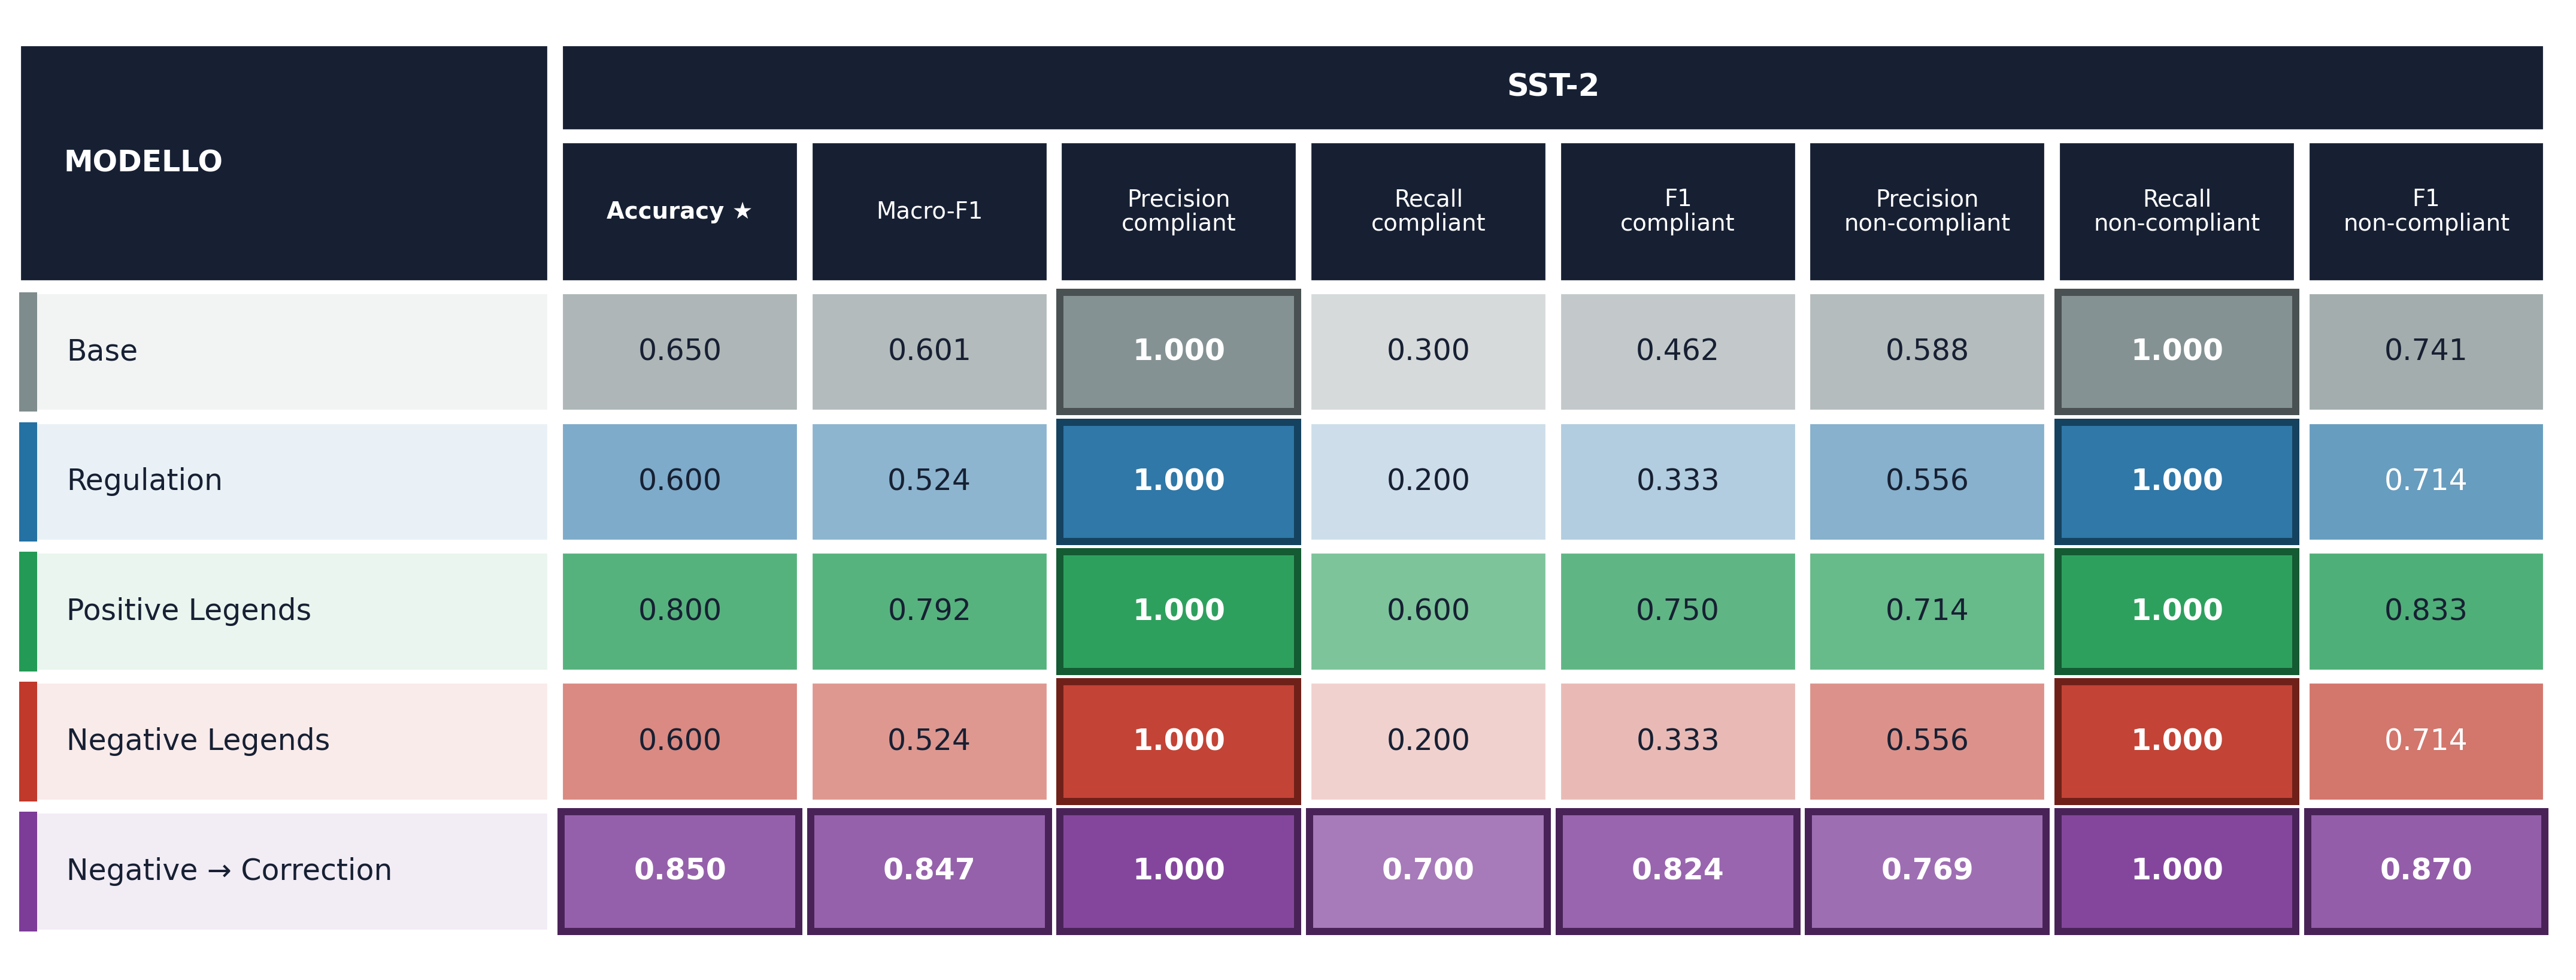

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\sst2_style\sst2_style_selected_metrics_matrix.png

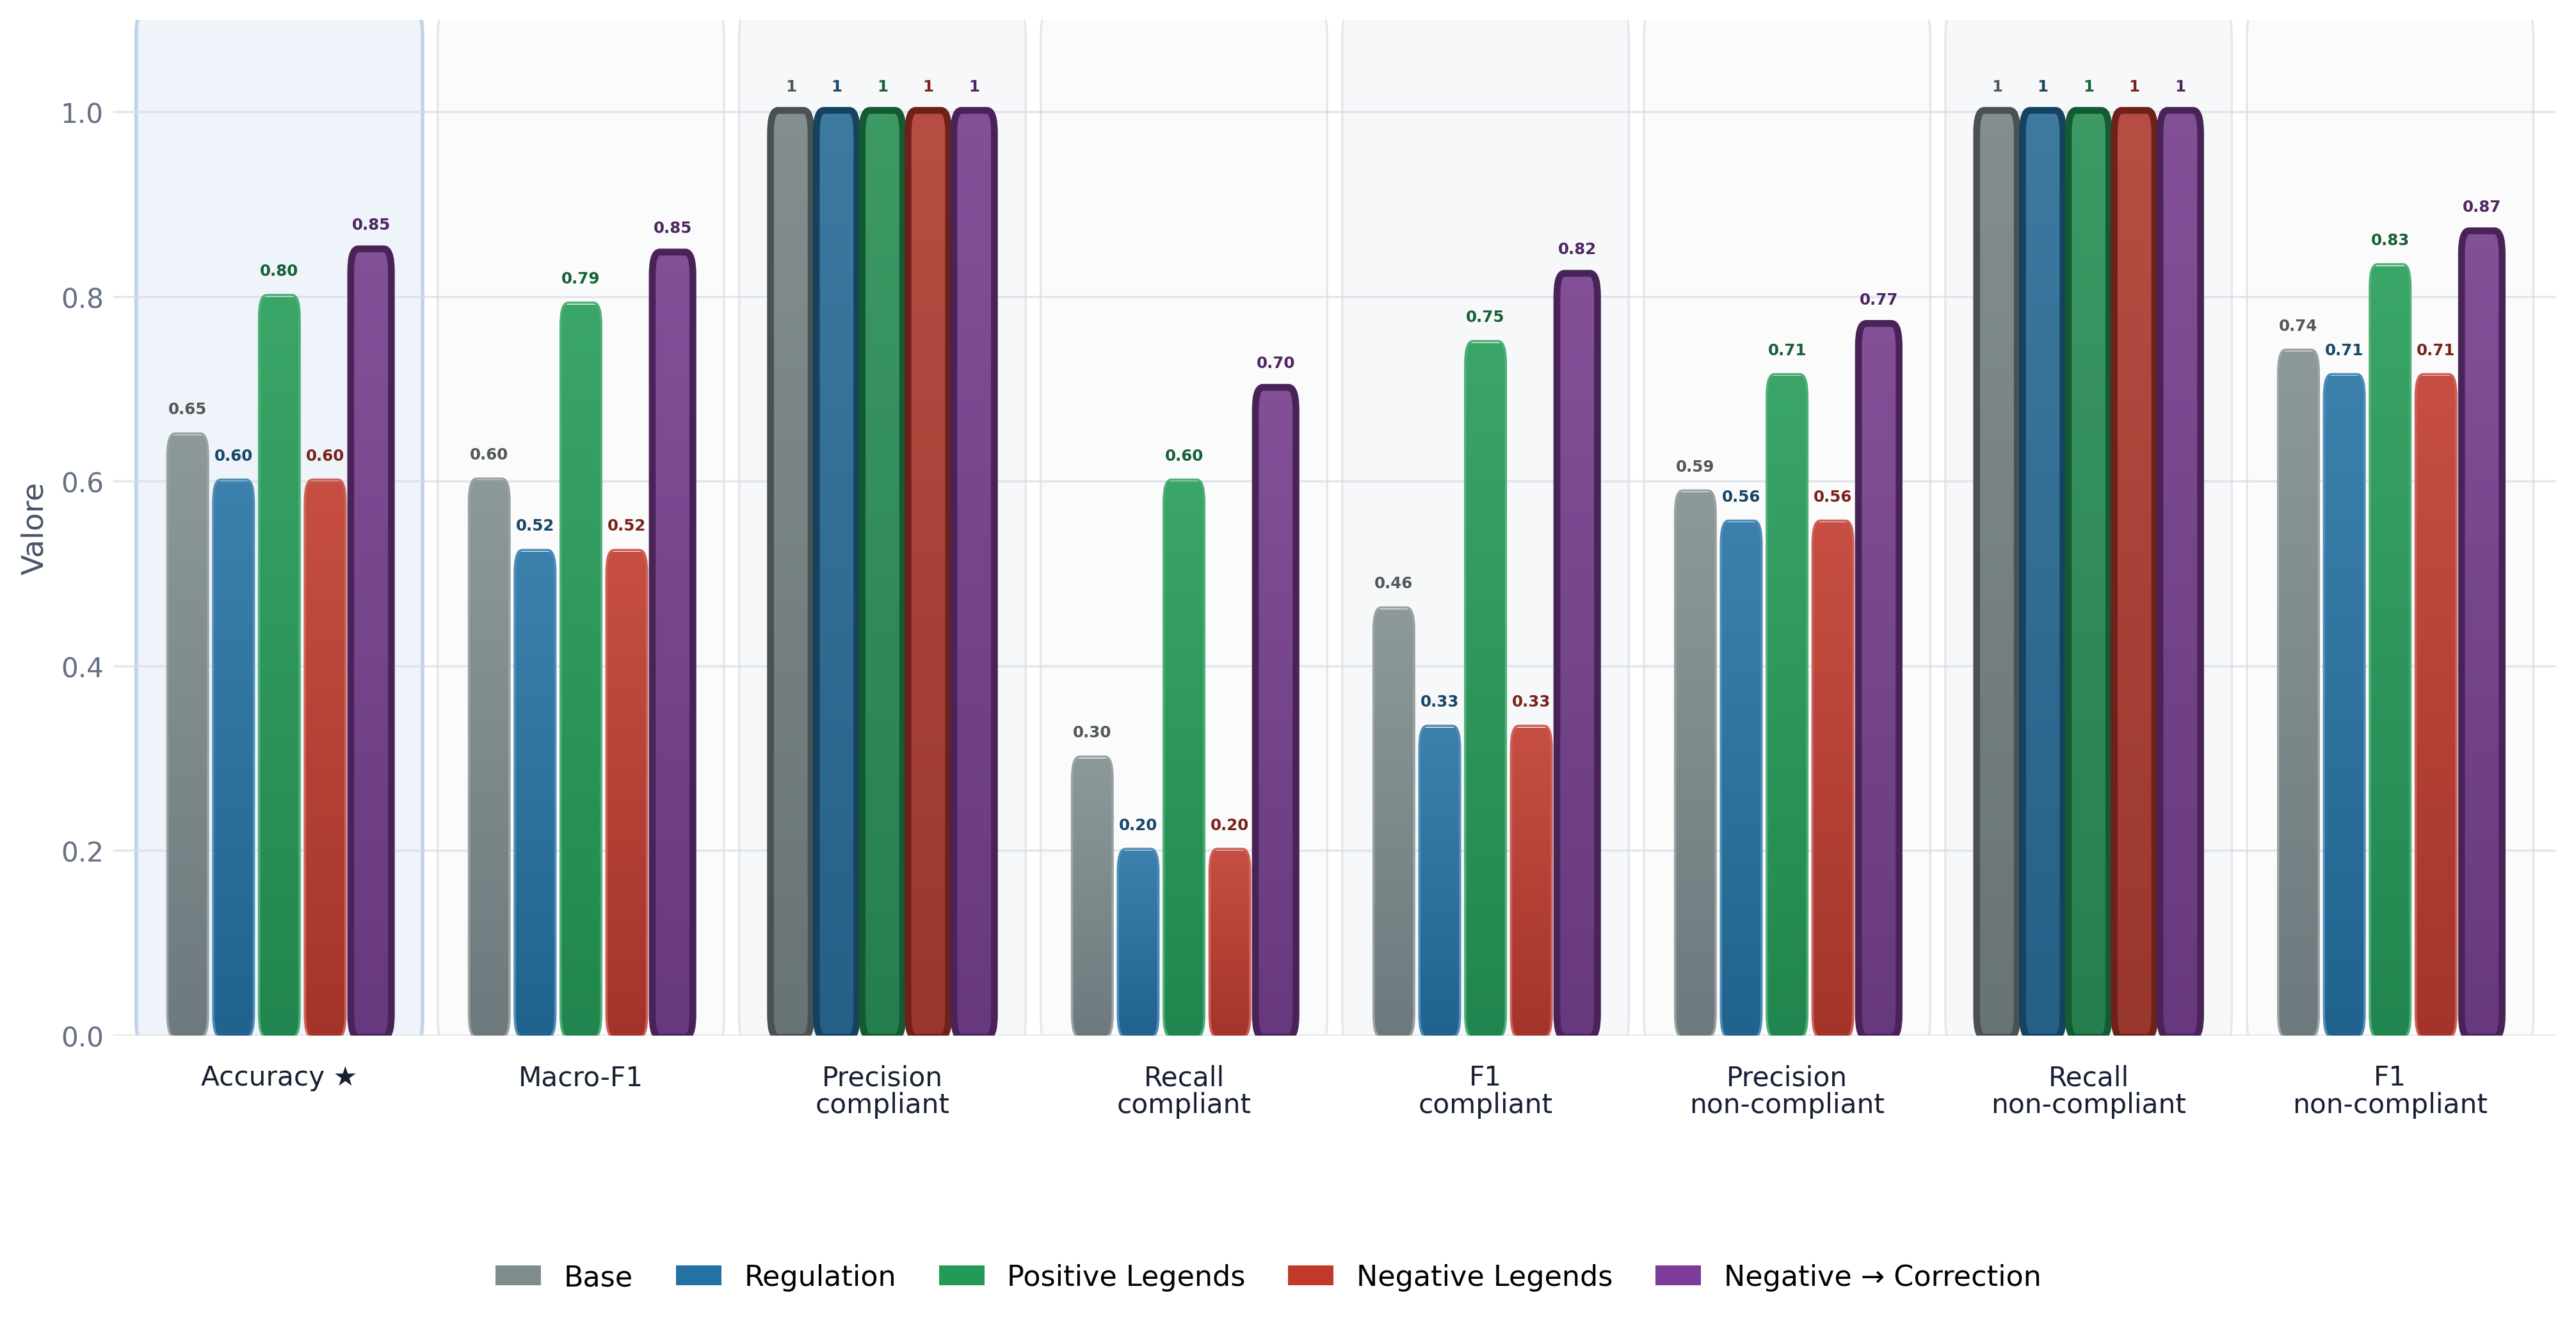

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\sst2_style\sst2_style_selected_metrics_grouped_bars.png

### Interpretazione per l'esposizione

1. Nel task SST-2, Negative → Correction ottiene il miglior primary score (0.850), con un vantaggio di 0.050 su Positive Legends.

2. Sulle 7 metriche diagnostiche, Negative → Correction ottiene il maggior numero di risultati al vertice (7), incluse le eventuali parità.


Task: SST-2
Metriche mostrate: 8
Matrice PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\sst2_style\sst2_style_selected_metrics_matrix.png
Istogramma PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\sst2_style\sst2_style_selected_metrics_grouped_bars.png
CSV: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\tables\sst2_style_selected_metrics.csv


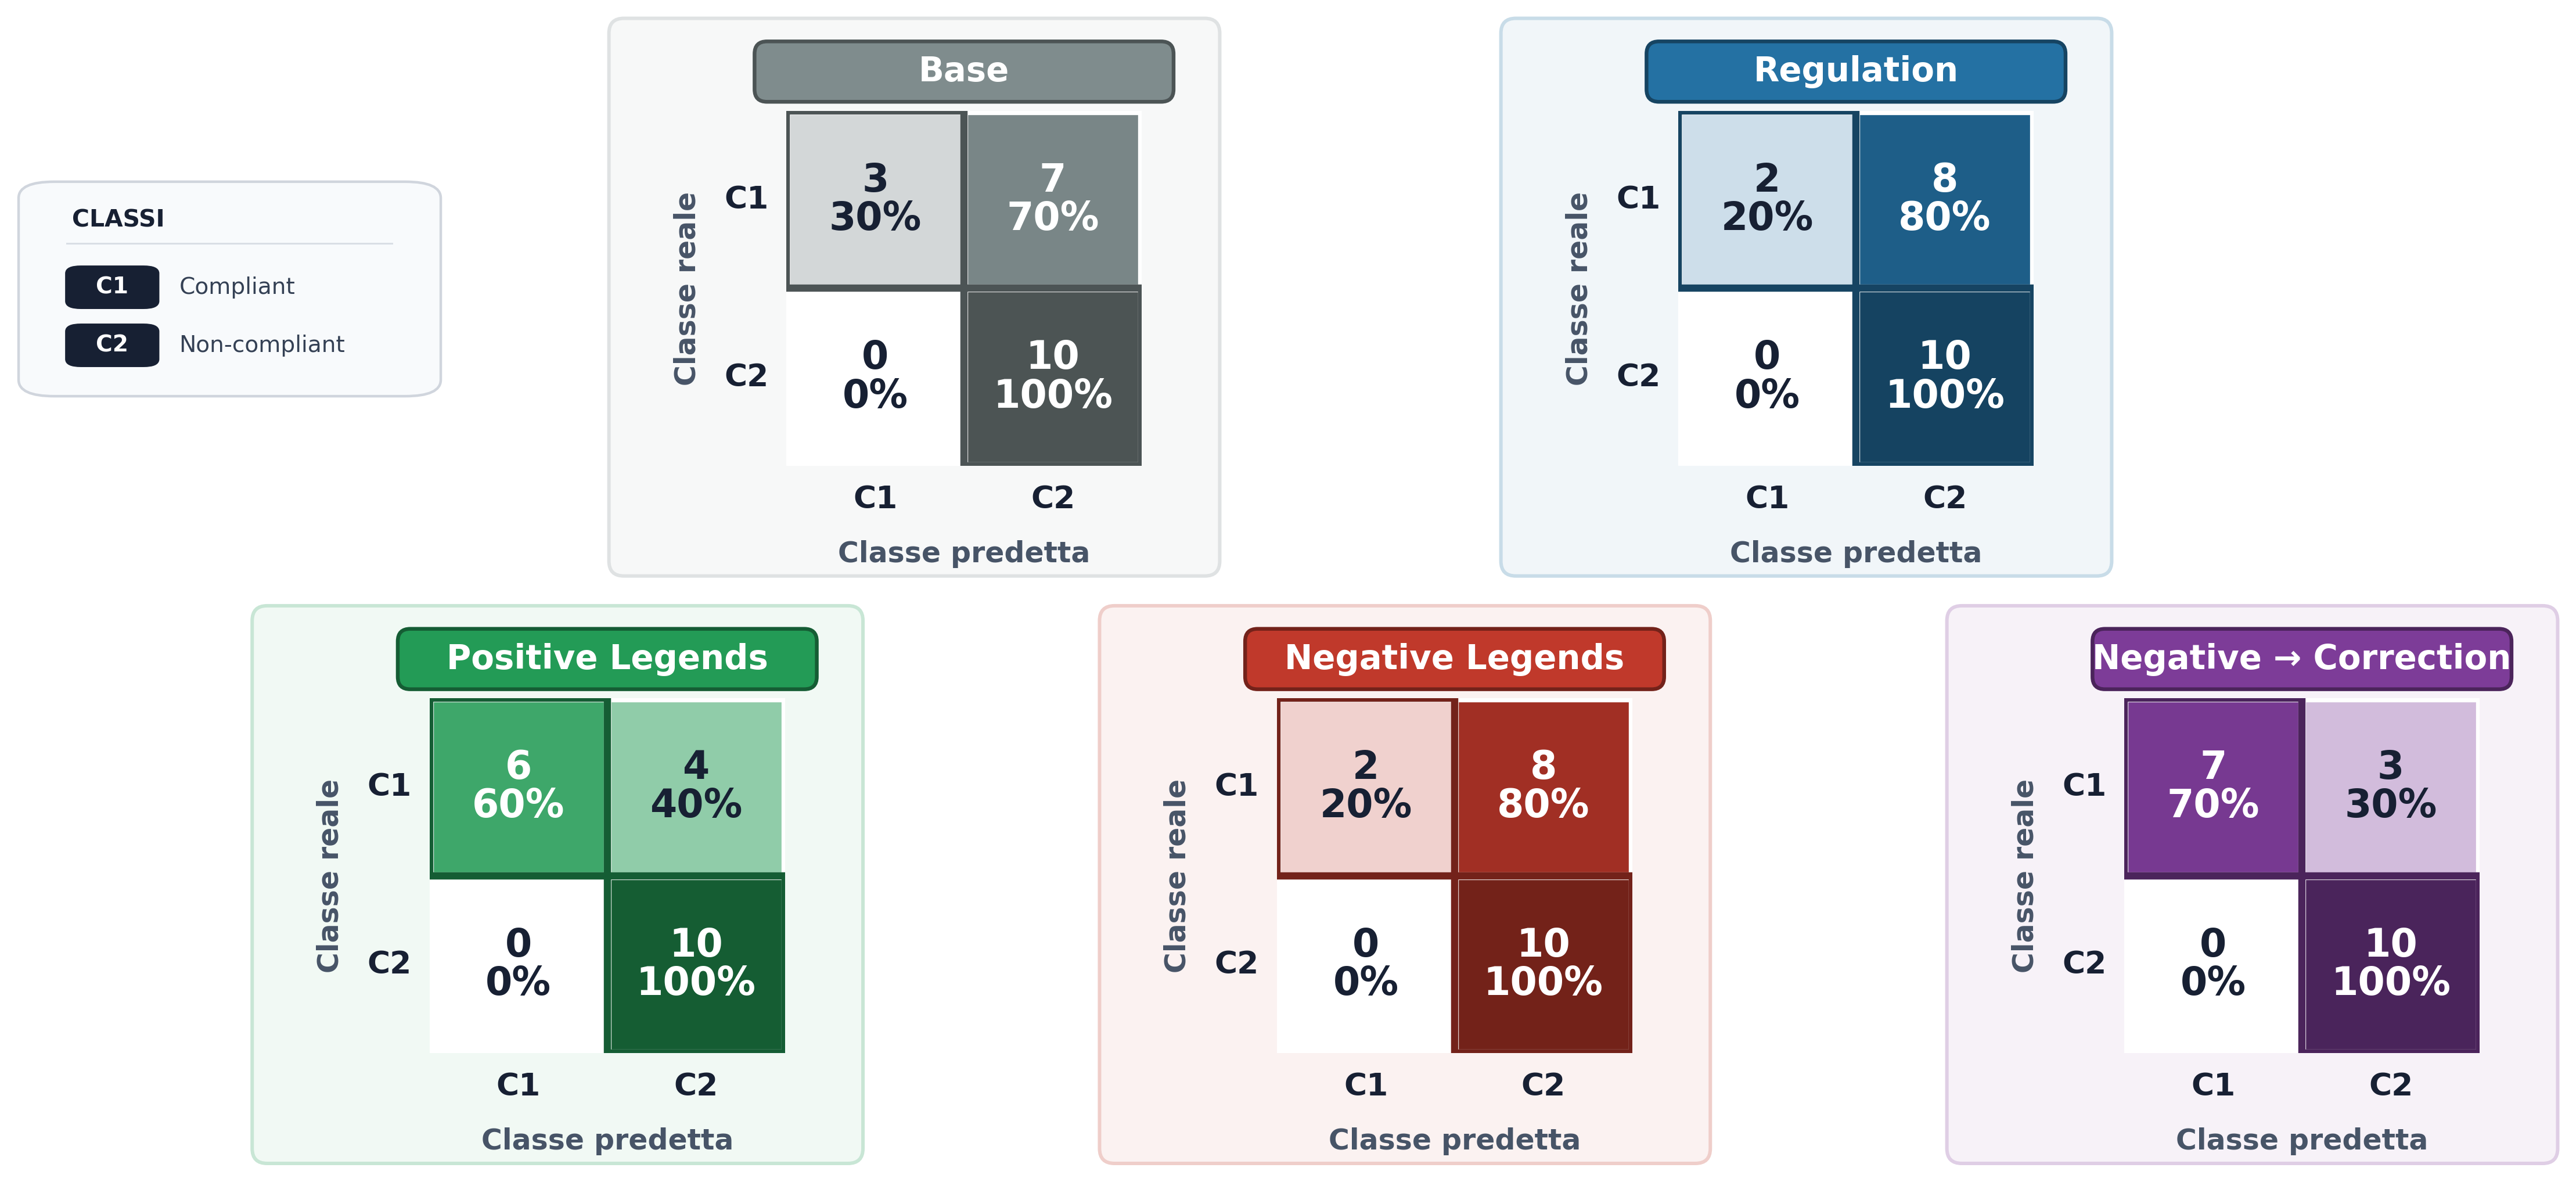

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\sst2_style\sst2_style_confusion_matrices.png


Confusion matrix generate per: SST-2
PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\sst2_style\sst2_style_confusion_matrices.png
CSV: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\tables\sst2_style_confusion_matrices.csv


In [555]:
# CELLA 31 — Genera tutti gli output per SST-2,
# incluse le confusion matrix.

sst2_outputs = render_complete_task_zoom(
    task_name="sst2_style"
)

# 8. Zoom task — Paraphrase

Il task Paraphrase style valuta la capacità di riconoscere se due formulazioni
esprimano un contenuto equivalente.

La metrica rappresentativa combina:

- Accuracy;
- F1 della classe `equivalent`.

L'approfondimento permette di verificare se un modello riconosca correttamente
le equivalenze senza classificare come equivalenti anche coppie semanticamente
differenti.

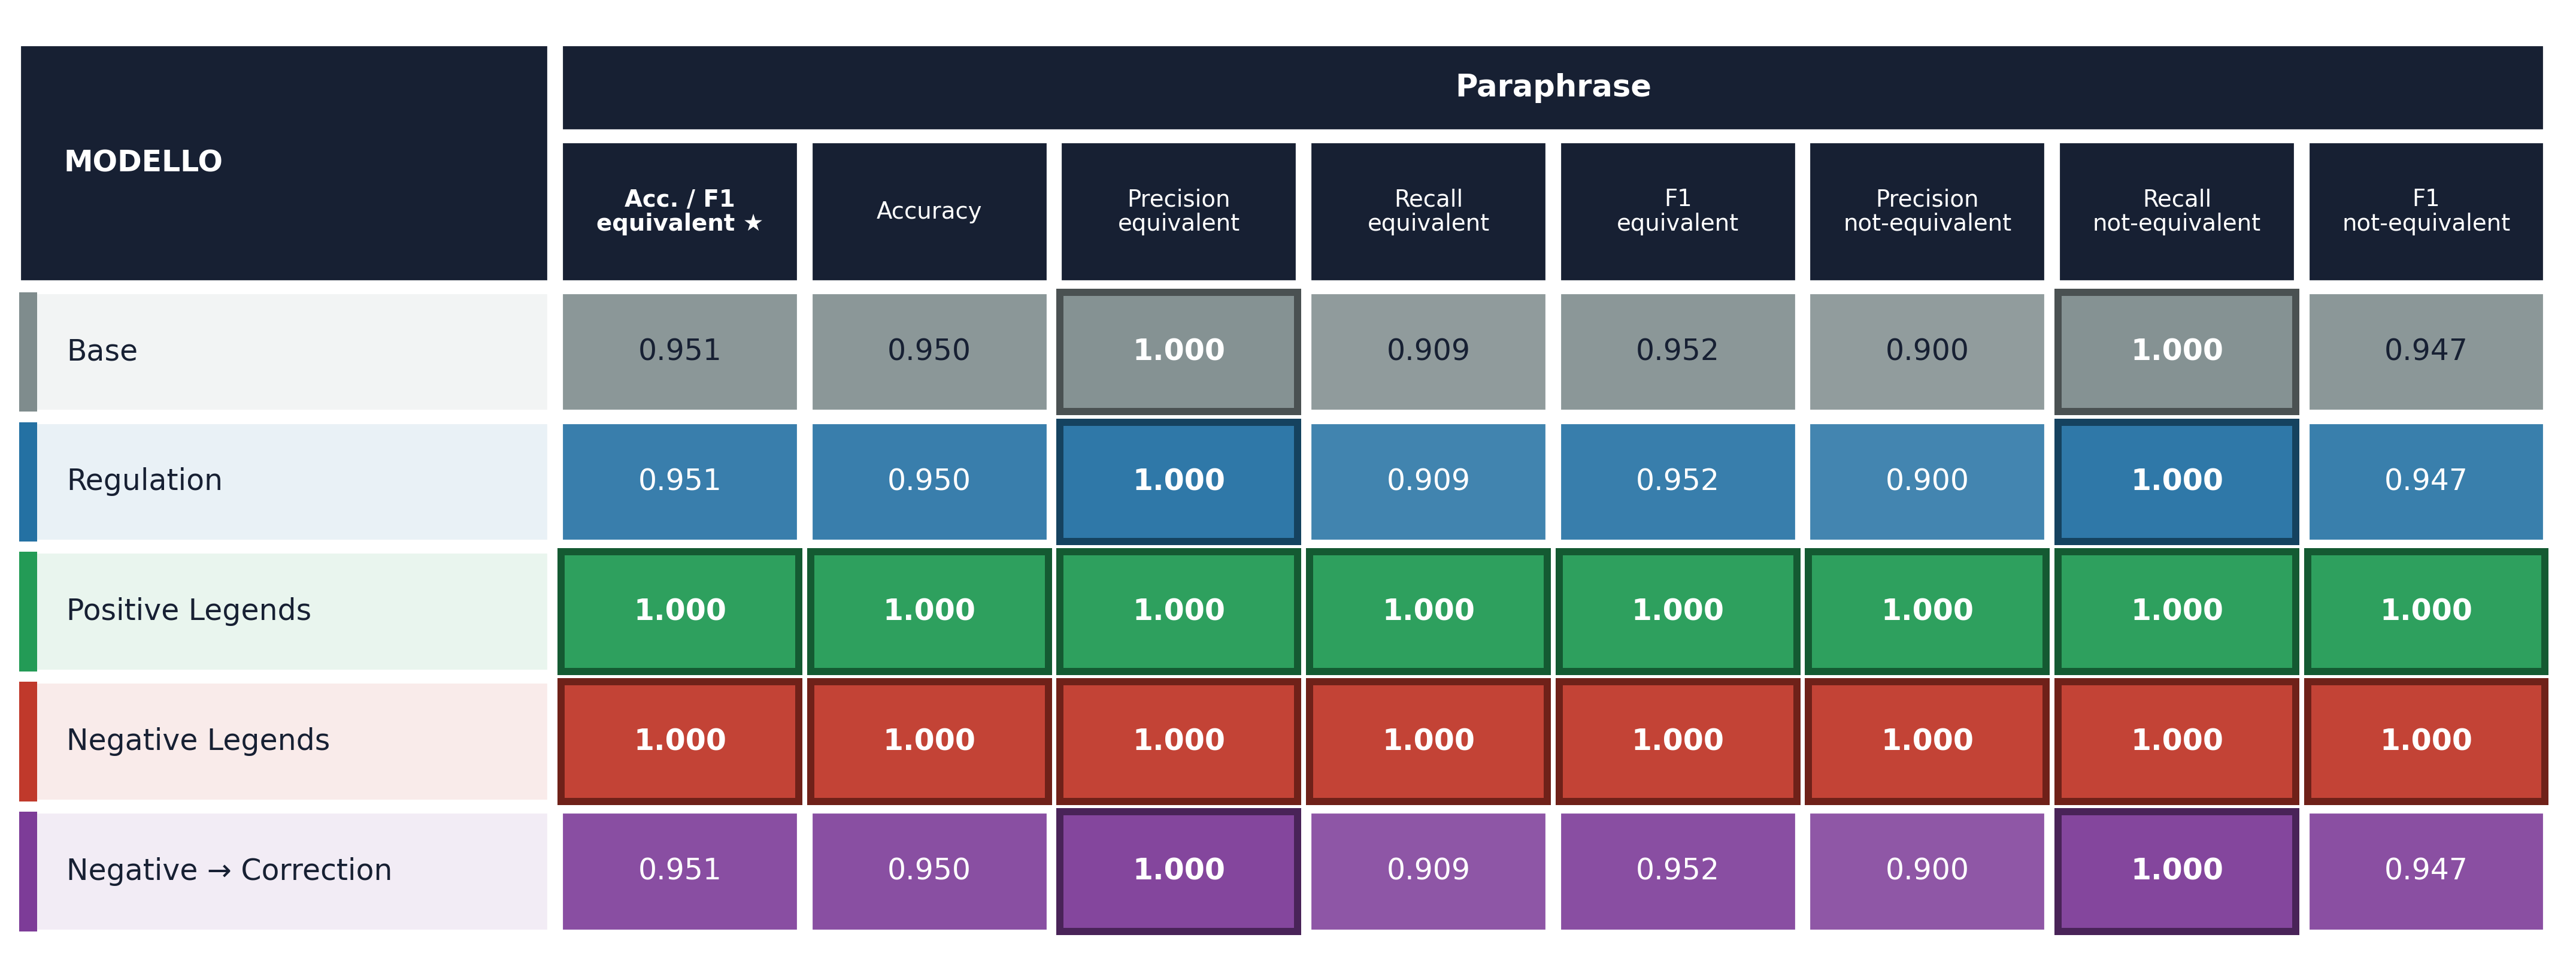

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\paraphrase_style\paraphrase_style_selected_metrics_matrix.png

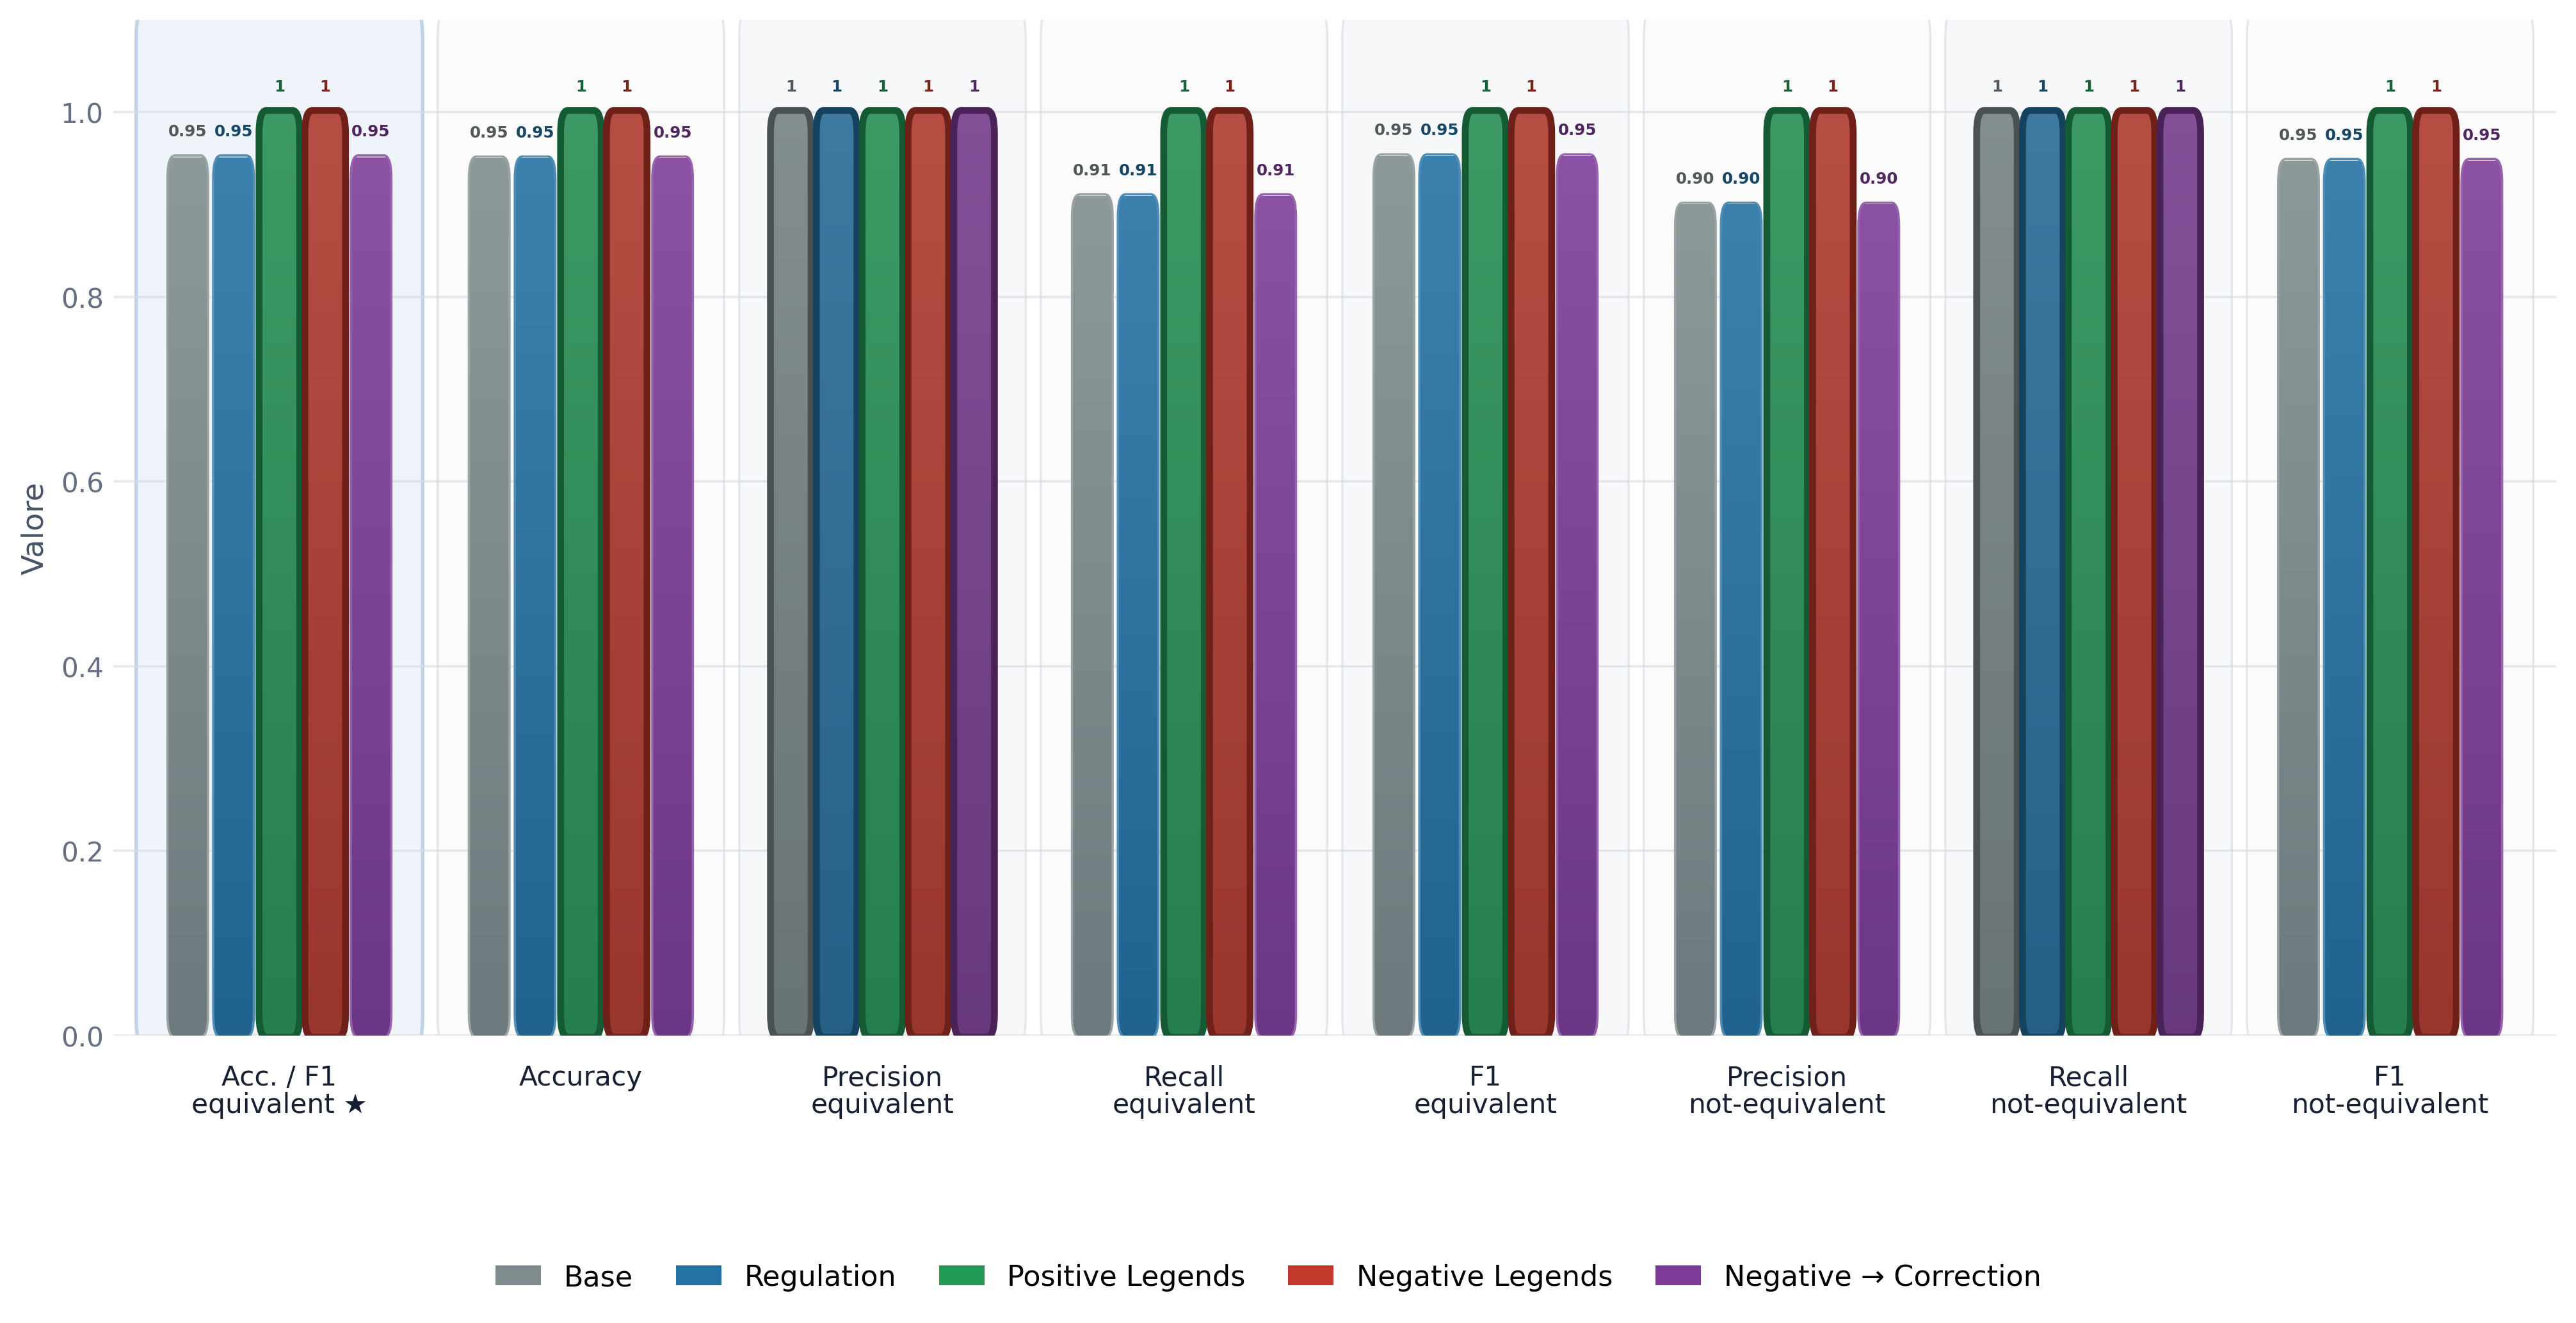

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\paraphrase_style\paraphrase_style_selected_metrics_grouped_bars.png

### Interpretazione per l'esposizione

1. Nel task Paraphrase, Positive Legends, Negative Legends condividono il miglior primary score, pari a 1.000.

2. Sulle 7 metriche diagnostiche, Positive Legends, Negative Legends ottiene il maggior numero di risultati al vertice (7), incluse le eventuali parità.


Task: Paraphrase
Metriche mostrate: 8
Matrice PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\paraphrase_style\paraphrase_style_selected_metrics_matrix.png
Istogramma PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\paraphrase_style\paraphrase_style_selected_metrics_grouped_bars.png
CSV: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\tables\paraphrase_style_selected_metrics.csv


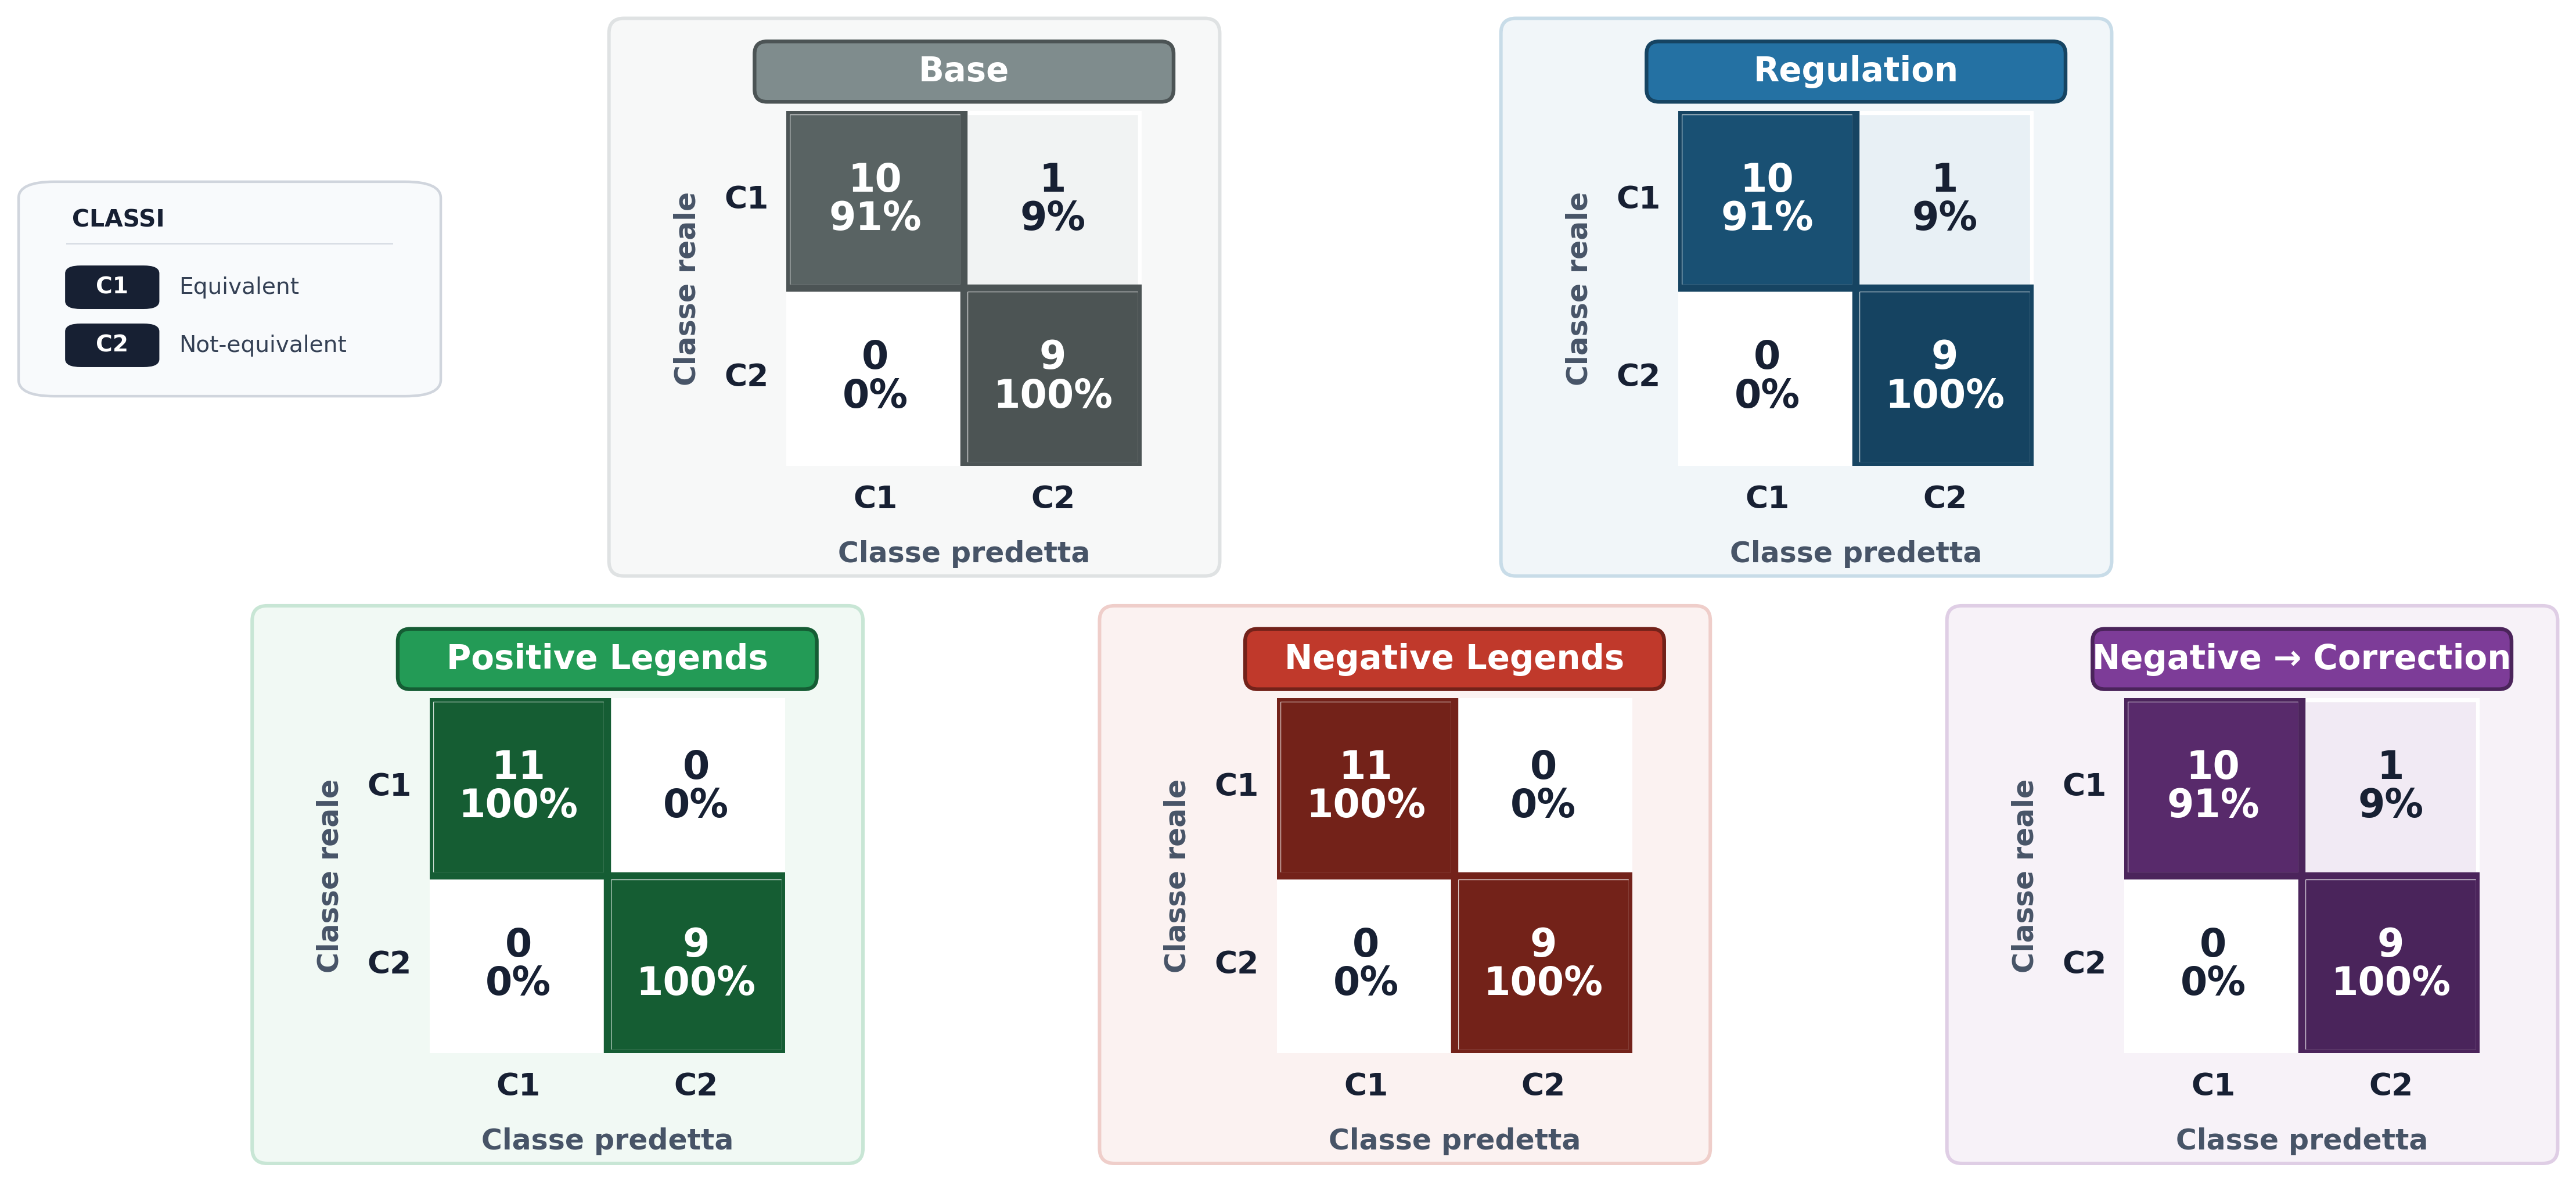

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\paraphrase_style\paraphrase_style_confusion_matrices.png


Confusion matrix generate per: Paraphrase
PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\paraphrase_style\paraphrase_style_confusion_matrices.png
CSV: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\tables\paraphrase_style_confusion_matrices.csv


In [556]:
paraphrase_outputs = render_complete_task_zoom(
    task_name="paraphrase_style"
)

# 9. Zoom task — QQP

Il task QQP style valuta la capacità di riconoscere contenuti duplicati.

La metrica rappresentativa combina:

- Accuracy;
- F1 della classe `duplicate`.

L'analisi dettagliata permette di distinguere tra capacità di riconoscere
duplicati reali e tendenza a considerare duplicati contenuti soltanto simili.

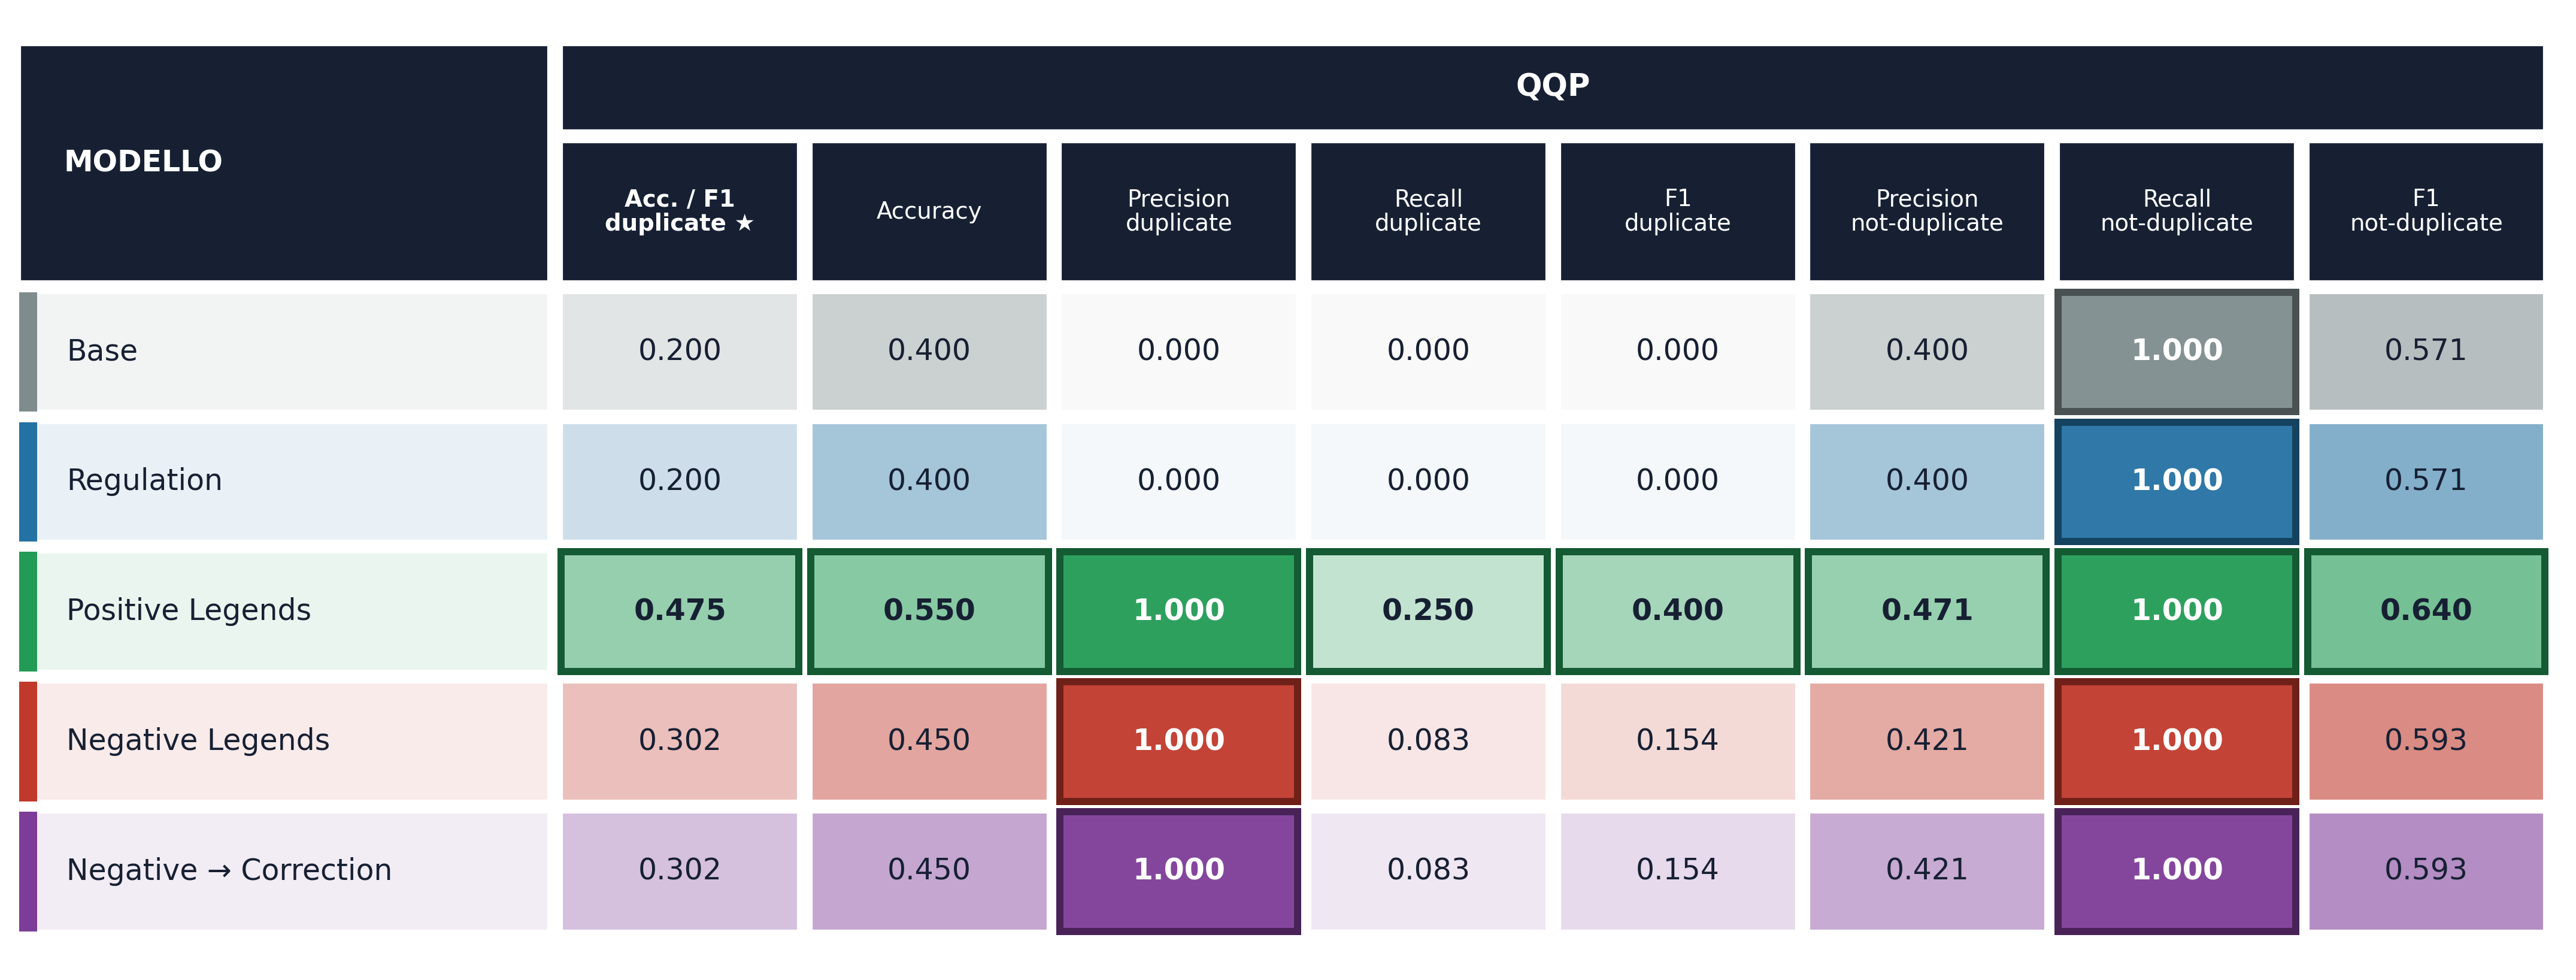

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\qqp_style\qqp_style_selected_metrics_matrix.png

C:\Users\ab161\AppData\Local\Temp\ipykernel_7840\2391473429.py:494: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  image = axis.imshow(
C:\Users\ab161\AppData\Local\Temp\ipykernel_7840\2391473429.py:494: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  image = axis.imshow(
C:\Users\ab161\AppData\Local\Temp\ipykernel_7840\2391473429.py:494: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  image = axis.imshow(
C:\Users\ab161\AppData\Local\Temp\ipykernel_7840\2391473429.py:494: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically expanding.
  image = axis.imshow(
C:\Users\ab161\AppData\Local\Temp\ipykernel_7840\2391473429.py:494: UserWarning: Attempting to set identical low and high ylims makes transformation singular; automatically

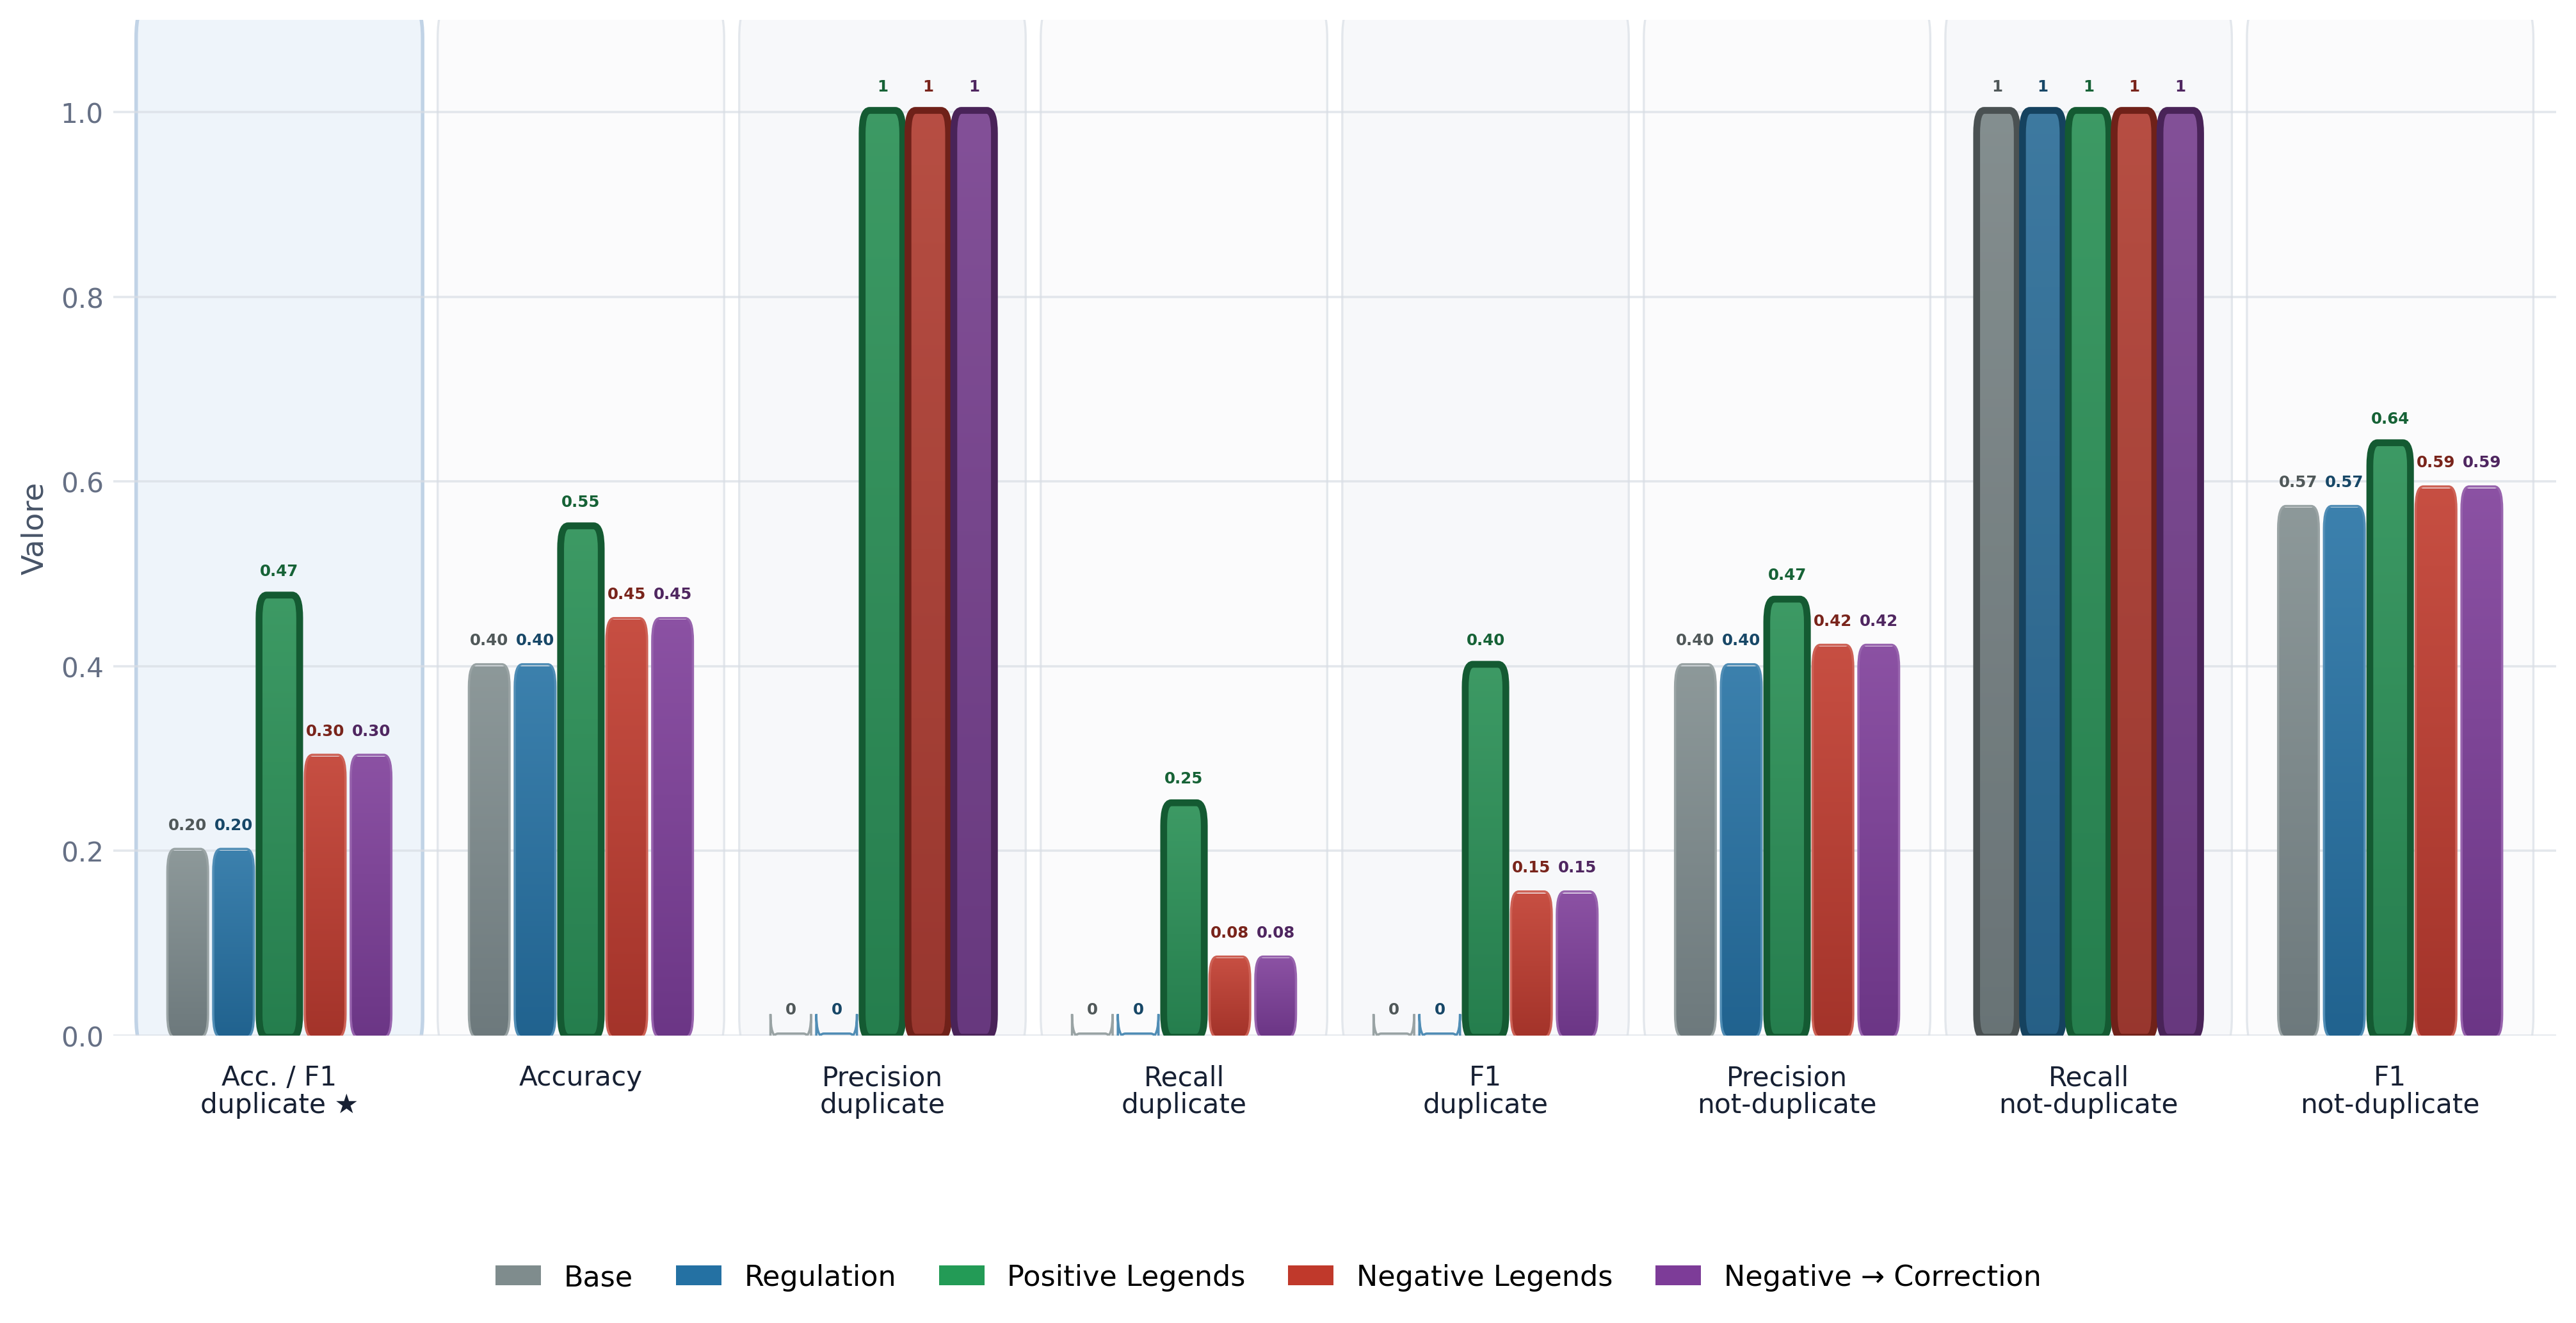

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\qqp_style\qqp_style_selected_metrics_grouped_bars.png

### Interpretazione per l'esposizione

1. Nel task QQP, Positive Legends ottiene il miglior primary score (0.475), con un vantaggio di 0.173 su Negative → Correction.

2. Sulle 7 metriche diagnostiche, Positive Legends ottiene il maggior numero di risultati al vertice (7), incluse le eventuali parità.


Task: QQP
Metriche mostrate: 8
Matrice PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\qqp_style\qqp_style_selected_metrics_matrix.png
Istogramma PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\qqp_style\qqp_style_selected_metrics_grouped_bars.png
CSV: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\tables\qqp_style_selected_metrics.csv


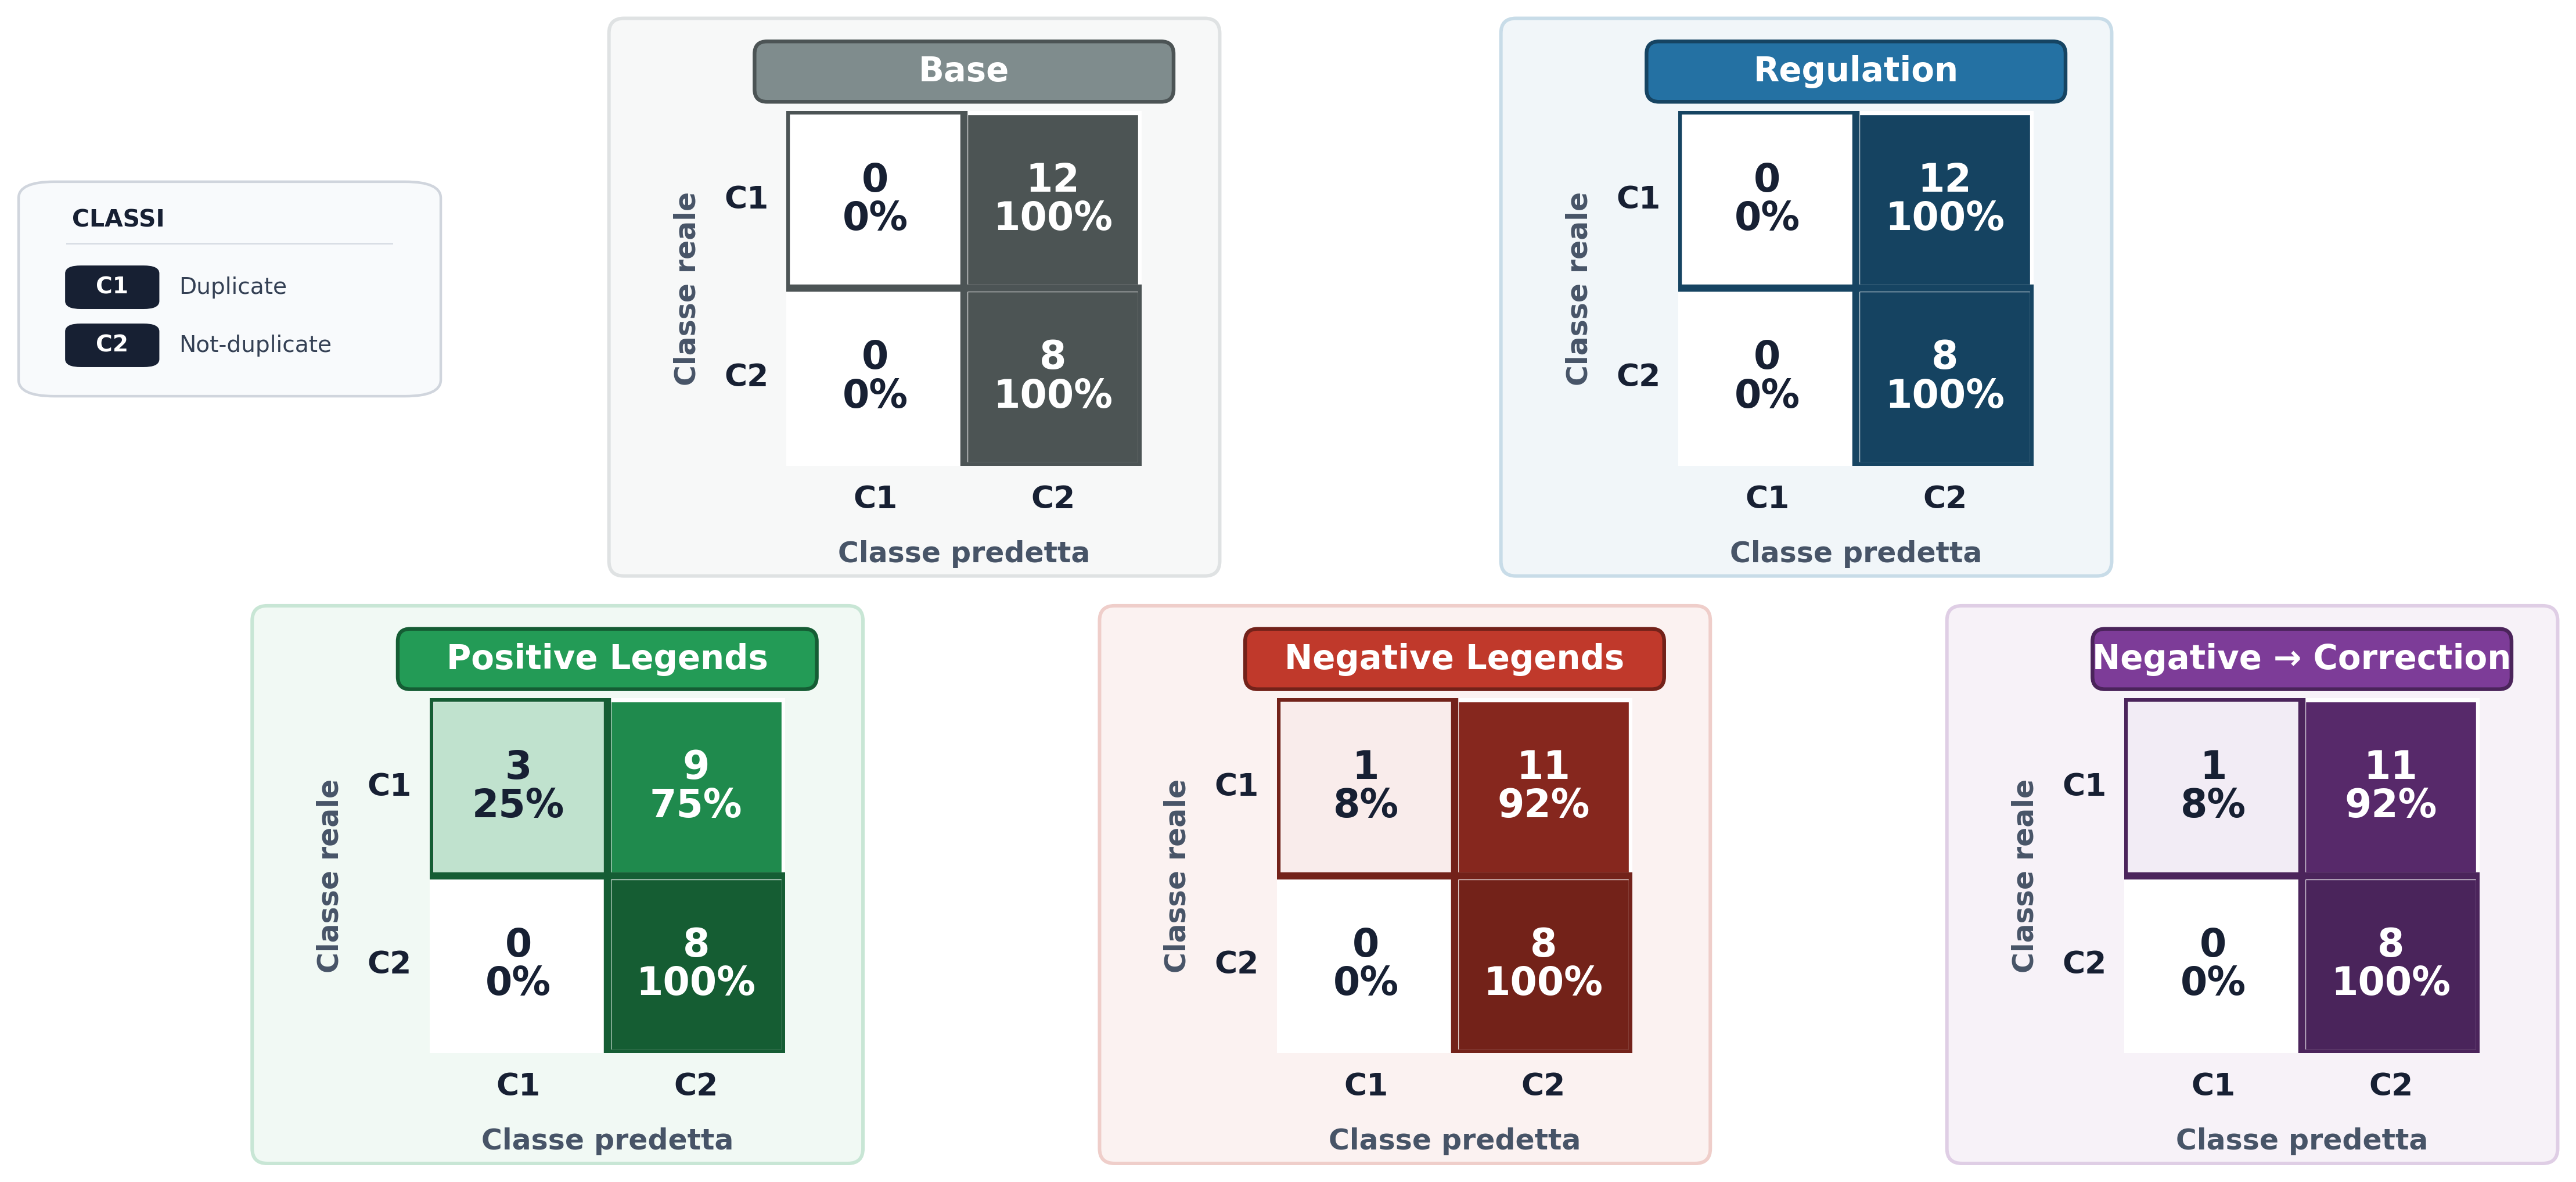

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\qqp_style\qqp_style_confusion_matrices.png


Confusion matrix generate per: QQP
PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\qqp_style\qqp_style_confusion_matrices.png
CSV: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\tables\qqp_style_confusion_matrices.csv


In [557]:
# CELLA 35 — Genera tutti gli output per QQP:
# - matrice delle metriche;
# - istogramma raggruppato;
# - confusion matrix dei cinque modelli;
# - note interpretative.

qqp_outputs = render_complete_task_zoom(
    task_name="qqp_style")

# 10. Zoom task — MNLI

Il task MNLI style valuta tre relazioni:

- entailment;
- contradiction;
- neutral.

La metrica rappresentativa è l'Accuracy.

Le metriche per classe sono particolarmente importanti, perché un valore
complessivo elevato potrebbe nascondere difficoltà specifiche nel riconoscimento
della neutralità o delle contraddizioni.

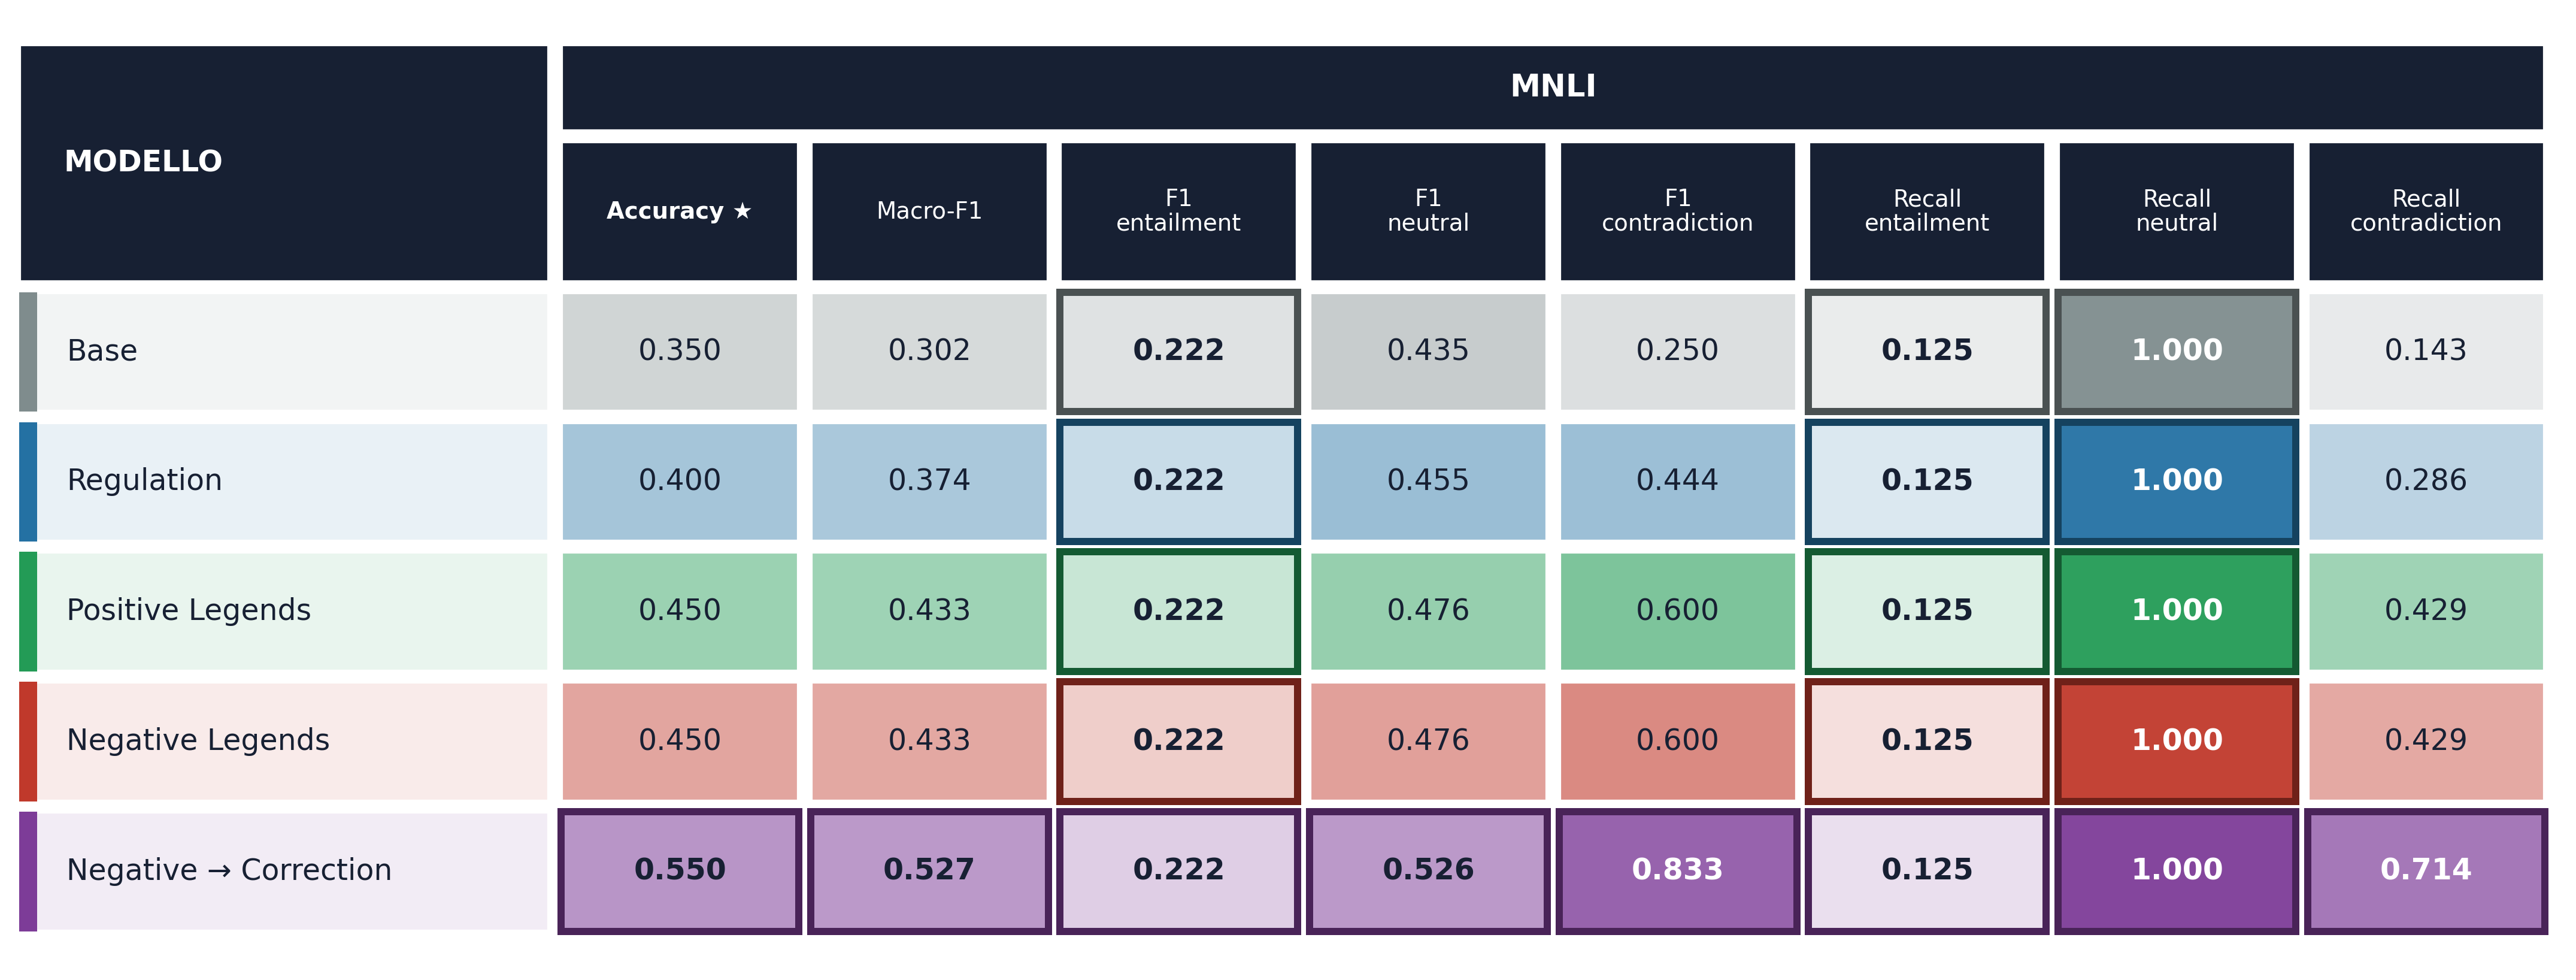

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\mnli_style\mnli_style_selected_metrics_matrix.png

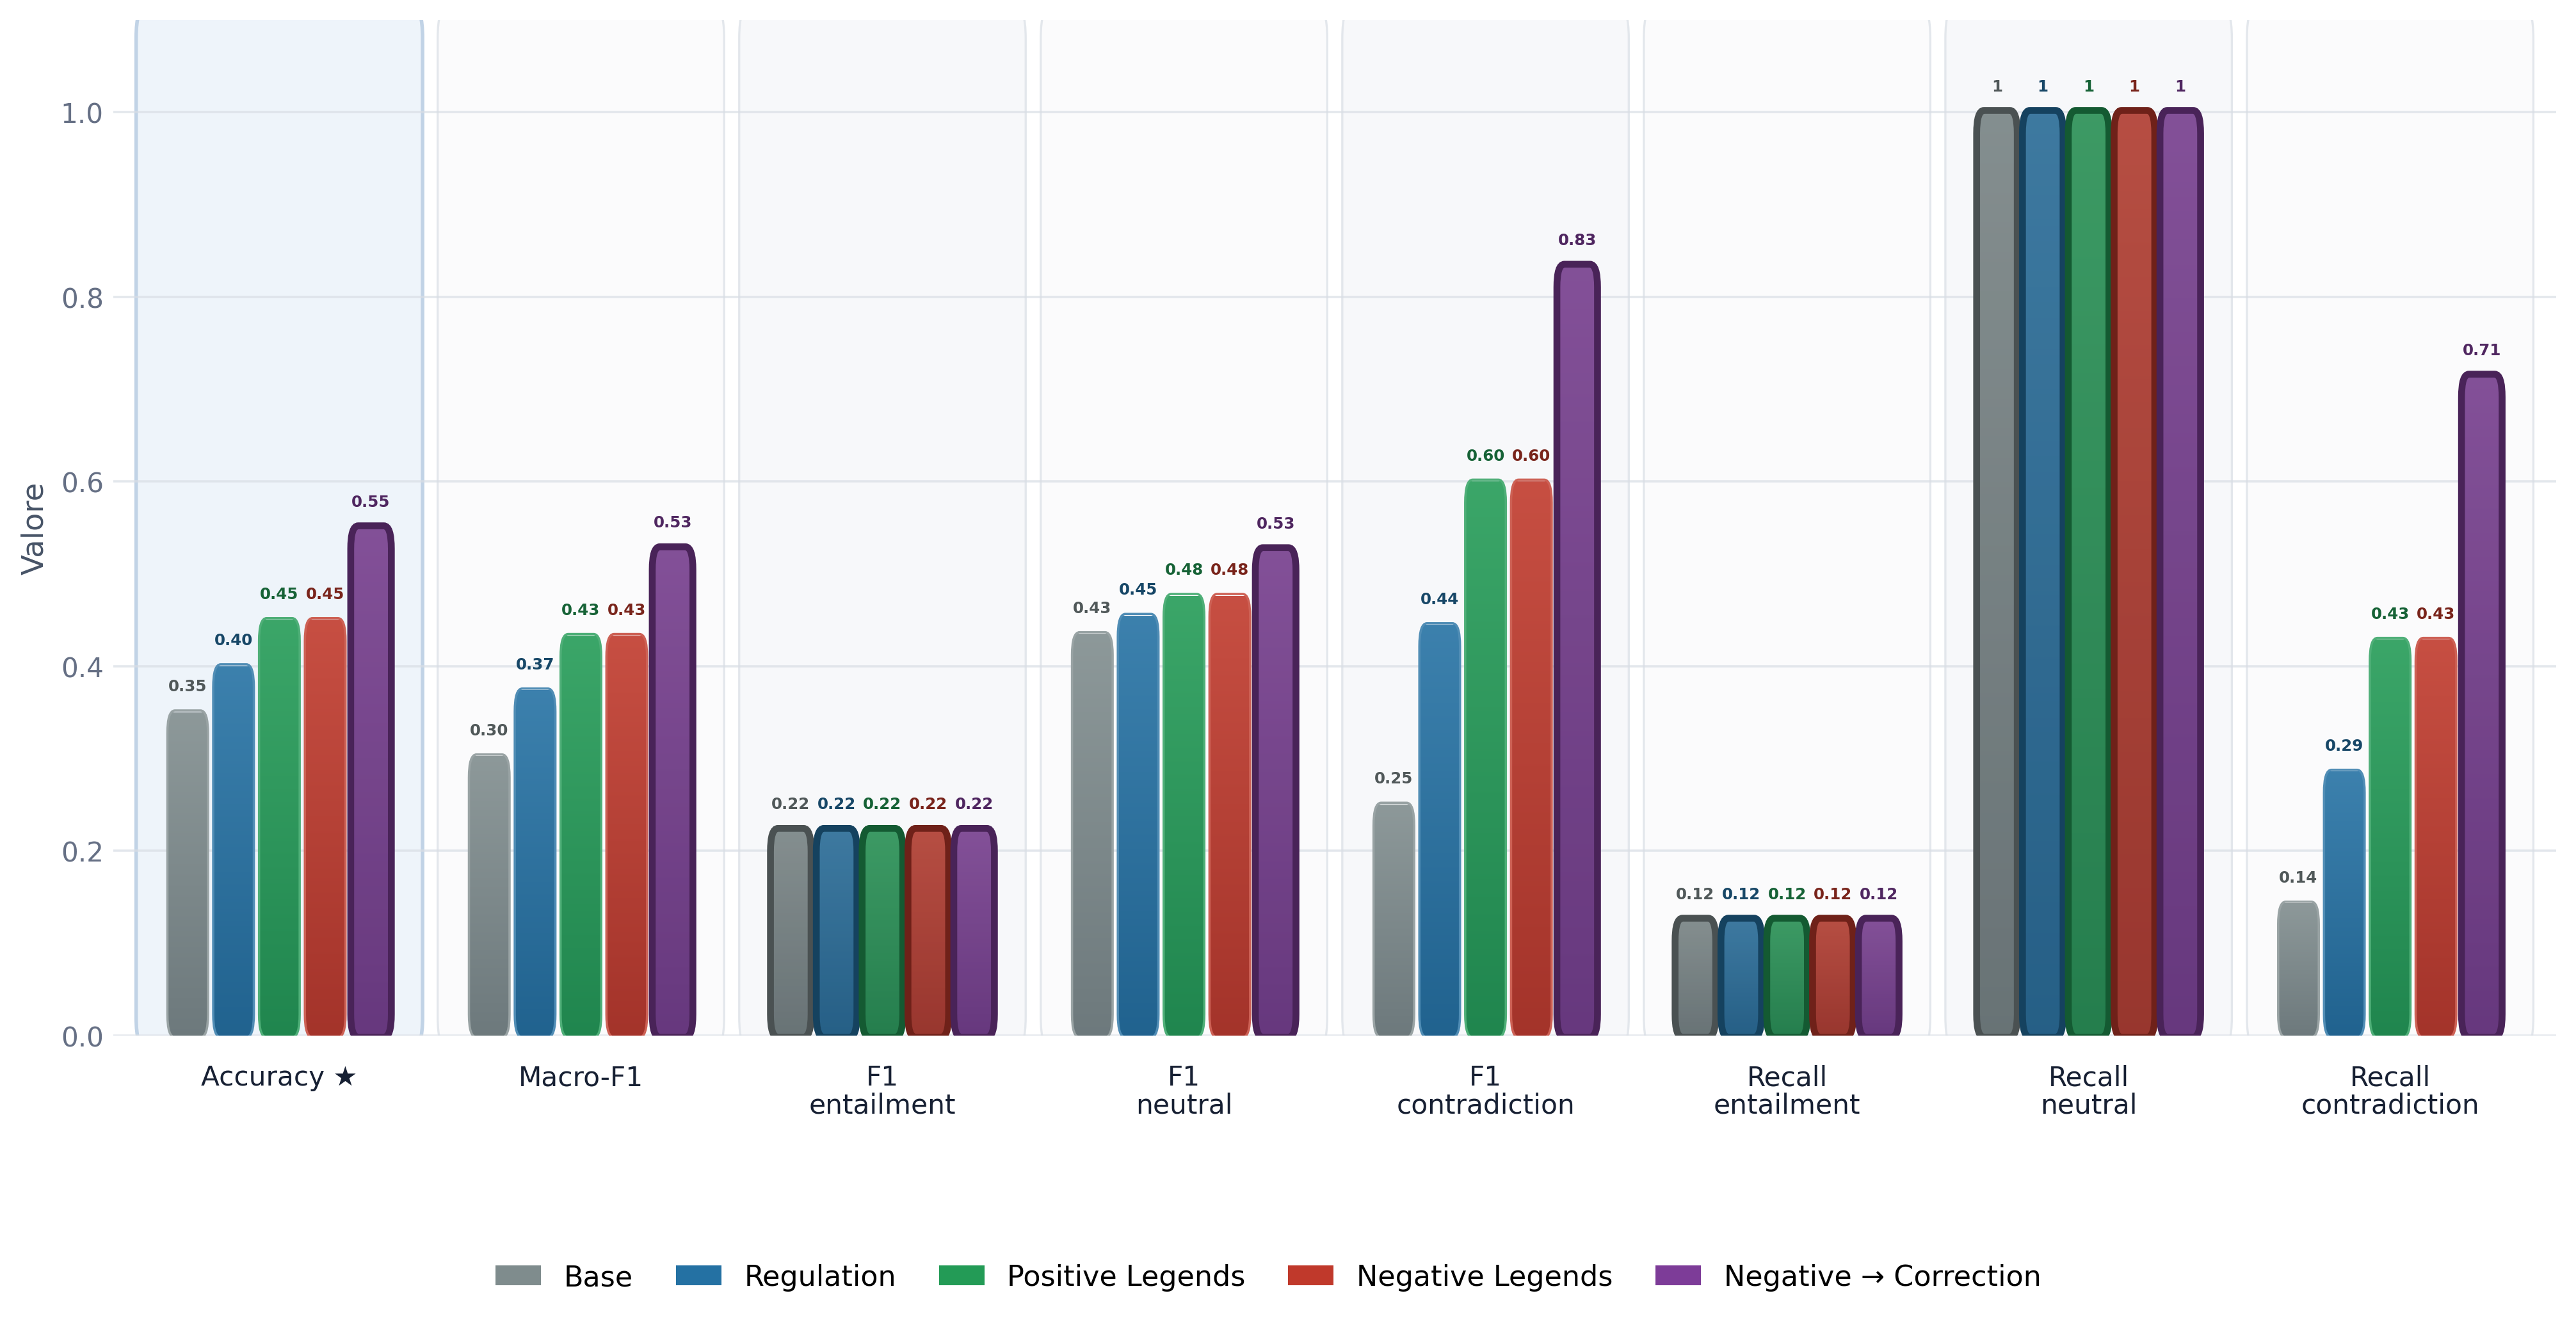

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\mnli_style\mnli_style_selected_metrics_grouped_bars.png

### Interpretazione per l'esposizione

1. Nel task MNLI, Negative → Correction ottiene il miglior primary score (0.550), con un vantaggio di 0.100 su Negative Legends.

2. Sulle 7 metriche diagnostiche, Negative → Correction ottiene il maggior numero di risultati al vertice (7), incluse le eventuali parità.


Task: MNLI
Metriche mostrate: 8
Matrice PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\mnli_style\mnli_style_selected_metrics_matrix.png
Istogramma PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\mnli_style\mnli_style_selected_metrics_grouped_bars.png
CSV: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\tables\mnli_style_selected_metrics.csv


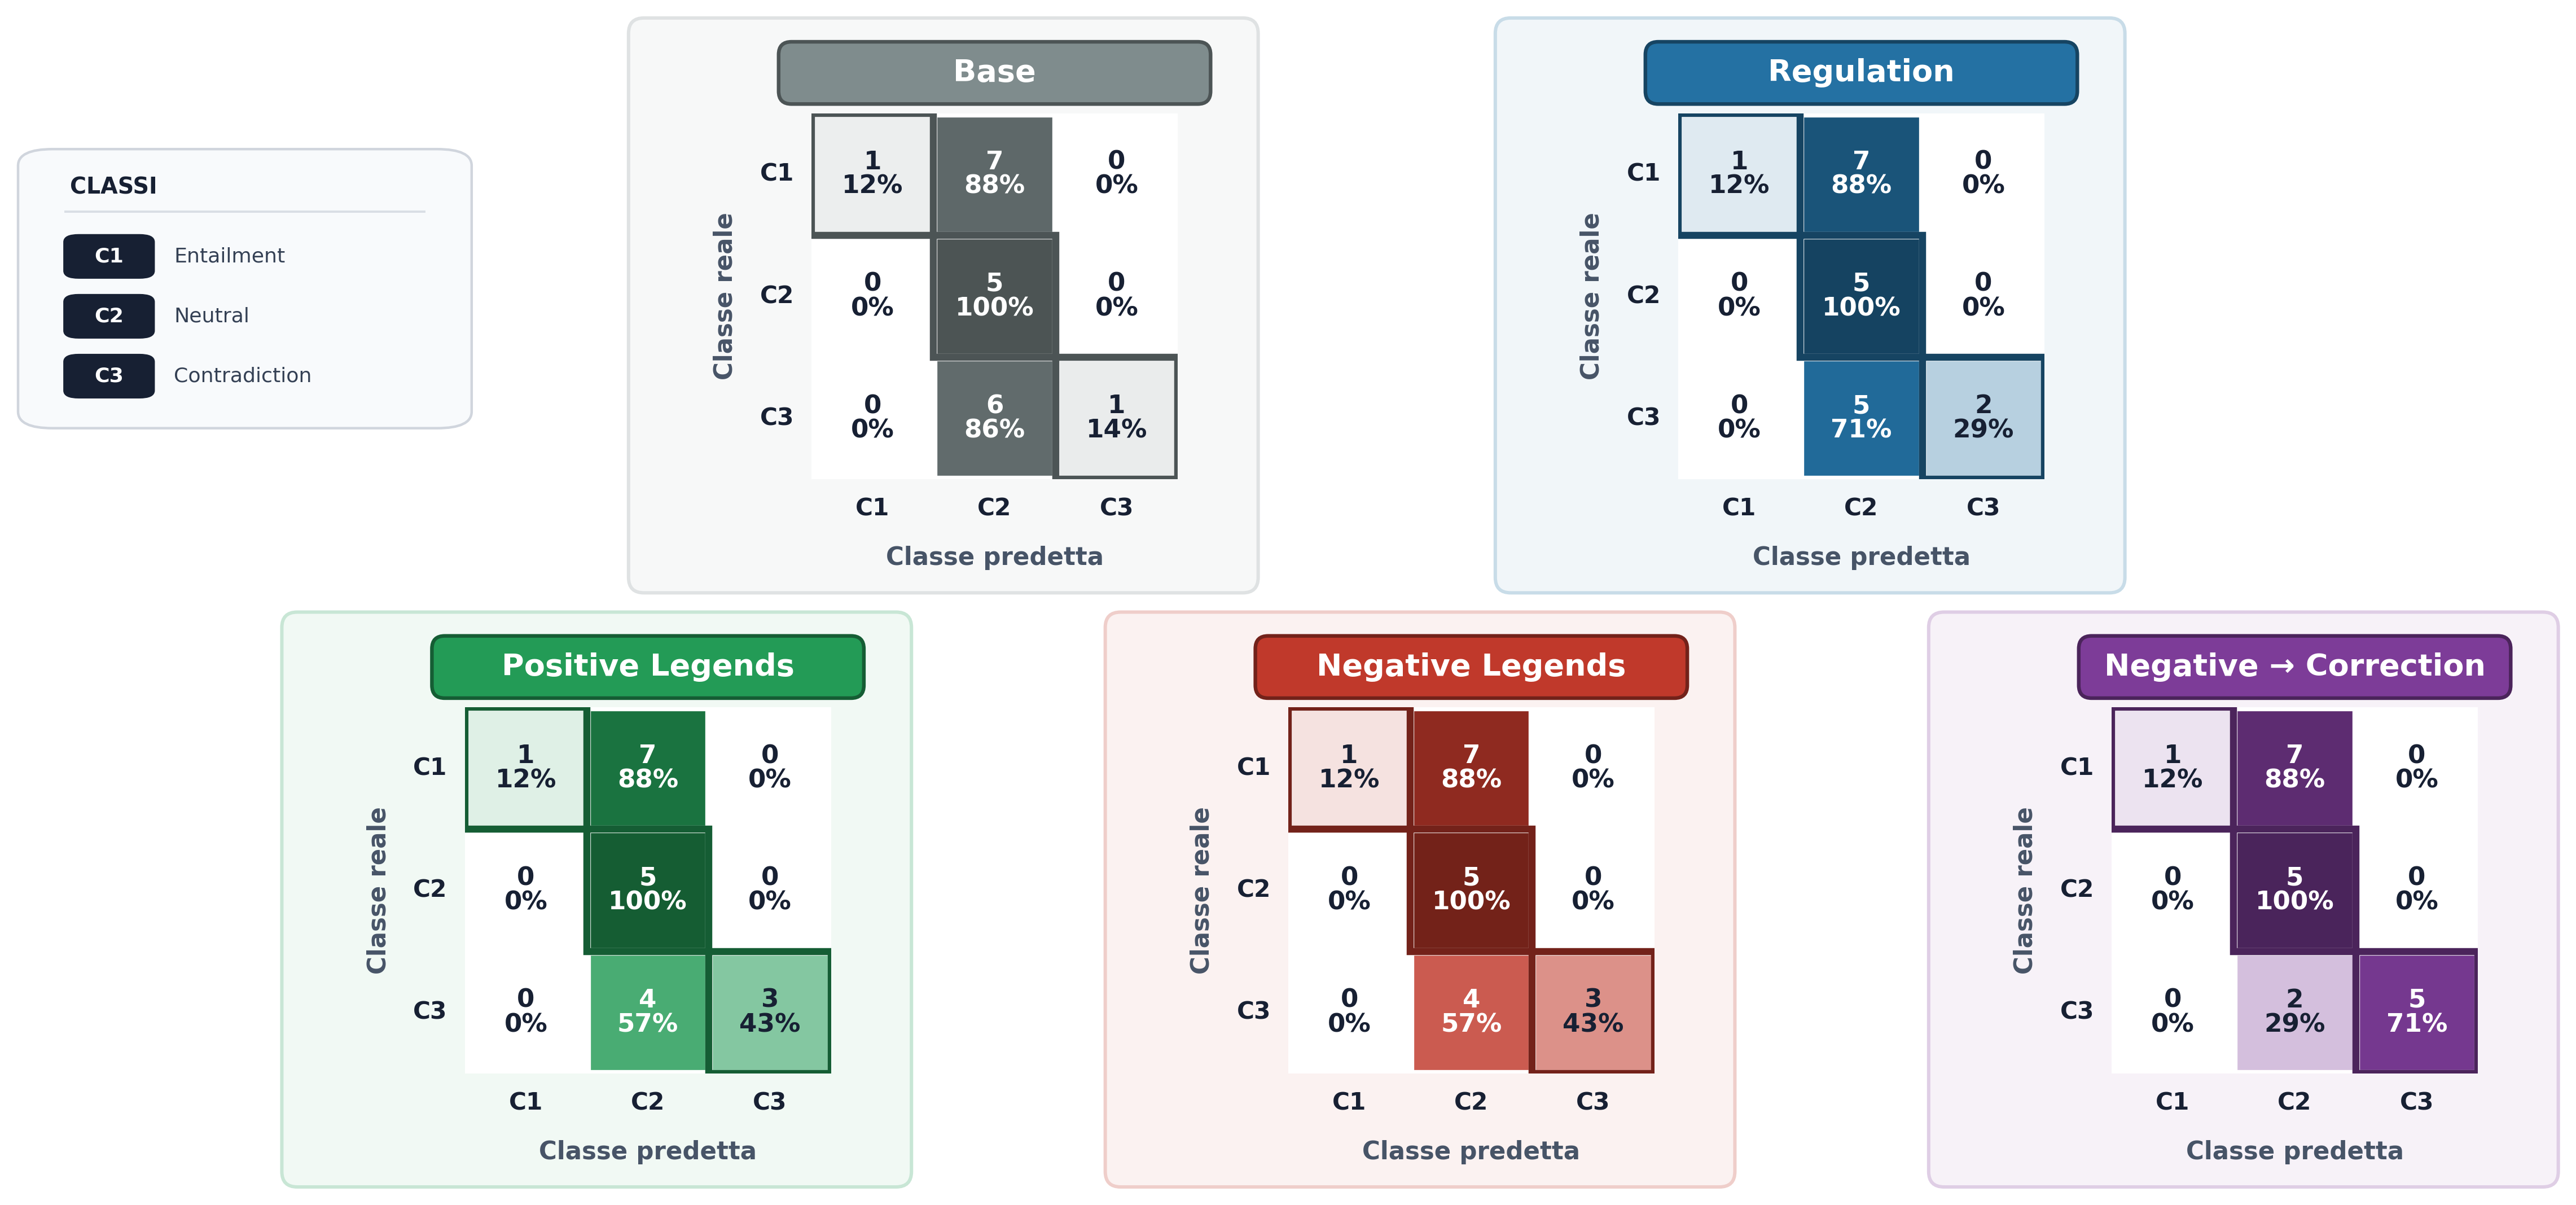

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\mnli_style\mnli_style_confusion_matrices.png


Confusion matrix generate per: MNLI
PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\mnli_style\mnli_style_confusion_matrices.png
CSV: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\tables\mnli_style_confusion_matrices.csv


In [558]:
# CELLA 37 — Genera tutti gli output per MNLI:
# - matrice delle metriche;
# - istogramma raggruppato;
# - confusion matrix 3×3 dei cinque modelli;
# - note interpretative.

mnli_outputs = render_complete_task_zoom(
    task_name="mnli_style"
)

# 11. Zoom task — RTE

Il task RTE style valuta se un contenuto implichi o meno un altro contenuto.

La metrica rappresentativa è l'Accuracy.

Le metriche diagnostiche permettono di verificare se il modello riconosca
correttamente entrambe le classi oppure tenda a privilegiare sistematicamente
`entailment` o `not_entailment`.

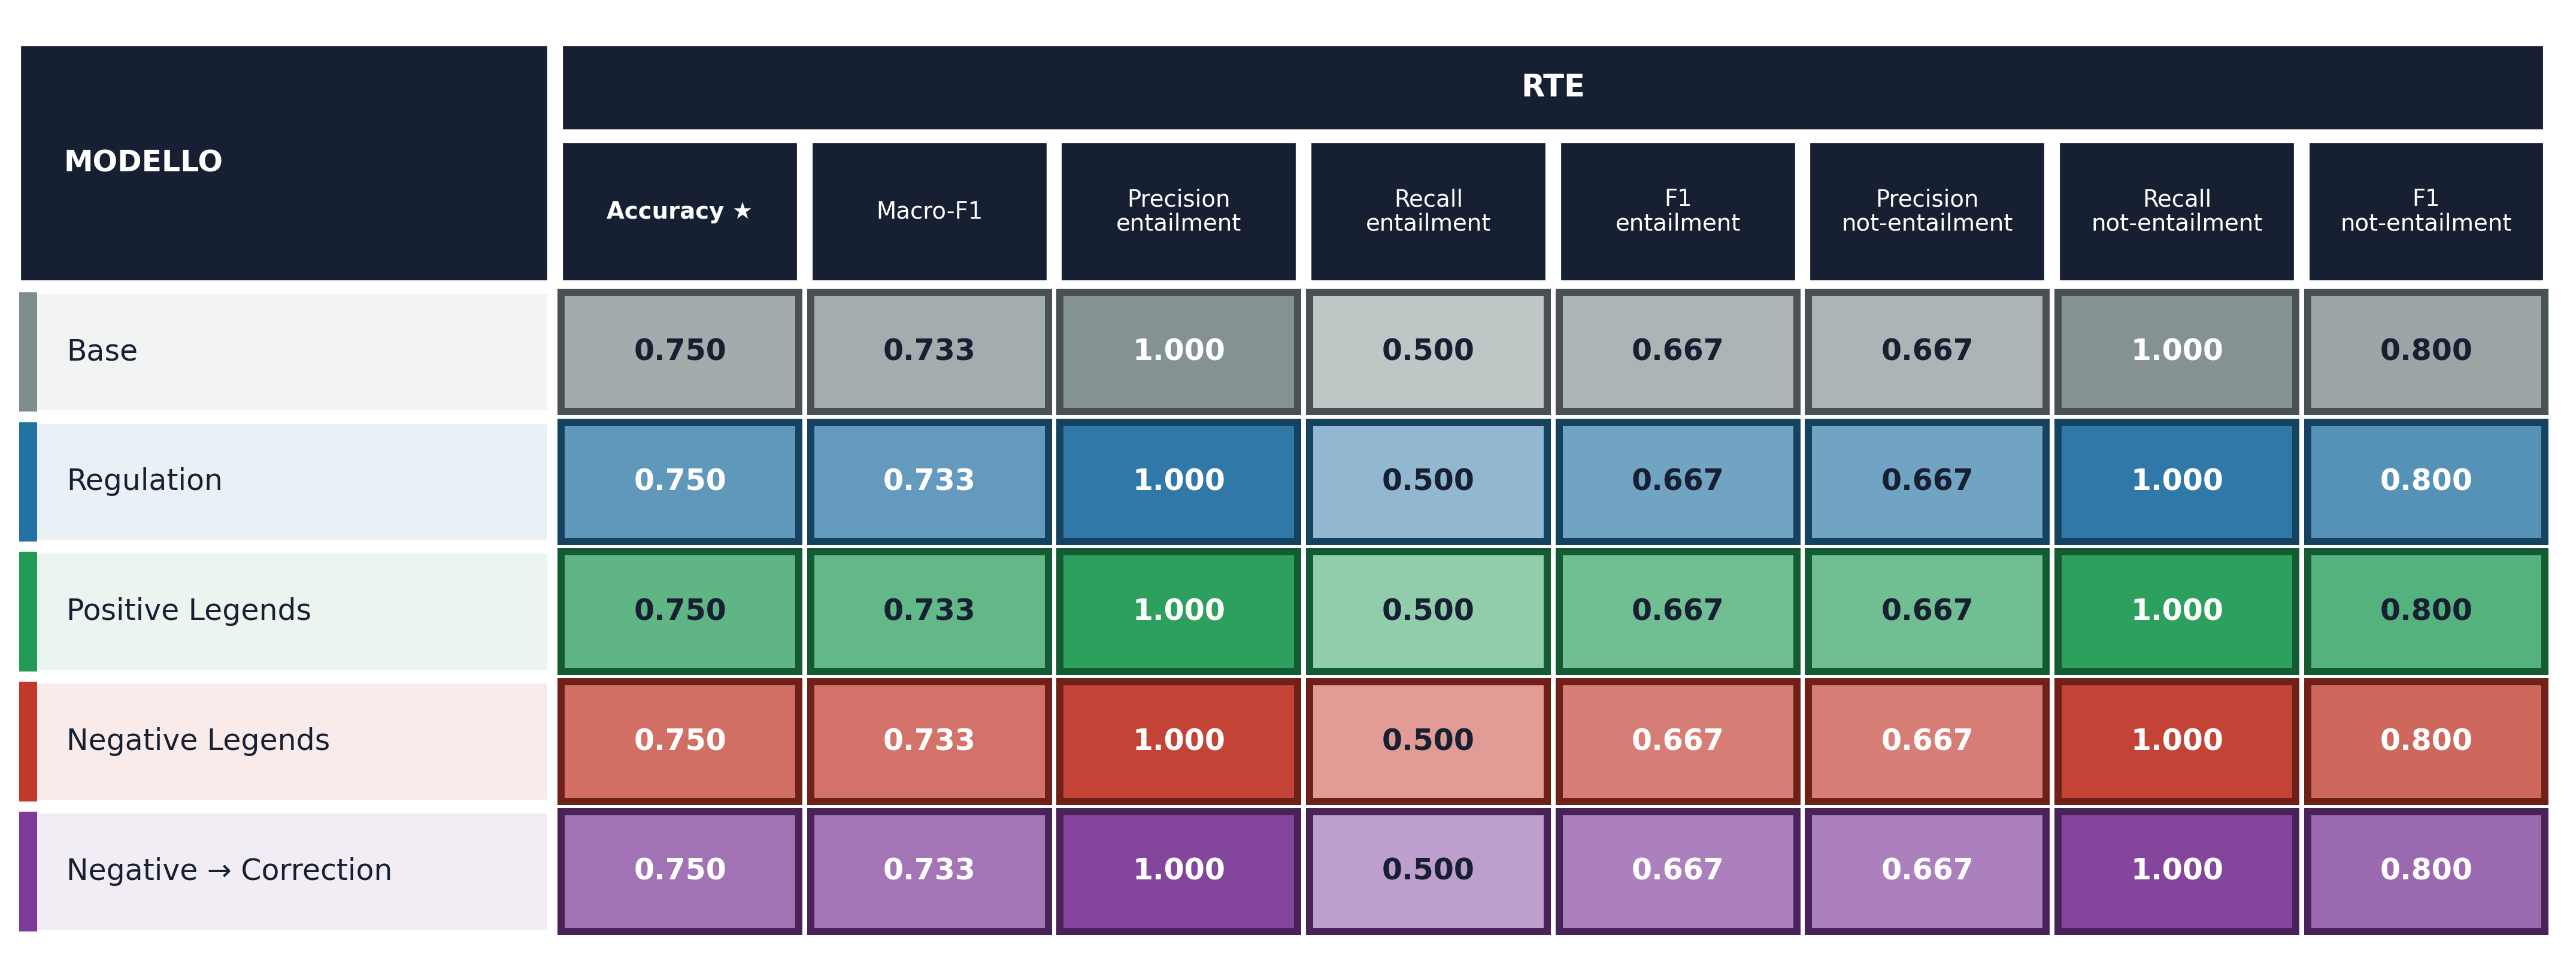

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\rte_style\rte_style_selected_metrics_matrix.png

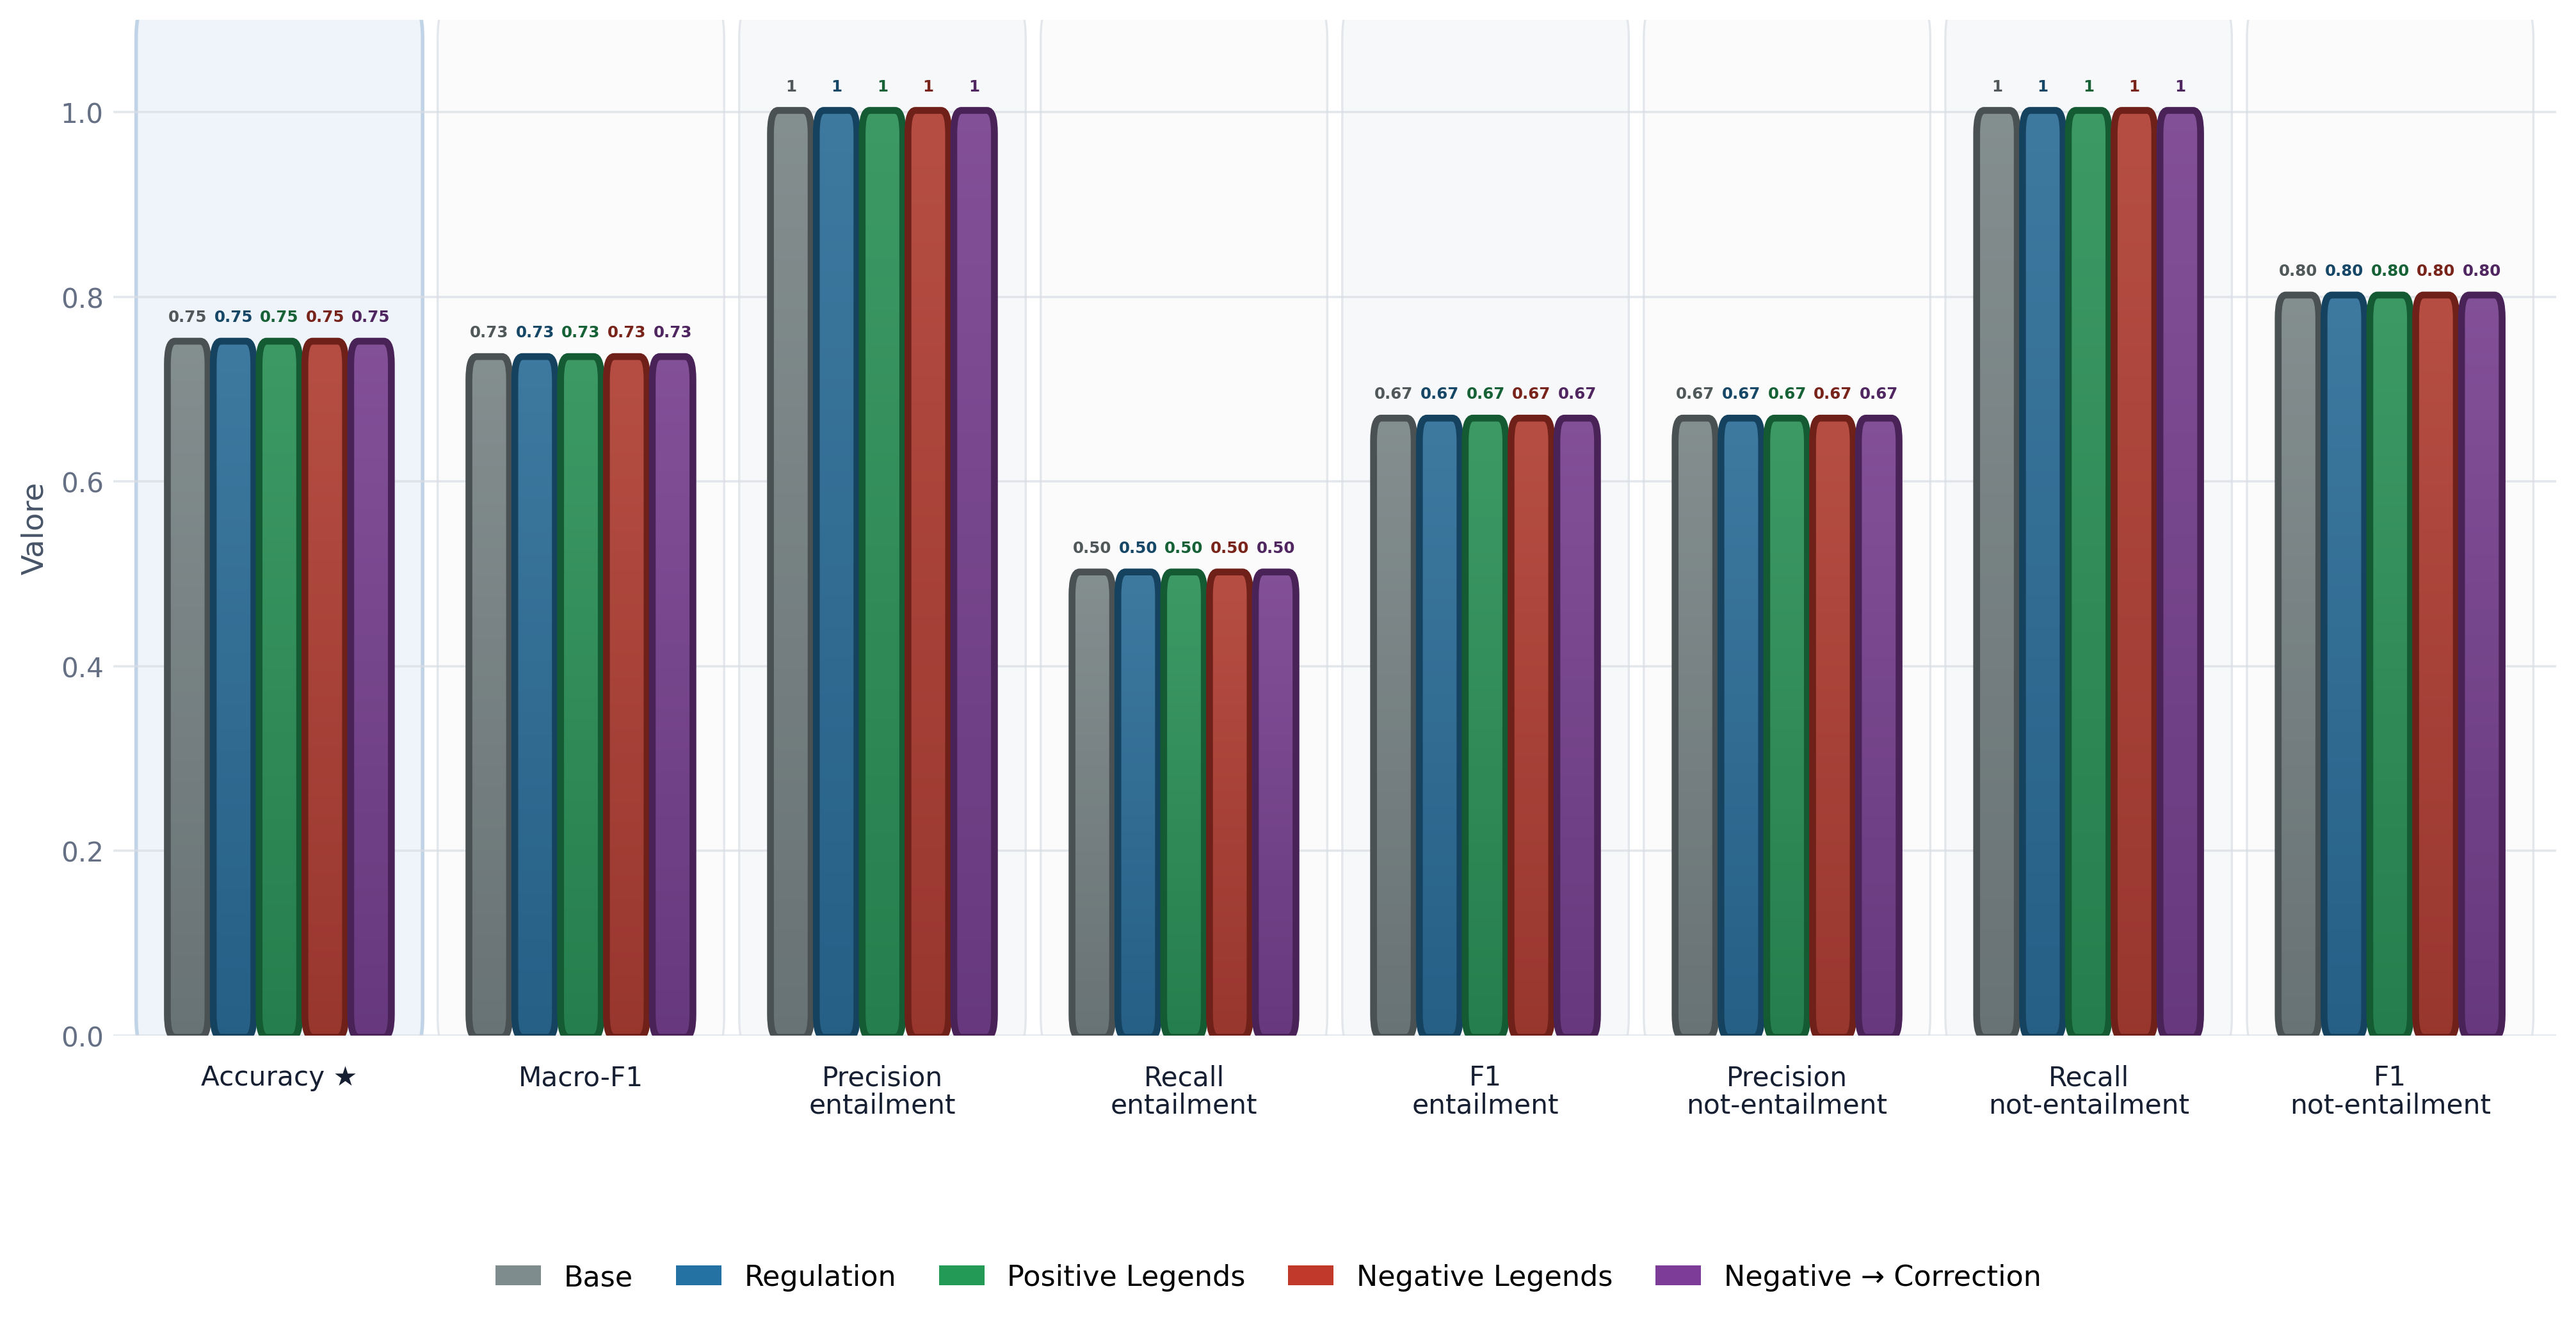

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\rte_style\rte_style_selected_metrics_grouped_bars.png

### Interpretazione per l'esposizione

1. Nel task RTE, Base, Regulation, Positive Legends, Negative Legends, Negative → Correction condividono il miglior primary score, pari a 0.750.

2. Sulle 7 metriche diagnostiche, Base, Regulation, Positive Legends, Negative Legends, Negative → Correction ottiene il maggior numero di risultati al vertice (7), incluse le eventuali parità.


Task: RTE
Metriche mostrate: 8
Matrice PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\rte_style\rte_style_selected_metrics_matrix.png
Istogramma PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\rte_style\rte_style_selected_metrics_grouped_bars.png
CSV: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\tables\rte_style_selected_metrics.csv


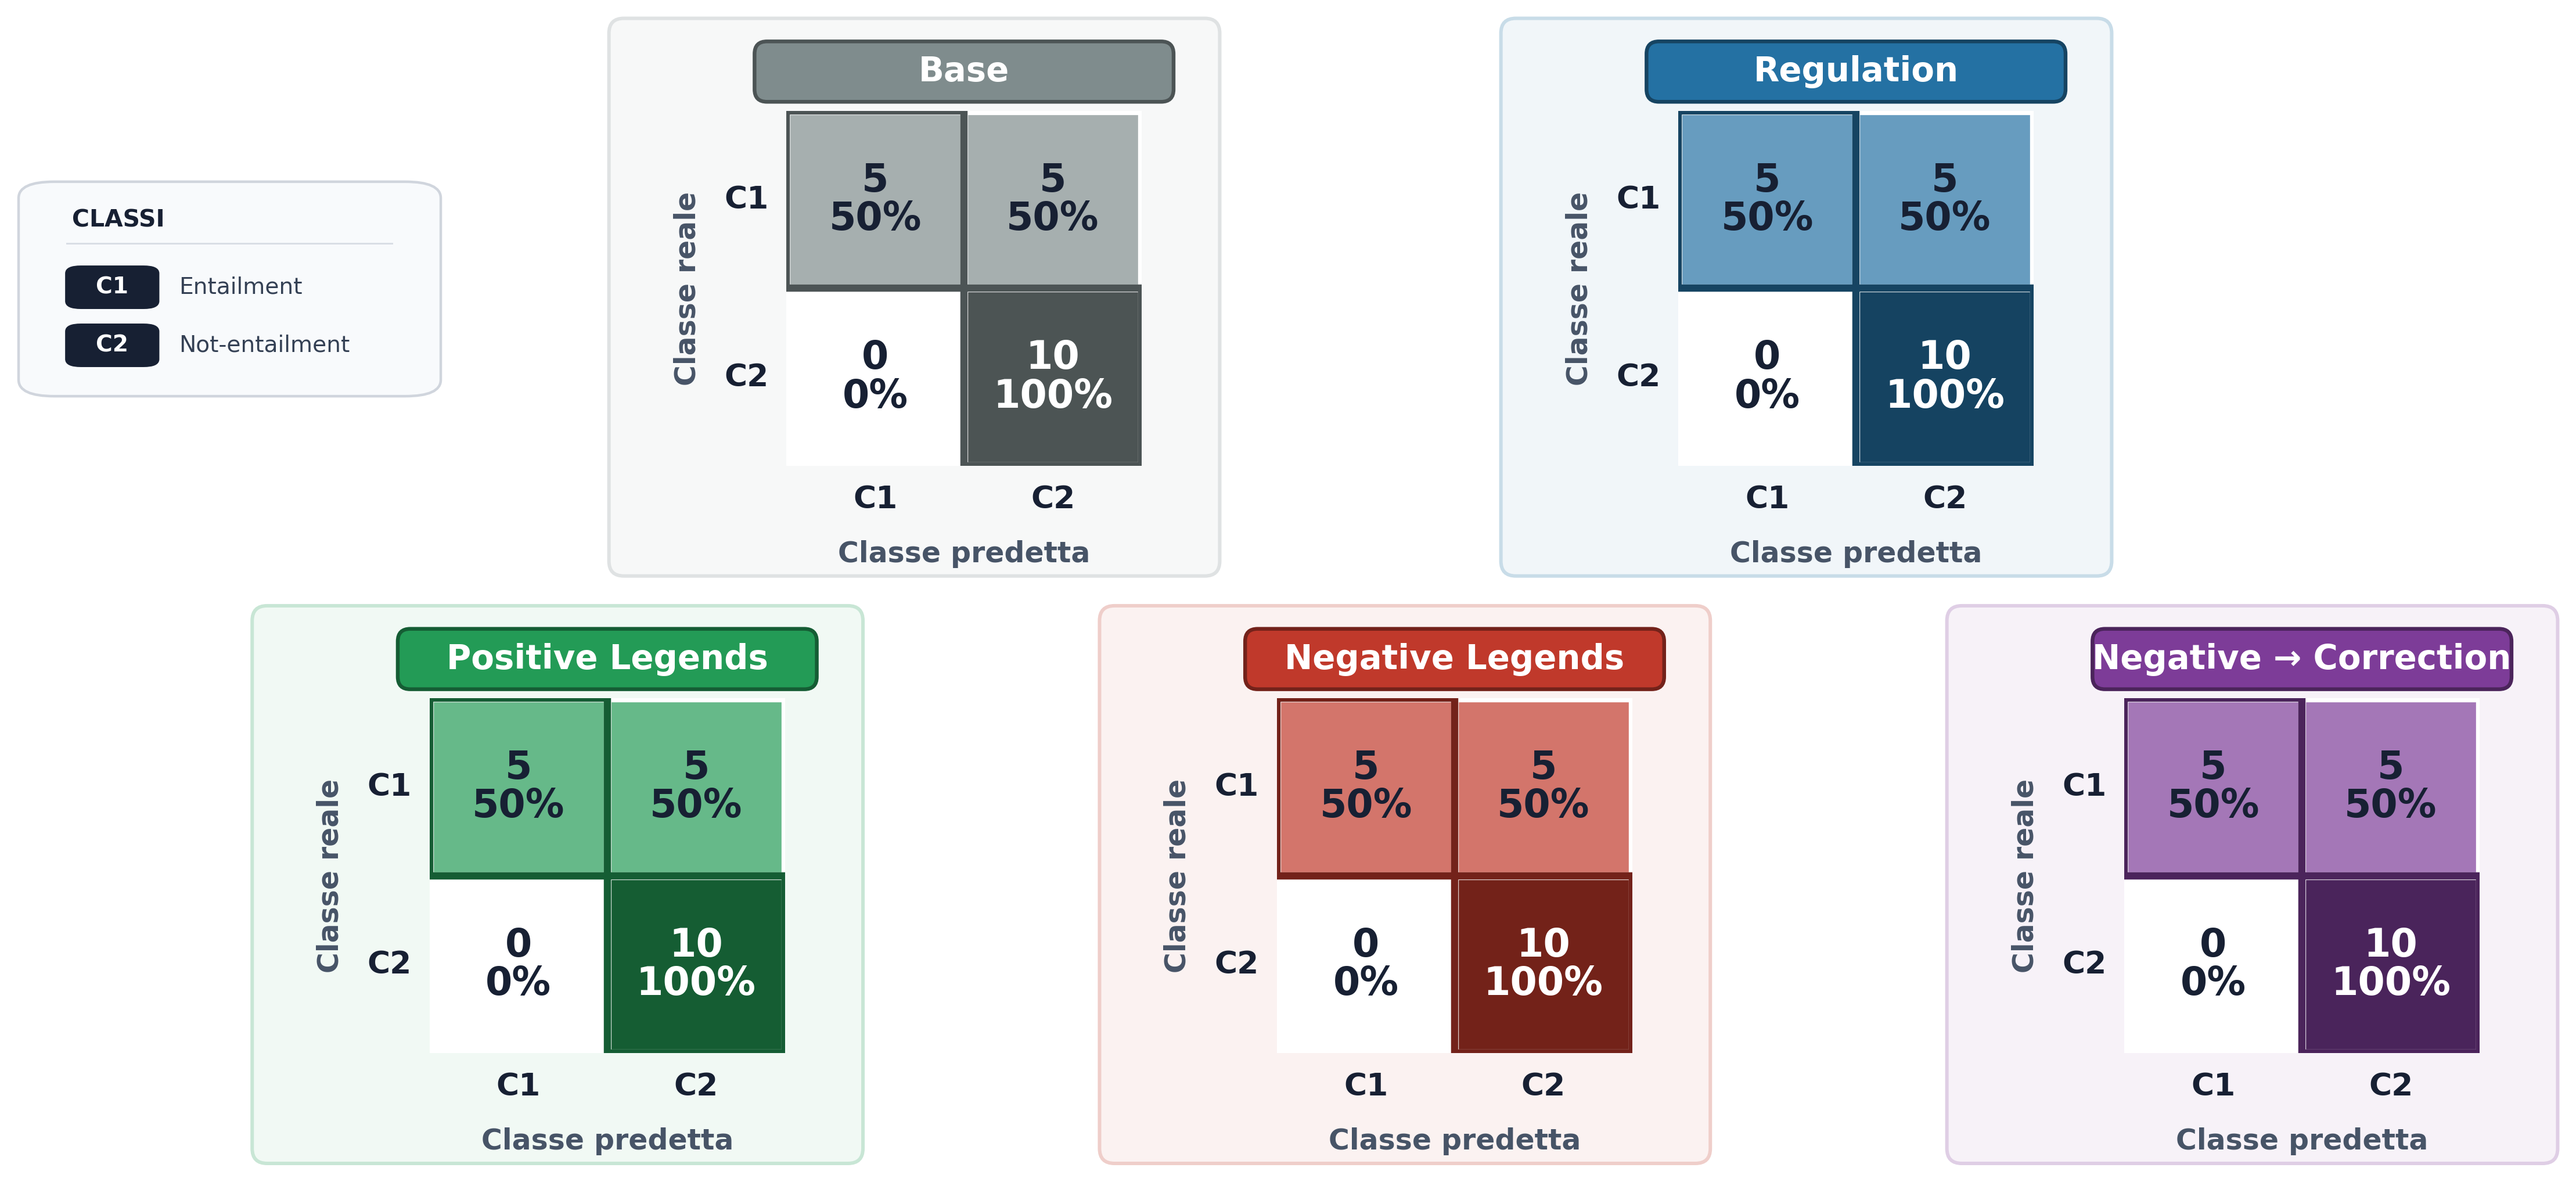

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\rte_style\rte_style_confusion_matrices.png


Confusion matrix generate per: RTE
PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\rte_style\rte_style_confusion_matrices.png
CSV: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\tables\rte_style_confusion_matrices.csv


In [559]:
# CELLA 39 — Genera tutti gli output per RTE:
# - matrice delle metriche;
# - istogramma raggruppato;
# - confusion matrix dei cinque modelli;
# - note interpretative.

rte_outputs = render_complete_task_zoom(
    task_name="rte_style"
)

# 12. Zoom task — Bias Detection

Il task Bias Detection valuta il riconoscimento di contenuti biased e unbiased.

La metrica rappresentativa è il Macro-F1, in modo da attribuire lo stesso peso
alle due classi.

La precision e il recall della classe `biased` sono particolarmente rilevanti:

- una precision bassa indica molti falsi allarmi;
- un recall basso indica numerosi contenuti biased non rilevati.

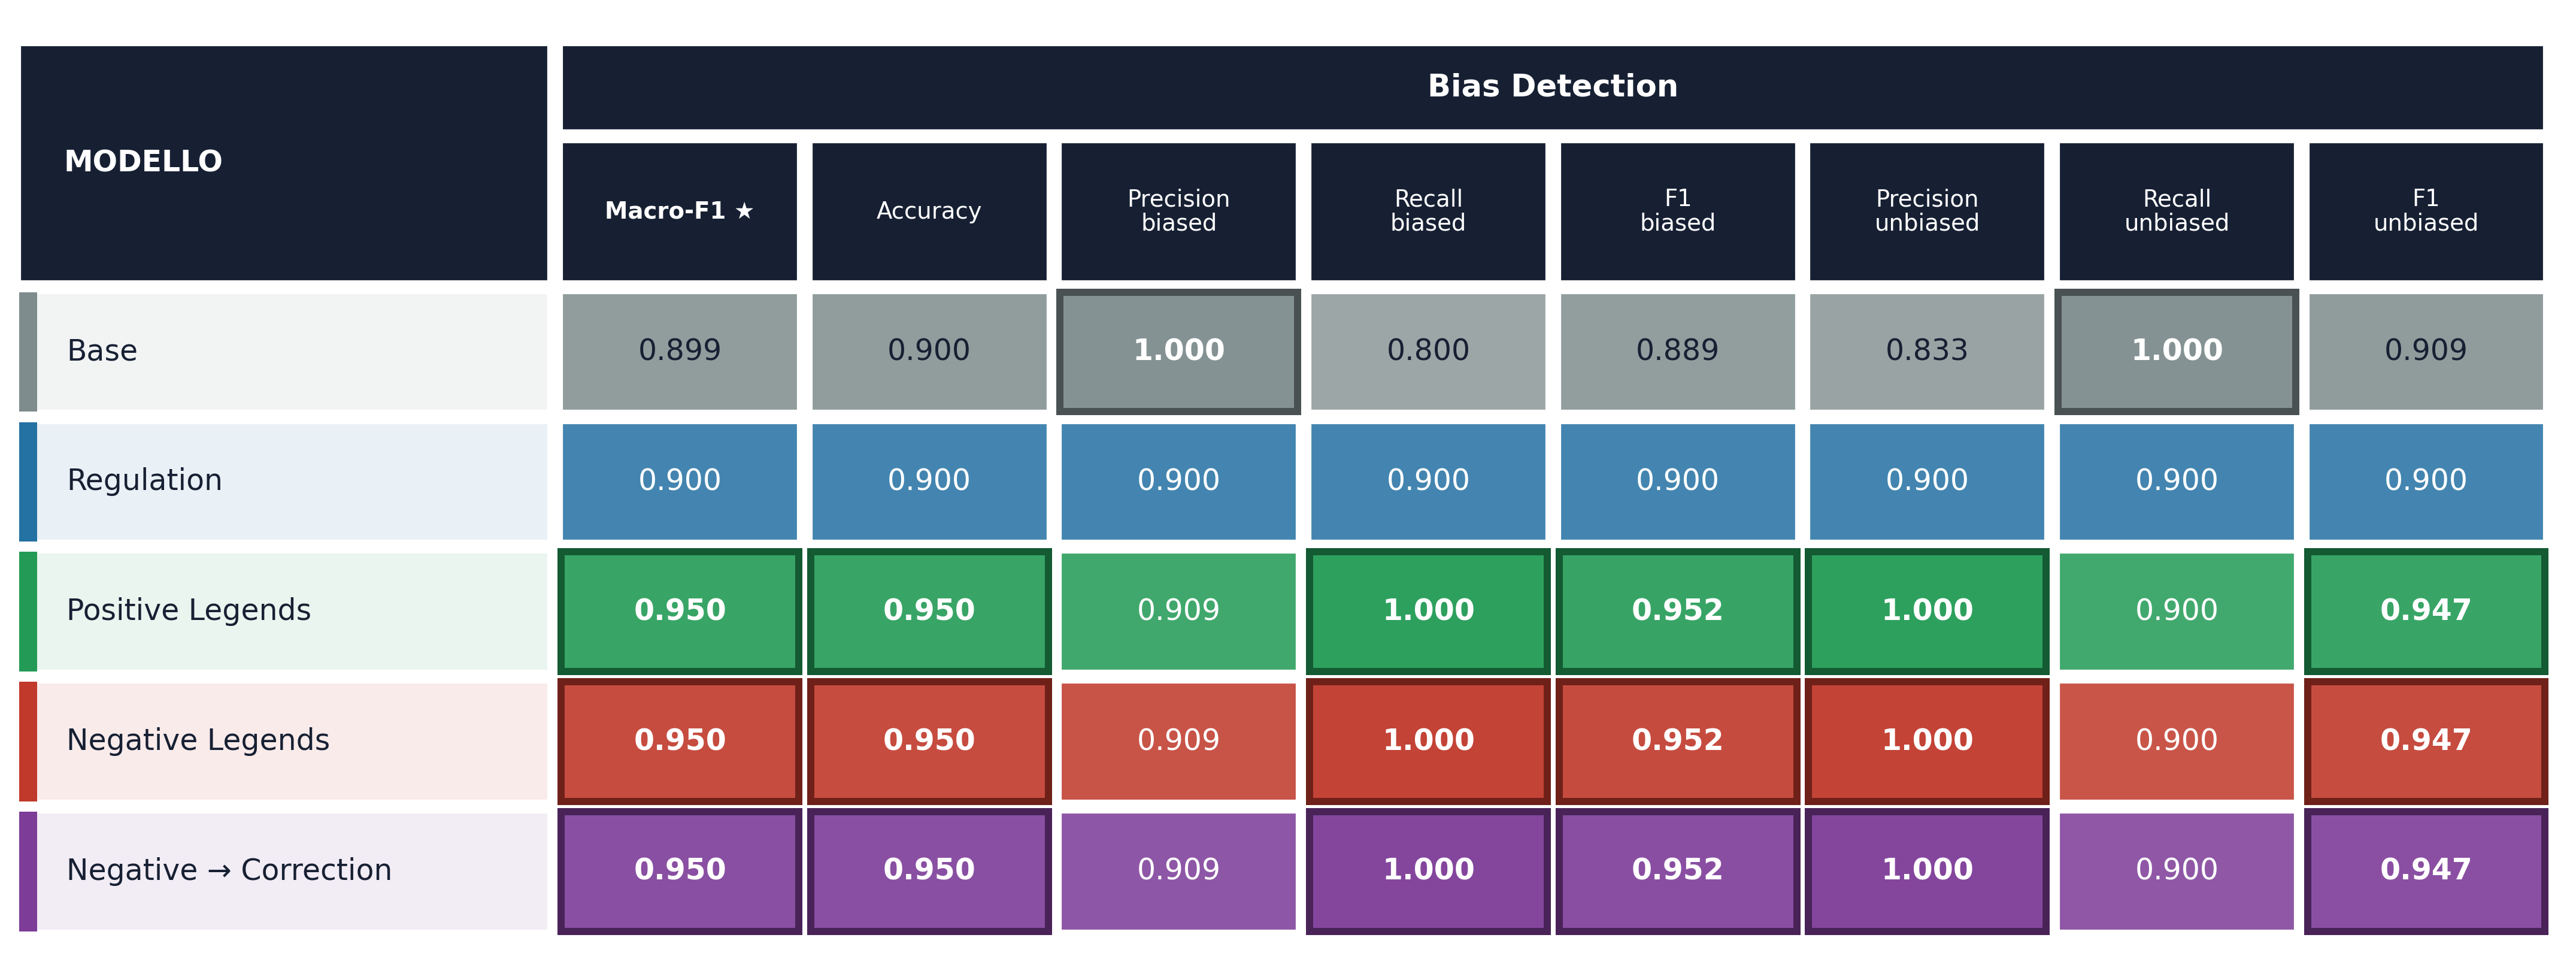

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\bias_detection\bias_detection_selected_metrics_matrix.png

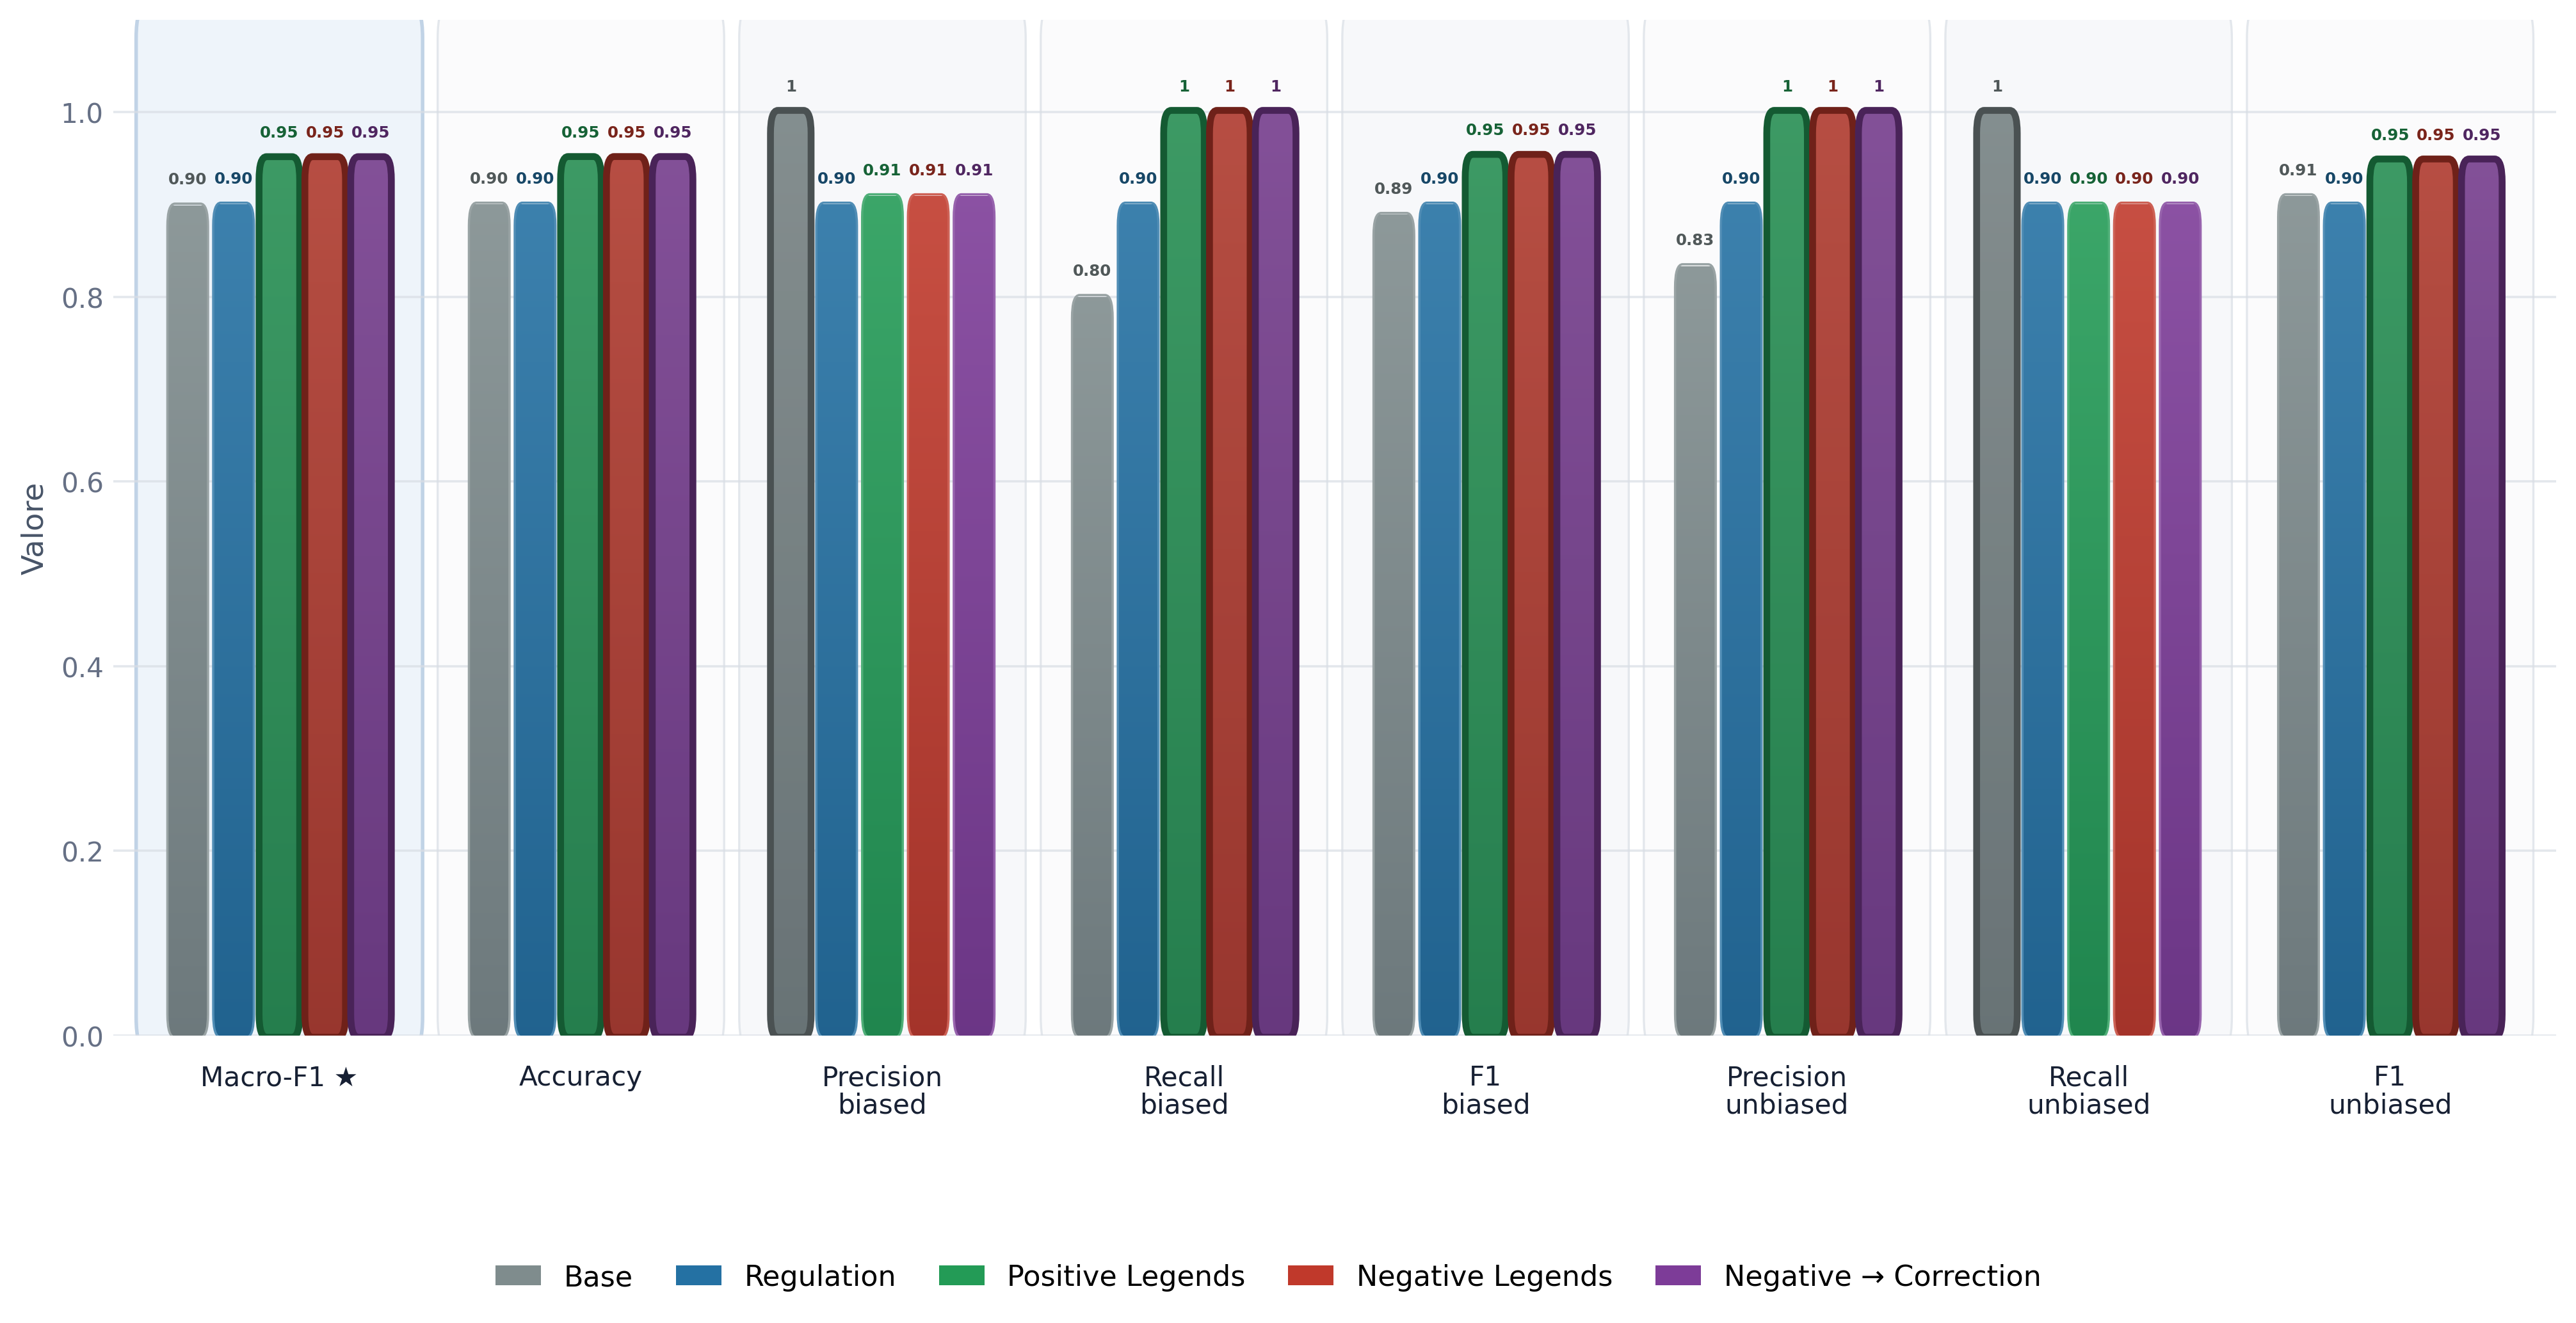

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\bias_detection\bias_detection_selected_metrics_grouped_bars.png

### Interpretazione per l'esposizione

1. Nel task Bias Detection, Positive Legends, Negative Legends, Negative → Correction condividono il miglior primary score, pari a 0.950.

2. Sulle 7 metriche diagnostiche, Positive Legends, Negative Legends, Negative → Correction ottiene il maggior numero di risultati al vertice (5), incluse le eventuali parità.


Task: Bias Detection
Metriche mostrate: 8
Matrice PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\bias_detection\bias_detection_selected_metrics_matrix.png
Istogramma PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\bias_detection\bias_detection_selected_metrics_grouped_bars.png
CSV: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\tables\bias_detection_selected_metrics.csv


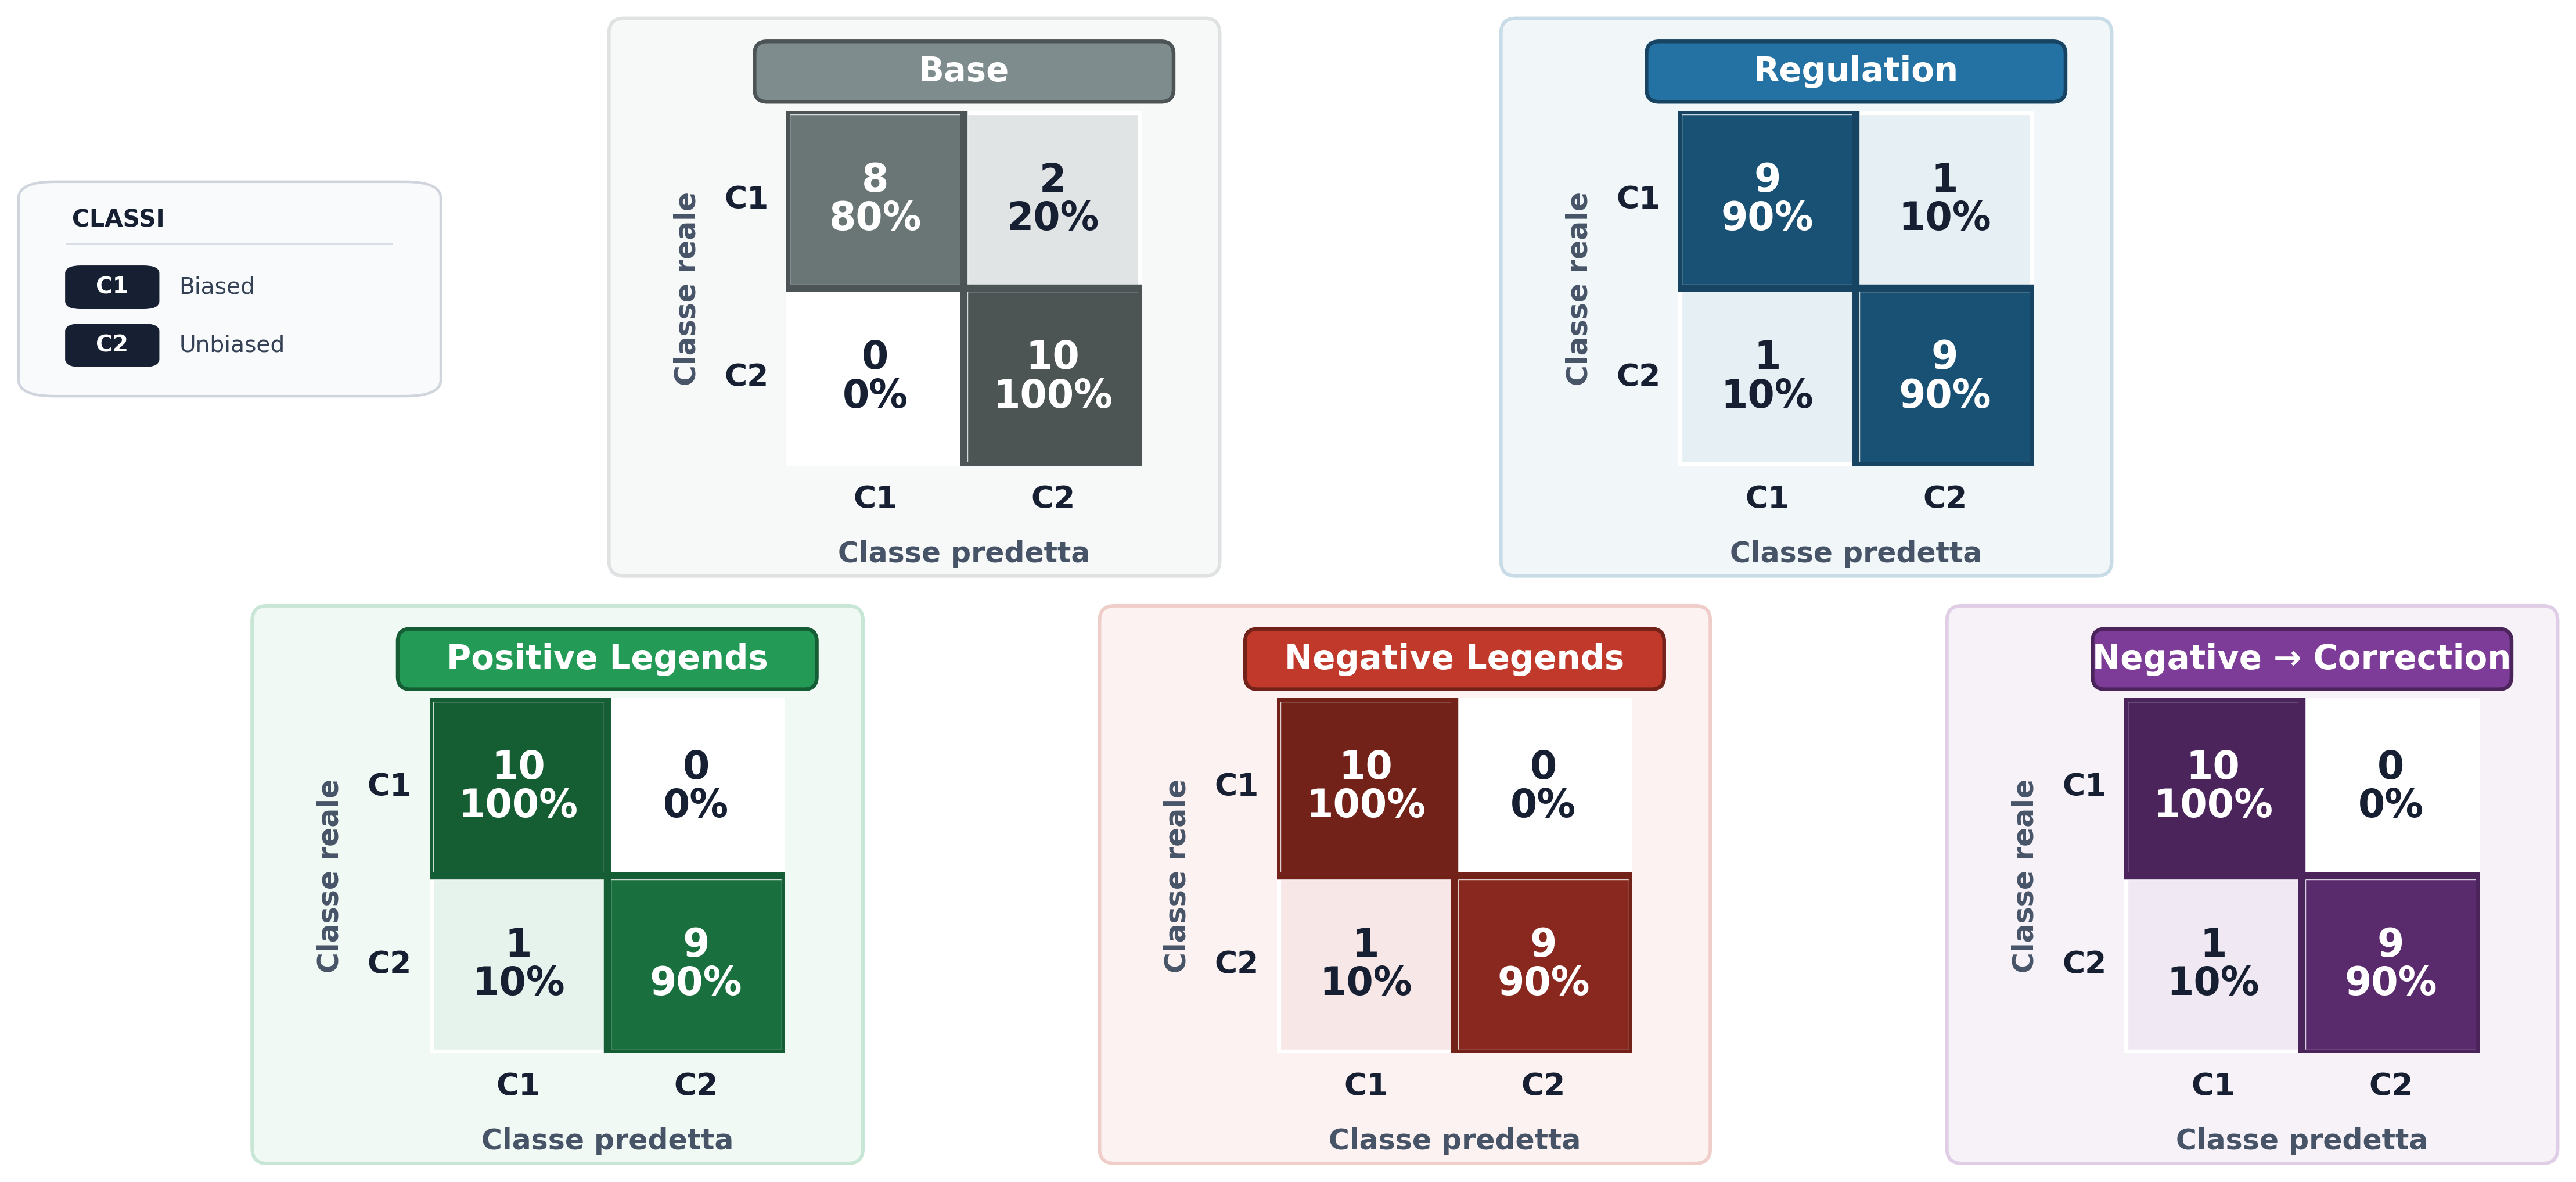

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\bias_detection\bias_detection_confusion_matrices.png


Confusion matrix generate per: Bias Detection
PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\bias_detection\bias_detection_confusion_matrices.png
CSV: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\tables\bias_detection_confusion_matrices.csv


In [560]:
# CELLA 41 — Genera tutti gli output per Bias Detection:
# - matrice delle metriche;
# - istogramma raggruppato;
# - confusion matrix dei cinque modelli;
# - note interpretative.

bias_outputs = render_complete_task_zoom(
    task_name="bias_detection"
)

# 13. Zoom task — STS-B

STS-B valuta la capacità del modello di assegnare un livello di similarità
compreso tra 0 e 5.

La metrica rappresentativa è la media tra Pearson e Spearman.

L'analisi deve mantenere separate:

- le metriche di correlazione, in cui valori maggiori sono migliori;
- MAE e RMSE, in cui valori minori sono migliori;
- l'errore medio firmato, in cui è preferibile un valore vicino allo zero;
- le misure di accuratezza entro una determinata distanza dalla reference.

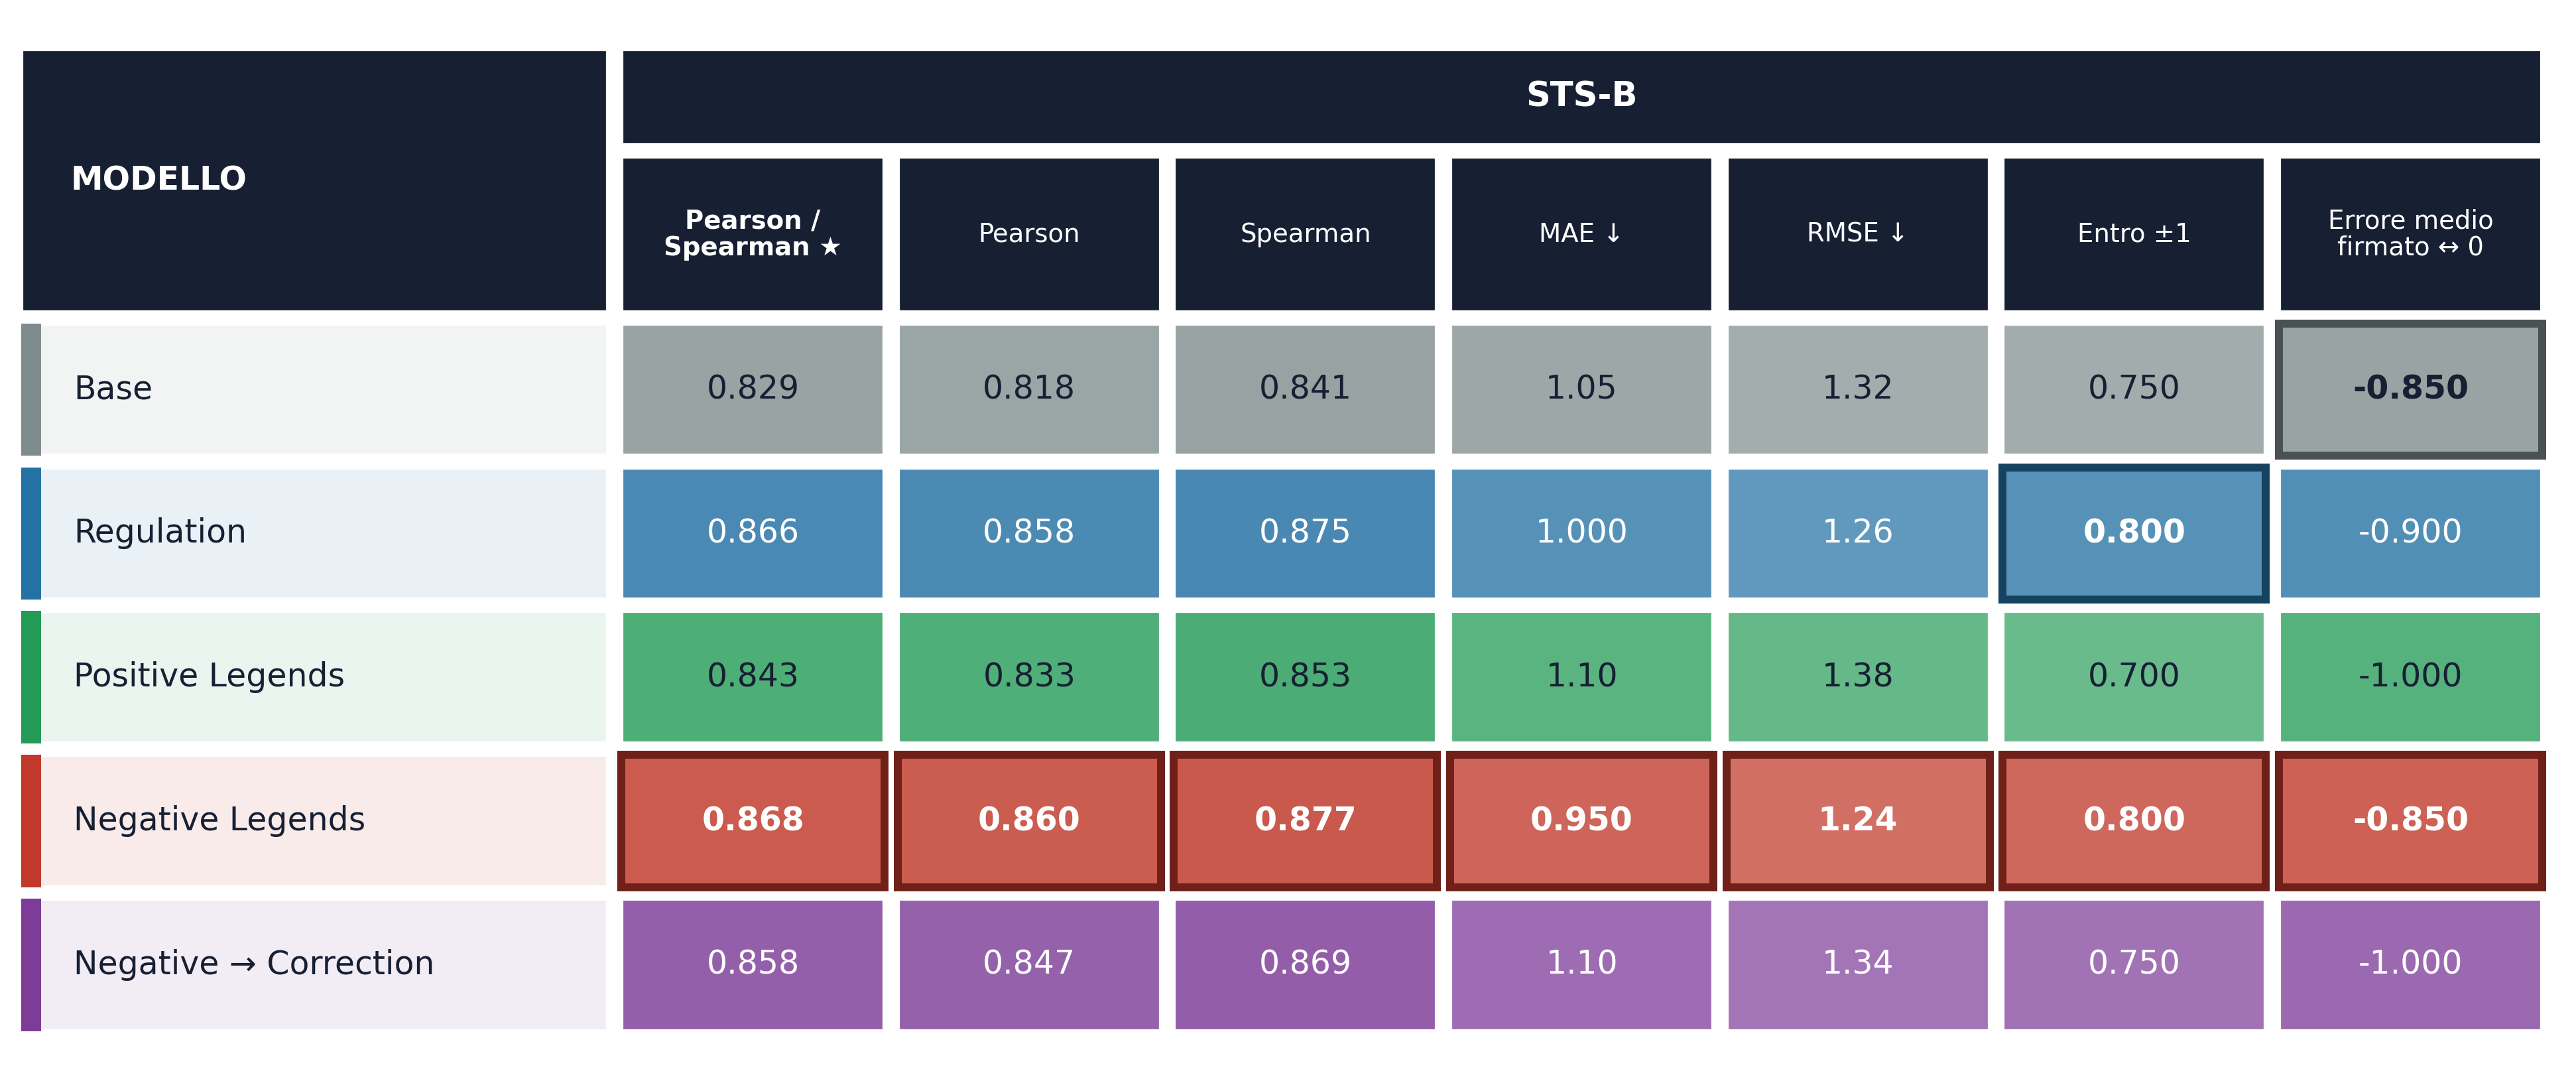

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\stsb_style\stsb_style_selected_metrics_matrix.png

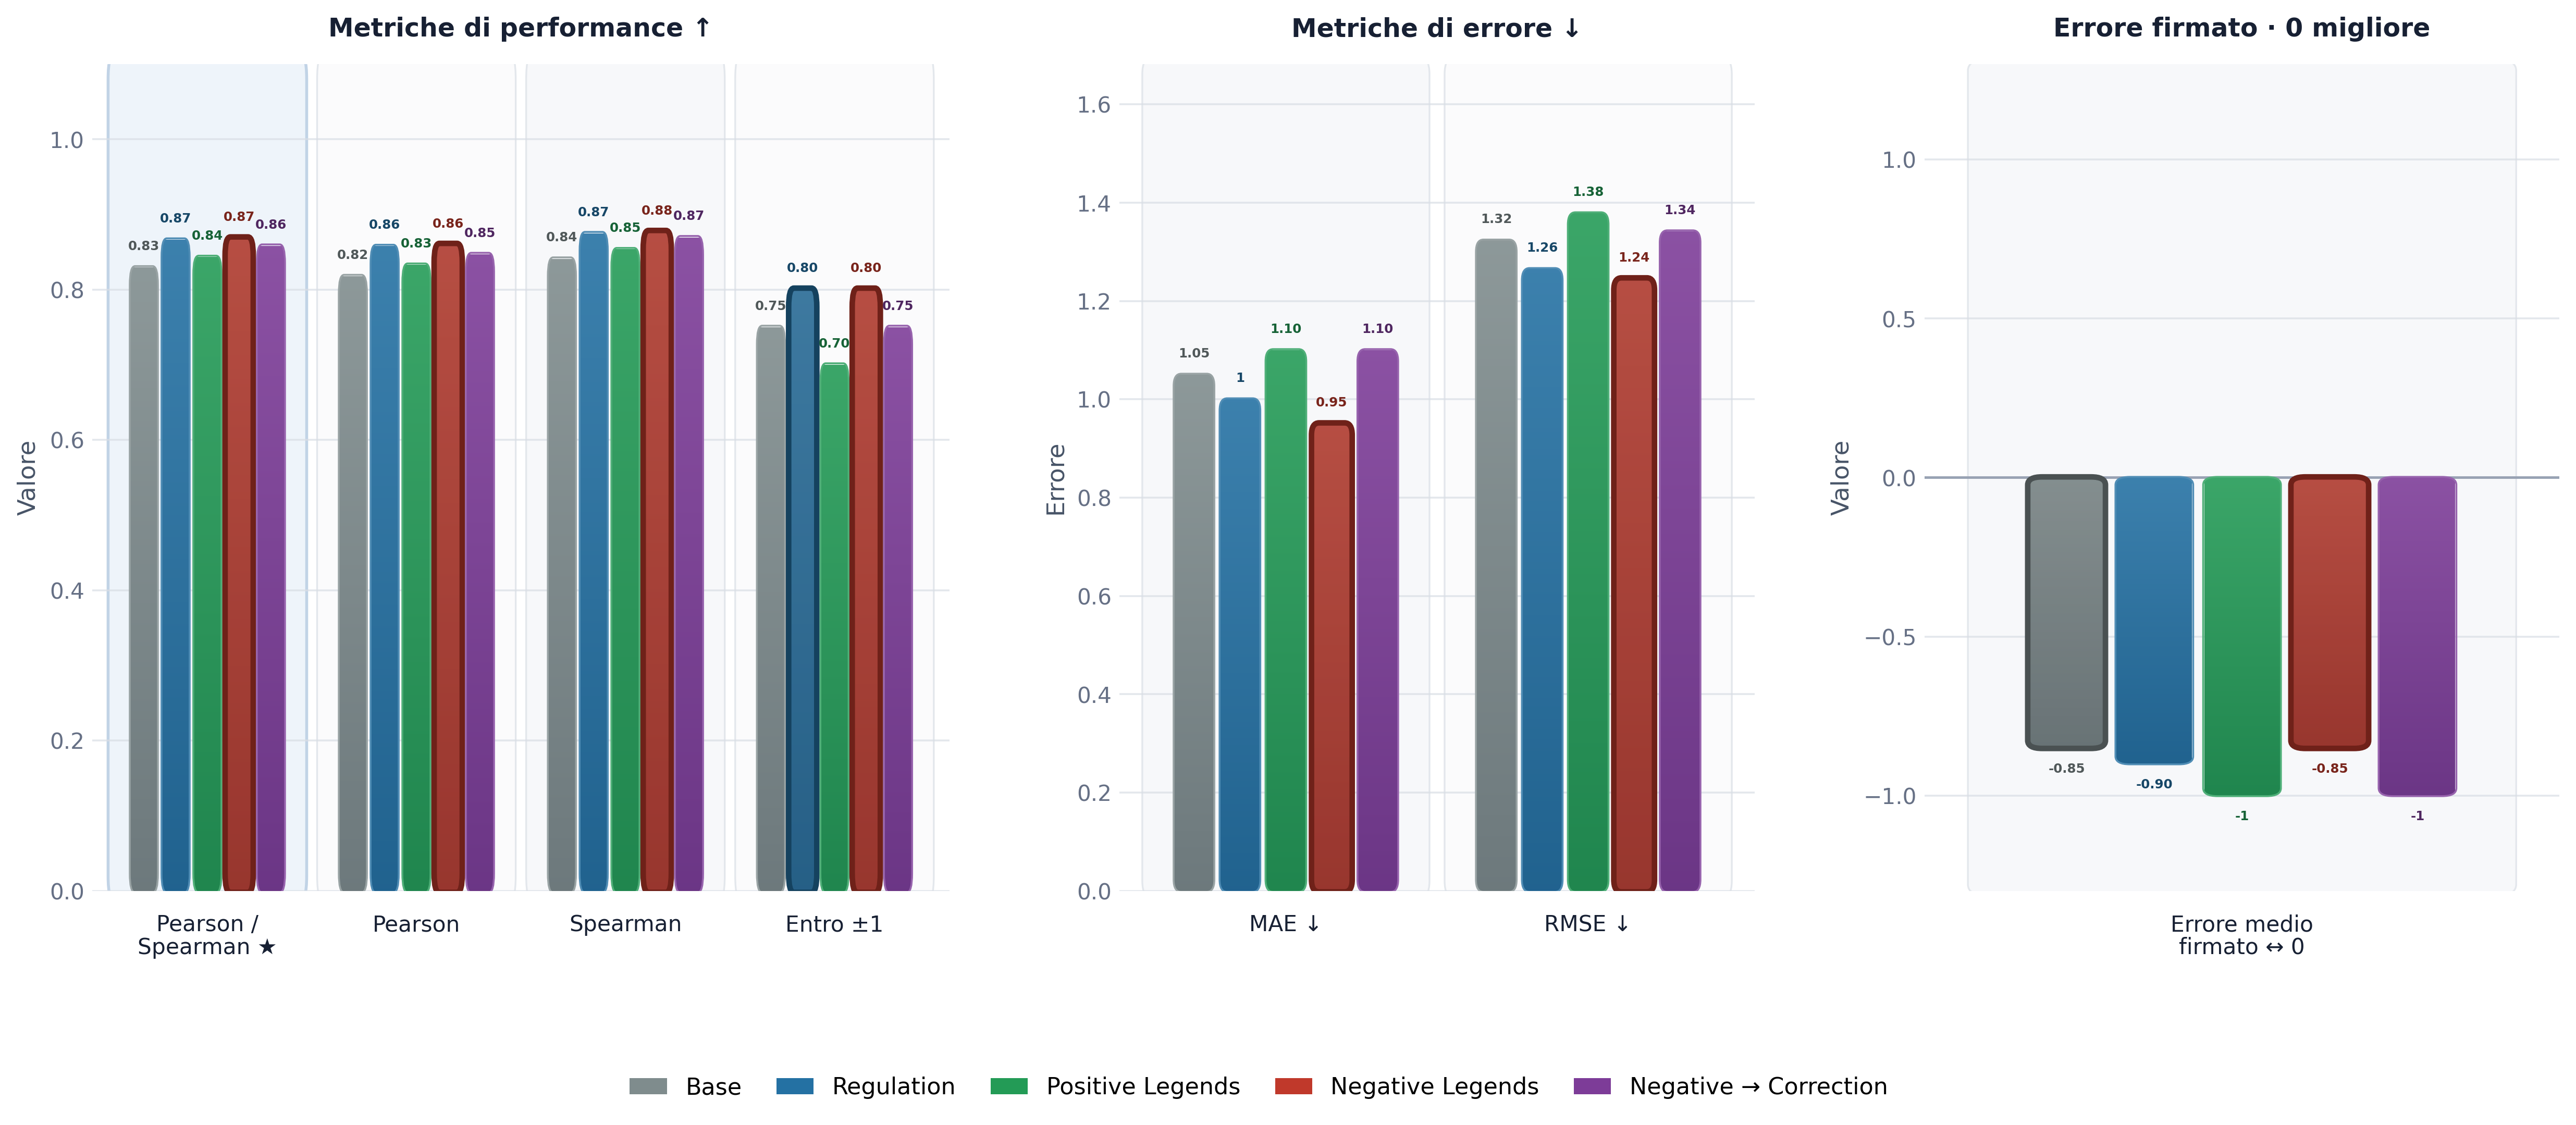

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\stsb_style\stsb_style_selected_metrics_grouped_bars.png

### Interpretazione per l'esposizione

1. Nel task STS-B, Negative Legends ottiene il miglior primary score (0.868), con un vantaggio di 0.002 su Regulation.

2. Sulle 6 metriche diagnostiche, Negative Legends ottiene il maggior numero di risultati al vertice (6), incluse le eventuali parità.


Task: STS-B
Metriche mostrate: 7
Matrice PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\stsb_style\stsb_style_selected_metrics_matrix.png
Istogramma PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\stsb_style\stsb_style_selected_metrics_grouped_bars.png
CSV: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\tables\stsb_style_selected_metrics.csv


In [561]:
# CELLA 43 — Genera matrice, istogramma e note per STS-B.
#
# Le metriche incompatibili vengono automaticamente
# separate in pannelli distinti.

stsb_outputs = render_task_zoom_assets(
    task_name="stsb_style"
)

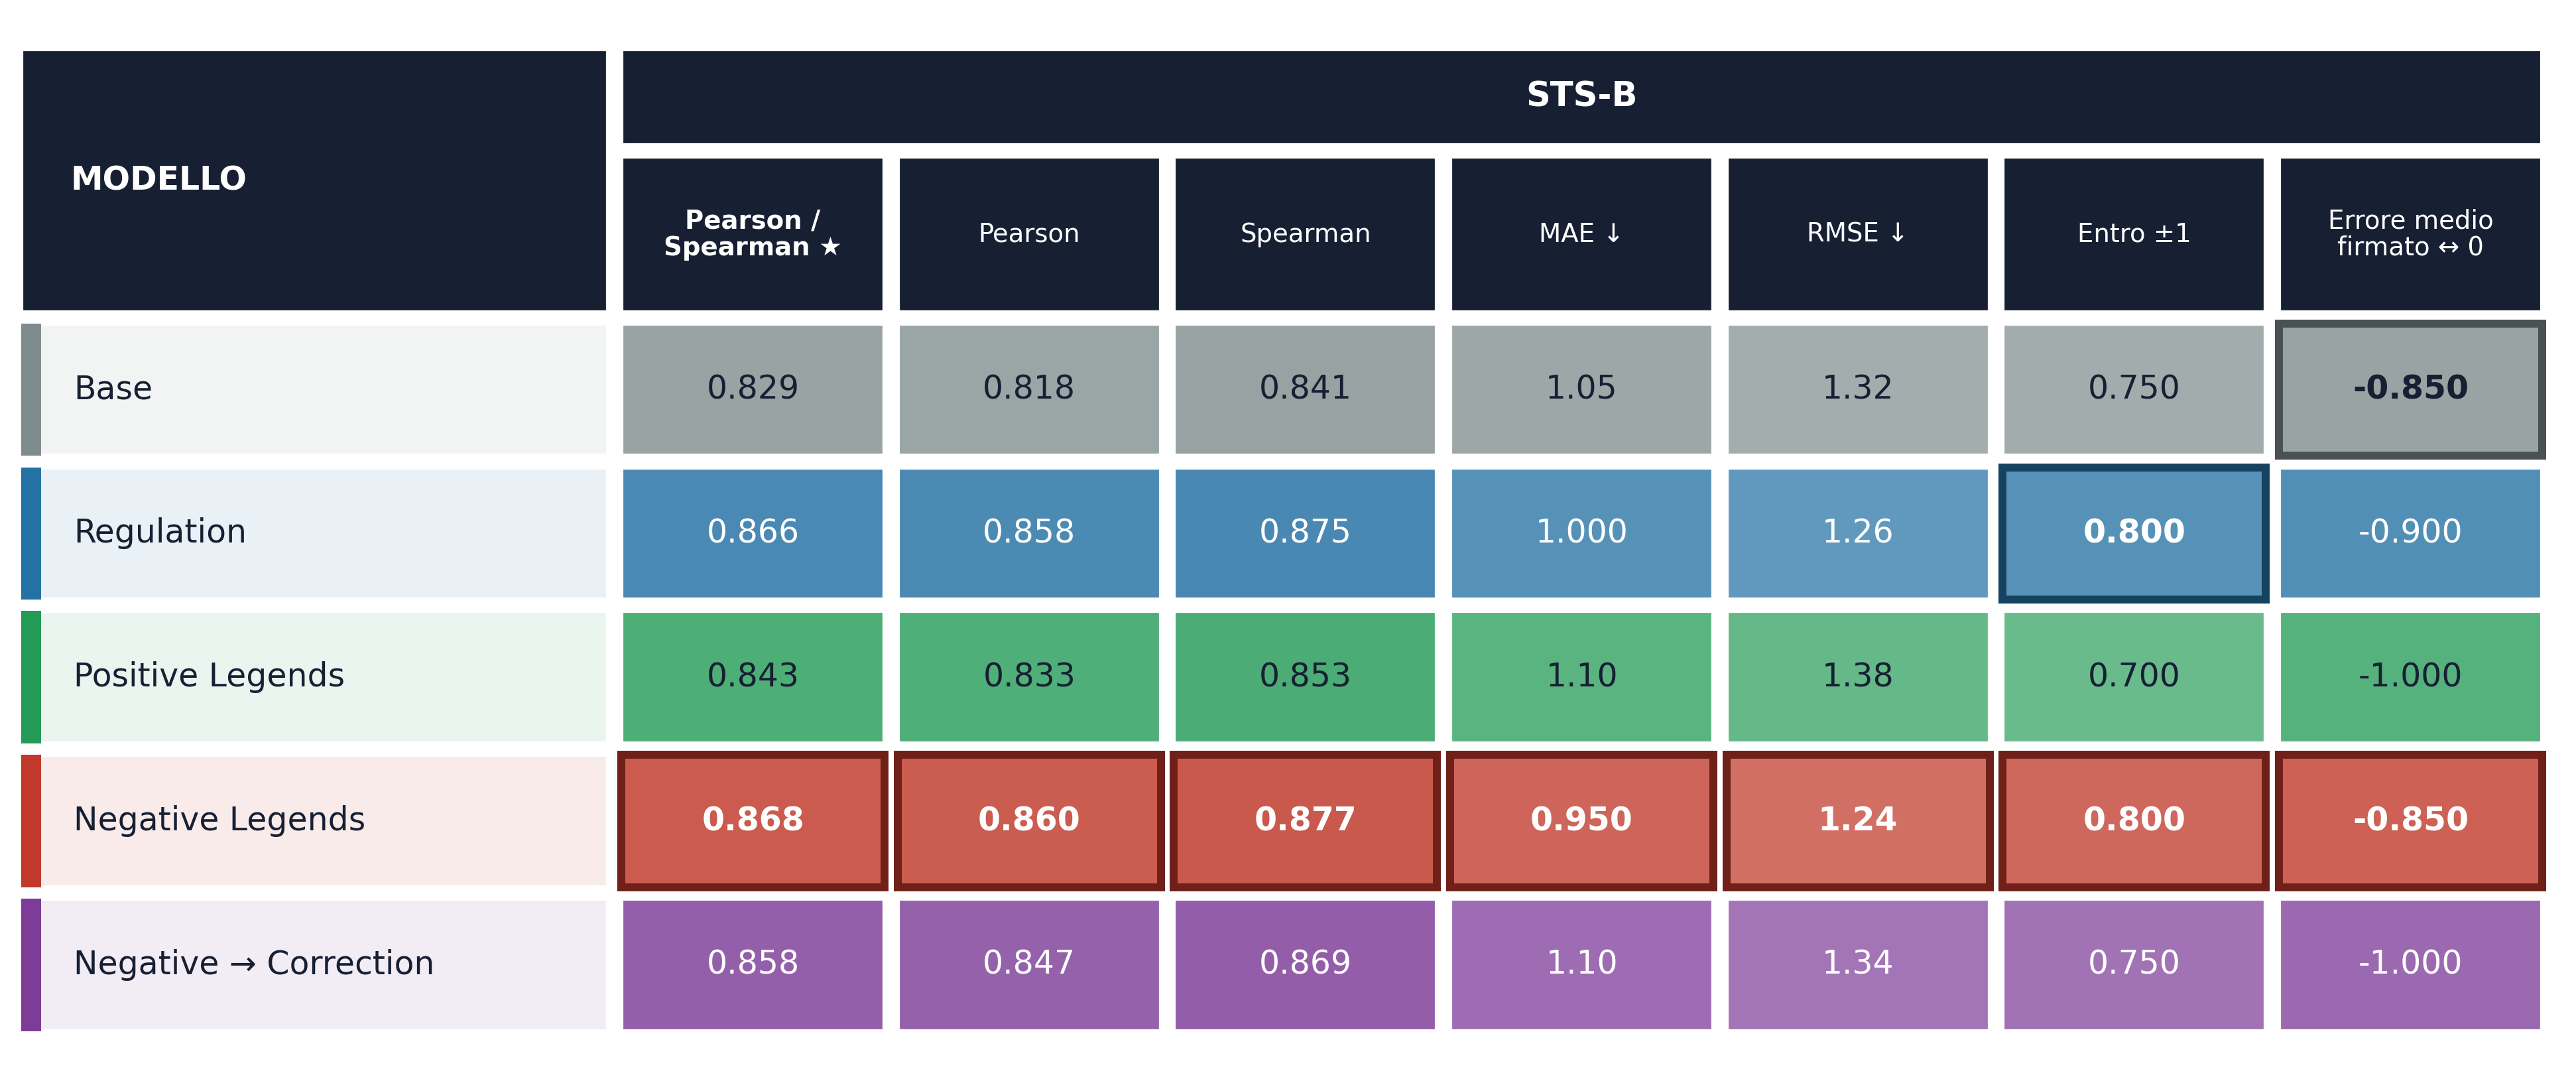

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\stsb_style\stsb_style_selected_metrics_matrix.png

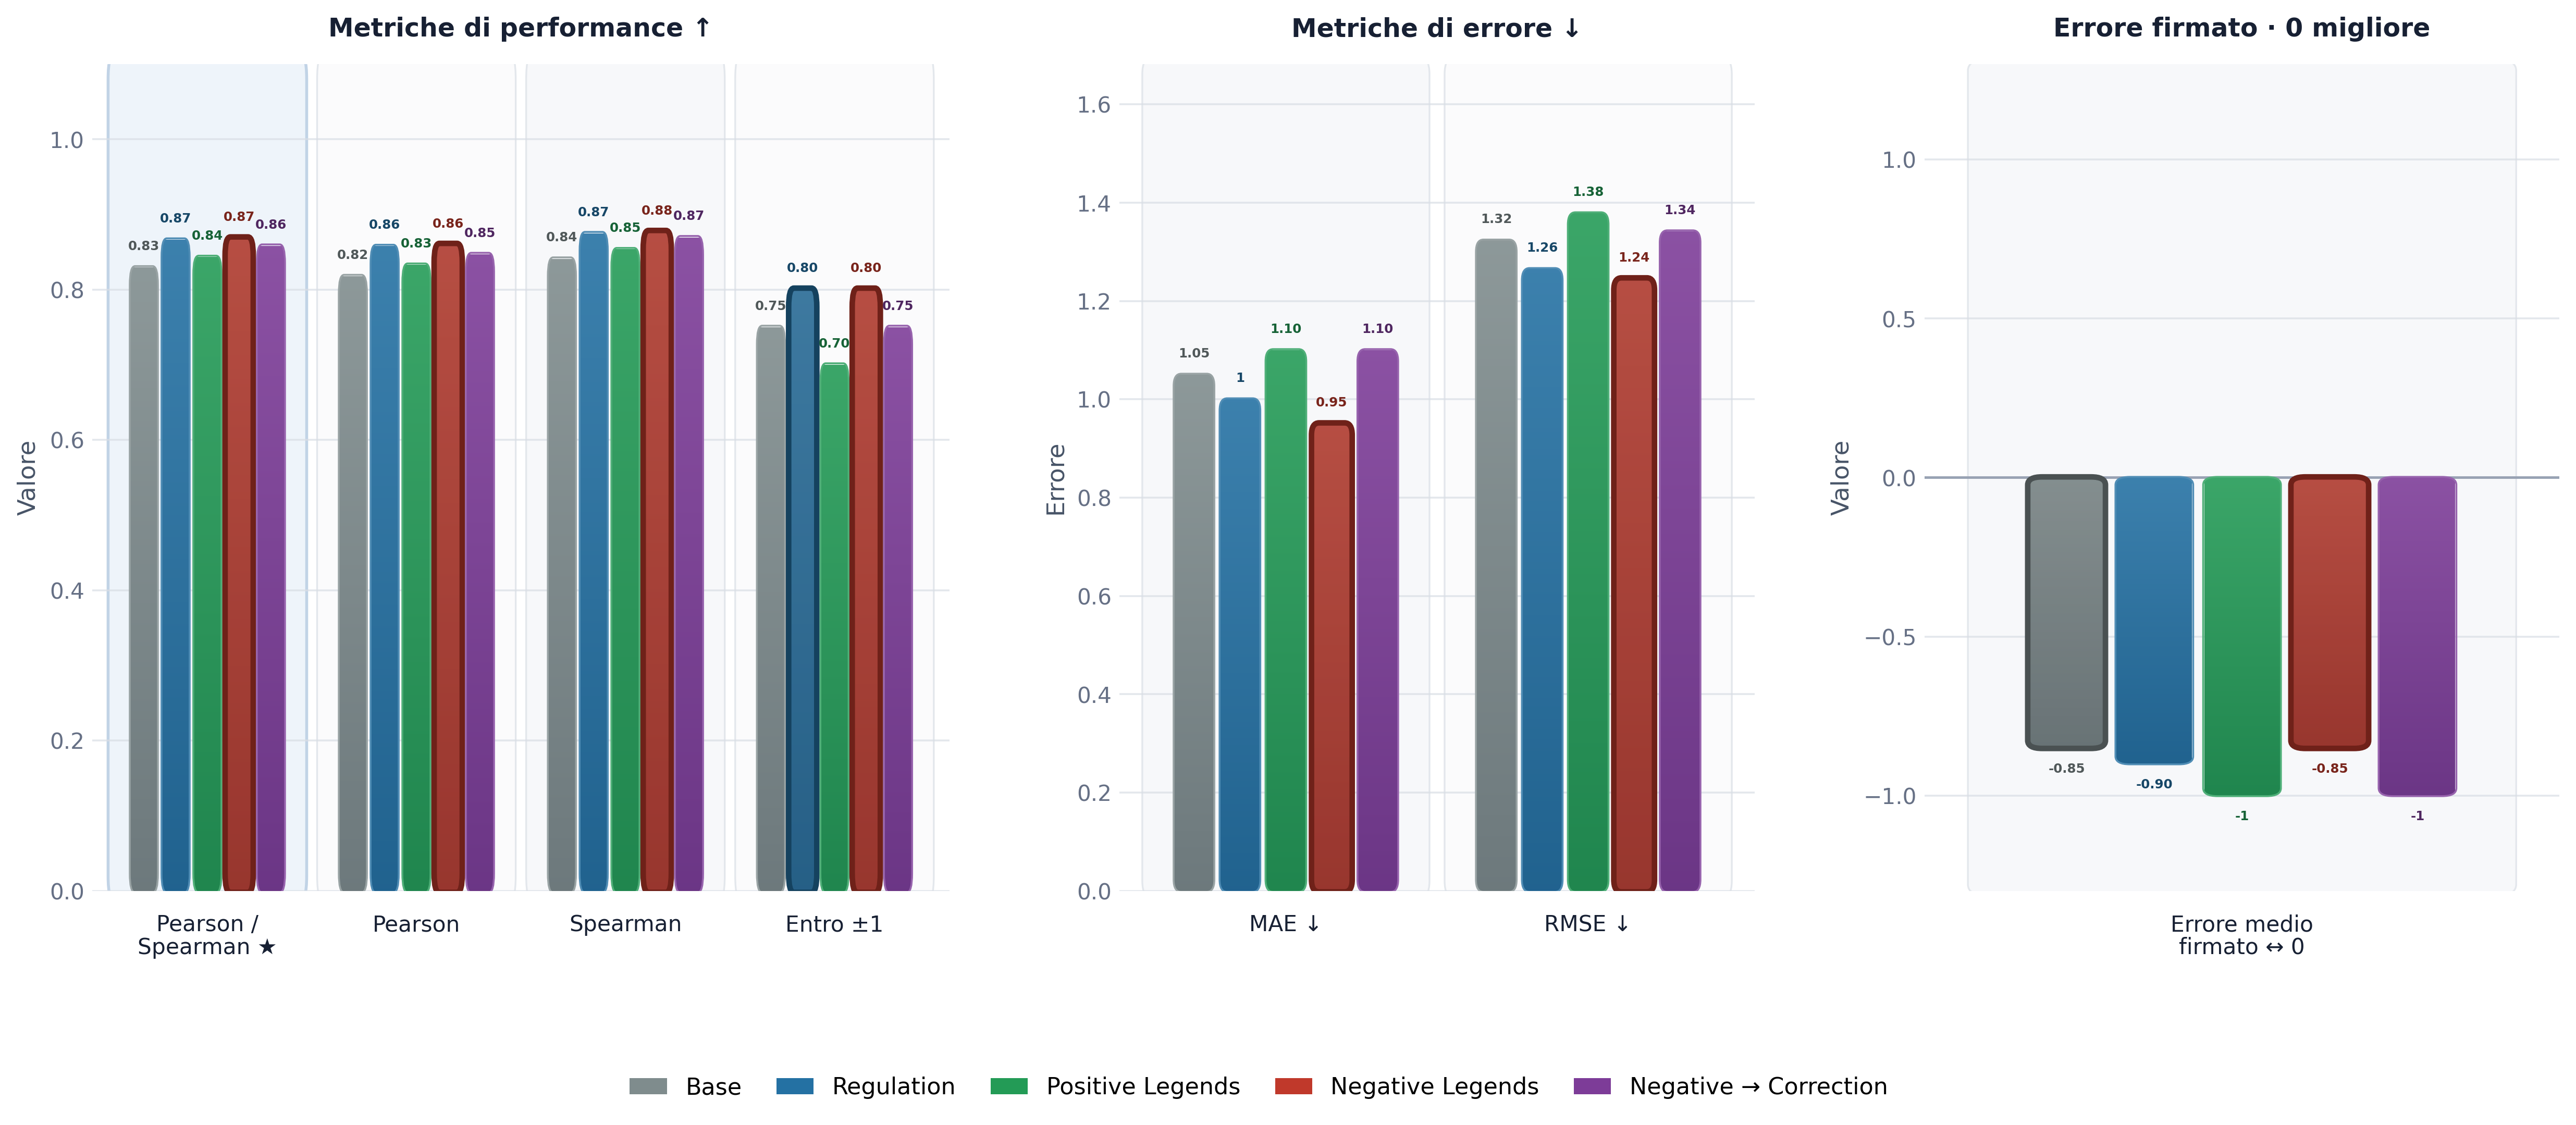

C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\stsb_style\stsb_style_selected_metrics_grouped_bars.png

### Interpretazione per l'esposizione

1. Nel task STS-B, Negative Legends ottiene il miglior primary score (0.868), con un vantaggio di 0.002 su Regulation.

2. Sulle 6 metriche diagnostiche, Negative Legends ottiene il maggior numero di risultati al vertice (6), incluse le eventuali parità.


Task: STS-B
Metriche mostrate: 7
Matrice PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\stsb_style\stsb_style_selected_metrics_matrix.png
Istogramma PNG: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\plots\task_zooms\stsb_style\stsb_style_selected_metrics_grouped_bars.png
CSV: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\tables\stsb_style_selected_metrics.csv

Confusion matrix non applicabile a: STS-B


In [562]:
# CELLA 43 — Genera tutti gli output per STS-B:
# - matrice delle metriche;
# - visualizzazioni delle metriche numeriche;
# - note interpretative.
#
# Non viene generata una confusion matrix,
# perché STS-B è un task di regressione/correlazione.

stsb_outputs = render_complete_task_zoom(
    task_name="stsb_style"
)

# 14. Note sintetiche per l'esposizione

Questa sezione raccoglie in un'unica tabella le due frasi generate per:

- panoramica iniziale;
- ranking;
- ciascun task approfondito.

Le frasi sono costruite direttamente dai risultati numerici.

Devono essere considerate una base per l'esposizione e non un'interpretazione
scientifica definitiva: prima della presentazione sarà opportuno verificare
manualmente che i trade-off individuati siano coerenti con la natura del task.

In [563]:
# CELLA 45 — Raccoglie tutte le note per la presentazione
# e le salva in formato CSV e JSON.

presentation_notes_df = pd.DataFrame(
    PRESENTATION_NOTES
)


presentation_notes_csv_path = (
    BLOCK_1_TABLES_DIR
    / "presentation_notes_block_1.csv"
)


presentation_notes_json_path = (
    BLOCK_1_TABLES_DIR
    / "presentation_notes_block_1.json"
)


presentation_notes_df.to_csv(
    presentation_notes_csv_path,
    index=False,
    encoding="utf-8-sig",
)


with presentation_notes_json_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        PRESENTATION_NOTES,
        file,
        ensure_ascii=False,
        indent=2,
    )


display(
    presentation_notes_df
)


print(
    "Note CSV:",
    presentation_notes_csv_path,
)

print(
    "Note JSON:",
    presentation_notes_json_path,
)

,section,line_1,line_2
0,Slide 1 — Panoramica complessiva,Positive Legends registra il maggior numero di...,I risultati migliori si concentrano soprattutt...
1,Slide 2 — Ranking complessivo,Positive Legends occupa il primo posto con 31....,Il modello vincitore ottiene 5 primi posti e 7...
2,Task — SST-2,"Nel task SST-2, Negative → Correction ottiene ...","Sulle 7 metriche diagnostiche, Negative → Corr..."
3,Task — Paraphrase,"Nel task Paraphrase, Positive Legends, Negativ...","Sulle 7 metriche diagnostiche, Positive Legend..."
4,Task — QQP,"Nel task QQP, Positive Legends ottiene il migl...","Sulle 7 metriche diagnostiche, Positive Legend..."
5,Task — MNLI,"Nel task MNLI, Negative → Correction ottiene i...","Sulle 7 metriche diagnostiche, Negative → Corr..."
6,Task — RTE,"Nel task RTE, Base, Regulation, Positive Legen...","Sulle 7 metriche diagnostiche, Base, Regulatio..."
7,Task — Bias Detection,"Nel task Bias Detection, Positive Legends, Neg...","Sulle 7 metriche diagnostiche, Positive Legend..."
8,Task — STS-B,"Nel task STS-B, Negative Legends ottiene il mi...","Sulle 6 metriche diagnostiche, Negative Legend..."


Note CSV: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\tables\presentation_notes_block_1.csv
Note JSON: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\tables\presentation_notes_block_1.json


In [564]:
# CELLA 46 — Salva le tabelle complessive
# utilizzate nelle prime due slide.

automatic_primary_scores_df.to_csv(
    BLOCK_1_TABLES_DIR
    / "automatic_primary_scores_all_tasks.csv",
    index=False,
    encoding="utf-8-sig",
)


overview_primary_matrix_df.to_csv(
    BLOCK_1_TABLES_DIR
    / "slide_01_overview_primary_scores.csv",
    encoding="utf-8-sig",
)


task_rankings_df.to_csv(
    BLOCK_1_TABLES_DIR
    / "task_level_rankings.csv",
    index=False,
    encoding="utf-8-sig",
)


overall_ranking_df.to_csv(
    BLOCK_1_TABLES_DIR
    / "slide_02_overall_ranking.csv",
    index=False,
    encoding="utf-8-sig",
)


task_points_matrix_with_total_df.to_csv(
    BLOCK_1_TABLES_DIR
    / "slide_02_task_points_matrix.csv",
    encoding="utf-8-sig",
)


print(
    "Tabelle complessive salvate in:",
    BLOCK_1_TABLES_DIR,
)

Tabelle complessive salvate in: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\tables


In [565]:
# CELLA 47 — Crea un inventario delle metriche effettivamente
# trovate e utilizzate per ciascun task.

metric_inventory_rows = []


for task_name, task_bundle in TASK_OUTPUTS.items():
    for metric_column in task_bundle[
        "ordered_columns"
    ]:
        metric_inventory_rows.append({
            "task_name": (
                task_name
            ),

            "task_display_name": (
                TASK_DISPLAY_NAMES[
                    task_name
                ]
            ),

            "metric_column": (
                metric_column
            ),

            "metric_display_name": (
                task_bundle[
                    "display_column_names"
                ][
                    metric_column
                ]
                .replace(
                    "\n",
                    " "
                )
            ),

            "direction": (
                task_bundle[
                    "metric_directions"
                ][
                    metric_column
                ]
            ),

            "is_primary_metric": (
                metric_column
                == task_bundle[
                    "primary_column"
                ]
            ),
        })


metric_inventory_df = pd.DataFrame(
    metric_inventory_rows
)


metric_inventory_path = (
    BLOCK_1_TABLES_DIR
    / "task_metric_inventory.csv"
)


metric_inventory_df.to_csv(
    metric_inventory_path,
    index=False,
    encoding="utf-8-sig",
)


display(
    metric_inventory_df
)


print(
    "Inventario metriche:",
    metric_inventory_path,
)

""


Inventario metriche: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1\tables\task_metric_inventory.csv


# 15. Controlli finali

L'ultima cella verifica:

- presenza di cinque modelli nella matrice complessiva;
- presenza di tutti i task configurati;
- distribuzione di 15 punti per task;
- generazione degli approfondimenti per i sette task GLUE-style;
- presenza di due righe interpretative per ciascuna sezione;
- creazione dei file grafici e tabellari.

In caso di errore, il notebook interrompe l'esecuzione indicando il controllo
non superato.

In [566]:
# CELLA 49 — Esegue i controlli conclusivi
# sul Blocco 1 della presentazione.
#
# Modalità disponibili:
#
# - "development":
#   verifica gli output prodotti fino a questo momento,
#   senza pretendere che tutti i task siano già completati.
#
# - "final":
#   richiede la presenza delle matrici per tutti i task
#   configurati in ZOOM_TASKS.
#
# Durante la costruzione progressiva del notebook
# mantenere VALIDATION_MODE = "development".

VALIDATION_MODE = "development"


if VALIDATION_MODE not in {
    "development",
    "final",
}:
    raise ValueError(
        "VALIDATION_MODE deve essere "
        "'development' oppure 'final'."
    )


# =====================================================================
# 1. CONTROLLO DELLA MATRICE COMPLESSIVA
# =====================================================================

expected_overview_shape = (
    len(MODEL_ORDER),
    len(OVERVIEW_TASKS),
)


if (
    overview_primary_matrix_df.shape
    != expected_overview_shape
):
    raise RuntimeError(
        "La matrice complessiva ha forma inattesa: "
        f"{overview_primary_matrix_df.shape} invece di "
        f"{expected_overview_shape}."
    )


if (
    overview_primary_matrix_df
    .isna()
    .any()
    .any()
):
    missing_overview_values = (
        overview_primary_matrix_df
        .isna()
        .stack()
    )

    missing_overview_values = (
        missing_overview_values[
            missing_overview_values
        ]
    )

    raise RuntimeError(
        "La matrice complessiva contiene valori mancanti:\n"
        + missing_overview_values.to_string()
    )


if (
    list(
        overview_primary_matrix_df.index
    )
    != MODEL_ORDER
):
    raise RuntimeError(
        "L'ordine dei modelli nella matrice complessiva "
        "non coincide con MODEL_ORDER."
    )


if (
    list(
        overview_primary_matrix_df.columns
    )
    != OVERVIEW_TASKS
):
    raise RuntimeError(
        "L'ordine dei task nella matrice complessiva "
        "non coincide con OVERVIEW_TASKS."
    )


# =====================================================================
# 2. CONTROLLO DEL RANKING TASK-LEVEL
# =====================================================================

expected_ranking_rows = (
    len(MODEL_ORDER)
    * len(RANKING_TASKS)
)


if (
    len(task_rankings_df)
    != expected_ranking_rows
):
    raise RuntimeError(
        "Il ranking task-level contiene un numero inatteso "
        f"di righe: {len(task_rankings_df)} invece di "
        f"{expected_ranking_rows}."
    )


duplicated_ranking_rows = (
    task_rankings_df
    .duplicated(
        subset=[
            "task_name",
            "model_name",
        ],
        keep=False,
    )
)


if duplicated_ranking_rows.any():
    duplicated_ranking_df = (
        task_rankings_df.loc[
            duplicated_ranking_rows,
            [
                "task_name",
                "model_name",
            ],
        ]
    )

    raise RuntimeError(
        "Il ranking contiene combinazioni task/modello duplicate:\n"
        + duplicated_ranking_df.to_string(
            index=False
        )
    )


ranking_tasks_found = set(
    task_rankings_df[
        "task_name"
    ]
)


missing_ranking_tasks = (
    set(RANKING_TASKS)
    - ranking_tasks_found
)


unexpected_ranking_tasks = (
    ranking_tasks_found
    - set(RANKING_TASKS)
)


if missing_ranking_tasks:
    raise RuntimeError(
        "Task mancanti nel ranking:\n- "
        + "\n- ".join(
            sorted(
                missing_ranking_tasks
            )
        )
    )


if unexpected_ranking_tasks:
    raise RuntimeError(
        "Task inattesi nel ranking:\n- "
        + "\n- ".join(
            sorted(
                unexpected_ranking_tasks
            )
        )
    )


# =====================================================================
# 3. CONTROLLO DELLA DISTRIBUZIONE DEI PUNTI
# =====================================================================

points_by_task = (
    task_rankings_df
    .groupby(
        "task_name"
    )[
        "points"
    ]
    .sum()
    .reindex(
        RANKING_TASKS
    )
)


invalid_task_point_mask = ~np.isclose(
    points_by_task.to_numpy(
        dtype=float
    ),
    15.0,
    atol=RANKING_TOLERANCE,
    rtol=0.0,
)


invalid_task_point_totals = (
    points_by_task.loc[
        invalid_task_point_mask
    ]
)


if not invalid_task_point_totals.empty:
    raise RuntimeError(
        "Alcuni task non distribuiscono "
        "15 punti complessivi:\n"
        + invalid_task_point_totals.to_string()
    )


expected_total_points = (
    15.0
    * len(
        RANKING_TASKS
    )
)


actual_total_points = float(
    overall_ranking_df[
        "total_points"
    ]
    .sum()
)


if not np.isclose(
    actual_total_points,
    expected_total_points,
    atol=RANKING_TOLERANCE,
    rtol=0.0,
):
    raise RuntimeError(
        "La somma dei punti del ranking complessivo "
        "non è coerente.\n"
        f"Atteso: {expected_total_points:.1f}\n"
        f"Trovato: {actual_total_points:.1f}"
    )


# =====================================================================
# 4. CONTROLLO DELLE MATRICI TASK-LEVEL
# =====================================================================

task_matrix_outputs = globals().get(
    "TASK_MATRIX_OUTPUTS",
    {},
)


if not isinstance(
    task_matrix_outputs,
    dict,
):
    raise RuntimeError(
        "TASK_MATRIX_OUTPUTS deve essere un dizionario."
    )


if VALIDATION_MODE == "final":
    tasks_expected_for_matrices = (
        ZOOM_TASKS.copy()
    )

else:
    tasks_expected_for_matrices = list(
        task_matrix_outputs.keys()
    )


if (
    VALIDATION_MODE == "development"
    and not tasks_expected_for_matrices
):
    print(
        "ATTENZIONE: nessuna matrice task-level "
        "è stata ancora generata."
    )


missing_task_matrices = [
    task_name
    for task_name in tasks_expected_for_matrices
    if task_name not in task_matrix_outputs
]


if missing_task_matrices:
    raise RuntimeError(
        "Matrici mancanti per i task:\n- "
        + "\n- ".join(
            missing_task_matrices
        )
    )


invalid_task_matrix_files = []


for task_name in tasks_expected_for_matrices:
    task_output = (
        task_matrix_outputs[
            task_name
        ]
    )


    if "matrix_df" not in task_output:
        invalid_task_matrix_files.append(
            (
                task_name,
                "matrix_df assente",
            )
        )

        continue


    task_matrix_df = (
        task_output[
            "matrix_df"
        ]
    )


    if list(
        task_matrix_df.index
    ) != MODEL_ORDER:
        invalid_task_matrix_files.append(
            (
                task_name,
                "ordine modelli non valido",
            )
        )


    if (
        task_matrix_df
        .isna()
        .any()
        .any()
    ):
        invalid_task_matrix_files.append(
            (
                task_name,
                "valori mancanti nella matrice",
            )
        )


    matrix_png_path = Path(
        task_output[
            "matrix_png_path"
        ]
    )


    matrix_csv_path = Path(
        task_output[
            "matrix_csv_path"
        ]
    )


    if not matrix_png_path.exists():
        invalid_task_matrix_files.append(
            (
                task_name,
                f"PNG assente: {matrix_png_path}",
            )
        )


    if not matrix_csv_path.exists():
        invalid_task_matrix_files.append(
            (
                task_name,
                f"CSV assente: {matrix_csv_path}",
            )
        )


if invalid_task_matrix_files:
    invalid_task_matrix_text = "\n".join(
        (
            f"- {task_name}: {error_message}"
        )
        for (
            task_name,
            error_message,
        ) in invalid_task_matrix_files
    )

    raise RuntimeError(
        "Problemi rilevati nelle matrici task-level:\n"
        + invalid_task_matrix_text
    )


if VALIDATION_MODE == "final":
    missing_final_task_matrices = [
        task_name
        for task_name in ZOOM_TASKS
        if task_name not in task_matrix_outputs
    ]


    if missing_final_task_matrices:
        raise RuntimeError(
            "Validazione finale impossibile. "
            "Mancano le matrici per:\n- "
            + "\n- ".join(
                missing_final_task_matrices
            )
        )


# =====================================================================
# 5. CONTROLLO DELLE NOTE PER L'ESPOSIZIONE
# =====================================================================

if "presentation_notes_df" not in globals():
    raise RuntimeError(
        "presentation_notes_df non è stato creato."
    )


required_note_columns = {
    "section",
    "line_1",
    "line_2",
}


missing_note_columns = (
    required_note_columns
    - set(
        presentation_notes_df.columns
    )
)


if missing_note_columns:
    raise RuntimeError(
        "Colonne mancanti in presentation_notes_df:\n- "
        + "\n- ".join(
            sorted(
                missing_note_columns
            )
        )
    )


if (
    presentation_notes_df[
        [
            "line_1",
            "line_2",
        ]
    ]
    .isna()
    .any()
    .any()
):
    raise RuntimeError(
        "Alcune note interpretative sono mancanti."
    )


empty_note_mask = (
    presentation_notes_df[
        [
            "line_1",
            "line_2",
        ]
    ]
    .astype(str)
    .apply(
        lambda column: (
            column
            .str.strip()
            .eq("")
        )
    )
    .any(
        axis=1
    )
)


if empty_note_mask.any():
    empty_note_sections = (
        presentation_notes_df.loc[
            empty_note_mask,
            "section",
        ]
        .tolist()
    )

    raise RuntimeError(
        "Alcune sezioni contengono note vuote:\n- "
        + "\n- ".join(
            empty_note_sections
        )
    )


minimum_note_sections = 2


if (
    len(
        presentation_notes_df
    )
    < minimum_note_sections
):
    raise RuntimeError(
        "Mancano le note relative alla panoramica "
        "e al ranking complessivo."
    )


if VALIDATION_MODE == "final":
    expected_note_sections = (
        2
        + len(
            ZOOM_TASKS
        )
    )


    if (
        len(
            presentation_notes_df
        )
        < expected_note_sections
    ):
        raise RuntimeError(
            "Numero insufficiente di sezioni interpretative.\n"
            f"Attese almeno: {expected_note_sections}\n"
            f"Trovate: {len(presentation_notes_df)}"
        )


# =====================================================================
# 6. CONTROLLO DEI FILE ESPORTATI
# =====================================================================

generated_png_files = sorted(
    BLOCK_1_PLOTS_DIR
    .rglob(
        "*.png"
    )
)


generated_csv_files = sorted(
    BLOCK_1_TABLES_DIR
    .rglob(
        "*.csv"
    )
)


if not generated_png_files:
    raise RuntimeError(
        "Nessun grafico PNG è stato generato."
    )


if not generated_csv_files:
    raise RuntimeError(
        "Nessuna tabella CSV è stata generata."
    )


empty_png_files = [
    file_path
    for file_path in generated_png_files
    if file_path.stat().st_size == 0
]


empty_csv_files = [
    file_path
    for file_path in generated_csv_files
    if file_path.stat().st_size == 0
]


if empty_png_files:
    raise RuntimeError(
        "Sono presenti PNG vuoti:\n- "
        + "\n- ".join(
            str(
                file_path
            )
            for file_path in empty_png_files
        )
    )


if empty_csv_files:
    raise RuntimeError(
        "Sono presenti CSV vuoti:\n- "
        + "\n- ".join(
            str(
                file_path
            )
            for file_path in empty_csv_files
        )
    )


# =====================================================================
# 7. RIEPILOGO
# =====================================================================

completed_matrix_tasks = [
    task_name
    for task_name in ZOOM_TASKS
    if task_name in task_matrix_outputs
]


pending_matrix_tasks = [
    task_name
    for task_name in ZOOM_TASKS
    if task_name not in task_matrix_outputs
]


print(
    "\n"
    + "=" * 100
)

print(
    "VALIDAZIONE BLOCCO 1 COMPLETATA"
)

print(
    "=" * 100
)


print(
    "\nModalità:",
    VALIDATION_MODE,
)


print(
    "\nMatrice complessiva:",
    overview_primary_matrix_df.shape,
)


print(
    "Task inclusi nella panoramica:",
    len(
        OVERVIEW_TASKS
    ),
)


print(
    "Task inclusi nel ranking:",
    len(
        RANKING_TASKS
    ),
)


print(
    "Righe del ranking task-level:",
    len(
        task_rankings_df
    ),
)


print(
    "Punti complessivamente distribuiti:",
    f"{actual_total_points:.1f}",
)


print(
    "\nMatrici task-level completate:",
    len(
        completed_matrix_tasks
    ),
    "/",
    len(
        ZOOM_TASKS
    ),
)


for task_name in completed_matrix_tasks:
    print(
        "  ✓",
        TASK_DISPLAY_NAMES.get(
            task_name,
            task_name,
        ),
    )


if pending_matrix_tasks:
    print(
        "\nMatrici ancora da produrre:"
    )

    for task_name in pending_matrix_tasks:
        print(
            "  ○",
            TASK_DISPLAY_NAMES.get(
                task_name,
                task_name,
            ),
        )


print(
    "\nSezioni con note interpretative:",
    len(
        presentation_notes_df
    ),
)


print(
    "Grafici PNG disponibili:",
    len(
        generated_png_files
    ),
)


print(
    "Tabelle CSV disponibili:",
    len(
        generated_csv_files
    ),
)


print(
    "\nCartella output:",
    BLOCK_1_DIR,
)


if VALIDATION_MODE == "development":
    print(
        "\nStato: validazione parziale superata. "
        "Impostare VALIDATION_MODE = 'final' "
        "soltanto quando tutti i task saranno completati."
    )

else:
    print(
        "\nStato: Blocco 1 completato e validato."
    )


VALIDAZIONE BLOCCO 1 COMPLETATA

Modalità: development

Matrice complessiva: (5, 8)
Task inclusi nella panoramica: 8
Task inclusi nel ranking: 8
Righe del ranking task-level: 40
Punti complessivamente distribuiti: 120.0

Matrici task-level completate: 7 / 7
  ✓ SST-2
  ✓ Paraphrase
  ✓ QQP
  ✓ MNLI
  ✓ RTE
  ✓ Bias Detection
  ✓ STS-B

Sezioni con note interpretative: 9
Grafici PNG disponibili: 43
Tabelle CSV disponibili: 27

Cartella output: C:\Users\ab161\Desktop\Visualizzazioni Progetto SOA\Project\data\presentation_block_1

Stato: validazione parziale superata. Impostare VALIDATION_MODE = 'final' soltanto quando tutti i task saranno completati.
